# ⚡ Forecasting Geostationary Electron Flux from ISRO GRASP Data
### A leakage-controlled, finance-style time-series study: 30 min, 45 min and 1 h ahead

| | |
|---|---|
| **Author** | Swapneel Banerjee (GitHub: `SWAPNEEL983`) |
| **Data** | ISRO GRASP / GSAT energetic **electron** and **proton** flux, 5-minute cadence, **2017-07-01 → 2018-09-01** |
| **Origin** | BAH 2026 hackathon, problem statement #12, rebuilt from scratch into a study that can be defended line by line |
| **Methods** | Walk-forward validation with an embargo · ridge AR · LightGBM / XGBoost · GJR-GARCH family · Student-t bands · Hawkes · seasonality tests |
| **Status** | All development numbers use five expanding validation folds. The **sealed test window (2018-06-30 → 2018-09-01) has not been touched.** |

---

## What this notebook does, in one paragraph

Electron flux at geostationary orbit swings over several orders of magnitude and can jump within minutes. The goal is to forecast
$\ln(\text{flux})$ **30 min, 45 min and 1 h ahead** and to say **how uncertain** each forecast is. The first version of this project
produced attractive numbers (for example $R^2 = 0.93$) that did not survive a critical review: there was no persistence baseline,
the validation set had been reused, and the time grid was irregular. So the whole study was **rebuilt on one frozen protocol**
(regular 5-minute grid, 24 h embargo, five expanding validation folds, sealed test), every model was compared with honest
baselines, and the headline metric was changed to *how much of the change the model explains*. On top of the point forecast the notebook
adds a **variance model** (GJR-GARCH family) and a **probabilistic 5 %/95 % band**, then tests three extra ideas
(jump clustering, Hawkes processes, intraday seasonality) and one robustness check (XGBoost).

> **How to use this notebook.** Every code cell is unchanged. The Markdown cells around it say **what** the cell does, **why** it was
> done, the **maths** behind it, and **how to read the output** with the real numbers from this run.

## 🏁 Results at a glance

All numbers are **pooled over the five validation folds (cv1–cv5, 2017-11-01 → 2018-06-29)**. Nothing here uses the sealed test window.

**1. Point forecast: share of the log-change explained ($R^2_\Delta$, higher is better; persistence = 0 by construction)**

| Model | 30 min | 45 min | 1 h |
|---|---|---|---|
| Persistence ("tomorrow = today") | 0.000 | 0.000 | 0.000 |
| Persistence + typical change at that time of day | 0.075 | 0.113 | 0.150 |
| Ridge AR (`ar_final`) | 0.106 | 0.155 | 0.200 |
| LightGBM, extended features (`lgb_ext`) | 0.142 | 0.194 | 0.241 |
| LightGBM, Huber loss (`lgb_ext_huber`) | 0.145 | 0.192 | 0.236 |
| **Blend** = ½ `lgb_ext` + ½ `lgb_ext_huber` | **0.149** | **0.200** | **0.246** |
| XGBoost blend (robustness check) | 0.147 | 0.198 | 0.247 |

**2. Variance forecast: $R^2$ of $|\text{change}|$ on the forecast standard deviation (validation, refit)**

| Model | 30 min | 45 min | 1 h |
|---|---|---|---|
| **GJR(1,1), Student-t** | **0.162** | **0.150** | **0.133** |
| EWMA | 0.146 | 0.133 | 0.112 |
| Rolling 6 h | 0.120 | 0.117 | 0.097 |
| Rolling 1 day | 0.076 | 0.090 | 0.077 |
| Constant variance | 0.000 | 0.001 | 0.002 |

**3. Probabilistic forecast (blend + GARCH, 5 %/95 % band, nominal breach rate 10 %)**

| | 30 min | 45 min | 1 h |
|---|---|---|---|
| Direction called correctly (non-overlapping origins) | 68.9 % | 72.3 % | 74.8 % |
| …always guessing the commoner direction | 50.9 % | 50.7 % | 50.9 % |
| Breach rate, `plain` band | 7.5 % | 6.8 % | 6.5 % |
| Breach rate, **`recal` band** | **9.5 %** | **10.0 %** | **10.0 %** |

> ⚠️ **Honest caveat.** The recalibrated band is right *on average* but not stable fold by fold (breach rate swings 7.2 % → 13.2 %).
> Section 9 shows this in detail. It is the biggest open weakness of the study.

## 🧭 Map of the notebook

| Part | Cells | Question it answers |
|---|---|---|
| **1. Workspace** | 0–1 | Where do the files live? |
| **2. Frozen protocol (`core.py`)** | 2–5 | What exactly is the grid, the folds, the embargo, the leakage test? |
| **3. Data audit** | 6–11 | Is the series stationary? How persistent? Which dependence is real? |
| **4. Baselines and the metric** | 12–16 | What must a model beat, and which metric is honest? |
| **5. Dependence diagnostics** | 17–22 | ACF/PACF/CCF, a proton artefact, Granger tests (in and out of sample) |
| **6. AR models** | 23–28 | Which lags? Which features? Is the skill real (placebo)? |
| **7. LightGBM** | 29–35 | How much does a non-linear model add? Does it pass the same tests? |
| **8. Variance track (GARCH family)** | 36–43 | Tail shape → order → structure → benchmarks → normal vs t |
| **9. Probabilistic forecast** | 44–51 | Blend + GARCH bands, calibration, direction, where the breaches are |
| **10. Extra analyses** | 52–56 | Jump clustering, Hawkes process, seasonality at 30/45/60 min, XGBoost |
| **11. Conclusions** | end | What held up, what did not, what is still open |

## 🔀 The story: how the direction changed, and why

A study is only as credible as its history, so the pivots are recorded here. Each one was forced by evidence, not taste.

| # | From | To | Why |
|---|---|---|---|
| 1 | Patch the first notebook | **Rebuild on one frozen protocol** | A critique listed ten problems (no baseline, reused validation set, irregular grid, edited targets…). Patching would not make results defensible. |
| 2 | $R^2$ of the log **level** | $R^2$ of the **change** (skill over persistence) | Persistence already scores $R^2_{\log}=0.95$ at 45 min. The level hides everything. |
| 3 | Row-shifted data | **Regular 5-min grid with NaN gaps** | "30 min ahead" must mean exactly 6 steps in real time. |
| 4 | One 70/15/15 split | **Five expanding folds + 24 h embargo + sealed test** | One two-month window with a few storms cannot show stability. |
| 5 | Level baselines | Persistence + **seasonal delta**; hour-of-day climatology as a *negative control* | The daily cycle predicts **changes**, not levels. Climatology failed out of sample. |
| 6 | Proton as an electron predictor | **Dropped** | HAC-corrected and out-of-sample tests show no gain for electrons. |
| 7 | Horizons 45 min / 6 h / 12 h | **30 min / 45 min / 1 h** | The brief's primary target is 30–45 min; volatility models only helped at short horizons. |
| 8 | AR only | AR → **LightGBM** → blend | LightGBM cuts AR's squared error by 4–5 %, confirmed by seeds, Diebold–Mariano and placebo tests. |
| 9 | More point-forecast work | **Variance forecasting** | Residual autocorrelation is small, which by a rough estimate ($0.05^2\approx0.002$, not tested) caps further point gains at about +0.002 $R^2$, while squared residuals are strongly autocorrelated. |
| 10 | Hawkes / hybrids / deep nets | **GJR-GARCH family vs simple benchmarks** | Earlier negative results stood; EWMA / rolling / constant benchmarks are easier to defend. |
| 11 | Student-t vs Gaussian as a *model* choice | Treat it as a **calibration** choice | Both rank risk equally; only the band shape differs. |
| 12 | Plain GARCH band | **Recalibrated band + fixed-width control** | Plain bands over-cover; the fixed band shows how much of the gain is just width. |

### What did **not** survive the rebuild
* "VAR + GARCH gets $R^2 = 0.93$ at 30–45 min" (a persistence forecast alone gets 0.95–0.97 on the level).
* "Proton flux helps predict electron flux" (in-sample artefact; out of sample it does nothing).
* "The 24 h cycle explains 62–64 % of the variance" **as a level predictor** (it is a *shape* for predicting changes, not a fixed level).

## 📐 Notation and metrics (used everywhere below)

Time runs on a regular grid of 5-minute slots indexed by $t$. Let

$$y_t=\ln(\text{electron flux}_t),\qquad H\in\{6,9,12\}\ \text{steps}=\{30,45,60\}\ \text{min},\qquad
\Delta_t^{H}=y_{t+H}-y_t .$$

The **origin** is the time $t$ at which the forecast is made; the **target** is $y_{t+H}$. Every feature at origin $t$ may use data stamped $\le t$ only.

**Persistence** predicts "no change": $\hat y_{t+H}=y_t$, i.e. $\hat\Delta=0$.

Given forecasts $\hat y_{t+H}$ over a validation sample:

$$\text{SSE}=\sum_t\big(y_{t+H}-\hat y_{t+H}\big)^2,\qquad
R^2_{\log}=1-\frac{\text{SSE}}{\sum_t (y_{t+H}-\bar y)^2},\qquad
\boxed{R^2_{\Delta}=1-\frac{\text{SSE}}{\sum_t(\Delta_t-\bar\Delta)^2}}$$

$$\text{skill vs persistence}=1-\frac{\text{SSE}}{\sum_t\Delta_t^2},\qquad
\text{skill vs seasonal}=1-\frac{\text{SSE}_{\text{model}}}{\text{SSE}_{\text{seasonal baseline}}}.$$

* $R^2_\Delta$ and "skill vs persistence" are almost the same number because $\bar\Delta\approx 0$ (the mean change is tiny). **Persistence scores exactly 0**, so any positive value is information beyond "nothing changes".
* $R^2_{\log}$ is kept as a secondary metric. It is dominated by the level: persistence alone already gives $0.967 / 0.951 / 0.934$.

**Why the level metric hides skill.** Because $\text{SSE}_{\text{model}}=(1-\text{skill})\sum\Delta_t^2$, the two metrics are tied by

$$1-R^2_{\log}(\text{model})=\big(1-R^2_{\log}(\text{persistence})\big)\,\big(1-\text{skill}\big).$$

Example, 45 min, AR model: $1-0.9505=0.0495$ and skill $=0.1547$, so $1-R^2_{\log}=0.0495\times0.8453=0.0418\Rightarrow R^2_{\log}=0.9582$ (the notebook prints $0.9581$).
A 15 % improvement in what matters moves the level metric by only $0.008$.

Other metrics reported: $R^2_{\text{raw}}$ (in flux units, not logs), MSE and MAE of log flux, bias, and Diebold–Mariano tests (defined where first used).

## 📖 Legend for the notes

📘 **What** the cell does · 🎯 **Why** it is there · 📐 **Maths** · 👀 **How to read the output** · ⚠️ **Caution** · ✅ **Take-away**

**Cell numbers.** When a note says "cell 26", it means the 27th *code* cell of the original notebook, counting code cells from 0 (Markdown cells are not counted). Cell 0 creates the folders and cell 57 is the empty last cell.

---

# Part 1 · Workspace

The notebook was developed on Kaggle. Everything is written under `/kaggle/working/final_run`, a self-contained folder holding the
frozen protocol code (`core.py`, `runio.py`, `evalkit.py`), data snapshots, predictions (`preds/`), tables (`reports/`) and figures (`figs/`).
Cell 0 creates the folders, cell 1 lists them.

In [1]:
!mkdir -p /kaggle/working/final_run/data /kaggle/working/final_run/splits /kaggle/working/final_run/reports

In [3]:
!ls -la /kaggle/working/final_run

total 20
drwxr-xr-x 5 root root 4096 Nov 20 21:05 .
drwxr-xr-x 5 root root 4096 Nov 20 21:05 ..
drwxr-xr-x 2 root root 4096 Nov 20 21:05 data
drwxr-xr-x 2 root root 4096 Nov 20 21:05 reports
drwxr-xr-x 2 root root 4096 Nov 20 21:05 splits


---
# Part 2 · The frozen protocol

> 🎯 **Why a "frozen protocol" at all?** In time-series forecasting most impressive-looking results come from small leaks: a rolling mean that
> peeks ahead, a z-score computed on the whole sample, a validation set that was used to tune. The cure is to decide the rules **once**, put
> them in code that every later experiment imports, and test that the code cannot leak.
> `core.py` is that code. It is written to disk by the cell below, so that it is versioned with the results.

## 2.1 What `core.py` contains

### The `Protocol` object (all constants in one place)

| Field | Value | Meaning |
|---|---|---|
| `embargo_steps` | 288 | 24 h gap between the last training target and the first validation origin |
| `first_val_start` | 2017-11-01 | first validation window starts here (earlier data is training only) |
| `dev_end` | 2018-06-29 | end of the development period |
| `test_start` | 2018-06-30 | **sealed test** begins here and runs to 2018-09-01 |
| `n_folds` | 5 | number of expanding validation windows |
| `outage_min_steps` | 6 | a missing run of ≥ 6 slots (30 min) is an *outage* |
| `near_outage_steps` | 12 | slots within 12 steps (1 h) of an outage are *near-outage* |
| `spike_log_jump` | 2.5 | a one-sample spike must jump up by more than $2.5$ in log (a factor $e^{2.5}\approx12$) and fall straight back |
| `horizons` | 45 min, 6 h, 12 h | the **original** hackathon horizons, kept in the file. Later cells define their own $H\in\{6,9,12\}$ steps |

### The regular grid
Raw timestamps were rebuilt from day-of-year fractions and are not on a clean 5-minute lattice. `to_grid` snaps them onto a
**regular grid of 122,976 slots** from 2017-07-01 00:05 to 2018-09-01 00:00. **Missing slots stay as `NaN`; they are not dropped.**
This is what makes "30 minutes ahead" mean exactly 6 steps even across gaps (the old row-shifted version silently stretched
the horizon around gaps).

### Quality flags (three kinds of "bad" data)
| Flag | Rule | Why it matters |
|---|---|---|
| `outage_noncausal` | missing run $\ge 6$ slots | instrument down, nothing to forecast |
| `qc_near_outage_noncausal` | within 12 slots of an outage (not itself in it) | values right around a dropout are unreliable |
| `qc_spike_noncausal` | $\ln x_t-\ln x_{t-1}>2.5$ **and** $\ln x_t-\ln x_{t+1}>2.5$ | isolated up-and-straight-back artefacts |
| `stale_steps` | steps since the last real observation | **causal**, usable as a model feature |

The three `*_noncausal` flags need **future** information (how long a gap will last, what the next sample is). They are therefore used
**only to decide which rows are trained on and scored**, never as model inputs. This is a deliberate, documented separation:
`scoring_mask = ~missing & ~near_outage & ~spike`.

### Walk-forward folds
With validation edges $e_0<e_1<\dots<e_5$ equally spaced between `first_val_start` and `dev_end` (rounded to the hour),

$$e_k=\operatorname{round}_{60\min}\!\Big(t_0+\tfrac{k}{5}\,(t_5-t_0)\Big),\qquad \text{fold } cv_k:\ \ \text{validate on } [e_{k-1},\,e_k).$$

| Fold | Validation window | Training uses targets up to |
|---|---|---|
| cv1 | 2017-11-01 → 2017-12-19 | 2017-10-31 |
| cv2 | 2017-12-19 → 2018-02-05 | 2017-12-18 |
| cv3 | 2018-02-05 → 2018-03-25 | 2018-02-04 |
| cv4 | 2018-03-25 → 2018-05-12 | 2018-03-24 |
| cv5 | 2018-05-12 → 2018-06-29 | 2018-05-11 |

`static_window()` is simply **cv5**, and `test_window()` is the sealed 2018-06-30 → 2018-09-01 block.
**Every fold is refit from scratch** on all earlier data (an *expanding* window).

### The two split rules (the heart of the protocol)
For a window with validation start $v$ and end $e$, and a sample with origin time $t$ and target time $\tau=t+5H$ minutes:

$$\textbf{train:}\ \ \tau\le v-24\text{ h}\qquad\qquad \textbf{validate:}\ \ t\ge v\ \text{ and }\ \tau<e .$$

* Training is selected by the **target** time, so no training label is later than $v-24$ h.
* The 24 h embargo equals the longest look-back of the final AR model (288 steps) and one full daily cycle. It keeps a training label from sitting right next to the first validation targets, where autocorrelation would make validation look easier than it is.
* Validation requires the **origin** to be inside the window and the **target** to finish inside it, so no validation target is scored twice and none crosses into the next fold.

### The leakage-test machinery
| Tool | What it does |
|---|---|
| `perturb_future(df, cut, mode)` | Rewrites everything **after** a cut time with a hostile alternative: `scale`, `nan`, `shuffle`, `fill`, `crash`, `hold` |
| `find_causal_violations(feature_fn, df)` | Builds features before and after the perturbation. If any feature at or before the cut changes, that feature used the future |
| `find_fit_violations(fit_fn, df, train_end)` | Fits a model on data up to `train_end` after perturbing everything later. Fitted parameters must be **bit-identical** |
| `default_cuts` | random cut points plus cuts placed **inside gaps** (20 cuts in this run) so gap handling is tested too |

$$f\ \text{is causal}\iff \Big[f\big(\text{data}_{\le c}\ \cup\ \text{any future}'\big)\Big]_{\le c}=\Big[f(\text{data})\Big]_{\le c}\quad\text{for every cut }c.$$

⚠️ The tests are only meaningful if they can **fail**. Cell 3 therefore also runs a *gallery of known leaks* and checks that each one is caught.

In [4]:
%%writefile /kaggle/working/final_run/core.py
"""GRASP flux: data grid, frozen protocol, leak-free splits, perturbation leakage tests."""
from __future__ import annotations
import json
from dataclasses import dataclass, field, asdict
from typing import Callable, Iterable
import numpy as np
import pandas as pd

STEP = pd.Timedelta(minutes=5)

# ------------------------------------------------------------------ protocol (frozen)
@dataclass(frozen=True)
class Protocol:
    horizons: dict = field(default_factory=lambda: {"45min": 9, "6h": 72, "12h": 144})
    embargo_steps: int = 288                       # 24 h
    first_val_start: pd.Timestamp = pd.Timestamp("2017-11-01 00:00")
    dev_end: pd.Timestamp = pd.Timestamp("2018-06-29 00:00")
    test_start: pd.Timestamp = pd.Timestamp("2018-06-30 00:00")
    n_folds: int = 5
    outage_min_steps: int = 6
    near_outage_steps: int = 12
    spike_log_jump: float = 2.5

    def to_json(self) -> str:
        d = {k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in asdict(self).items()}
        return json.dumps(d, indent=2)

P = Protocol()

# ------------------------------------------------------------------ data layer
def load_raw(path) -> pd.DataFrame:
    return pd.read_csv(path, usecols=["timestamp", "electron_flux", "proton_flux", "source_file"],
                       parse_dates=["timestamp"])

def _run_length(mask: pd.Series) -> pd.Series:
    run_id = (mask != mask.shift()).cumsum()
    return mask.groupby(run_id).transform("size").where(mask, 0).astype(int)

def _stale_steps(valid: pd.Series) -> pd.Series:
    pos = pd.Series(np.arange(len(valid)), index=valid.index)
    return (pos - pos.where(valid).ffill()).fillna(np.inf)

def to_grid(raw: pd.DataFrame, proto: Protocol = P) -> pd.DataFrame:
    """Snap to 5-min grid, reindex to the FULL grid (no rows dropped), keep raw values, add flags.
    *_noncausal flags use future samples: for choosing SCORED targets only, never model inputs."""
    ts = raw["timestamp"]
    snapped = ts.dt.round("5min")
    if (ts - snapped).abs().dt.total_seconds().max() > 10:
        raise ValueError("timestamp jitter too large to snap")
    if snapped.duplicated().any():
        raise ValueError("duplicate timestamps after snapping")
    if not snapped.is_monotonic_increasing:
        raise ValueError("raw rows not time-ordered")
    s = pd.DataFrame({"electron": raw["electron_flux"].to_numpy(), "proton": raw["proton_flux"].to_numpy()},
                     index=pd.DatetimeIndex(snapped.to_numpy(), name="t"))
    g = s.reindex(pd.date_range(snapped.min(), snapped.max(), freq="5min", name="t"))

    g["proton_zero"] = g["proton"] == 0
    g.loc[g["proton"] <= 0, "proton"] = np.nan
    g.loc[g["electron"] <= 0, "electron"] = np.nan
    g["missing_e"] = g["electron"].isna()
    g["missing_p"] = g["proton"].isna()
    g["missing"] = g["missing_e"] | g["missing_p"]

    g["stale_steps"] = _stale_steps(~g["missing"])                       # CAUSAL (usable as input)

    g["gap_len_noncausal"] = _run_length(g["missing"])                   # NON-CAUSAL flags below
    g["outage_noncausal"] = g["gap_len_noncausal"] >= proto.outage_min_steps
    k = proto.near_outage_steps
    dil = g["outage_noncausal"].astype(float).rolling(2 * k + 1, center=True, min_periods=1).max() > 0
    g["qc_near_outage_noncausal"] = dil & ~g["outage_noncausal"]

    def spike(x):
        lx = np.log(x)
        return ((lx.diff() > proto.spike_log_jump) & ((lx - lx.shift(-1)) > proto.spike_log_jump)).fillna(False)
    g["qc_spike_noncausal"] = spike(g["electron"]) | spike(g["proton"])
    return g

def scoring_mask(g: pd.DataFrame) -> pd.Series:
    """Targets allowed in headline metrics (same mask for every model; also report unmasked)."""
    return ~g["missing"] & ~g["qc_near_outage_noncausal"] & ~g["qc_spike_noncausal"]

def quality_report(g: pd.DataFrame) -> dict:
    m = g["missing"]
    runs = g["gap_len_noncausal"][m].groupby((m != m.shift()).cumsum()[m]).first()
    return {"n_slots": int(len(g)), "start": str(g.index[0]), "end": str(g.index[-1]),
            "missing_slots_any": int(m.sum()), "missing_slots_electron": int(g["missing_e"].sum()),
            "missing_slots_proton": int(g["missing_p"].sum()), "proton_zero_rows": int(g["proton_zero"].sum()),
            "n_missing_runs": int(len(runs)), "longest_missing_run_steps": int(runs.max()) if len(runs) else 0,
            "outage_slots": int(g["outage_noncausal"].sum()), "near_outage_slots": int(g["qc_near_outage_noncausal"].sum()),
            "spike_slots": int(g["qc_spike_noncausal"].sum()), "scorable_slots": int(scoring_mask(g).sum())}

# ------------------------------------------------------------------ splits
@dataclass(frozen=True)
class Window:
    name: str
    val_start: pd.Timestamp      # first allowed origin
    val_end: pd.Timestamp        # exclusive: every TARGET must be < val_end

def make_folds(proto: Protocol = P) -> list[Window]:
    edges = pd.date_range(proto.first_val_start, proto.dev_end, periods=proto.n_folds + 1).round("60min")
    return [Window(f"cv{i + 1}", edges[i], edges[i + 1]) for i in range(proto.n_folds)]

def static_window(proto: Protocol = P) -> Window:
    """Static train/val = the LAST rolling fold (closest to test). Same masks, so static == rolling fold 5."""
    last = make_folds(proto)[-1]
    return Window("static", last.val_start, last.val_end)

def test_window(index: pd.DatetimeIndex, proto: Protocol = P) -> Window:
    return Window("test", proto.test_start, index[-1] + STEP)

def split_masks(index: pd.DatetimeIndex, H: int, w: Window, proto: Protocol = P):
    """Masks over ORIGINS. Split on TARGET time:
         train: target <= val_start - embargo        val: origin >= val_start and target < val_end"""
    if not (index[1:] - index[:-1] == STEP).all():
        raise ValueError("index must be a regular 5-min grid")
    n = len(index)
    in_range = np.arange(n) + H < n
    tgt = index + H * STEP
    train = in_range & (tgt <= w.val_start - proto.embargo_steps * STEP)
    val = in_range & (index >= w.val_start) & (tgt < w.val_end)
    return np.asarray(train), np.asarray(val)

def usable_origins(g, H, require_scorable=False, scorable=None):
    """Origin needs a CURRENT observation; target must be observed (+ scorable mask if requested)."""
    ok = (g["stale_steps"] == 0).to_numpy() & (~g["missing"]).shift(-H, fill_value=False).to_numpy()
    if require_scorable:
        ok &= scorable.shift(-H, fill_value=False).to_numpy()
    return ok

def describe_split(g, scorable, proto: Protocol = P) -> pd.DataFrame:
    rows = []
    for w in make_folds(proto) + [test_window(g.index, proto)]:
        for hn, H in proto.horizons.items():
            tr, va = split_masks(g.index, H, w, proto)
            ok, oks = usable_origins(g, H), usable_origins(g, H, True, scorable)
            tgt = g["electron"].shift(-H)[va & oks]
            rows.append({"window": w.name, "horizon": hn, "val_start": w.val_start, "val_end": w.val_end,
                         "n_train": int((tr & ok).sum()), "n_val_all": int((va & ok).sum()),
                         "n_val_scored": int((va & oks).sum()), "target_median": float(tgt.median()),
                         "target_p95": float(tgt.quantile(.95)), "share_gt_1000": float((tgt > 1000).mean()),
                         "log_var": float(np.log(tgt).var())})
    return pd.DataFrame(rows)

# ------------------------------------------------------------------ leakage tests (perturbation)
class CausalityError(AssertionError):
    pass

MODES = ("scale", "nan", "shuffle", "fill", "crash", "hold")

def default_cuts(df, n_random=6, n_gap=4, seed=0):
    """Random cuts + cuts inside/early in NaN runs + cuts just before/on spikes (where gap/spike leaks show)."""
    rng = np.random.default_rng(seed)
    n = len(df)
    pos = list(rng.integers(300, n - 300, n_random))
    m = df["missing"].to_numpy()
    run_id = np.cumsum(m != np.roll(m, 1))
    runs = [np.where((run_id == r) & m)[0] for r in np.unique(run_id[m])]
    for s in [s for s in runs if len(s) >= 3 and 300 < s[0] < n - 300][:n_gap]:
        pos += [int(s[len(s) // 2]), int(s[1])]
    sp = np.where(df["qc_spike_noncausal"].to_numpy())[0]
    sp = sp[(sp > 300) & (sp < n - 300)]
    pos += [int(p) - 1 for p in sp[:3]] + [int(p) for p in sp[:3]]
    return [df.index[p] for p in sorted(set(pos))]

def perturb_future(df, cut, mode, seed=0, cols=("electron", "proton")):
    rng = np.random.default_rng(seed)
    out = df.copy()
    fut = out.index > cut
    n_f = int(fut.sum())
    for c in cols:
        v = out.loc[fut, c].to_numpy(dtype=float).copy()
        if mode == "scale":
            v = v * rng.uniform(0.2, 5.0, n_f)
        elif mode == "nan":
            v = np.full(n_f, np.nan)
        elif mode == "shuffle":
            rng.shuffle(v)
        elif mode == "fill":
            v = np.where(np.isnan(v), 1.0, v)
        elif mode == "hold":
            past = out.loc[~fut, c].dropna()
            v = np.full(n_f, past.iloc[-1] if len(past) else 1.0)
        elif mode == "crash":
            v = v * 1e-3
        else:
            raise ValueError(mode)
        out.loc[fut, c] = v
    out["missing_e"] = out["electron"].isna()
    out["missing_p"] = out["proton"].isna()
    out["missing"] = out["missing_e"] | out["missing_p"]
    return out

def _differs(a, b):
    if a.dtype == bool or b.dtype == bool:
        return a.astype(bool) != b.astype(bool)
    return pd.Series(~np.isclose(a.to_numpy(float), b.to_numpy(float), rtol=1e-9, atol=1e-12, equal_nan=True),
                     index=a.index)

def find_causal_violations(feature_fn: Callable, df, cuts=None, modes: Iterable[str] = MODES, exclude=()):
    """{feature: first timestamp <= cut whose value changed when the future was destroyed}. Empty dict = causal.
    exclude: label columns that are future-valued by design."""
    cuts = cuts if cuts is not None else default_cuts(df)
    base = feature_fn(df).drop(columns=list(exclude), errors="ignore")
    bad = {}
    for cut in cuts:
        for mode in modes:
            f2 = feature_fn(perturb_future(df, cut, mode)).drop(columns=list(exclude), errors="ignore")
            a, b = base.loc[:cut], f2.loc[:cut]
            for col in a.columns:
                if col not in bad:
                    d = _differs(a[col], b[col])
                    if d.any():
                        bad[col] = d.index[d.to_numpy().argmax()]
    return bad

def assert_causal(feature_fn, df, cuts=None, exclude=()):
    bad = find_causal_violations(feature_fn, df, cuts, exclude=exclude)
    if bad:
        raise CausalityError("features depend on future data: " + ", ".join(f"{k} (first at {v})" for k, v in bad.items()))

def find_fit_violations(fit_fn: Callable, df, train_end, modes: Iterable[str] = MODES):
    """fit_fn(df, train_end) -> {name: array}. Fitted parameters must ignore everything after train_end."""
    base = fit_fn(df, train_end)
    bad = []
    for mode in modes:
        other = fit_fn(perturb_future(df, train_end, mode), train_end)
        for k in base:
            if k not in bad and not np.allclose(np.asarray(base[k], float), np.asarray(other[k], float),
                                                rtol=1e-9, atol=1e-12, equal_nan=True):
                bad.append(k)
    return bad

def assert_fit_independent_of_future(fit_fn, df, train_end):
    bad = find_fit_violations(fit_fn, df, train_end)
    if bad:
        raise CausalityError("fitted parameters depend on data after train_end: " + ", ".join(bad))

Writing /kaggle/working/final_run/core.py


---
## 2.2 Build the grid, audit it, and test the protocol itself

📘 **What.** Loads the raw files, builds the regular grid, writes the quality report, prints one row per (window, horizon) describing the
train/validation sizes and the *difficulty* of each fold, then runs the leakage tests.

🎯 **Why.** Before any model is fitted, the data and the rules must be shown to be sound. The leakage tests are run **on the protocol itself**
so that every later cell inherits a verified foundation.

**The gallery of six deliberate leaks** (the tests must catch all of them):
`leak_centered` (centred rolling mean) · `leak_shift1_despike` (despiking with `shift(-1)`) · `leak_interp` (linear interpolation across the cut) ·
`leak_bfill` (backward fill) · `leak_fullzscore` (z-score on the whole sample) · `leak_lead` (a lead feature).
**Four clean builders** (`f_lags`, `f_trailing`, `f_diff`, `f_calendar`) must pass with zero violations.

In [9]:
import sys, json, hashlib, time
from pathlib import Path
import numpy as np, pandas as pd
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core; importlib.reload(core)
from core import *

CSV = "/kaggle/working/grasp_combined.csv"      # <-- set this
OUT = Path("/kaggle/working/final_run")

# ---------------- 1. data layer
g = to_grid(load_raw(CSV))
scorable = scoring_mask(g)
quality = quality_report(g)
print(json.dumps(quality, indent=2))
g.to_csv(OUT / "data" / "grasp_5min_grid.csv.gz")
(OUT / "reports" / "data_quality.json").write_text(json.dumps(quality, indent=2))
(OUT / "reports" / "protocol.json").write_text(P.to_json())

# ---------------- 2. windows: 5 rolling folds + static (= fold 5) + sealed test
folds = make_folds()
static = static_window()
test = test_window(g.index)
windows = folds + [test]
pd.DataFrame([{"name": w.name, "role": "rolling-cv", "val_start": w.val_start, "val_end": w.val_end} for w in folds]
             + [{"name": "static", "role": "static val (= cv5)", "val_start": static.val_start, "val_end": static.val_end},
                {"name": "test", "role": "sealed test", "val_start": test.val_start, "val_end": test.val_end}]
             ).to_csv(OUT / "reports" / "windows.csv", index=False)

# ---------------- 3. save exact sample positions (integer positions into the saved grid)
for w in windows + [static]:
    for hn, H in P.horizons.items():
        tr, va = split_masks(g.index, H, w)
        ok, oks = usable_origins(g, H), usable_origins(g, H, True, scorable)
        np.savez_compressed(OUT / "splits" / f"{w.name}_{hn}.npz",
                            train=np.flatnonzero(tr & ok), val=np.flatnonzero(va & ok),
                            val_scored=np.flatnonzero(va & oks))

summ = describe_split(g, scorable)
summ.to_csv(OUT / "reports" / "split_summary.csv", index=False)
print(summ.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

# ---------------- 4. split self-checks (assert = fails loudly)
EMB = P.embargo_steps * STEP
for w in windows:
    for hn, H in P.horizons.items():
        tr, va = split_masks(g.index, H, w)
        assert tr.any() and va.any(), (w.name, hn)
        assert (g.index[tr] + H * STEP).max() <= w.val_start - EMB, ("train label too close", w.name, hn)
        assert g.index[va].min() >= w.val_start and (g.index[va] + H * STEP).max() < w.val_end, (w.name, hn)
        if w.name != "test":
            assert (g.index[va] + H * STEP).max() < test.val_start, ("dev label reaches test", w.name, hn)
for a, b in zip(folds[:-1], folds[1:]):
    assert a.val_end == b.val_start
for hn, H in P.horizons.items():                       # a naive origin-based split WOULD leak exactly H labels
    naive_train = g.index < folds[2].val_start
    assert ((g.index[naive_train] + H * STEP) >= folds[2].val_start).sum() == H
print("\nsplit checks passed")

# ---------------- 5. leakage detector: clean features must pass, known leak patterns must be caught
W = 12
def f_lags(df):
    le = np.log(df["electron"]); return pd.DataFrame({f"lag{k}": le.shift(k) for k in (1, 12, 288)})
def f_trailing(df):
    le = np.log(df["electron"]); r = le.rolling(W, min_periods=W // 2)
    return pd.DataFrame({"mean": r.mean(), "std": r.std(), "ewm": le.ewm(span=W, adjust=False).mean()})
def f_diff(df):
    le = np.log(df["electron"]); return pd.DataFrame({"d1": le.diff(1), "d72": le.diff(72)})
def f_calendar(df):
    h = np.asarray((df.index.hour + df.index.minute / 60) / 24)
    return pd.DataFrame({"s": np.sin(2 * np.pi * h), "c": np.cos(2 * np.pi * h)}, index=df.index)
CLEAN = [f_lags, f_trailing, f_diff, f_calendar]

def leak_centered(df):  return np.log(df["electron"]).rolling(W, center=True, min_periods=1).mean().to_frame("x")
def leak_shift1_despike(df):
    le = np.log(df["electron"]); return le.mask((le - le.shift(-1)).abs() > 1.0).to_frame("x")
def leak_interp(df):    return np.log(df["electron"]).interpolate(limit_area="inside").to_frame("x")
def leak_bfill(df):     return np.log(df["electron"]).bfill().to_frame("x")
def leak_fullzscore(df):
    le = np.log(df["electron"]); return ((le - le.mean()) / le.std()).to_frame("x")
def leak_lead(df):      return np.log(df["proton"]).shift(-3).to_frame("x")
GALLERY = [leak_centered, leak_shift1_despike, leak_interp, leak_bfill, leak_fullzscore, leak_lead]

def fit_train_only(df, te):
    le = np.log(df.loc[:te, "electron"]); return {"mu": le.mean(), "sd": le.std()}
def fit_full_sample(df, te):
    le = np.log(df["electron"]); return {"mu": le.mean(), "sd": le.std()}

t0 = time.time()
cuts = default_cuts(g)
report = {"n_cuts": len(cuts), "cuts_in_nan_run": int(sum(bool(g.loc[c, "missing"]) for c in cuts)),
          "clean": {f.__name__: list(find_causal_violations(f, g, cuts)) for f in CLEAN},
          "gallery_caught": {f.__name__: bool(find_causal_violations(f, g, cuts)) for f in GALLERY}}
te = folds[2].val_start
causal_fit_ok = not find_fit_violations(fit_train_only, g, te)
full_fit_caught = bool(find_fit_violations(fit_full_sample, g, te))
report |= {"fit_train_only_ok": causal_fit_ok, "fit_full_sample_caught": full_fit_caught,
           "seconds": round(time.time() - t0)}
(OUT / "reports" / "leakage_report.json").write_text(json.dumps(report, indent=2))
print(json.dumps(report, indent=2))
assert all(len(v) == 0 for v in report["clean"].values()), "clean feature flagged"
assert all(report["gallery_caught"].values()), "detector missed a known leak"
assert causal_fit_ok and full_fit_caught

# ---------------- 6. manifest so later notebooks can verify they use the same grid
digest = hashlib.md5(pd.util.hash_pandas_object(g[["electron", "proton"]]).values.tobytes()).hexdigest()
(OUT / "reports" / "manifest.json").write_text(json.dumps(
    {"grid_md5": digest, "n_slots": len(g), "start": str(g.index[0]), "end": str(g.index[-1])}, indent=2))
print("\nALL CHECKS PASSED | grid md5:", digest)
print(sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*") if p.is_file()))

{
  "n_slots": 122976,
  "start": "2017-07-01 00:05:00",
  "end": "2018-09-01 00:00:00",
  "missing_slots_any": 1168,
  "missing_slots_electron": 1165,
  "missing_slots_proton": 1137,
  "proton_zero_rows": 3,
  "n_missing_runs": 65,
  "longest_missing_run_steps": 573,
  "outage_slots": 1090,
  "near_outage_slots": 291,
  "spike_slots": 20,
  "scorable_slots": 121507
}
window horizon  val_start             val_end  n_train  n_val_all  n_val_scored  target_median  target_p95  share_gt_1000  log_var
   cv1   45min 2017-11-01 2017-12-19 00:00:00    34083      13783         13767         45.320     809.037          0.038    2.592
   cv1      6h 2017-11-01 2017-12-19 00:00:00    33841      13716         13691         45.052     814.659          0.039    2.594
   cv1     12h 2017-11-01 2017-12-19 00:00:00    33625      13644         13619         44.386     818.242          0.039    2.597
   cv2   45min 2017-12-19 2018-02-05 00:00:00    47875      13815         13815         21.652     263.27

👀 **How to read this output**

**Data quality (first JSON block).**

| Item | Value | Reading |
|---|---|---|
| Slots on the grid | **122,976** | 2017-07-01 00:05 → 2018-09-01 00:00 |
| Slots with any missing value | 1,168 (electron 1,165 · proton 1,137) | about 0.95 % of the grid |
| Missing runs | 65, longest 573 steps (≈ 2 days) | a few long dropouts, many short ones |
| Outage / near-outage / spike | 1,090 / 291 / 20 | the three flag types |
| **Scorable slots** | **121,507** | 98.8 % of the grid |
| Proton zero rows | 3 | cannot be logged, handled as missing |

**The split table.** `n_train` grows from about 34 k rows (cv1) to about 89 k rows (cv5), while each validation window stays near 13.8 k rows.
The right-hand columns show that **the folds are not equally hard**:

| Fold | Median flux | Share of flux > 1000 | Log-variance |
|---|---|---|---|
| cv1 | 45.3 | 3.8 % | 2.59 |
| cv2 | 21.7 | **0.0 %** | 1.62 |
| cv3 | 21.1 | 2.6 % | 3.05 |
| cv4 | **130.6** | **12.5 %** | 3.09 |
| cv5 | 60.0 | 6.3 % | 2.67 |

cv2 is a quiet period with no high-flux episodes; cv4 is an active one. This is exactly why **every result in this notebook is shown both per fold and pooled**.
(The table is printed for the original horizons 45 min / 6 h / 12 h because they are stored in the `Protocol`; the row counts for 30 min and 1 h are almost identical.)

**Leakage report.**
* 20 cuts were tested, 8 of them inside NaN runs.
* The four clean builders show **empty violation lists** → they are causal.
* **All six leak builders were caught** (`true` for every entry in `gallery_caught`) → the test has teeth.
* `fit_train_only_ok: true` and `fit_full_sample_caught: true` → a training routine that ignores the future passes, one that uses the whole sample is flagged.
* The last line, `ALL CHECKS PASSED`, ends with the **md5 of the grid** (`020ce9d7…`) and lists the files written. The md5 is stored in the manifest so that anyone can verify they are working on the identical data.

✅ **Take-away:** the protocol is sound, the data audit is on record, and the testing machinery demonstrably detects leaks.

### 2.3 `runio.py`: loading helpers

📘 **What.** Writes the small helper module used by every later cell:

* `RUN`: the run folder path.
* `load_grid()`: returns the regular grid with all flags.
* `load_split(window, horizon)`: returns the index arrays of the training rows, the validation rows, and the *scored* validation rows for a given fold and horizon.

🎯 **Why.** One loader means one definition of "the data". No cell re-implements its own split.

In [11]:
%%writefile /kaggle/working/final_run/runio.py
"""Load the saved run (grid + frozen splits) without recomputing anything."""
import json, hashlib
from pathlib import Path
import numpy as np, pandas as pd

RUN = Path("/kaggle/working/final_run")
WINDOWS = ["cv1", "cv2", "cv3", "cv4", "cv5", "static", "test"]    # 'test' is sealed: do not score it yet

def load_grid(run=RUN):
    g = pd.read_csv(run / "data" / "grasp_5min_grid.csv.gz", index_col="t", parse_dates=["t"])
    man = json.loads((run / "reports" / "manifest.json").read_text())
    assert len(g) == man["n_slots"] and str(g.index[0]) == man["start"] and str(g.index[-1]) == man["end"], "grid != manifest"
    md5 = hashlib.md5(pd.util.hash_pandas_object(g[["electron", "proton"]]).values.tobytes()).hexdigest()
    if md5 != man["grid_md5"]:
        print("WARNING: grid md5 differs from manifest (csv round-trip?):", md5, "vs", man["grid_md5"])
    return g

def load_split(window, horizon, run=RUN):
    """Integer positions into the grid: 'train', 'val' (all usable), 'val_scored' (headline metrics)."""
    z = np.load(run / "splits" / f"{window}_{horizon}.npz")
    return {k: z[k] for k in z.files}

Writing /kaggle/working/final_run/runio.py


### 2.4 Quick sanity snippet

📘 **What.** A three-line demonstration of how the helpers are used: load the grid, load the split for `cv3` at the 6 h horizon (72 steps), and
form the validation targets $y_{t+72}=\ln(\text{flux})$ at the scored origins. It prints nothing; it exists to show the calling convention.

In [13]:
import sys; sys.path.insert(0, "/kaggle/working/final_run")
from core import *; from runio import *
g = load_grid()
s = load_split("cv3", "6h")                 # H = 72
tr, va = s["train"], s["val_scored"]
y_va = np.log(g["electron"].to_numpy())[va + 72]

---
# Part 3 · Data audit: what kind of series is this?

> 🎯 Before choosing a model one must know what the series looks like statistically. Four questions: **Is it stationary? How long is its memory?
> Is there structure in the changes? Which dependence between electrons and protons is real?**

## 3.1 Stationarity: ADF and KPSS

📘 **What.** Two unit-root tests on the longest unbroken stretch of the series (and on every stretch ≥ 10 days), for the log level, the log level minus its
hour-of-day mean, and the change. Run at 5-min, 1-h and 1-day scales, for electron and proton.

📐 **Maths.**

*Augmented Dickey–Fuller (ADF).* Fit
$$\Delta y_t=\alpha+\beta\,y_{t-1}+\sum_{i=1}^{p}\gamma_i\,\Delta y_{t-i}+\varepsilon_t ,$$
and test $H_0:\beta=0$ (**unit root**, non-stationary). A very negative statistic with a small $p$-value **rejects** the unit root.

*KPSS.* Reverses the roles: $H_0$ is **stationarity**. With residuals $\hat e_i$ from a regression on a constant, partial sums $S_t=\sum_{i\le t}\hat e_i$ and a long-run variance estimate $\hat\sigma^2_{LR}$,
$$\text{KPSS}=\frac{1}{T^{2}\hat\sigma^{2}_{LR}}\sum_{t=1}^{T}S_t^{2}.$$
A large value rejects stationarity.

Reading the pair: ADF rejects & KPSS does not → stationary. ADF does not & KPSS does → unit root. **Both reject → "conflict"**: the series is
highly persistent or has slow shifts that neither test can classify cleanly.

In [7]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

def runs(s, min_len=1):                                   # contiguous stretches with no NaN
    v = s.notna().to_numpy().astype(np.int8)
    d = np.diff(np.r_[0, v, 0]); st, en = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    return [s.iloc[a:b] for a, b in zip(st, en) if b - a >= min_len]

def hourly(s):
    r = s.resample("1h", closed="right", label="right"); return r.mean().where(r.count() >= 9)

def daily_mean(s):
    r = s.resample("1D", closed="right", label="right"); return r.mean().where(r.count() >= 250)

def verdict(adf_p, kpss_p):
    r_adf, r_kpss = adf_p < 0.05, kpss_p < 0.05
    if r_adf and not r_kpss: return "stationary"
    if not r_adf and r_kpss: return "unit root / non-stationary"
    if r_adf and r_kpss: return "conflict (both reject)"
    return "inconclusive (neither rejects)"

def stat_tests(x, full=True):
    x = np.asarray(x, float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                   # KPSS p-values are truncated to [0.01, 0.10] -> InterpolationWarning
        a = adfuller(x, regression="c", autolag="BIC")
        k = kpss(x, regression="c", nlags="auto")
        out = {"n": len(x), "adf_stat": a[0], "adf_p": a[1], "adf_lags": a[2], "kpss_stat": k[0], "kpss_p": k[1]}
        if full:
            out["adf_ct_p"] = adfuller(x, regression="ct", autolag="BIC")[1]
            out["kpss_ct_p"] = kpss(x, regression="ct", nlags="auto")[1]
    out["verdict"] = verdict(out["adf_p"], out["kpss_p"])
    return out

# ---------------- the views to test (S comes from Cell 1; NaN marks invalid slots, nothing is interpolated)
VIEWS = {}
for sp in ("electron", "proton"):
    lv = S[sp]["log level"]
    VIEWS[(sp, "5-min", "log level")] = lv
    VIEWS[(sp, "5-min", "minus hour-of-day mean")] = S[sp]["minus hour-of-day mean"]
    VIEWS[(sp, "5-min", "change")] = S[sp]["5-min change"]
    h, d = hourly(lv), daily_mean(lv)
    VIEWS[(sp, "1-hour", "log level")], VIEWS[(sp, "1-hour", "change")] = h, h.diff()
    VIEWS[(sp, "1-day", "log level")], VIEWS[(sp, "1-day", "change")] = d, d.diff()

# ---------------- table 1: longest contiguous stretch per view
rows = []
for (sp, scale, view), s in VIEWS.items():
    seg = max(runs(s), key=len)
    rows.append({"series": sp, "scale": scale, "view": view, "from": seg.index[0].date(), "to": seg.index[-1].date(),
                 **stat_tests(seg.to_numpy())})
t1 = pd.DataFrame(rows)
t1.to_csv(RUN / "reports" / "diag_adf_kpss_longest.csv", index=False)
pd.set_option("display.float_format", "{:.4g}".format); pd.set_option("display.width", 250)
print("=== ADF / KPSS on the longest contiguous stretch (KPSS p: 0.01 means <= 0.01, 0.1 means >= 0.10) ===")
print(t1.to_string(index=False))

# ---------------- table 2: does the answer depend on which stretch? every 5-min stretch >= 10 days
summ = []
for (sp, scale, view), s in VIEWS.items():
    if scale != "5-min": continue
    rr = runs(s, min_len=2880)
    res = [stat_tests(r.to_numpy(), full=False) for r in rr]
    if not res: continue
    summ.append({"series": sp, "view": view, "n_stretches": len(rr),
                 "median_len_days": np.median([len(r) for r in rr]) / 288,
                 "share_ADF_rejects": np.mean([x["adf_p"] < 0.05 for x in res]),
                 "share_KPSS_rejects": np.mean([x["kpss_p"] < 0.05 for x in res]),
                 "share_stationary_verdict": np.mean([x["verdict"] == "stationary" for x in res])})
t2 = pd.DataFrame(summ)
t2.to_csv(RUN / "reports" / "diag_adf_kpss_stretches.csv", index=False)
print("\n=== share of 5-min stretches (>= 10 days) where each test rejects at 5% ===")
print(t2.to_string(index=False))

=== ADF / KPSS on the longest contiguous stretch (KPSS p: 0.01 means <= 0.01, 0.1 means >= 0.10) ===
  series  scale                   view       from         to     n  adf_stat     adf_p  adf_lags  kpss_stat  kpss_p  adf_ct_p  kpss_ct_p                verdict
electron  5-min              log level 2017-11-30 2018-02-06 19664     -5.73 6.637e-07         0      3.431    0.01 1.492e-06       0.01 conflict (both reject)
electron  5-min minus hour-of-day mean 2017-11-30 2018-02-06 19664    -4.827 4.821e-05        36      4.323    0.01 4.989e-05       0.01 conflict (both reject)
electron  5-min                 change 2017-11-30 2018-02-06 19663    -141.7         0         0   0.007511     0.1         0        0.1             stationary
electron 1-hour              log level 2017-11-30 2018-03-15  2513    -4.208 0.0006381        27     0.6003 0.02261  0.002753       0.01 conflict (both reject)
electron 1-hour                 change 2017-11-30 2018-03-15  2512    -24.04         0        16   

👀 **How to read this output**

*Longest stretch (2017-11-30 → 2018-02-06, 19,664 five-minute points), electron:*

| View | ADF stat (p) | KPSS stat (p) | Verdict |
|---|---|---|---|
| log level | −5.73 (6.6e-07) | 3.43 (≤ 0.01) | **conflict, both reject** |
| log level minus hour-of-day mean | −4.83 (4.8e-05) | 4.32 (≤ 0.01) | conflict |
| **5-min change** | **−141.7 (0)** | **0.0075 (≥ 0.10)** | **stationary** |
| 1-h change | −24.0 (0) | 0.021 (≥ 0.10) | stationary |
| 1-day change | −9.70 | 0.032 | stationary |

*Across the 12 stretches of at least 10 days:* for electron's log level ADF rejects in 67 % of stretches but **KPSS rejects in 100 %** (stationary verdict 0 %); for the **change** ADF rejects in 100 % and KPSS in 0 % (stationary verdict 100 %). Proton behaves similarly (its 1-hour and 1-day *levels* are classed stationary, its 5-minute level is not; its changes are stationary everywhere).

✅ **Take-away.** The *level* is too persistent for a classical stationary model, but the *changes* are cleanly stationary at every scale.
That is the statistical reason the whole project models $\Delta_t^H=y_{t+H}-y_t$ and not $y_{t+H}$ itself: regressing a persistent level on its own past would
produce misleadingly good fits (spurious regression), whereas the change has a stable mean and variance that a model can learn.

## 3.2 Looking at the series

📘 **What.** Four figure groups:
1. **Overview** of the full log-flux history for both species.
2. **Zooms** into a few windows (the start can be adjusted if a window hits a gap).
3. **Shape of the daily cycle, fold by fold**: average log flux against time of day within each validation fold.
4. **The slow component**: both series standardised on one axis to compare their slow drifts.
A table view of the same series follows for the development period.

🎯 **Why.** Statistics can hide things a plot shows immediately: jumps, dropouts, the day/night rhythm, and how the *level* of the daily curve drifts between folds
(this foreshadows why the climatology baseline fails out of sample, see cell 16).

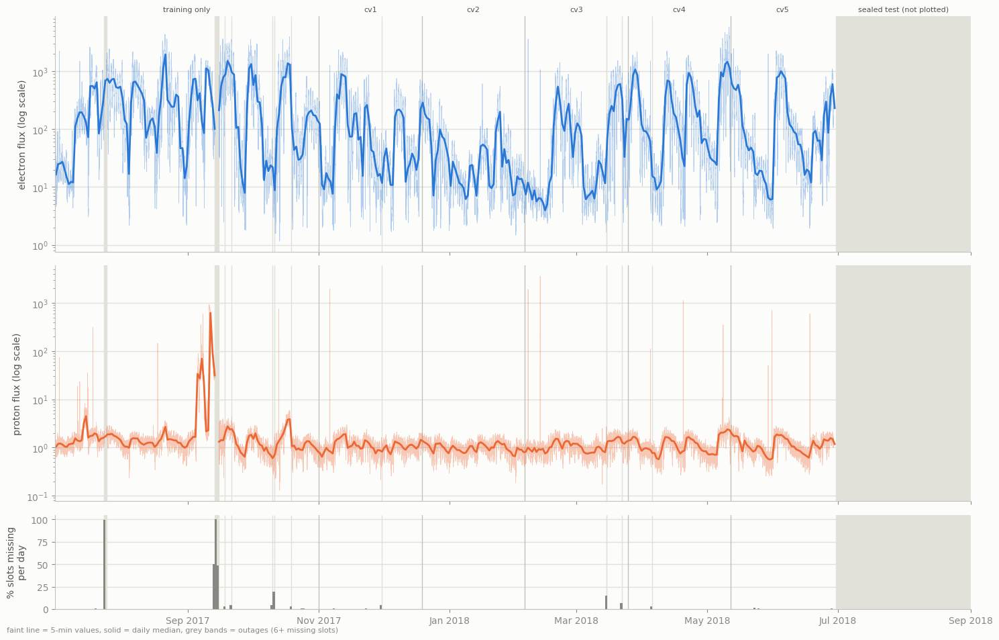

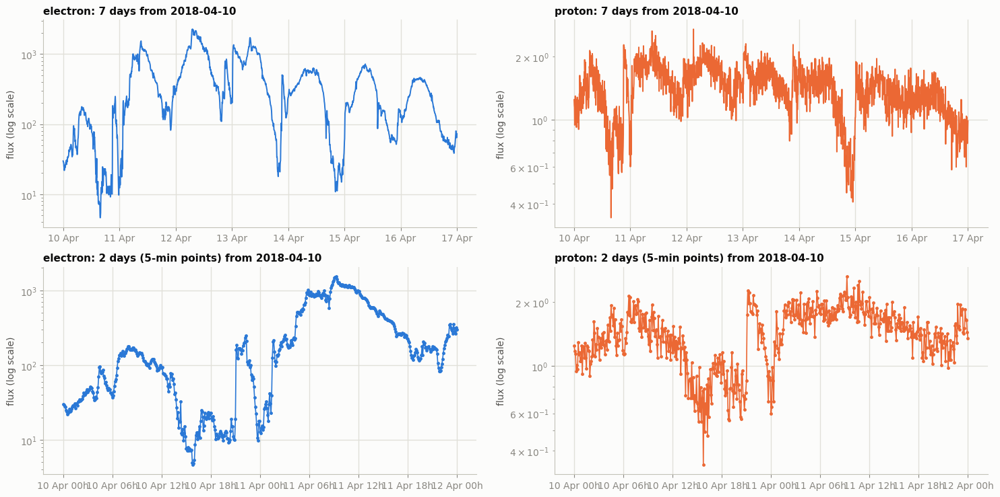

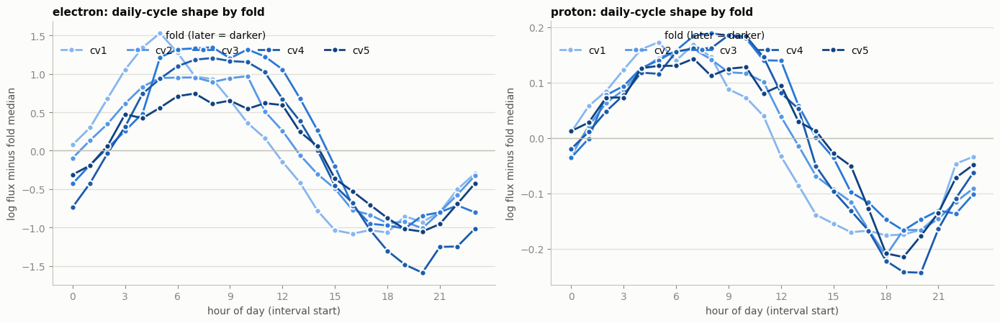

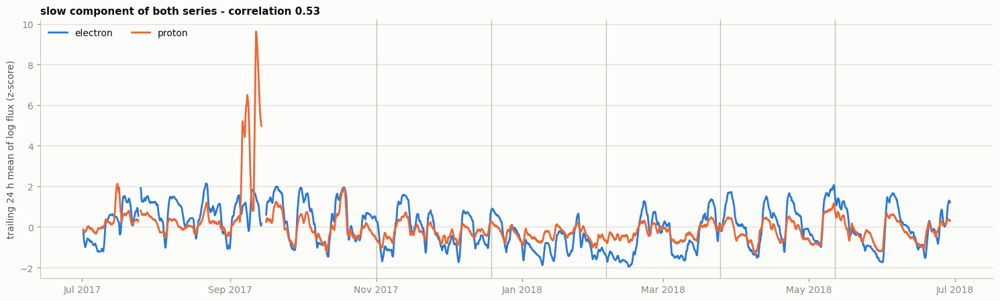

           electron    proton
count     103475.00 103472.00
mean         284.51      4.36
std          495.01     41.05
min            1.15      0.13
5%             4.91      0.60
50%           74.83      1.14
95%         1285.77      2.42
max         5864.21   3575.23
missing_%      1.02      1.03


In [8]:
import sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid

FIG = RUN / "figs"; FIG.mkdir(exist_ok=True)
g = load_grid()
dev = g.loc[:P.dev_end]                     # the sealed test is shaded but never plotted
folds, tw = make_folds(), test_window(g.index)

COL = {"electron": "#2a78d6", "proton": "#eb6834"}
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]          # blue ramp for ordered folds (later = darker)
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False,
})

def spans(mask):                              # (start, end) of every True run
    v = mask.to_numpy().astype(np.int8); d = np.diff(np.r_[0, v, 0])
    st, en = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    return [(mask.index[a], mask.index[b - 1]) for a, b in zip(st, en)]

# ------------------------------------------------ 1. overview
def fig_overview():
    fig, axes = plt.subplots(3, 1, figsize=(15, 9.5), sharex=True, gridspec_kw={"height_ratios": [3, 3, 1.2]})
    outages = spans(dev["outage_noncausal"])
    for ax, sp in zip(axes[:2], ("electron", "proton")):
        s = dev[sp]
        ax.plot(s.index, s.to_numpy(), color=COL[sp], lw=0.5, alpha=0.35)                    # raw 5-min
        day = s.resample("1D").median()
        ax.plot(day.index + pd.Timedelta(hours=12), day.to_numpy(), color=COL[sp], lw=2)    # daily median
        ax.set_yscale("log"); ax.set_ylabel(f"{sp} flux (log scale)")
    for ax in axes:
        for a, b in outages: ax.axvspan(a, b + pd.Timedelta(minutes=5), color=GRID, zorder=0)
        for w in folds: ax.axvline(w.val_start, color=AXIS, lw=1, zorder=1)
        ax.axvspan(tw.val_start, g.index[-1], color=GRID, zorder=0)
    trans = axes[0].get_xaxis_transform()
    axes[0].text(g.index[0] + (P.first_val_start - g.index[0]) / 2, 1.02, "training only", transform=trans,
                 ha="center", fontsize=8, color=INK2)
    for w in folds:
        axes[0].text(w.val_start + (w.val_end - w.val_start) / 2, 1.02, w.name, transform=trans, ha="center",
                     fontsize=8, color=INK2)
    axes[0].text(tw.val_start + (g.index[-1] - tw.val_start) / 2, 1.02, "sealed test (not plotted)", transform=trans,
                 ha="center", fontsize=8, color=INK2)
    miss = dev["missing"].groupby(dev.index.normalize()).mean() * 100
    axes[2].bar(miss.index, miss.to_numpy(), width=1.0, color=MUTED)
    axes[2].set_ylabel("% slots missing\nper day"); axes[2].set_xlim(g.index[0], g.index[-1])
    axes[2].xaxis.set_major_locator(mdates.MonthLocator(interval=2)); axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    fig.text(0.01, 0.005, "faint line = 5-min values, solid = daily median, grey bands = outages (6+ missing slots)", color=MUTED, fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / "series_1_overview.png", dpi=150, bbox_inches="tight"); plt.show()

# ------------------------------------------------ 2. zooms (adjust `start` if the window hits a gap)
def fig_zoom(start="2018-04-10", days=7, zoom_days=2):
    t0 = pd.Timestamp(start); t1, t2 = t0 + pd.Timedelta(days=days), t0 + pd.Timedelta(days=zoom_days)
    assert t1 <= P.dev_end, "zoom window must stay inside the dev period"
    fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))
    for c, sp in enumerate(("electron", "proton")):
        for r, (a, b, lab) in enumerate(((t0, t1, f"{days} days"), (t0, t2, f"{zoom_days} days (5-min points)"))):
            s = dev.loc[a:b, sp]; ax = axes[r, c]
            ax.plot(s.index, s.to_numpy(), color=COL[sp], lw=1.4 if r == 0 else 1.2,
                    marker="o" if r == 1 else None, ms=2.5)
            ax.set_yscale("log"); ax.xaxis.grid(True)
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b" if r == 0 else "%d %b %Hh"))
            ax.set_title(f"{sp}: {lab} from {start}"); ax.set_ylabel("flux (log scale)")
    fig.tight_layout(); fig.savefig(FIG / "series_2_zoom.png", dpi=150, bbox_inches="tight"); plt.show()

# ------------------------------------------------ 3. shape of the daily cycle, fold by fold
def fig_profiles():
    hb = np.asarray(((dev.index.hour * 60 + dev.index.minute - 5) // 60) % 24)      # interval-end stamps -> hour bins
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
    for ax, sp in zip(axes, ("electron", "proton")):
        lv = np.log(dev[sp])
        for w, colr in zip(folds, RAMP):
            m = np.asarray((dev.index >= w.val_start) & (dev.index < w.val_end))
            x = lv[m]
            prof = (x - x.median()).groupby(hb[m]).median()
            ax.plot(prof.index, prof.to_numpy(), color=colr, lw=2, marker="o", ms=6, mec=SURF, mew=1.5, label=w.name)
        ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(range(0, 24, 3))
        ax.set_xlabel("hour of day (interval start)"); ax.set_ylabel("log flux minus fold median")
        ax.set_title(f"{sp}: daily-cycle shape by fold"); ax.legend(title="fold (later = darker)", ncol=5, loc="upper left")
    fig.tight_layout(); fig.savefig(FIG / "series_3_daily_shape.png", dpi=150, bbox_inches="tight"); plt.show()

# ------------------------------------------------ 4. the slow component, both series on one standardised axis
def fig_slow():
    fig, ax = plt.subplots(figsize=(15, 4.6)); z = {}
    for sp in ("electron", "proton"):
        m24 = np.log(dev[sp]).rolling(288, min_periods=144).mean()                    # trailing 24 h mean
        z[sp] = (m24 - m24.mean()) / m24.std()
        ax.plot(z[sp].index, z[sp].to_numpy(), color=COL[sp], lw=2, label=sp)
    for w in folds: ax.axvline(w.val_start, color=AXIS, lw=1, zorder=1)
    r = z["electron"].corr(z["proton"])
    ax.set_ylabel("trailing 24 h mean of log flux (z-score)")
    ax.set_title(f"slow component of both series - correlation {r:.2f}"); ax.legend(loc="upper left", ncol=2)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    fig.tight_layout(); fig.savefig(FIG / "series_4_slow_component.png", dpi=150, bbox_inches="tight"); plt.show()

fig_overview(); fig_zoom(); fig_profiles(); fig_slow()

# ------------------------------------------------ table view of the same series (dev period)
tab = pd.DataFrame({sp: dev[sp].describe(percentiles=[.05, .5, .95]) for sp in ("electron", "proton")})
tab.loc["missing_%"] = [dev["missing_e"].mean() * 100, dev["missing_p"].mean() * 100]
pd.set_option("display.float_format", "{:.2f}".format); print(tab)

## 3.3 Memory and scaling: Hurst exponent and DFA

📘 **What.** Estimates how the size of fluctuations grows with the time scale, for 1 h–6 h, 6 h–2 d and 2 d–10 d, and compares each estimate with
a **surrogate**: an AR(1) process whose lag-1 autocorrelation is matched to the data.

📐 **Maths.**

*Structure function and Hurst exponent.* For $q=1,2$
$$S_q(\tau)=\mathbb E\,\big|y_{t+\tau}-y_t\big|^{q}\ \propto\ \tau^{\,qH(q)} .$$
$H=\tfrac12$ is a random walk, $H>\tfrac12$ persistent trends, $H<\tfrac12$ mean reversion.

*Detrended fluctuation analysis (DFA).* Integrate the demeaned series into a profile, cut it into windows of length $n$, remove a polynomial trend in each,
and take the RMS fluctuation $F(n)\propto n^{\alpha}$. For a stationary noise $\alpha=0.5$; for a random walk $\alpha=1.5$; values in between mean long-range correlation.

The AR(1) null uses $\phi=0.99906$ (electron) and $0.99872$ (proton), i.e. the values that reproduce the observed lag-1 autocorrelation.

{'electron': np.float64(0.99906), 'proton': np.float64(0.99872)} <- AR(1) phi of the null
                 H_q1  H_q2  H_q2_AR1  DFA_alpha  DFA_alpha_AR1
series   scales                                                
electron 1h-6h   0.48  0.35      0.49       1.36           1.50
         6h-2d   0.25  0.26      0.44       1.30           1.46
         2d-10d  0.31  0.25      0.28       1.37           1.34
proton   1h-6h   0.15  0.18      0.49       1.14           1.50
         6h-2d   0.23  0.31      0.42       1.33           1.45
         2d-10d  0.23  0.23      0.22       1.30           1.28

H (q=2) per window
        electron       proton      
           1h-6h 6h-2d  1h-6h 6h-2d
pre-cv1     0.33  0.27   0.30  0.41
cv1         0.33  0.30   0.10  0.14
cv2         0.41  0.28   0.09  0.12
cv3         0.43  0.14   0.10  0.05
cv4         0.31  0.28   0.08  0.17
cv5         0.41  0.32   0.09  0.18


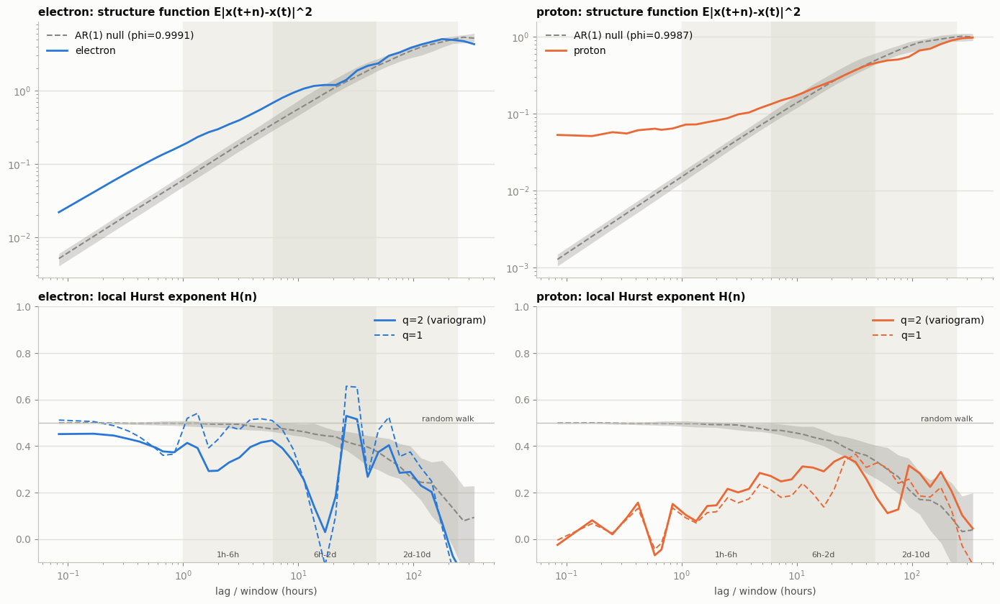

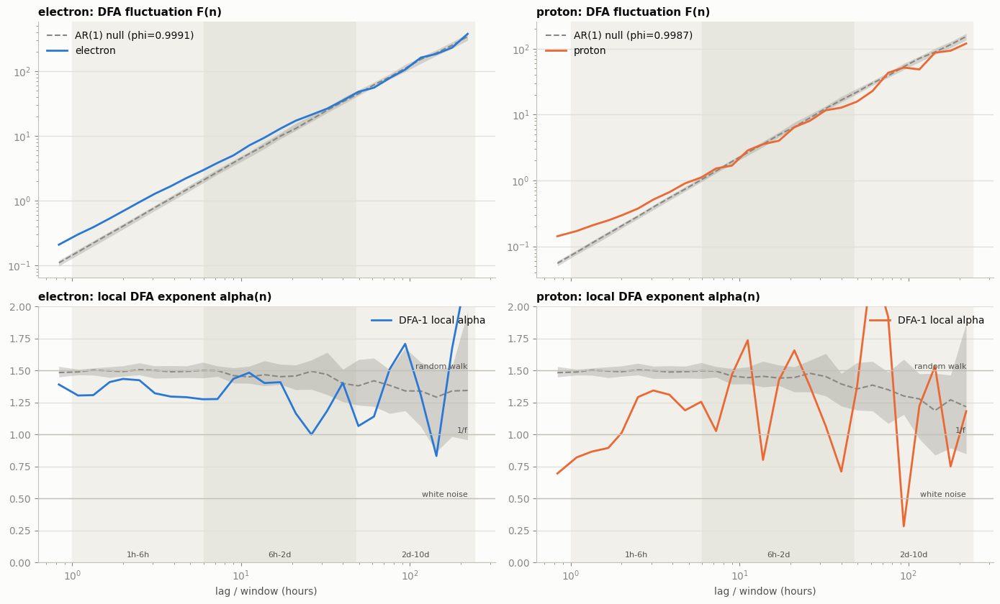

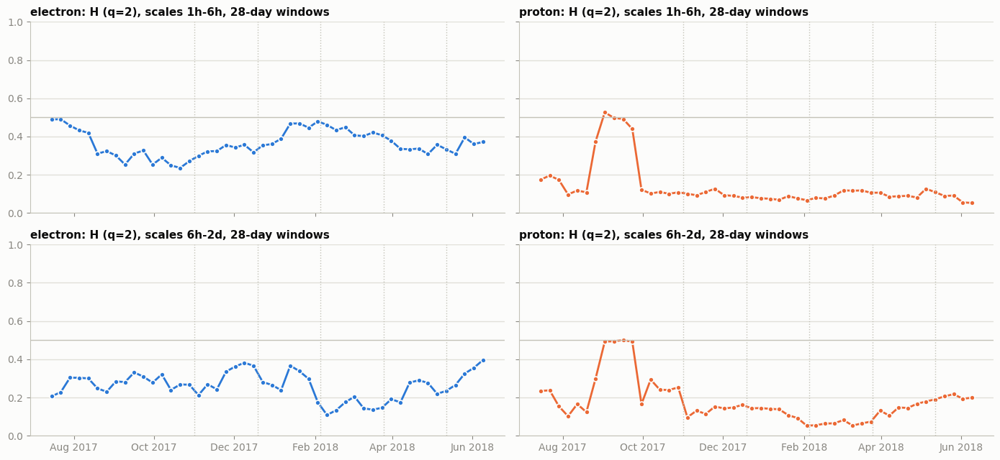

In [9]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import lfilter
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds
from runio import RUN, load_grid
warnings.filterwarnings("ignore", category=RuntimeWarning)

FIG = RUN / "figs"; FIG.mkdir(exist_ok=True)
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()

COL = {"electron": "#2a78d6", "proton": "#eb6834"}
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False,
})

# ------------------------------------------------ settings
LAGS = np.unique(np.round(np.geomspace(1, 4032, 40)).astype(int))       # 5 min .. 14 days
DS = LAGS[(LAGS >= 10) & (LAGS <= 2880)]                                 # DFA window sizes
RANGES = {"1h-6h": (12, 72), "6h-2d": (72, 576), "2d-10d": (576, 2880)}  # fit ranges, in 5-min steps
RNG2 = ("1h-6h", "6h-2d")                                                # ranges used per window / rolling
HRS, HD = LAGS * 5 / 60, DS * 5 / 60

# ------------------------------------------------ data: deseasonalised log level, NaN where unusable (diagnostics only)
BAD = [c for c in ("outage_noncausal", "near_outage_noncausal", "spike_noncausal") if c in dev]
bad = dev[BAD].fillna(0).astype(bool).any(axis=1) if BAD else pd.Series(False, index=dev.index)

def series(sp):
    x = np.log(dev[sp].where(~bad))
    hb = np.asarray(((dev.index.hour * 60 + dev.index.minute - 5) // 60) % 24)
    return x - x.groupby(hb).transform("mean")

# ------------------------------------------------ estimators
def struct(a, qs=(1, 2), lags=LAGS):                  # E|x(t+n)-x(t)|^q over observed pairs
    a = np.asarray(a, float); out = {q: np.full(len(lags), np.nan) for q in qs}
    for i, n in enumerate(lags):
        d = np.abs(a[n:] - a[:-n]); d = d[np.isfinite(d)]
        if d.size >= 100:
            for q in qs: out[q][i] = np.mean(d ** q)
    return out

def dfa(a, scales):                                   # DFA-1, windows never cross a NaN
    a = np.asarray(a, float); ok = np.isfinite(a)
    e = np.flatnonzero(np.diff(np.r_[0, ok.astype(np.int8), 0]))
    runs = [(s, t) for s, t in zip(e[::2], e[1::2]) if t - s >= scales.min()]
    profs = [np.cumsum(a[s:t] - a[s:t].mean()) for s, t in runs]
    F = []
    for n in scales:
        tt = np.arange(n) - (n - 1) / 2; ss = 0.0; k = 0
        for p in profs:
            L = len(p) // n
            if L < 1: continue
            W = p[:L * n].reshape(L, n)
            b = (W * tt).sum(1) / (tt * tt).sum()
            ss += ((W - W.mean(1, keepdims=True) - b[:, None] * tt) ** 2).mean(1).sum(); k += L
        F.append(np.sqrt(ss / k) if k >= 4 else np.nan)
    return np.array(F)

def slope(v_x, v_y, lo, hi, q=1):
    m = (v_x >= lo) & (v_x <= hi) & np.isfinite(v_y) & (v_y > 0)
    return np.polyfit(np.log(v_x[m]), np.log(v_y[m]), 1)[0] / q if m.sum() >= 3 else np.nan

def surrogates(x, n=20, lag=288, burn=5000, seed=0):  # AR(1) with the same 1-day ACF, variance and NaN pattern
    a = x.to_numpy(); ok = np.isfinite(a); m = ok[lag:] & ok[:-lag]
    r = max(np.corrcoef(a[lag:][m], a[:-lag][m])[0, 1], 0.01); phi = r ** (1 / lag)
    rng = np.random.default_rng(seed); sd = a[ok].std(); out = []
    for _ in range(n):
        s = lfilter([1.0], [1.0, -phi], rng.standard_normal(len(a) + burn))[burn:]
        out.append(np.where(ok, s * sd / s[ok].std(), np.nan))
    return out, phi

def analyse(sp):
    x = series(sp); a = x.to_numpy(); sur, phi = surrogates(x)
    K = struct(a); Ks = [struct(s) for s in sur]
    return dict(x=x, phi=phi, K1=K[1], K2=K[2],
                K1s=np.array([k[1] for k in Ks]), K2s=np.array([k[2] for k in Ks]),
                F=dfa(a, DS), Fs=np.array([dfa(s, DS) for s in sur]))

R = {sp: analyse(sp) for sp in ("electron", "proton")}

# ------------------------------------------------ tables
rows = []
for sp, r in R.items():
    for name, (lo, hi) in RANGES.items():
        rows.append(dict(series=sp, scales=name,
            H_q1=slope(LAGS, r["K1"], lo, hi, 1), H_q2=slope(LAGS, r["K2"], lo, hi, 2),
            H_q2_AR1=np.nanmedian([slope(LAGS, k, lo, hi, 2) for k in r["K2s"]]),
            DFA_alpha=slope(DS, r["F"], lo, hi),
            DFA_alpha_AR1=np.nanmedian([slope(DS, f, lo, hi) for f in r["Fs"]])))
tab = pd.DataFrame(rows).set_index(["series", "scales"])
print({sp: round(r["phi"], 5) for sp, r in R.items()}, "<- AR(1) phi of the null")
print(tab.round(3)); tab.to_csv(RUN / "reports" / "diag_hurst.csv")

def window_H(x, a, b):                                # variogram H (q=2) in one time window
    xs = x[(x.index >= a) & (x.index < b)].to_numpy(); lg = LAGS[LAGS <= 576]
    K = struct(xs, (2,), lg)[2]
    return [slope(lg, K, *RANGES[k], q=2) for k in RNG2]

WIN = [("pre-cv1", g.index[0], P.first_val_start)] + [(w.name, w.val_start, w.val_end) for w in folds]
per = pd.DataFrame({(sp, k): [window_H(R[sp]["x"], a, b)[i] for _, a, b in WIN]
                    for sp in R for i, k in enumerate(RNG2)}, index=[n for n, _, _ in WIN])
print("\nH (q=2) per window"); print(per.round(3)); per.to_csv(RUN / "reports" / "diag_hurst_by_window.csv")

def rolling_H(x, win="28D", step="7D"):
    out = []
    for a in pd.date_range(x.index[0], x.index[-1] - pd.Timedelta(win), freq=step):
        b = a + pd.Timedelta(win); out.append((a + (b - a) / 2, *window_H(x, a, b)))
    return pd.DataFrame(out, columns=["mid", *RNG2]).set_index("mid")
ROLL = {sp: rolling_H(r["x"]) for sp, r in R.items()}

# ------------------------------------------------ plots
def band(ax, xv, M, label=None):
    lo, hi = np.nanpercentile(M, [5, 95], axis=0)
    ax.fill_between(xv, lo, hi, color=MUTED, alpha=0.3, lw=0)
    ax.plot(xv, np.nanmedian(M, 0), color=MUTED, lw=1.5, ls="--", label=label)

def shade(ax):
    for (lo, hi), c in zip(RANGES.values(), ("#f1f0ea", "#e8e7df", "#f1f0ea")):
        ax.axvspan(lo * 5 / 60, hi * 5 / 60, color=c, zorder=0)

def tag_ranges(ax):
    for name, (lo, hi) in RANGES.items():
        ax.text(np.sqrt(lo * hi) * 5 / 60, 0.02, name, transform=ax.get_xaxis_transform(),
                ha="center", fontsize=8, color=INK2)

def loc_slope(xv, v, q=1): return np.gradient(np.log(v), np.log(xv)) / q

def two_row(fname, xv, top_key, top_null, top_title, bot_fn, bot_title, refs, ylim):
    fig, axes = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
    for c, sp in enumerate(R):
        r, col = R[sp], COL[sp]; top, bot = axes[0, c], axes[1, c]
        for ax in (top, bot): shade(ax); ax.set_xscale("log")
        band(top, xv, r[top_null], label=f"AR(1) null (phi={r['phi']:.4f})")
        top.plot(xv, r[top_key], color=col, lw=2, label=sp); top.set_yscale("log")
        top.set_title(f"{sp}: {top_title}"); top.legend(loc="upper left")
        bot_fn(bot, r, col)
        for y, lab in refs: bot.axhline(y, color=AXIS, lw=1); bot.text(xv[-1], y, lab, ha="right", va="bottom", fontsize=8, color=INK2)
        bot.set_ylim(*ylim); bot.set_title(f"{sp}: {bot_title}"); bot.set_xlabel("lag / window (hours)"); tag_ranges(bot)
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=150, bbox_inches="tight"); plt.show()

def bot_struct(ax, r, col):
    band(ax, HRS, np.array([loc_slope(LAGS, k, 2) for k in r["K2s"]]))
    ax.plot(HRS, loc_slope(LAGS, r["K2"], 2), color=col, lw=2, label="q=2 (variogram)")
    ax.plot(HRS, loc_slope(LAGS, r["K1"], 1), color=col, lw=1.4, ls=(0, (4, 2)), label="q=1")
    ax.legend(loc="upper right")

def bot_dfa(ax, r, col):
    band(ax, HD, np.array([loc_slope(DS, f) for f in r["Fs"]]))
    ax.plot(HD, loc_slope(DS, r["F"]), color=col, lw=2, label="DFA-1 local alpha"); ax.legend(loc="upper right")

def fig_structure():
    two_row("hurst_1_structure.png", HRS, "K2", "K2s", "structure function E|x(t+n)-x(t)|^2",
            bot_struct, "local Hurst exponent H(n)", [(0.5, "random walk")], (-0.1, 1.0))
def fig_dfa():
    two_row("hurst_2_dfa.png", HD, "F", "Fs", "DFA fluctuation F(n)", bot_dfa, "local DFA exponent alpha(n)",
            [(0.5, "white noise"), (1.0, "1/f"), (1.5, "random walk")], (0.0, 2.0))
    # NB: top row of fig_dfa uses HD for x; r["F"] has len(DS)

def fig_rolling():
    fig, axes = plt.subplots(2, 2, figsize=(14, 6.5), sharex=True, sharey=True)
    for c, sp in enumerate(R):
        for rr, k in enumerate(RNG2):
            ax = axes[rr, c]; s = ROLL[sp][k]
            ax.plot(s.index, s.to_numpy(), color=COL[sp], lw=2, marker="o", ms=5, mec=SURF, mew=1.2)
            ax.axhline(0.5, color=AXIS, lw=1)
            for w in folds: ax.axvline(w.val_start, color=AXIS, lw=1, ls=":")
            ax.set_title(f"{sp}: H (q=2), scales {k}, 28-day windows"); ax.set_ylim(0, 1)
            ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    fig.tight_layout(); fig.savefig(FIG / "hurst_3_rolling.png", dpi=150, bbox_inches="tight"); plt.show()

fig_structure(); fig_dfa(); fig_rolling()

👀 **How to read this output**

| Electron | $H_{q=1}$ | $H_{q=2}$ | $H_{q=2}$ of AR(1) null | DFA $\alpha$ | DFA $\alpha$ of AR(1) null |
|---|---|---|---|---|---|
| 1 h–6 h | 0.48 | 0.35 | 0.49 | 1.36 | 1.50 |
| 6 h–2 d | 0.25 | 0.26 | **0.44** | 1.30 | 1.46 |
| 2 d–10 d | 0.31 | 0.25 | 0.28 | 1.37 | 1.34 |

* Electron's $H$ is **below ½** on the day scale and **well below the AR(1) null** (0.26 vs 0.44 at 6 h–2 d): the real series reverts toward a daily pattern faster than a plain persistent process would. That is the signature of the **24 h cycle**.
* Proton's $H_{q=2}$ at 1 h–6 h is only 0.18 against 0.49 for the null, a much stronger deviation, consistent with the alternating-sample artefact found later (cells 18–20).
* The per-window table shows that the electron estimates are fairly stable across cv1–cv5 (1 h–6 h: 0.31–0.43; 6 h–2 d: 0.14–0.32).

⚠️ These scaling diagnostics give context; they are **not used to build any model**. They should be re-run with the corrected quality-mask names before publication (open item).

## 3.4 Autocorrelation of the changes (ACF and PACF)

📘 **What.** Autocorrelation and partial autocorrelation of $\Delta$ at 5 min, 45 min, 6 h and 12 h, for electron and proton.

📐 **Maths.**
$$\rho_k=\frac{\operatorname{Cov}(\Delta_t,\Delta_{t-k})}{\operatorname{Var}(\Delta_t)},\qquad \text{95 \% band}\approx\pm\frac{1.96}{\sqrt N}.$$
The **PACF** at lag $k$ is the correlation between $\Delta_t$ and $\Delta_{t-k}$ after removing the effect of lags $1,\dots,k-1$ (the last coefficient of an AR($k$) fit).

                      N  band  acf_l1  acf_l2  acf_l3  acf_1day  pacf_l1  pacf_l2  pacf_l3
series   change                                                                           
electron 5 min   103445  0.01   -0.05   -0.00   -0.01      0.02    -0.05    -0.00    -0.01
         45 min   11487  0.02   -0.04    0.01    0.08      0.12    -0.04     0.01     0.08
         6 h       1433  0.05   -0.06   -0.71    0.00      0.69    -0.06    -0.71    -0.24
         12 h       717  0.07   -0.58    0.49   -0.48      0.49    -0.58     0.23    -0.21
proton   5 min   103441  0.01   -0.52    0.08   -0.08      0.04    -0.52    -0.26    -0.24
         45 min   11487  0.02   -0.44    0.03   -0.05      0.03    -0.44    -0.20    -0.16
         6 h       1433  0.05   -0.21   -0.20    0.01      0.16    -0.21    -0.26    -0.11
         12 h       717  0.07   -0.33    0.17   -0.19      0.17    -0.33     0.07    -0.12


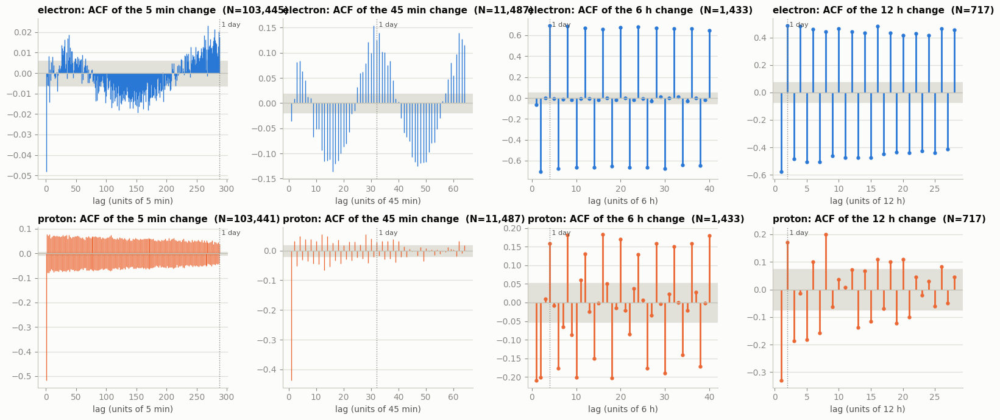

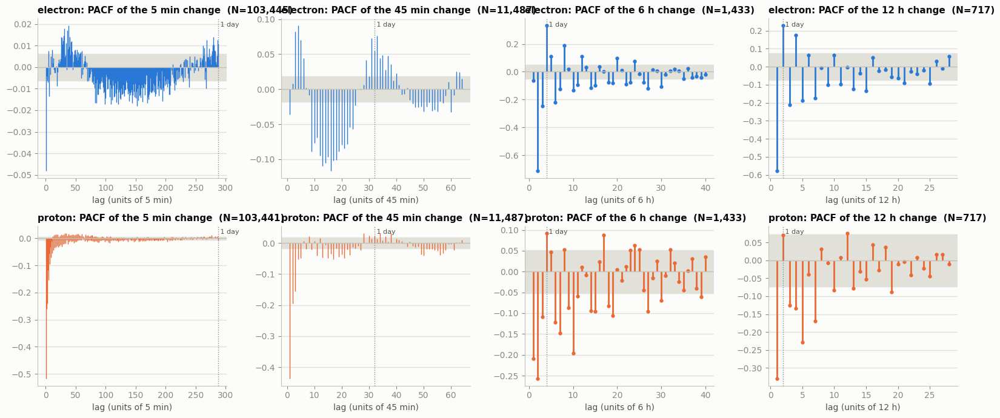

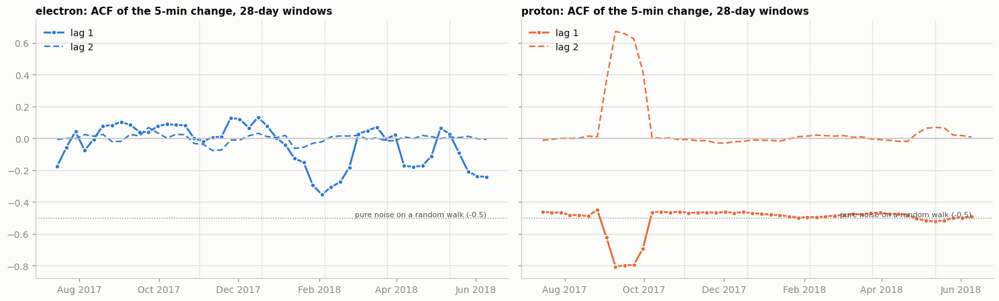

In [10]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds
from runio import RUN, load_grid
warnings.filterwarnings("ignore", category=RuntimeWarning)

FIG = RUN / "figs"; FIG.mkdir(exist_ok=True)
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()

COL = {"electron": "#2a78d6", "proton": "#eb6834"}
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False,
})

# ------------------------------------------------ data: raw log level, NaN where unusable (diagnostics only)
BAD = [c for c in ("outage_noncausal", "near_outage_noncausal", "spike_noncausal") if c in dev]
bad = dev[BAD].fillna(0).astype(bool).any(axis=1) if BAD else pd.Series(False, index=dev.index)
LOG = {sp: np.log(dev[sp].where(~bad)) for sp in ("electron", "proton")}

# change horizon in 5-min steps, number of lags (in units of that horizon)
SC = {"5 min": (1, 288), "45 min": (9, 64), "6 h": (72, 40), "12 h": (144, 28)}

def change(x, k):                                   # non-overlapping k-step change
    a = x.to_numpy(); return (a[k:] - a[:-k])[::k]

def acf_pw(a, nl):                                  # pairwise-complete ACF (handles NaN gaps)
    c = a - np.nanmean(a); v = np.nanmean(c ** 2)
    return np.array([np.nanmean(c[k:] * c[:-k]) for k in range(1, nl + 1)]) / v

def pacf_dl(r):                                     # Durbin-Levinson on the ACF
    nl = len(r); phi = np.zeros((nl + 1, nl + 1)); out = np.full(nl, np.nan)
    for k in range(1, nl + 1):
        if k == 1: pk = r[0]
        else:
            pj = phi[k - 1, 1:k]
            pk = (r[k - 1] - (pj * r[k - 2::-1][:k - 1]).sum()) / (1 - (pj * r[:k - 1]).sum())
            phi[k, 1:k] = pj - pk * phi[k - 1, k - 1:0:-1]
        phi[k, k] = pk; out[k - 1] = pk
    return np.clip(out, -1, 1)

RES = {}
for sp in LOG:
    for name, (k, nl) in SC.items():
        d = change(LOG[sp], k); r = acf_pw(d, nl); N = int(np.isfinite(d).sum())
        RES[(sp, name)] = dict(r=r, p=pacf_dl(r), N=N, band=1.96 / np.sqrt(N), k=k)

# ------------------------------------------------ table
rows = []
for (sp, name), v in RES.items():
    day = 288 // v["k"]; r, p = v["r"], v["p"]
    rows.append(dict(series=sp, change=name, N=v["N"], band=v["band"],
                     acf_l1=r[0], acf_l2=r[1], acf_l3=r[2], acf_1day=r[day - 1],
                     pacf_l1=p[0], pacf_l2=p[1], pacf_l3=p[2]))
tab = pd.DataFrame(rows).set_index(["series", "change"])
print(tab.round(3)); tab.to_csv(RUN / "reports" / "diag_change_acf.csv")

# ------------------------------------------------ figures: ACF and PACF grids
def fig_grid(key, fname, what):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for i, sp in enumerate(LOG):
        for j, name in enumerate(SC):
            v = RES[(sp, name)]; y = v[key]; lg = np.arange(1, len(y) + 1); ax = axes[i, j]
            ax.axhspan(-v["band"], v["band"], color=GRID, zorder=0)
            ax.vlines(lg, 0, y, color=COL[sp], lw=1.0 if len(y) > 60 else 2)
            if len(y) <= 60: ax.plot(lg, y, "o", ms=3.5, color=COL[sp])
            ax.axhline(0, color=AXIS, lw=1)
            day = 288 // v["k"]
            if 1 < day <= len(y): ax.axvline(day, color=MUTED, lw=1, ls=":"); ax.text(day, 0.98, " 1 day", transform=ax.get_xaxis_transform(), fontsize=8, color=INK2, va="top")
            ax.set_title(f"{sp}: {what} of the {name} change  (N={v['N']:,})"); ax.set_xlabel(f"lag (units of {name})")
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=150, bbox_inches="tight"); plt.show()

# ------------------------------------------------ figure: does the 5-min ACF change over time?
def roll_acf(sp, win="28D", step="7D"):
    x = LOG[sp]; out = []
    for a in pd.date_range(x.index[0], x.index[-1] - pd.Timedelta(win), freq=step):
        w = x[(x.index >= a) & (x.index < a + pd.Timedelta(win))].to_numpy(); r = acf_pw(w[1:] - w[:-1], 2)
        out.append((a + pd.Timedelta(win) / 2, r[0], r[1]))
    return pd.DataFrame(out, columns=["mid", "lag1", "lag2"]).set_index("mid")
ROLL = {sp: roll_acf(sp) for sp in LOG}

def fig_rolling():
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
    for ax, sp in zip(axes, LOG):
        s = ROLL[sp]
        ax.plot(s.index, s["lag1"], color=COL[sp], lw=2, marker="o", ms=5, mec=SURF, mew=1.2, label="lag 1")
        ax.plot(s.index, s["lag2"], color=COL[sp], lw=1.6, ls=(0, (4, 2)), label="lag 2")
        ax.axhline(0, color=AXIS, lw=1); ax.axhline(-0.5, color=MUTED, lw=1, ls=":")
        ax.text(s.index[-1], -0.5, "pure noise on a random walk (-0.5)", ha="right", va="bottom", fontsize=8, color=INK2)
        for w in folds: ax.axvline(w.val_start, color=AXIS, lw=1, ls=":")
        ax.set_title(f"{sp}: ACF of the 5-min change, 28-day windows"); ax.legend(loc="upper left")
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    fig.tight_layout(); fig.savefig(FIG / "chg_3_rolling_lag12.png", dpi=150, bbox_inches="tight"); plt.show()

fig_grid("r", "chg_1_acf.png", "ACF"); fig_grid("p", "chg_2_pacf.png", "PACF"); fig_rolling()

👀 **How to read this output**

| Series | lag 1 | lag 2 | lag 3 | 1 day |
|---|---|---|---|---|
| Electron, 5-min change | **−0.05** | 0.00 | −0.01 | 0.02 |
| Electron, 45-min change | −0.04 | 0.01 | 0.08 | **0.12** |
| Electron, 6-h change | −0.06 | **−0.71** | 0.00 | **+0.69** |
| Electron, 12-h change | **−0.58** | +0.49 | −0.48 | +0.49 |
| Proton, 5-min change | **−0.52** | 0.08 | −0.08 | 0.04 |

* **Electron, 5-min:** the band is ±0.01, so −0.05 is statistically non-zero but economically tiny. There is essentially no short-term memory in the *direction* of 5-minute changes, just as in liquid financial returns.
* At **long horizons** the picture is dominated by the daily cycle: the 6-h change has lag-2 −0.71 and 1-day +0.69. That is a clean sinusoid in the changes.
* The signed 1-day autocorrelation **grows with horizon**: 0.02 at 5 min, 0.12 at 45 min here, and (cell 34) 0.09 / 0.13 / 0.21 at 30 min / 45 min / 1 h. This is why the day-before information matters more for 1 h than for 30 min.
* **Proton, 5-min lag-1 = −0.52** is far too strong to be physical; this is the alternating-sample artefact investigated in cells 11 and 18–20.

## 3.5 Do protons help predict electrons? (Granger tests on changes)

📘 **What.** Tests whether the other species' past changes add predictive information, **in sample** (HAC-robust Wald $F$) and **out of sample** (drop in validation MSE).

📐 **Maths.** For electron change $\Delta e_t$ and proton change $\Delta p_t$:
$$\text{restricted:}\ \ \Delta e_t=a+\sum_{i=1}^{p}\phi_i\,\Delta e_{t-i}+\epsilon_t,\qquad
\text{full:}\ \ \Delta e_t=a+\sum_{i=1}^{p}\phi_i\,\Delta e_{t-i}+\sum_{i=1}^{p}\psi_i\,\Delta p_{t-i}+\epsilon_t .$$
$H_0:\psi_1=\dots=\psi_p=0$ ("protons do not Granger-cause electrons"). A **HAC** (Newey–West) covariance is used because the residuals are heteroskedastic and autocorrelated; with 8 tests the Bonferroni threshold is $p<0.05/8\approx0.006$.
Out of sample the gain is
$$\text{gain}=100\Big(1-\frac{\text{MSE}_{\text{full}}}{\text{MSE}_{\text{restricted}}}\Big)\ \%,$$
tested with a Diebold–Mariano statistic.

IN-SAMPLE (target <- other series' lags), 8 tests so Bonferroni threshold is p < 0.006
                  p       n      F       pval  var_removed_pct  corr_lag0
target   change                                                          
electron 5 min    8  103123  2.464     0.0115           0.6961     0.2761
proton   5 min   11  103122  62.34 1.904e-139            4.065     0.2761
electron 45 min   4   11383  3.572   0.006456           0.8629      0.423
proton   45 min   5   11383  17.11  6.698e-17            2.101      0.423
electron 6 h      4    1403 0.9467      0.436           0.2575     0.5587
proton   6 h      2    1403  11.65  9.625e-06            2.172     0.5587
electron 12 h     5     699  1.734     0.1246            1.091     0.4719
proton   12 h     5     699  6.404  7.941e-06            6.899     0.4719

OUT-OF-SAMPLE MSE reduction % (full vs own-lags only)
                     cv1     cv2     cv3    cv4      cv5  gain_pooled   dm_t  p_med
target   change                   

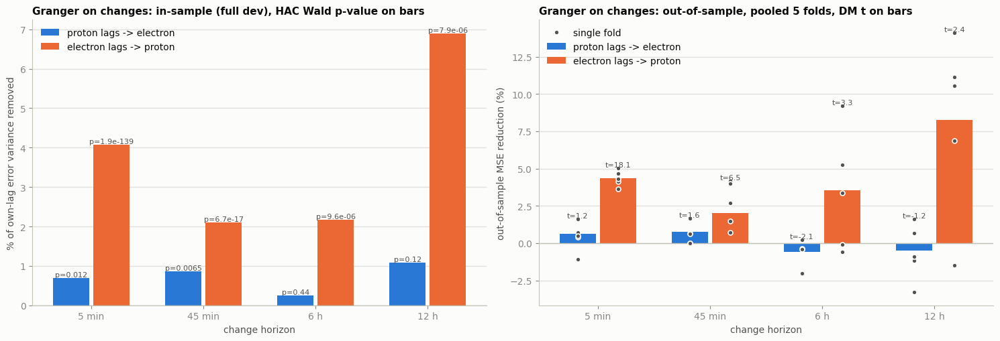

In [11]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

FIG = RUN / "figs"; FIG.mkdir(exist_ok=True)
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()

COL = {"electron": "#2a78d6", "proton": "#eb6834"}
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False,
})

# ------------------------------------------------ data: raw log level, NaN where unusable (diagnostics only)
BAD = [c for c in ("outage_noncausal", "near_outage_noncausal", "spike_noncausal") if c in dev]
bad = dev[BAD].fillna(0).astype(bool).any(axis=1) if BAD else pd.Series(False, index=dev.index)
LOG = {sp: np.log(dev[sp].where(~bad)) for sp in ("electron", "proton")}
SC = {"5 min": (1, 12), "45 min": (9, 8), "6 h": (72, 6), "12 h": (144, 6)}   # change horizon (steps), max lag order
EMB = pd.Timedelta(minutes=5 * P.embargo_steps)

def change_frame(k):                                        # non-overlapping k-step changes, stamped at the end of each change
    ch = {sp: (lambda a: (a[k:] - a[:-k])[::k])(LOG[sp].to_numpy()) for sp in LOG}
    return pd.DataFrame(ch, index=dev.index[k::k])

def controls(idx, k):                                       # common diurnal terms for the target's time stamp
    m = np.asarray((idx.hour * 60 + idx.minute - 5) % 1440)
    if k < 72:
        t = 2 * np.pi * m / 1440
        return pd.DataFrame({f"{f}{h}": fn(h * t) for h in (1, 2) for f, fn in (("s", np.sin), ("c", np.cos))}, index=idx)
    return pd.get_dummies(pd.Series(m // (k * 5), index=idx), prefix="slot", drop_first=True, dtype=float)

def design(df, tgt, oth, pmax, k):
    X = pd.DataFrame({**{f"own{L}": df[tgt].shift(L) for L in range(1, pmax + 1)},
                      **{f"oth{L}": df[oth].shift(L) for L in range(1, pmax + 1)}})
    X = pd.concat([X, controls(df.index, k)], axis=1); X.insert(0, "const", 1.0)
    return pd.concat([df[tgt].rename("y"), X], axis=1).dropna()

own = lambda p: [f"own{L}" for L in range(1, p + 1)]
oth_ = lambda p: [f"oth{L}" for L in range(1, p + 1)]

def choose_p(d, rows, base, pmax):                          # BIC of the unrestricted equation, on the given rows only
    y = d.loc[rows, "y"]; best = (np.inf, 1)
    for p in range(1, pmax + 1):
        b = sm.OLS(y, d.loc[rows, base + own(p) + oth_(p)]).fit().bic
        if b < best[0]: best = (b, p)
    return best[1]

def granger_test(d, base, p):                               # HAC Wald F-test that the other series' p lags are all zero
    y = d["y"]; cols = base + own(p) + oth_(p)
    full = sm.OLS(y, d[cols]).fit(cov_type="HAC", cov_kwds={"maxlags": max(p, 6)})
    restr = sm.OLS(y, d[base + own(p)]).fit()
    R = np.zeros((p, len(cols)))
    for i, c in enumerate(oth_(p)): R[i, cols.index(c)] = 1
    w = full.wald_test(R, use_f=True, scalar=True)
    return dict(p=p, n=len(y), F=float(w.statistic), pval=float(w.pvalue), var_removed_pct=100 * (1 - full.ssr / restr.ssr))

def oos(d, base, pmax):                                     # per fold: fit on train rows (target time <= val_start - embargo)
    res, sr, sf, dl, ps = {}, 0.0, 0.0, [], []
    for w in folds:
        tr = np.asarray(d.index <= w.val_start - EMB); va = np.asarray((d.index >= w.val_start) & (d.index < w.val_end))
        if tr.sum() < 100 or va.sum() < 20: continue
        p = choose_p(d, tr, base, pmax); ps.append(p)
        cr, cf = base + own(p), base + own(p) + oth_(p)
        er = d.loc[va, "y"] - sm.OLS(d.loc[tr, "y"], d.loc[tr, cr]).fit().predict(d.loc[va, cr])
        ef = d.loc[va, "y"] - sm.OLS(d.loc[tr, "y"], d.loc[tr, cf]).fit().predict(d.loc[va, cf])
        res[w.name] = 100 * (1 - (ef ** 2).mean() / (er ** 2).mean())
        sr += (er ** 2).sum(); sf += (ef ** 2).sum(); dl.append((er ** 2 - ef ** 2).to_numpy())
    dl = np.concatenate(dl)
    res["gain_pooled"] = 100 * (1 - sf / sr)
    res["dm_t"] = sm.OLS(dl, np.ones_like(dl)).fit(cov_type="HAC", cov_kwds={"maxlags": 6}).tvalues[0]
    res["p_med"] = float(np.median(ps)); return res

# ------------------------------------------------ run both directions at every scale
IS, OOS = {}, {}
for name, (k, pmax) in SC.items():
    df = change_frame(k); r0 = df["electron"].corr(df["proton"])
    for tgt, oth in (("electron", "proton"), ("proton", "electron")):
        d = design(df, tgt, oth, pmax, k)
        base = [c for c in d.columns if c != "y" and not c.startswith(("own", "oth"))]
        p = choose_p(d, np.ones(len(d), bool), base, pmax)
        IS[(tgt, name)] = granger_test(d, base, p) | {"corr_lag0": r0}
        OOS[(tgt, name)] = oos(d, base, pmax)
IS_df = pd.DataFrame.from_dict(IS, orient="index"); OOS_df = pd.DataFrame.from_dict(OOS, orient="index")
IS_df.index.names = OOS_df.index.names = ["target", "change"]
pd.set_option("display.float_format", "{:.4g}".format)
print("IN-SAMPLE (target <- other series' lags), 8 tests so Bonferroni threshold is p < 0.006"); print(IS_df)
print("\nOUT-OF-SAMPLE MSE reduction % (full vs own-lags only)"); print(OOS_df)
IS_df.to_csv(RUN / "reports" / "diag_granger_changes_insample.csv"); OOS_df.to_csv(RUN / "reports" / "diag_granger_changes_oos.csv")

# ------------------------------------------------ figure
def fig_granger():
    scales = list(SC); x = np.arange(len(scales)); w = 0.36
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.2)); fold_cols = [c for c in OOS_df.columns if c.startswith("cv")]
    for j, tgt in enumerate(("electron", "proton")):
        oth = "proton" if tgt == "electron" else "electron"; xs = x + (j - 0.5) * w; lab = f"{oth} lags -> {tgt}"
        v = np.array([IS_df.loc[(tgt, s), "var_removed_pct"] for s in scales])
        axes[0].bar(xs, v, w * 0.9, color=COL[tgt], label=lab)
        for xi, s, vi in zip(xs, scales, v):
            axes[0].text(xi, vi, f"p={IS_df.loc[(tgt, s), 'pval']:.2g}", ha="center", va="bottom", fontsize=8, color=INK2)
        pg = np.array([OOS_df.loc[(tgt, s), "gain_pooled"] for s in scales])
        axes[1].bar(xs, pg, w * 0.9, color=COL[tgt], label=lab)
        for xi, s, pgi in zip(xs, scales, pg):
            fv = OOS_df.loc[(tgt, s), fold_cols].astype(float).dropna().to_numpy()
            axes[1].plot(np.full(len(fv), xi), fv, "o", ms=5, color=INK2, mec=SURF, mew=1.2, zorder=3,
                         label="single fold" if (j == 0 and s == scales[0]) else None)
            axes[1].text(xi, max(fv.max(), pgi, 0), f"t={OOS_df.loc[(tgt, s), 'dm_t']:.1f}", ha="center", va="bottom", fontsize=8, color=INK2)
    for ax, yl, tt in ((axes[0], "% of own-lag error variance removed", "in-sample (full dev), HAC Wald p-value on bars"),
                       (axes[1], "out-of-sample MSE reduction (%)", "out-of-sample, pooled 5 folds, DM t on bars")):
        ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(x); ax.set_xticklabels(scales)
        ax.set_xlabel("change horizon"); ax.set_ylabel(yl); ax.set_title(f"Granger on changes: {tt}"); ax.legend(loc="upper left")
    fig.tight_layout(); fig.savefig(FIG / "chg_4_granger.png", dpi=150, bbox_inches="tight"); plt.show()
fig_granger()

👀 **How to read this output**

*In sample (Bonferroni threshold p < 0.006).*

| Target | Scale | F | p | Variance removed |
|---|---|---|---|---|
| **electron** | 5 min | 2.46 | 0.0115 | 0.70 % |
| **proton** | 5 min | **62.3** | **1.9e-139** | 4.07 % |
| electron | 45 min | 3.57 | 0.0065 | 0.86 % |
| proton | 45 min | 17.1 | 6.7e-17 | 2.10 % |
| electron | 6 h | 0.95 | 0.44 | 0.26 % |
| electron | 12 h | 1.73 | 0.12 | 1.09 % |

*Out of sample (validation MSE reduction, pooled):* electron targets gain **+0.63 % (5 min, DM $t$=1.18)**, +0.76 % (45 min, $t$=1.58) and are **worse** at 6 h (−0.57 %, $t$=−2.07) and 12 h (−0.50 %).
Proton targets gain +4.35 % (5 min, $t$=18.1), +2.02 % (45 min), +3.55 % (6 h), +8.24 % (12 h).

✅ **Take-away.** Information flows **electron → proton**, not the other way. Protons carry no usable information for forecasting electron flux, so they were dropped as a predictor (pivot 6). The first notebook's "bidirectional Granger causality" was an in-sample, many-rows artefact.

## 3.6 Small checks: does the quality mask matter? Where does the proton alternation sit?

📘 **What.** Two quick checks.
1. The lag-1 autocorrelation of the electron 5-min change under progressively stricter quality masks.
2. The ten-odd **days** on which proton's lag-2 autocorrelation of 5-minute changes is largest (a sign of period-2 alternation).

🎯 **Why.** To make sure the electron results are not driven by the mask and to locate the proton oddity in time.

In [12]:
def lag1(a):
    d = np.diff(a); c = d - np.nanmean(d)
    return np.nanmean(c[1:] * c[:-1]) / np.nanmean(c ** 2)

# 1) electron lag-1 ACF of the 5-min change under progressively stricter masks
for i in range(len(BAD) + 1):
    m = dev[BAD[:i]].fillna(0).astype(bool).any(axis=1) if i else pd.Series(False, index=dev.index)
    print(BAD[:i] or "no mask", round(lag1(np.log(dev["electron"].where(~m)).to_numpy()), 4))

# 2) days with the strongest period-2 alternation in proton
d = LOG["proton"].diff()
lag2 = d.groupby(d.index.normalize()).apply(lambda s: s.corr(s.shift(2)))
print(lag2.sort_values(ascending=False).head(15).round(2))

no mask -0.0482
['outage_noncausal'] -0.0482
t
2017-09-15   0.92
2017-09-16   0.92
2017-09-17   0.88
2017-09-18   0.71
2018-05-08   0.34
2018-06-02   0.18
2017-08-24   0.17
2017-09-09   0.16
2018-02-24   0.16
2017-09-10   0.16
2018-05-11   0.14
2018-06-13   0.14
2017-07-17   0.13
2018-04-10   0.13
2018-02-28   0.13
Name: proton, dtype: float64


👀 **How to read this output**

* Electron lag-1 ACF is **−0.0482** with *no mask* and **−0.0482** with the outage mask: the mask changes nothing here.
* Proton's strongest period-2 days are **2017-09-15 (0.92), 09-16 (0.92), 09-17 (0.88), 09-18 (0.71)**; everything else is ≤ 0.34. The artefact is therefore **one episode in mid-September 2017**, not a property of the whole series.

---
# Part 4 · Baselines and the metric

> 🎯 **A forecast is only as good as the thing it beats.** This part defines the benchmarks and shows why the headline metric had to change from $R^2$ of the level to $R^2$ of the change.

## 4.1 Baselines (first run, horizons 45 min / 6 h / 12 h)

| Model | Formula (origin $t$, horizon $H$, one day $=288$ steps) | Idea |
|---|---|---|
| `persistence` | $\hat y_{t+H}=y_t$ | nothing changes |
| `seasonal_naive` | $\hat y_{t+H}=y_{t+H-288}$ | tomorrow looks like today at the same clock time |
| `persist_plus_seasonal_delta` | $\hat y_{t+H}=y_t+\big(y_{t+H-288}-y_{t-288}\big)$ | repeat **yesterday's change** over the same phase |

Each is scored on the **same sample** of validation rows (`common_set`), with the metrics from the notation section.

In [10]:
import sys, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core; importlib.reload(core)
from core import *

CSV = "/kaggle/working/grasp_combined.csv"      # <-- same path as before
OUT = Path("/kaggle/working/final_run"); (OUT / "preds").mkdir(exist_ok=True)

# ---------------- grid (verified against the saved manifest)
g = to_grid(load_raw(CSV))
digest = hashlib.md5(pd.util.hash_pandas_object(g[["electron", "proton"]]).values.tobytes()).hexdigest()
assert digest == json.loads((OUT / "reports" / "manifest.json").read_text())["grid_md5"], "grid changed!"

L = np.log(g["electron"].to_numpy())          # NaN stays NaN
n, DAY = len(L), 288

def at(pos):                                  # log flux at integer positions; NaN if out of range
    pos = np.asarray(pos); ok = (pos >= 0) & (pos < n)
    out = np.full(len(pos), np.nan); out[ok] = L[pos[ok]]; return out

def predict(i, H):                            # i = origin positions; every input is at time <= origin
    assert H < DAY
    y0 = at(i)
    return {"persistence": y0,
            "seasonal_naive": at(i + H - DAY),
            "persist_plus_seasonal_delta": y0 + at(i + H - DAY) - at(i - DAY)}

def metrics(y, p, y0):
    e = y - p
    sse = np.sum(e ** 2)
    d = y - y0                                # realised change from now to target
    ey, pe = np.exp(y), np.exp(p)
    return {"n": len(y),
            "r2_log": 1 - sse / np.sum((y - y.mean()) ** 2),
            "r2_raw": 1 - np.sum((ey - pe) ** 2) / np.sum((ey - ey.mean()) ** 2),
            "r2_delta": 1 - sse / np.sum((d - d.mean()) ** 2),
            "skill_vs_persist": 1 - sse / np.sum(d ** 2),
            "mse_log": sse / len(y), "mae_log": np.abs(e).mean()}

# ---------------- score the 5 rolling folds (cv5 == static). TEST IS NOT TOUCHED.
FOLDS = [f"cv{k}" for k in range(1, 6)]
rows, pool = [], {}
for hn, H in P.horizons.items():
    for w in FOLDS:
        z = np.load(OUT / "splits" / f"{w}_{hn}.npz")
        for setname, pos in [("scored", z["val_scored"]), ("unmasked", z["val"])]:
            y, pr = at(pos + H), predict(pos, H)
            ok = np.isfinite(y) & np.all([np.isfinite(v) for v in pr.values()], axis=0)
            for m, p in pr.items():
                rows.append({"horizon": hn, "fold": w, "eval_set": setname, "model": m,
                             "coverage": ok.mean(), **metrics(y[ok], p[ok], pr["persistence"][ok])})
                pool.setdefault((setname, hn, m), []).append((y[ok], p[ok], pr["persistence"][ok]))
            if setname == "scored":
                np.savez_compressed(OUT / "preds" / f"baselines_{w}_{hn}.npz", pos=pos[ok], y=y[ok],
                                    **{m: p[ok] for m, p in pr.items()})

res = pd.DataFrame(rows)
pooled = pd.DataFrame([{"horizon": hn, "eval_set": s, "model": m,
                        **metrics(*[np.concatenate(c) for c in zip(*lst)])} for (s, hn, m), lst in pool.items()])
res.to_csv(OUT / "reports" / "baselines_per_fold.csv", index=False)
pooled.to_csv(OUT / "reports" / "baselines_pooled.csv", index=False)

# ---------------- readable tables
pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 200)
order = {h: i for i, h in enumerate(P.horizons)}

def table(metric, setname="scored"):
    t = res[res.eval_set == setname].pivot_table(index=["horizon", "model"], columns="fold", values=metric)[FOLDS]
    t["mean"], t["std"] = t.mean(axis=1), t[FOLDS].std(axis=1)
    t["pooled"] = pooled[pooled.eval_set == setname].set_index(["horizon", "model"])[metric]
    return t.sort_index(key=lambda ix: ix.map(order) if ix.name == "horizon" else ix)

for metric in ["r2_log", "r2_delta", "r2_raw", "skill_vs_persist", "mse_log"]:
    print(f"\n=== {metric}  (scored targets) ==="); print(table(metric))
print("\n=== coverage (share of scored val samples kept in the common set) ===")
print(res[res.eval_set == "scored"].pivot_table(index="horizon", columns="fold", values="coverage").loc[list(P.horizons)])
print("\n=== sensitivity: r2_delta on UNMASKED targets ==="); print(table("r2_delta", "unmasked"))


=== r2_log  (scored targets) ===
fold                                   cv1    cv2   cv3    cv4   cv5   mean   std  pooled
horizon model                                                                            
45min   persist_plus_seasonal_delta  0.877  0.919 0.906  0.896 0.939  0.908 0.023   0.916
        persistence                  0.928  0.947 0.948  0.938 0.963  0.945 0.013   0.950
        seasonal_naive               0.401  0.487 0.655  0.562 0.607  0.542 0.100   0.598
6h      persist_plus_seasonal_delta  0.545  0.588 0.656  0.661 0.733  0.637 0.073   0.681
        persistence                  0.315  0.213 0.452  0.372 0.513  0.373 0.117   0.454
        seasonal_naive               0.399  0.474 0.656  0.563 0.605  0.539 0.103   0.598
12h     persist_plus_seasonal_delta  0.315  0.297 0.525  0.505 0.541  0.437 0.120   0.512
        persistence                 -0.277 -0.540 0.004 -0.124 0.081 -0.171 0.247  -0.013
        seasonal_naive               0.396  0.459 0.658  0.561 0.5

👀 **How to read this output** ($R^2_{\log}$ pooled, then $R^2_\Delta$)

| Horizon | Persistence | Seasonal naive | Persist + seasonal delta |
|---|---|---|---|
| **45 min** $R^2_{\log}$ | **0.950** | 0.598 | 0.916 |
| 6 h $R^2_{\log}$ | 0.454 | 0.598 | 0.681 |
| 12 h $R^2_{\log}$ | −0.013 | 0.594 | 0.512 |
| 45 min $R^2_\Delta$ | **0.000** | −7.11 | −0.689 |

* At **45 min** "repeat the last value" already scores **0.95** on the level. A model that scores 0.93 is *worse than nothing*. This is the failure of the first notebook in one line.
* At 6–12 h persistence collapses (−0.013 at 12 h), and the daily pattern becomes the main source of skill.
* On $R^2_\Delta$ persistence is exactly 0 in every fold (the printed `-0.0000` is rounding), so the metric is anchored.
* **The first version of `persist_plus_seasonal_delta` lost to persistence at 45 min** (−0.689 on $R^2_\Delta$). It was redefined in the AR cells (to the *average* change by time-of-day bin estimated on training rows only), and that version beats persistence ($R^2_\Delta$ = 0.075 / 0.113 / 0.150 at 30 min / 45 min / 1 h). The redefinition is recorded as a protocol amendment.

### 4.2 Baseline figures
📘 **What.** (1) Pooled metrics against horizon; (2) per-fold bars with cv5 (the static split) marked.
👀 Look for two things: how much the ranking of baselines depends on the **metric** (level vs change), and how much a fold-to-fold swing can reorder them.

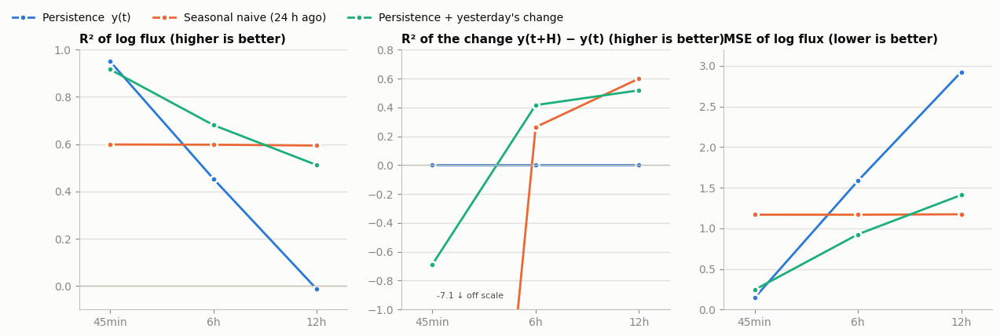

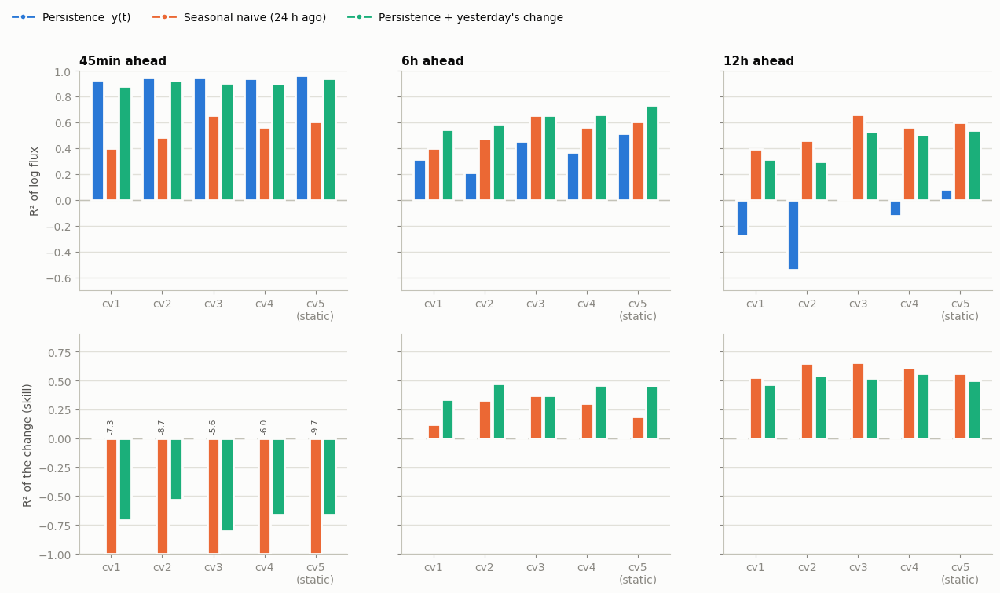

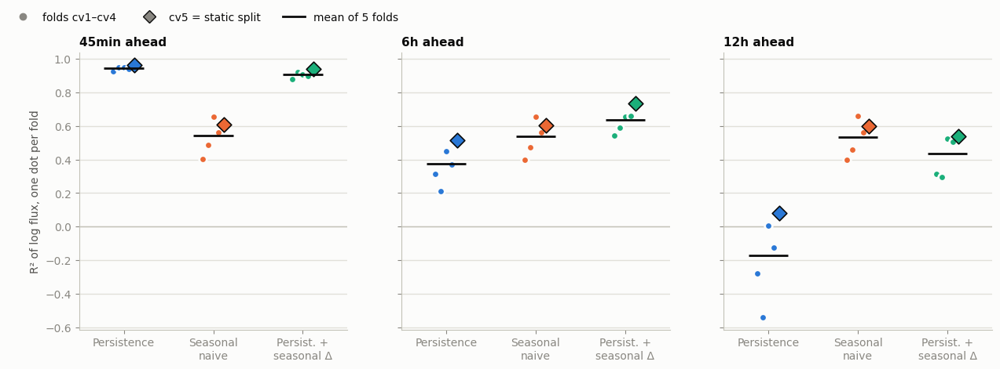

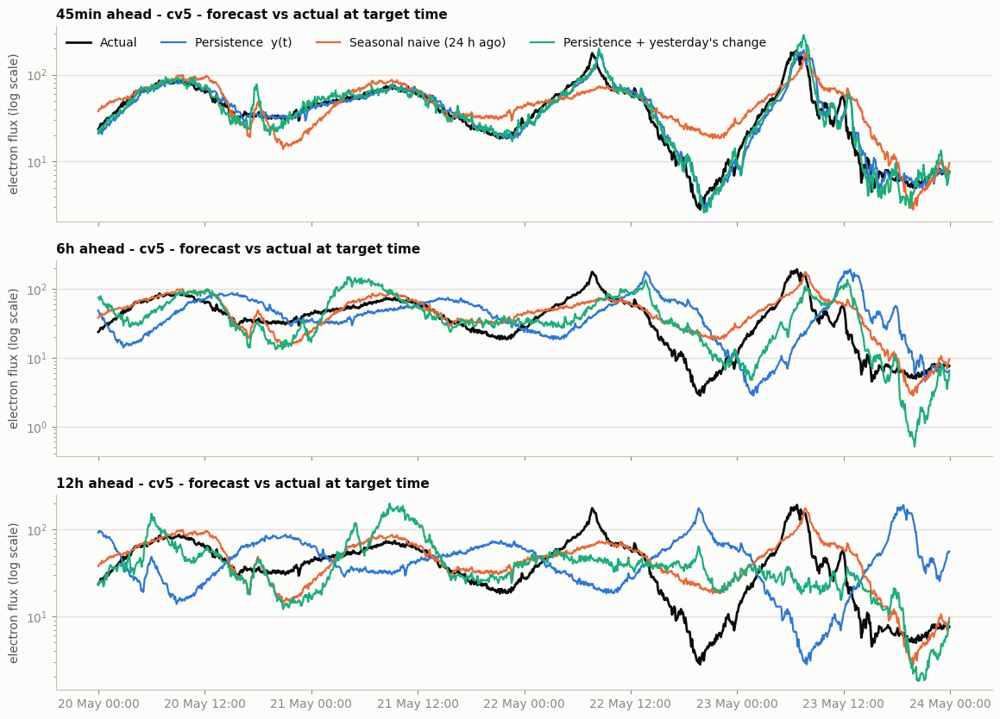

                               model  r2_log  r2_delta  mse_log
horizon                                                        
45min                    persistence   0.950    -0.000    0.144
6h       persist_plus_seasonal_delta   0.681     0.416    0.926
12h                   seasonal_naive   0.594     0.599    1.172


In [15]:
import sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P
from runio import RUN, load_grid

FIG = RUN / "figs"; FIG.mkdir(exist_ok=True)
res = pd.read_csv(RUN / "reports" / "baselines_per_fold.csv")
pooled = pd.read_csv(RUN / "reports" / "baselines_pooled.csv")
res, pooled = res[res.eval_set == "scored"], pooled[pooled.eval_set == "scored"]

HZ = list(P.horizons); FOLDS = [f"cv{k}" for k in range(1, 6)]
MODELS = ["persistence", "seasonal_naive", "persist_plus_seasonal_delta"]
LABEL = {"persistence": "Persistence  y(t)",
         "seasonal_naive": "Seasonal naive (24 h ago)",
         "persist_plus_seasonal_delta": "Persistence + yesterday's change"}
COL = {"persistence": "#2a78d6", "seasonal_naive": "#eb6834", "persist_plus_seasonal_delta": "#1baf7a"}  # validated slots 1-3
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False,
})

def model_legend(fig, extra=None, ncol=3, y=1.02):
    h = [Line2D([0], [0], color=COL[m], lw=2, marker="o", ms=6, mec=SURF, mew=2, label=LABEL[m]) for m in MODELS]
    fig.legend(handles=(extra or []) + h, loc="upper left", ncol=ncol + len(extra or []), bbox_to_anchor=(0.06, y))

# ------------------------------------------------ 1. pooled metrics vs horizon
def fig_pooled():
    spec = [("r2_log", "R² of log flux (higher is better)", (-0.1, 1.0)),
            ("r2_delta", "R² of the change y(t+H) − y(t) (higher is better)", (-1.0, 0.8)),
            ("mse_log", "MSE of log flux (lower is better)", (0, 3.2))]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
    for ax, (metric, title, yl) in zip(axes, spec):
        for m in MODELS:
            v = pooled[pooled.model == m].set_index("horizon").loc[HZ, metric].to_numpy()
            ax.plot(range(3), v, color=COL[m], lw=2, marker="o", ms=6, mec=SURF, mew=2)
            for i, val in enumerate(v):
                if val < yl[0]:                      # off-scale value: say so instead of letting it vanish
                    ax.annotate(f"{val:.1f} ↓ off scale", (i, yl[0]), xytext=(4, 10), textcoords="offset points",
                                ha="left", fontsize=8, color=INK2)
        if metric != "mse_log":
            ax.axhline(0, color=AXIS, lw=1)
        ax.set_xticks(range(3), HZ); ax.set_xlim(-0.3, 2.3); ax.set_ylim(*yl); ax.set_title(title)
    model_legend(fig)
    fig.savefig(FIG / "1_pooled_by_horizon.png", dpi=150, bbox_inches="tight"); plt.show()

# ------------------------------------------------ 2. per-fold bars (cv5 = static)
def fig_folds():
    rows = [("r2_log", "R² of log flux", (-0.7, 1.0)), ("r2_delta", "R² of the change (skill)", (-1.0, 0.9))]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey="row")
    for r, (metric, ylab, yl) in enumerate(rows):
        t = res.pivot_table(index=["horizon", "model"], columns="fold", values=metric)[FOLDS]
        for c, hz in enumerate(HZ):
            ax, x = axes[r, c], np.arange(5)
            for j, m in enumerate(MODELS):
                v = t.loc[(hz, m)].to_numpy(); xs = x + (j - 1) * 0.27
                ax.bar(xs, np.clip(v, yl[0], yl[1]), width=0.24, color=COL[m], edgecolor=SURF, linewidth=2, zorder=3)
                for xi, vi in zip(xs, v):
                    if vi < yl[0]:                   # clipped bar: print the true value above the baseline
                        ax.text(xi, 0.02 * (yl[1] - yl[0]), f"{vi:.1f}", rotation=90, ha="center", va="bottom",
                                fontsize=7.5, color=INK2)
            ax.axhline(0, color=AXIS, lw=1, zorder=2)
            ax.set_xticks(x, FOLDS[:-1] + ["cv5\n(static)"]); ax.set_ylim(*yl)
            if r == 0: ax.set_title(f"{hz} ahead")
            if c == 0: ax.set_ylabel(ylab)
    model_legend(fig, y=0.99)
    fig.savefig(FIG / "2_per_fold.png", dpi=150, bbox_inches="tight"); plt.show()

# ------------------------------------------------ 3. fold spread: how lucky is the static split?
def fig_spread():
    t = res.pivot_table(index=["horizon", "model"], columns="fold", values="r2_log")[FOLDS]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
    for ax, hz in zip(axes, HZ):
        for i, m in enumerate(MODELS):
            v = t.loc[(hz, m)].to_numpy(); xs = i + (np.arange(5) - 2) * 0.06
            ax.scatter(xs[:4], v[:4], s=48, color=COL[m], edgecolor=SURF, linewidth=2, zorder=3)
            ax.scatter(xs[4:], v[4:], s=90, marker="D", color=COL[m], edgecolor=INK, linewidth=1.2, zorder=4)
            ax.hlines(v.mean(), i - 0.22, i + 0.22, color=INK, lw=2, zorder=5)
        ax.axhline(0, color=AXIS, lw=1)
        ax.set_xticks(range(3), ["Persistence", "Seasonal\nnaive", "Persist. +\nseasonal Δ"])
        ax.set_xlim(-0.5, 2.5); ax.set_title(f"{hz} ahead")
    axes[0].set_ylabel("R² of log flux, one dot per fold")
    key = [Line2D([0], [0], marker="o", ls="", color=MUTED, ms=6, label="folds cv1–cv4"),
           Line2D([0], [0], marker="D", ls="", color=MUTED, mec=INK, ms=8, label="cv5 = static split"),
           Line2D([0], [0], color=INK, lw=2, label="mean of 5 folds")]
    fig.legend(handles=key, loc="upper left", ncol=3, bbox_to_anchor=(0.06, 1.02))
    fig.savefig(FIG / "3_fold_spread.png", dpi=150, bbox_inches="tight"); plt.show()

# ------------------------------------------------ 4. what the forecasts look like
def fig_series(window="cv5", start="2018-05-20", days=4):
    g = load_grid()
    t0 = pd.Timestamp(start); t1 = t0 + pd.Timedelta(days=days)
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    for ax, (hz, H) in zip(axes, P.horizons.items()):
        z = np.load(RUN / "preds" / f"baselines_{window}_{hz}.npz")
        tt = g.index[z["pos"] + H]                   # the TARGET time each forecast is for
        sel = (tt >= t0) & (tt < t1)
        ax.plot(tt[sel], np.exp(z["y"][sel]), color=INK, lw=2, label="Actual")
        for m in MODELS:
            ax.plot(tt[sel], np.exp(z[m][sel]), color=COL[m], lw=1.6, label=LABEL[m])
        ax.set_yscale("log"); ax.set_ylabel("electron flux (log scale)")
        ax.set_title(f"{hz} ahead - {window} - forecast vs actual at target time")
    axes[0].legend(ncol=4, loc="upper left")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
    fig.savefig(FIG / "4_forecast_vs_actual.png", dpi=150, bbox_inches="tight"); plt.show()

fig_pooled(); fig_folds(); fig_spread(); fig_series()

# ------------------------------------------------ the bar every later model must clear (per horizon)
best = pooled.sort_values("mse_log").groupby("horizon").first().loc[HZ, ["model", "r2_log", "r2_delta", "mse_log"]]
best.to_csv(RUN / "reports" / "baseline_to_beat.csv"); print(best.round(3))

## 4.3 `evalkit.py`: one evaluation kit for every model

📘 **What.** Writes the shared evaluation module:
* `metrics(y, p, y0)` returns `n, r2_log, r2_raw, r2_delta, skill_vs_persist, mse_log, mae_log` (and `skill_vs_best` when a best baseline is supplied).
* `common_set(window, hn)` returns the rows all baselines are defined on, so **every model is scored on identical samples**.
* `features_frame(df, H, kind)` builds the **causal** feature frame: lags $y_{t-k}-y_t$ (computed on a forward-filled series so that gaps never leak; later AR cells use the opposite sign $y_t-y_{t-k}$, which only flips the coefficient), time-of-day sin/cos of the **target** time (which is known at forecast time), the "same time yesterday" reference, rolling means/std at 1 h / 6 h / 1 day, and the recent missing share.
* `run_models(fit_predict, tag)` loops over folds and horizons, calls the model's `fit_predict` with **training rows only**, scores it, pools the results and writes CSVs.

🎯 **Why.** If each experiment wrote its own loop, subtle differences in rows, masks or metric definitions would contaminate comparisons. One kit removes that risk.

In [16]:
%%writefile /kaggle/working/final_run/evalkit.py
"""Shared evaluation kit: one common sample set + identical metrics for every model."""
import numpy as np, pandas as pd
from core import P
from runio import RUN, load_split

FOLDS = [f"cv{k}" for k in range(1, 6)]          # the sealed test is never touched here
HZ = list(P.horizons)
DAY = 288
LAGS = [1, 2, 3, 6, 12, 24, 36, 72, 144, 216, 288]

def metrics(y, p, y0, pbest=None):
    e = y - p; sse = np.sum(e ** 2); d = y - y0
    ey, pe = np.exp(y), np.exp(p)
    out = {"n": len(y),
           "r2_log": 1 - sse / np.sum((y - y.mean()) ** 2),
           "r2_raw": 1 - np.sum((ey - pe) ** 2) / np.sum((ey - ey.mean()) ** 2),
           "r2_delta": 1 - sse / np.sum((d - d.mean()) ** 2),
           "skill_vs_persist": 1 - sse / np.sum(d ** 2),
           "mse_log": sse / len(y), "mae_log": np.abs(e).mean()}
    if pbest is not None:
        out["skill_vs_best"] = 1 - sse / np.sum((y - pbest) ** 2)
    return out

def best_baseline():
    d = pd.read_csv(RUN / "reports" / "baselines_pooled.csv")
    d = d[d.eval_set == "scored"]
    return d.sort_values("mse_log").groupby("horizon").first()["model"].to_dict()

def common_set(window, hn):
    """Samples every model is scored on = val_scored with all three baselines defined."""
    z = np.load(RUN / "preds" / f"baselines_{window}_{hn}.npz")
    return z["pos"], z["y"], {k: z[k] for k in z.files if k not in ("pos", "y")}

def features_frame(df, H, kind="full"):
    """Full-grid features for horizon H. Row t uses data stamped <= t (plus the calendar time of t+H)."""
    Lf = np.log(df["electron"]).ffill()              # last-observation-carried-forward: backward-looking only
    cols = {"y0": Lf}
    for k in LAGS:
        cols[f"d{k}"] = Lf.shift(k) - Lf
    if kind == "full":
        mod = (df.index.hour * 60 + df.index.minute).to_numpy()
        tod = ((mod + 5 * H) % 1440) / 1440.0        # time of day of the TARGET (known at forecast time)
        for k in (1, 2, 3):
            cols[f"sin{k}"] = np.sin(2 * np.pi * k * tod)
            cols[f"cos{k}"] = np.cos(2 * np.pi * k * tod)
        cols["seas_ref"] = Lf.shift(DAY - H) - Lf    # value 24 h before the target time
        for w, mp in ((12, 6), (72, 36), (288, 144)):
            r = Lf.rolling(w, min_periods=mp)
            cols[f"m{w}"] = r.mean() - Lf
            cols[f"s{w}"] = r.std()
        cols["miss288"] = df["missing"].astype(float).rolling(DAY, min_periods=1).mean()
    return pd.DataFrame(cols, index=df.index)

def run_models(fit_predict, tag):
    """fit_predict(window, hn, H, train_pos, eval_pos) -> {model_name: log-flux predictions at eval_pos}.
    Called once per (fold, horizon); must fit on train_pos ONLY."""
    best = best_baseline()
    rows, pool = [], {}
    for hn, H in P.horizons.items():
        for w in FOLDS:
            s = load_split(w, hn)
            pos, y, base = common_set(w, hn)
            preds = fit_predict(w, hn, H, s["train"], pos)
            for m, p in preds.items():
                assert np.isfinite(p).all(), f"{m}: non-finite predictions in {w} {hn}"
            allp = {**base, **preds}
            y0, pb = base["persistence"], base[best[hn]]
            for m, p in allp.items():
                rows.append({"horizon": hn, "fold": w, "model": m, **metrics(y, p, y0, pb)})
                pool.setdefault((hn, m), []).append((y, p, y0, pb))
            np.savez_compressed(RUN / "preds" / f"{tag}_{w}_{hn}.npz", pos=pos, y=y, **preds)
    res = pd.DataFrame(rows)
    pooled = pd.DataFrame([{"horizon": hn, "model": m, **metrics(*[np.concatenate(c) for c in zip(*lst)])}
                           for (hn, m), lst in pool.items()])
    res.to_csv(RUN / "reports" / f"{tag}_per_fold.csv", index=False)
    pooled.to_csv(RUN / "reports" / f"{tag}_pooled.csv", index=False)
    return res, pooled

def show(res, pooled, metric_names=("r2_log", "r2_delta", "skill_vs_best", "mse_log")):
    pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 220)
    order = {h: i for i, h in enumerate(HZ)}
    for mt in metric_names:
        t = res.pivot_table(index=["horizon", "model"], columns="fold", values=mt)[FOLDS]
        t["mean"], t["std"] = t.mean(axis=1), t[FOLDS].std(axis=1)
        t["pooled"] = pooled.set_index(["horizon", "model"])[mt]
        print(f"\n=== {mt} ===")
        print(t.sort_index(key=lambda ix: ix.map(order) if ix.name == "horizon" else ix))

Writing /kaggle/working/final_run/evalkit.py


## 4.4 The first model comparison: climatology (negative control) and ridge AR

📘 **What.** Adds two things to the baseline set and runs the *feature causality* and *fit independence* tests before fitting.

**(a) Climatology by hour of day (negative control).** Predict the mean log flux of the target's hour of day,
$$\hat y_{t+H}=\bar y_{\text{hour}(t+H)},$$
estimated on training rows only (60-minute bins). It is **expected to fail**; if it ever wins, something is wrong.

**(b) Ridge AR on the change.** Predict the change, not the level:
$$\hat\Delta_t=\mathbf z_t^{\top}\boldsymbol\beta+b,\qquad
\boldsymbol\beta=\arg\min_{\boldsymbol\beta}\ \sum_{t\in\text{train}}\big(\Delta_t-\mathbf z_t^{\top}\boldsymbol\beta-b\big)^2+\alpha\,\|\boldsymbol\beta\|_2^2,$$
with the closed form $\hat{\boldsymbol\beta}=(Z^{\top}Z+\alpha I)^{-1}Z^{\top}\Delta$ on **standardised** features $z=(x-\mu_{\text{train}})/\sigma_{\text{train}}$ (means and standard deviations from the training rows only).
The penalty $\alpha$ is chosen from $\{10^{-2},10^{-1},\dots,10^{4}\}$ by an inner split inside the training rows. The forecast is then $\hat y_{t+H}=y_t+\hat\Delta_t$.

`ridge_ar_lags` uses only lag changes; `ridge_ar_full` adds three harmonics of the target's time of day, the value 24 h before the target, the rolling mean-deviation and rolling standard deviation over 1 h / 6 h / 1 d, and the recent share of missing data.

In [18]:
import sys, json, time
import numpy as np, pandas as pd
from sklearn.linear_model import Ridge
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio, evalkit
for mod in (core, runio, evalkit): importlib.reload(mod)
from core import P
from runio import RUN, load_grid, load_split
from evalkit import features_frame, run_models, show, FOLDS

g = load_grid()
L = np.log(g["electron"].to_numpy())
MOD = (g.index.hour * 60 + g.index.minute).to_numpy()
EMB, BIN = P.embargo_steps, 60                    # 24 h embargo; climatology bin = 60 min
NB = 1440 // BIN
ALPHAS = [1e-2, 1e-1, 1, 10, 100, 1e3, 1e4]
FEAT = {(k, H): features_frame(g, H, k) for k in ("lags", "full") for H in P.horizons.values()}
FNAMES = {k: list(FEAT[(k, 72)].columns) for k in ("lags", "full")}

# ---------------- climatology: mean log flux of the TARGET's hour-of-day (interval-end stamps -> shift by 5 min)
def fit_clim(Lv, tr_pos, H):
    tgt = tr_pos + H
    b, y = ((MOD[tgt] - 5) // BIN) % NB, Lv[tgt]
    tab = np.array([y[b == k].mean() for k in range(NB)])
    assert np.isfinite(tab).all()
    return tab

def predict_clim(tab, pos, H):
    return tab[((MOD[pos + H] - 5) // BIN) % NB]

# ---------------- ridge on the CHANGE y(t+H) - y(t), standardised on train only
def _xy(F, Lv, pos, H):
    X = F[pos]; ok = np.isfinite(X).all(1)
    pos, X = pos[ok], X[ok]
    return pos, X, Lv[pos + H] - Lv[pos]

def fit_ridge(F, Lv, tr_pos, H, alpha):
    _, X, d = _xy(F, Lv, tr_pos, H)
    mu, sd = X.mean(0), X.std(0); sd[sd == 0] = 1.0
    m = Ridge(alpha=alpha).fit((X - mu) / sd, d)
    return {"mu": mu, "sd": sd, "coef": m.coef_, "b": m.intercept_}

def predict_ridge(mdl, F, pos):
    X = F[pos]; assert np.isfinite(X).all(), "non-finite features at evaluation origins"
    return ((X - mdl["mu"]) / mdl["sd"]) @ mdl["coef"] + mdl["b"]

def pick_alpha(F, Lv, tr_pos, H):
    """Inner blocked split INSIDE the training data (last 20% = inner val, 24 h embargo). The fold's validation data is never used."""
    pos, _, _ = _xy(F, Lv, tr_pos, H)
    c = int(0.8 * len(pos)); cut = pos[c]
    inner_tr, inner_va = pos[pos + H <= cut - EMB], pos[c:]
    dva = Lv[inner_va + H] - Lv[inner_va]
    errs = [np.mean((dva - predict_ridge(fit_ridge(F, Lv, inner_tr, H, a), F, inner_va)) ** 2) for a in ALPHAS]
    return ALPHAS[int(np.argmin(errs))]

# ================= LEAKAGE CHECKS (run before any scoring) =================
t0 = time.time()
cuts = core.default_cuts(g)
for kind in ("lags", "full"):                      # 1) features at row <= cut must not change when the future is destroyed
    bad = core.find_causal_violations(lambda df, k=kind: features_frame(df, 72, k), g, cuts)
    assert not bad, f"{kind} features leak: {bad}"
print("feature causality: OK")

H = 72; tr = load_split("cv3", "6h")["train"]; train_end = g.index[tr.max() + H]
def fit_probe(df, te):                             # 2) fitted parameters must ignore everything after the training end
    Lx = np.log(df["electron"].to_numpy())
    mdl = fit_ridge(features_frame(df, H, "full").to_numpy(), Lx, tr, H, 1.0)
    return {"clim": fit_clim(Lx, tr, H), "coef": mdl["coef"], "b": [mdl["b"]], "mu": mdl["mu"]}
bad = core.find_fit_violations(fit_probe, g, train_end)
assert not bad, f"fitted parameters depend on the future: {bad}"
print(f"fit independence: OK  ({time.time() - t0:.0f}s)")

# ================= SCORING =================
ALPHA_LOG, COEF_ROWS = {}, []
def fit_predict(w, hn, H, tr_pos, ev_pos):
    out = {"climatology_hod": predict_clim(fit_clim(L, tr_pos, H), ev_pos, H)}
    for kind, name in (("lags", "ridge_ar_lags"), ("full", "ridge_ar_full")):
        F = FEAT[(kind, H)].to_numpy()
        a = pick_alpha(F, L, tr_pos, H)
        mdl = fit_ridge(F, L, tr_pos, H, a)
        out[name] = L[ev_pos] + predict_ridge(mdl, F, ev_pos)          # y(t) + predicted change
        ALPHA_LOG[(w, hn, name)] = a
        COEF_ROWS.extend({"fold": w, "horizon": hn, "model": name, "feature": f, "coef_std": c}
                         for f, c in zip(FNAMES[kind], mdl["coef"]))
    return out

res, pooled = run_models(fit_predict, "linear")
show(res, pooled)

pd.DataFrame(COEF_ROWS).to_csv(RUN / "reports" / "linear_coefs.csv", index=False)
print("\n=== chosen ridge alpha ===")
print(pd.Series(ALPHA_LOG).unstack(level=2).rename_axis(["fold", "horizon"]).to_string())
print("\n=== largest standardised coefficients, ridge_ar_full, cv5 ===")
cf = pd.DataFrame(COEF_ROWS); cf = cf[(cf.model == "ridge_ar_full") & (cf.fold == "cv5")]
for hn in P.horizons:
    d = cf[cf.horizon == hn].assign(a=lambda x: x.coef_std.abs()).nlargest(6, "a")
    print(hn, "|", ", ".join(f"{f} {c:+.3f}" for f, c in zip(d.feature, d.coef_std)))

feature causality: OK
fit independence: OK  (14s)

=== r2_log ===
fold                                   cv1    cv2    cv3    cv4   cv5   mean   std  pooled
horizon model                                                                             
45min   climatology_hod             -0.248 -1.281 -0.193  0.084 0.140 -0.300 0.574  -0.079
        persist_plus_seasonal_delta  0.877  0.919  0.906  0.896 0.939  0.908 0.023   0.916
        persistence                  0.928  0.947  0.948  0.938 0.963  0.945 0.013   0.950
        ridge_ar_full                0.942  0.954  0.954  0.948 0.970  0.954 0.011   0.958
        ridge_ar_lags                0.939  0.954  0.955  0.947 0.969  0.953 0.011   0.958
        seasonal_naive               0.401  0.487  0.655  0.562 0.607  0.542 0.100   0.598
6h      climatology_hod             -0.252 -1.342 -0.189  0.080 0.136 -0.313 0.599  -0.082
        persist_plus_seasonal_delta  0.545  0.588  0.656  0.661 0.733  0.637 0.073   0.681
        persistence     

👀 **How to read this output**

Both tests print `OK` first: `feature causality: OK`, `fit independence: OK (14s)`.

| 45 min, pooled | $R^2_{\log}$ | $R^2_\Delta$ |
|---|---|---|
| Climatology by hour | **−0.079** | **−20.8** |
| Persistence | 0.950 | 0.000 |
| Persist + seasonal delta | 0.916 | −0.689 |
| `ridge_ar_lags` | 0.958 | 0.143 |
| **`ridge_ar_full`** | **0.958** | **0.161** |

* The negative control **fails exactly as intended**, which is reassuring: a fixed daily curve cannot predict the level because the level shifts between folds (per-fold $R^2_{\log}$: −0.25, −1.28, −0.19, +0.08, +0.14).
* At **45 min** the ridge AR already explains **14–16 %** of the change, while the level metric barely moves (0.950 → 0.958). This is the moment the project's metric was settled.
* At 6 h it explains **61–67 %** of the change ($R^2_\Delta$ 0.612 / 0.667) and lifts $R^2_{\log}$ from 0.454 (persistence) to 0.788 / 0.818.

### 4.5 Why climatology fails: the bias check

📘 **What.** For climatology at 6 h, compares $R^2$ on the *training* rows, the *validation* $R^2$, the **mean bias** in each fold, and the $R^2$ that would result if that bias were removed.

📐 $\text{bias}_k=\overline{\,y_{t+H}-\hat y_{t+H}\,}$ over fold $k$. If the *shape* is right but the *level* is off, subtracting the bias recovers the lost $R^2$.

In [19]:
from evalkit import common_set
H, hn = 72, "6h"
print(f"{'fold':5s} {'r2_train':>9s} {'bias':>7s} {'r2_val':>8s} {'r2_after_removing_bias':>23s}")
for w in FOLDS:
    s = load_split(w, hn); pos, y, _ = common_set(w, hn)
    tab = fit_clim(L, s["train"], H)
    tr = s["train"]; ytr, ptr = L[tr + H], predict_clim(tab, tr, H)
    p = predict_clim(tab, pos, H); bias = (y - p).mean()
    sst = ((y - y.mean()) ** 2).sum()
    print(f"{w:5s} {1 - ((ytr - ptr) ** 2).sum() / ((ytr - ytr.mean()) ** 2).sum():9.3f} {bias:7.2f} "
          f"{1 - ((y - p) ** 2).sum() / sst:8.3f} {1 - (((y - p) - bias) ** 2).sum() / sst:23.3f}")

fold   r2_train    bias   r2_val  r2_after_removing_bias
cv1       0.178   -1.11   -0.252                   0.221
cv2       0.175   -1.58   -1.342                   0.234
cv3       0.159   -0.94   -0.189                   0.099
cv4       0.142    0.53    0.080                   0.173
cv5       0.147   -0.14    0.136                   0.144


👀 **How to read this output**

| Fold | $R^2$ train | Bias | $R^2$ validation | $R^2$ after removing bias |
|---|---|---|---|---|
| cv1 | 0.178 | −1.11 | −0.252 | **0.221** |
| cv2 | 0.175 | −1.58 | −1.342 | **0.234** |
| cv3 | 0.159 | −0.94 | −0.189 | 0.099 |
| cv4 | 0.142 | +0.53 | 0.080 | 0.173 |
| cv5 | 0.147 | −0.14 | 0.136 | 0.144 |

The curve's **shape** is right (once the bias is removed, $R^2$ is 0.10–0.23 in every fold), but its **level** is off by −1.58 to +0.53 in log units depending on the fold, a factor of $e^{2.1}\approx8$ between the extreme folds.

✅ **Take-away.** The 24 h cycle is a **shape that helps predict changes**, not a fixed level that predicts flux. This overturns the first notebook's claim that the daily cycle explains 62–64 % of the variance, *as far as prediction is concerned*, and it is the reason the AR and LightGBM models are built on $\Delta$ with time-of-day terms.

---
# Part 5 · Dependence diagnostics

## 5.1 ACF, PACF and cross-correlation on the longest unbroken segment

📘 **What.** On the 19,664-point segment 2017-11-30 → 2018-02-06: ACF of the log level, of the level minus its hour-of-day mean, and of the 5-min change; PACF; and the **cross-correlation function** (CCF) between electron and proton changes.

📐 $\text{CCF}(k)=\operatorname{Corr}\big(\Delta e_{t},\,\Delta p_{t-k}\big)$: a peak at $k>0$ would mean protons lead electrons.

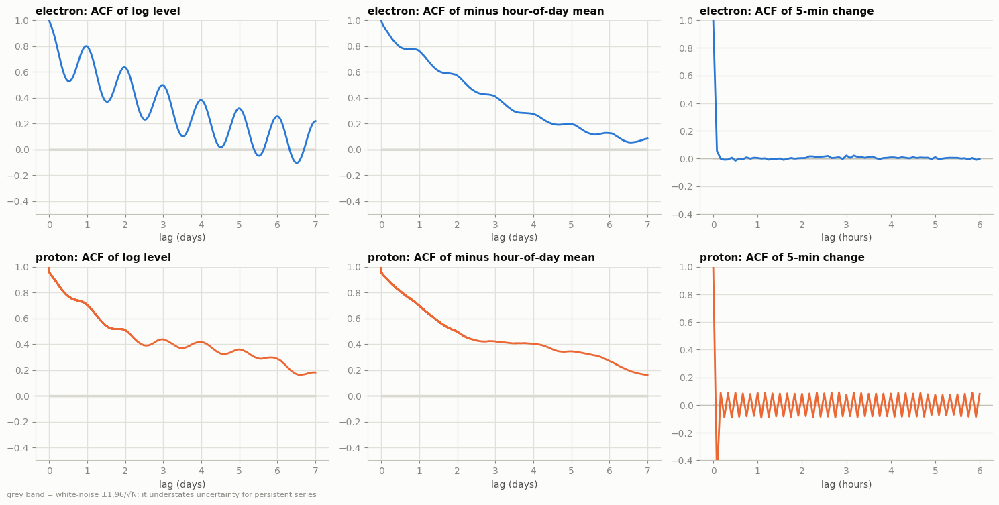


=== ACF at selected lags ===
       electron                                        proton                                    
      log level minus hour-of-day mean 5-min change log level minus hour-of-day mean 5-min change
5 min     0.997                  0.997        0.056     0.957                  0.956       -0.520
1 h       0.967                  0.967        0.005     0.943                  0.942        0.088
6 h       0.744                  0.872       -0.003     0.859                  0.877        0.080
12 h      0.528                  0.792       -0.016     0.773                  0.811        0.072
24 h      0.798                  0.763        0.025     0.705                  0.698        0.049
48 h      0.634                  0.571        0.020     0.509                  0.497        0.017
7 d       0.218                  0.084        0.017     0.181                  0.162       -0.004

PACF segment: 2017-11-30 07:05:00 -> 2018-02-06 13:40:00  (19664 contiguous 5-min slots

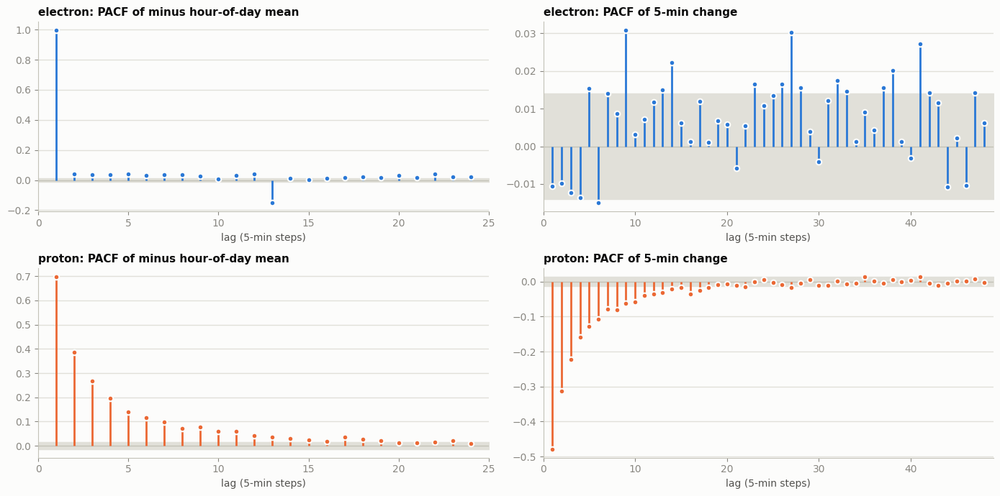

CCF of 5-min change: largest |corr| = +0.156 at lag +0.00 h
CCF of minus hour-of-day mean: largest |corr| = +0.513 at lag +0.00 h


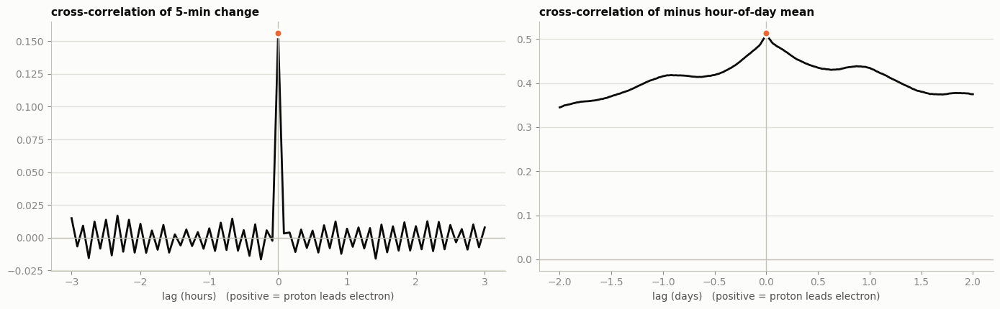

In [3]:
import sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import pacf
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, scoring_mask
from runio import RUN, load_grid

FIG = RUN / "figs"; FIG.mkdir(exist_ok=True)
g = load_grid()
dev = g.loc[:P.dev_end].copy()                      # dev period only: the sealed test is never used
ok = scoring_mask(dev)                              # drops missing / near-outage / glitch spikes (non-causal flags are fine for a diagnostic)

COL = {"electron": "#2a78d6", "proton": "#eb6834"}
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False,
})

# ---------------- series: three views per species (NaN wherever the slot is invalid; nothing is interpolated)
mod = (dev.index.hour * 60 + dev.index.minute).to_numpy()
hod = pd.Series(((mod - 5) // 60) % 24, index=dev.index)       # interval-end stamps -> hour bins
TR = ["log level", "minus hour-of-day mean", "5-min change"]
S = {}
for sp in ("electron", "proton"):
    lv = np.log(dev[sp]).where(ok)
    S[sp] = {TR[0]: lv, TR[1]: lv - lv.groupby(hod).transform("mean"), TR[2]: lv.diff()}

def acf_pairwise(x, nlags):
    """Pearson correlation of (x_t, x_{t-k}) over pairs where BOTH are observed."""
    x = np.asarray(x, float); out = np.full(nlags + 1, np.nan); npairs = np.zeros(nlags + 1, int)
    for k in range(nlags + 1):
        a, b = x[k:], x[:len(x) - k]
        m = np.isfinite(a) & np.isfinite(b); npairs[k] = m.sum()
        if m.sum() > 100:
            out[k] = np.corrcoef(a[m], b[m])[0, 1]
    return out, npairs

NL = 7 * 288
ACF = {(sp, tr): acf_pairwise(S[sp][tr].to_numpy(), NL) for sp in S for tr in TR}

# ---------------- Figure A: ACF (long lags for the two level views, short lags for the 5-min change)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for r, sp in enumerate(("electron", "proton")):
    for c, tr in enumerate(TR):
        ax = axes[r, c]; a, npairs = ACF[(sp, tr)]
        if c < 2:
            lags, x, unit = np.arange(NL + 1), np.arange(NL + 1) / 288, "lag (days)"
        else:
            lags, x, unit = np.arange(73), np.arange(73) * 5 / 60, "lag (hours)"
        band = 1.96 / np.sqrt(np.maximum(npairs[lags], 1))
        ax.fill_between(x, -band, band, color=GRID, zorder=1)
        ax.plot(x, a[lags], color=COL[sp], lw=2, zorder=3)
        ax.axhline(0, color=AXIS, lw=1, zorder=2)
        if c < 2:
            ax.set_xticks(range(0, 8)); ax.xaxis.grid(True)
        ax.set_ylim(-0.4 if c == 2 else -0.5, 1.0); ax.set_xlabel(unit)
        ax.set_title(f"{sp}: ACF of {tr}")
fig.text(0.01, 0.005, "grey band = white-noise ±1.96/√N; it understates uncertainty for persistent series", color=MUTED, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "diag_1_acf.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------------- table view of the same numbers
KEY = {"5 min": 1, "1 h": 12, "6 h": 72, "12 h": 144, "24 h": 288, "48 h": 576, "7 d": 2016}
tab = pd.DataFrame({(sp, tr): [ACF[(sp, tr)][0][k] for k in KEY.values()] for sp in S for tr in TR}, index=list(KEY))
pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 220)
print("\n=== ACF at selected lags ==="); print(tab)

# ---------------- Figure B: PACF on the longest contiguous valid stretch (PACF needs no gaps)
okv = ok.to_numpy().astype(np.int8)
dd = np.diff(np.r_[0, okv, 0]); starts, ends = np.flatnonzero(dd == 1), np.flatnonzero(dd == -1)
i = int(np.argmax(ends - starts)); a0, b0 = starts[i], ends[i]
print(f"\nPACF segment: {dev.index[a0]} -> {dev.index[b0 - 1]}  ({b0 - a0} contiguous 5-min slots)")
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for r, sp in enumerate(("electron", "proton")):
    for c, (tr, nl) in enumerate(((TR[1], 24), (TR[2], 48))):
        x = S[sp][tr].to_numpy()[a0 + 1:b0]
        vals = pacf(x, nlags=nl, method="ywm")[1:]
        ax = axes[r, c]; band = 1.96 / np.sqrt(len(x))
        ax.fill_between([0, nl + 1], -band, band, color=GRID, zorder=1)
        ax.vlines(np.arange(1, nl + 1), 0, vals, color=COL[sp], lw=2, zorder=3)
        ax.scatter(np.arange(1, nl + 1), vals, s=30, color=COL[sp], edgecolor=SURF, linewidth=1.5, zorder=4)
        ax.axhline(0, color=AXIS, lw=1, zorder=2); ax.set_xlim(0, nl + 1)
        ax.set_xlabel("lag (5-min steps)"); ax.set_title(f"{sp}: PACF of {tr}")
fig.tight_layout(); fig.savefig(FIG / "diag_2_pacf.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------------- Figure C: cross-correlation (positive lag = proton leads electron)
def ccf(a, b, k):
    n = len(a)
    x, y = (a[k:], b[:n - k]) if k >= 0 else (a[:n + k], b[-k:])
    m = np.isfinite(x) & np.isfinite(y)
    return np.corrcoef(x[m], y[m])[0, 1] if m.sum() > 100 else np.nan

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, tr, ks, unit_div, unit in ((axes[0], TR[2], np.arange(-36, 37), 12, "lag (hours)"),
                                   (axes[1], TR[1], np.arange(-576, 577, 3), 288, "lag (days)")):
    e, p = S["electron"][tr].to_numpy(), S["proton"][tr].to_numpy()
    cc = np.array([ccf(e, p, k) for k in ks]); kk = np.nanargmax(np.abs(cc))
    ax.plot(ks / unit_div, cc, color=INK, lw=2); ax.axhline(0, color=AXIS, lw=1); ax.axvline(0, color=AXIS, lw=1)
    ax.scatter([ks[kk] / unit_div], [cc[kk]], s=60, color=COL["proton"], edgecolor=SURF, linewidth=2, zorder=4)
    ax.set_xlabel(unit + "   (positive = proton leads electron)"); ax.set_title(f"cross-correlation of {tr}")
    print(f"CCF of {tr}: largest |corr| = {cc[kk]:+.3f} at lag {ks[kk] * 5 / 60:+.2f} h")
fig.tight_layout(); fig.savefig(FIG / "diag_3_ccf.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output**

| ACF at | electron level | electron level − hour-of-day mean | electron 5-min change | proton 5-min change |
|---|---|---|---|---|
| 5 min | 0.997 | 0.997 | 0.056 | **−0.520** |
| 1 h | 0.967 | 0.967 | 0.005 | 0.088 |
| 6 h | 0.744 | 0.872 | −0.003 | 0.080 |
| 12 h | 0.528 | 0.792 | −0.016 | 0.072 |
| 24 h | **0.798** | 0.763 | 0.025 | 0.049 |
| 7 d | 0.218 | 0.084 | 0.017 | −0.004 |

* The level has an ACF of 0.997 at 5 min and is still 0.80 at 24 h: the **revisit at 24 h** (0.798 > 0.528 at 12 h) is the daily cycle.
* The change has no memory at 5 minutes (0.056) and none beyond.
* **CCF.** The largest correlation between electron and proton **5-min changes is +0.156, at lag 0**. For the level minus its hour-of-day mean it is +0.513, again at lag 0. The relationship is **contemporaneous**, not leading, so it cannot be used for forecasting. (A lag-0 correlation can exist because both respond to the same driver at the same moment.)

## 5.2 The proton "alternating sample" artefact (cells 18–20)

📘 **What.** Proton's 5-min change has lag-1 autocorrelation −0.52, an obvious sign that **even and odd slots alternate high and low**. Three small checks locate it.

📐 For each slot compare the sample with the average of its two neighbours:
$$r_t=\ln x_t-\tfrac12\big(\ln x_{t-1}+\ln x_{t+1}\big),\qquad \text{parity}_t=\big(\lfloor \text{minute}_t/5\rfloor\bmod 2\big).$$
With no artefact $\mathbb E[r_t]$ is the same on even and odd slots. Define $s_t=+1$ (even) / $-1$ (odd) and a daily score $\bar{(r\cdot s)}_d$ (positive means even slots are high that day).

In [4]:
parity = (dev.index.minute // 5) % 2
for sp in ("electron", "proton"):
    lv = np.log(dev[sp]).where(ok)
    resid = lv - 0.5 * (lv.shift(1) + lv.shift(-1))           # deviation from the average of both neighbours
    t = resid.groupby(parity).agg(["mean", "std", "count"])
    t["se"] = t["std"] / np.sqrt(t["count"])
    print(sp); print(t.round(4)); print()

electron
    mean   std  count    se
t                          
0  0.001 0.088  51557 0.000
1 -0.001 0.086  51561 0.000

proton
    mean   std  count    se
t                          
0  0.006 0.181  51557 0.001
1 -0.006 0.181  51561 0.001



👀 **How to read this output** (cell 18, mean of $r_t$ by parity)

| Series | even | odd |
|---|---|---|
| **Electron** | +0.001 | −0.001 |
| **Proton** | **+0.006** | **−0.006** |

Electron's parity means are essentially zero, while proton's are ±0.006 (standard error ≈ 0.001): **the artefact is in proton, not in electron.**

In [5]:
sign = np.where(((dev.index.minute // 5) % 2) == 0, 1.0, -1.0)      # +1 on even slots, -1 on odd slots
day = dev.index.normalize()
for sp in ("electron", "proton"):
    lv = np.log(dev[sp]).where(ok)
    resid = lv - 0.5 * (lv.shift(1) + lv.shift(-1))                 # deviation from the average of both neighbours
    cnt = resid.notna().groupby(day).sum()
    daily = (resid * sign).groupby(day).mean()[cnt > 200]           # > 0 means even slots high that day
    print(f"{sp:8s} days={len(daily)}  mean={daily.mean():+.4f}  std across days={daily.std():.4f}  "
          f"share of days > 0={(daily > 0).mean():.2f}  90th pct |daily|={daily.abs().quantile(.9):.4f}")
    print(f"         expected std across days with NO artefact ≈ {resid.std() / np.sqrt(288):.4f}")

electron days=359  mean=+0.0010  std across days=0.0076  share of days > 0=0.55  90th pct |daily|=0.0104
         expected std across days with NO artefact ≈ 0.0051
proton   days=359  mean=+0.0048  std across days=0.0548  share of days > 0=0.52  90th pct |daily|=0.0302
         expected std across days with NO artefact ≈ 0.0107


👀 **How to read this output** (cell 19, one score per day)

| Series | mean of daily score | std across days | what "no artefact" would give |
|---|---|---|---|
| Electron | +0.0010 | 0.0076 | ≈ 0.0051 |
| **Proton** | +0.0048 | **0.0548** | ≈ 0.0107 |

Proton's day-to-day spread (0.055) is **five times** what noise would produce (0.011), so the artefact **comes and goes** from day to day. Electron's spread (0.0076) is close to its noise level (0.0051). The 90th percentile of $|$daily score$|$ is 0.030 for proton against 0.010 for electron.

In [6]:
half = np.where(dev.index.hour < 12, 0, 1)
lv = np.log(dev["proton"]).where(ok)
resid = lv - 0.5 * (lv.shift(1) + lv.shift(-1))
t = (resid * sign).groupby([day, half]).mean().unstack()
n = resid.notna().groupby([day, half]).sum().unstack()
t = t[(n > 100).all(axis=1)]
print("days:", len(t), "| corr(AM, PM) =", round(t[0].corr(t[1]), 3),
      "| same-sign share =", round((np.sign(t[0]) == np.sign(t[1])).mean(), 2))

days: 357 | corr(AM, PM) = 0.808 | same-sign share = 0.55


👀 **How to read this output** (cell 20, morning vs afternoon)

`corr(AM, PM) = 0.808` over 357 days, but the sign agrees on only 55 % of days. The correlation is carried by the few **big artefact days**: on those days the alternation is present in **both halves of the day at the same strength** (strongest 2017-09-15 → 09-18); on ordinary days it is just noise. So it behaves like a mode that switches on for whole days, not a random glitch.

✅ **Take-away.** Proton is unreliable at the sample level on certain days. Combined with the Granger result (3.5), this is one more reason proton was dropped. The episode is recorded as a protocol disclosure.

## 5.3 Granger tests at 5-min and 1-h scales (HAC)

📘 **What.** The Granger tests of 3.5 repeated with more lags (6/12/36 lags at 5 min; 3/6/12/24 at 1 h) and **daily-cycle controls**, in both directions.

In [21]:
import statsmodels.api as sm

def tod_harmonics(index):                                  # diurnal controls (sin/cos, 3 harmonics) of the row's own time
    tod = (index.hour * 60 + index.minute).to_numpy() / 1440.0
    return np.column_stack([f(2 * np.pi * k * tod) for k in (1, 2, 3) for f in (np.sin, np.cos)])

def hourly(s):                                             # interval-end stamps: hour ending HH:00; needs >= 9 of 12 valid slots
    r = s.resample("1h", closed="right", label="right")
    return r.mean().where(r.count() >= 9)

def granger(target, other, p, hac):
    """Does `other` Granger-cause `target`? Both are differenced log-flux Series with NaN at invalid slots."""
    cols = {"y": target}
    for k in range(1, p + 1):
        cols[f"own{k}"], cols[f"oth{k}"] = target.shift(k), other.shift(k)
    D = pd.DataFrame(cols); ctrl = tod_harmonics(target.index)
    for j in range(ctrl.shape[1]): D[f"c{j}"] = ctrl[:, j]
    D = D.dropna()                                         # rows touching a gap are dropped, never filled
    own = [f"own{k}" for k in range(1, p + 1)]; oth = [f"oth{k}" for k in range(1, p + 1)]
    cc = [c for c in D if c.startswith("c")]
    Xr, Xu = sm.add_constant(D[own + cc]), sm.add_constant(D[own + oth + cc])
    rr = sm.OLS(D["y"], Xr).fit()
    ru = sm.OLS(D["y"], Xu).fit(cov_type="HAC", cov_kwds={"maxlags": hac})
    R = np.zeros((p, Xu.shape[1]))
    for i, c in enumerate(oth): R[i, list(Xu.columns).index(c)] = 1
    ft = ru.f_test(R)
    return {"n": len(D), "F_hac": float(np.squeeze(ft.fvalue)), "p_value": float(np.squeeze(ft.pvalue)),
            "resid_var_removed_pct": 100 * (1 - ru.ssr / rr.ssr), "sum_other_coefs": float(ru.params[oth].sum())}

dE, dP = S["electron"][TR[2]], S["proton"][TR[2]]                          # 5-min changes in log flux
hE, hP = hourly(S["electron"][TR[0]]).diff(), hourly(S["proton"][TR[0]]).diff()   # 1-hour changes
SCALES = {"5-min": (dE, dP, [6, 12, 36], 48), "1-hour": (hE, hP, [3, 6, 12, 24], 12)}

rows = []
for scale, (ye, yp, plist, hac) in SCALES.items():
    for p in plist:
        for direction, (tgt, oth) in (("proton -> electron", (ye, yp)), ("electron -> proton", (yp, ye))):
            rows.append({"scale": scale, "lags": p, "direction": direction, **granger(tgt, oth, p, hac)})
gr = pd.DataFrame(rows)
gr.to_csv(RUN / "reports" / "diag_granger_insample.csv", index=False)
pd.set_option("display.float_format", "{:.4g}".format)
print(gr.to_string(index=False))

 scale  lags          direction      n  F_hac    p_value  resid_var_removed_pct  sum_other_coefs
 5-min     6 proton -> electron 102913  1.277     0.2637                0.02115         -0.01648
 5-min     6 electron -> proton 102913  111.3 1.706e-140                  3.948           0.5368
 5-min    12 proton -> electron 102667  1.509     0.1126                0.05254         -0.04004
 5-min    12 electron -> proton 102667   59.5 1.456e-144                  4.853           0.8289
 5-min    36 proton -> electron 101687  1.113     0.2939                 0.1179          -0.2681
 5-min    36 electron -> proton 101687  26.04 1.489e-172                  4.925           0.8657
1-hour     3 proton -> electron   8545  1.475     0.2192                  0.161          -0.2342
1-hour     3 electron -> proton   8545  11.51  1.593e-07                 0.9244         -0.02412
1-hour     6 proton -> electron   8506 0.7101     0.6414                 0.1577          -0.2319
1-hour     6 electron -> proto

👀 **How to read this output**

| Scale | Lags | proton → electron: F (p) | electron → proton: F (p) |
|---|---|---|---|
| 5 min | 6 | 1.28 (0.26) | **111.3 (1.7e-140)** |
| 5 min | 12 | 1.51 (0.11) | **59.5 (1.5e-144)** |
| 5 min | 36 | 1.11 (0.29) | **26.0 (1.5e-172)** |
| 1 h | 3 | 1.48 (0.22) | 11.5 (1.6e-07) |
| 1 h | 12 | 0.89 (0.56) | 5.38 (3.6e-09) |
| 1 h | 24 | 0.86 (0.66) | 4.23 (2.1e-11) |

**Proton → electron is not significant at any lag or scale (p from 0.11 to 0.66).** Electron → proton is overwhelmingly significant, even though it removes only 1–5 % of residual variance.

## 5.4 Out-of-sample Granger: does adding the other species' lags reduce validation error?

📘 **What.** Refits the model with and without the other species' lags in every fold and horizon (feature causality is re-checked first: `pair-feature causality: OK`) and compares validation MSE with a Diebold–Mariano test.

📐 **Diebold–Mariano (DM).** With loss differential $d_t=L_t^{(A)}-L_t^{(B)}$ (here squared errors) and a HAC variance (Bartlett weights, bandwidth ≈ 1 day),
$$\text{DM}=\frac{\bar d}{\sqrt{\widehat{\text{LRV}}(d)/T}} ,\qquad \widehat{\text{LRV}}=\hat\gamma_0+2\sum_{\ell=1}^{L}\Big(1-\tfrac{\ell}{L+1}\Big)\hat\gamma_\ell .$$
$|\text{DM}|>2$ is roughly significant at 5 %. The HAC correction is essential because 5-minute forecast errors overlap and are strongly autocorrelated.

pair-feature causality: OK

=== % reduction in validation MSE from adding the other species' lags ===
fold                         cv1   cv2   cv3   cv4  cv5  mean  folds_improved
direction          horizon                                                   
electron -> proton 45min    1.79  0.80  1.91  2.16 1.25  1.58               5
                   6h       1.76  7.99 12.77  2.38 2.40  5.46               5
                   12h      2.03 11.87 19.16 -1.18 0.62  6.50               4
proton -> electron 45min   -0.05 -0.34  0.22  0.37 0.37  0.11               3
                   6h      -0.37 -0.81  0.12  0.40 0.46 -0.04               3
                   12h     -0.32 -0.41  0.05 -0.02 0.90  0.04               2

=== Diebold-Mariano t (HAC), positive = other species helps; |t| > 2 is roughly significant ===
fold                         cv1   cv2  cv3   cv4  cv5
direction          horizon                            
electron -> proton 45min    3.48  2.88 3.89  4.25 3.01
            

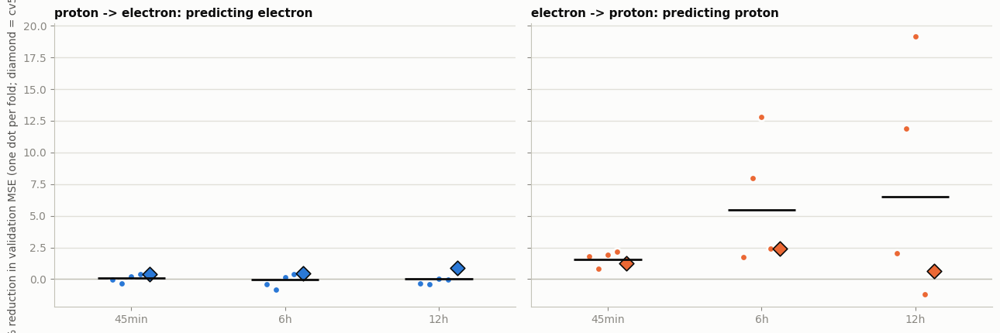

In [22]:
from sklearn.linear_model import Ridge
import evalkit; importlib.reload(evalkit)
from evalkit import LAGS, FOLDS
from runio import load_split

def pair_frame(own, oth, H):
    """Backward-looking features for predicting `own` at t+H; columns starting with 'x_' come from the OTHER species."""
    o, x = own.ffill(), oth.ffill()
    cols = {"y0": o}
    for k in LAGS: cols[f"d{k}"] = o.shift(k) - o
    tod = (((own.index.hour * 60 + own.index.minute).to_numpy() + 5 * H) % 1440) / 1440.0
    for k in (1, 2, 3):
        cols[f"sin{k}"], cols[f"cos{k}"] = np.sin(2 * np.pi * k * tod), np.cos(2 * np.pi * k * tod)
    cols["seas_ref"] = o.shift(288 - H) - o
    cols["m288"] = o.rolling(288, min_periods=144).mean() - o
    cols["x_y0"] = x
    for k in LAGS: cols[f"x_d{k}"] = x.shift(k) - x
    cols["x_m288"] = x.rolling(288, min_periods=144).mean() - x
    return pd.DataFrame(cols, index=own.index)

# leakage check on the feature builder (perturb the future; features at rows <= cut must not change)
bad = core.find_causal_violations(
    lambda df: pair_frame(np.log(df["electron"]), np.log(df["proton"]), 72), g, core.default_cuts(g))
assert not bad, f"pair features leak: {bad}"
print("pair-feature causality: OK")

def fit_pred(Ftr, ytr, Fva, alpha=10.0):                   # same fixed alpha for restricted and unrestricted: a fair comparison
    mu, sd = Ftr.mean(0), Ftr.std(0); sd[sd == 0] = 1.0
    return Ridge(alpha=alpha).fit((Ftr - mu) / sd, ytr).predict((Fva - mu) / sd)

Le_s, Lp_s = np.log(g["electron"]), np.log(g["proton"])
DIRS = {"proton -> electron": (Le_s, Lp_s), "electron -> proton": (Lp_s, Le_s)}      # (series being predicted, the other series)
rows = []
for dname, (own, oth) in DIRS.items():
    Lo = own.to_numpy()
    for hn, H in P.horizons.items():
        F = pair_frame(own, oth, H)
        cols_r = [c for c in F.columns if not c.startswith("x_")]
        Fu, Fr = F.to_numpy(), F[cols_r].to_numpy()
        for w in FOLDS:                                    # dev folds only; the test windows are never loaded
            s = load_split(w, hn)
            tr, va = s["train"], s["val_scored"]
            tr, va = tr[np.isfinite(Fu[tr]).all(1)], va[np.isfinite(Fu[va]).all(1)]
            ytr, yva = Lo[tr + H] - Lo[tr], Lo[va + H] - Lo[va]
            er = yva - fit_pred(Fr[tr], ytr, Fr[va])
            eu = yva - fit_pred(Fu[tr], ytr, Fu[va])
            d = er ** 2 - eu ** 2                          # > 0 means the other species' lags helped
            t = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": H + 12}).tvalues[0]
            rows.append({"direction": dname, "horizon": hn, "fold": w, "n": len(d),
                         "mse_restricted": (er ** 2).mean(), "mse_with_other": (eu ** 2).mean(),
                         "gain_pct": 100 * (1 - (eu ** 2).mean() / (er ** 2).mean()), "dm_t": t})
oos = pd.DataFrame(rows); oos.to_csv(RUN / "reports" / "diag_granger_oos.csv", index=False)

order = {h: i for i, h in enumerate(P.horizons)}
srt = lambda ix: ix.map(order) if ix.name == "horizon" else ix
gain = oos.pivot_table(index=["direction", "horizon"], columns="fold", values="gain_pct")[FOLDS]
gain["mean"] = gain.mean(axis=1); gain["folds_improved"] = (gain[FOLDS] > 0).sum(axis=1)
dmt = oos.pivot_table(index=["direction", "horizon"], columns="fold", values="dm_t")[FOLDS]
pd.set_option("display.float_format", "{:.2f}".format)
print("\n=== % reduction in validation MSE from adding the other species' lags ===")
print(gain.sort_index(key=srt))
print("\n=== Diebold-Mariano t (HAC), positive = other species helps; |t| > 2 is roughly significant ===")
print(dmt.sort_index(key=srt))

# ---------------- figure: gain per fold, one dot per fold
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (dname, tgt) in zip(axes, (("proton -> electron", "electron"), ("electron -> proton", "proton"))):
    for i, hn in enumerate(P.horizons):
        v = oos[(oos.direction == dname) & (oos.horizon == hn)].set_index("fold").loc[FOLDS, "gain_pct"].to_numpy()
        xs = i + (np.arange(5) - 2) * 0.06
        ax.scatter(xs[:4], v[:4], s=48, color=COL[tgt], edgecolor=SURF, linewidth=2, zorder=3)
        ax.scatter(xs[4:], v[4:], s=90, marker="D", color=COL[tgt], edgecolor=INK, linewidth=1.2, zorder=4)
        ax.hlines(v.mean(), i - 0.22, i + 0.22, color=INK, lw=2, zorder=5)
    ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(range(3), list(P.horizons)); ax.set_xlim(-0.5, 2.5)
    ax.set_title(f"{dname}: predicting {tgt}")
axes[0].set_ylabel("% reduction in validation MSE (one dot per fold; diamond = cv5)")
fig.tight_layout(); fig.savefig(FIG / "diag_4_granger_oos.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output** (MSE reduction %, mean of folds; DM per fold)

| Direction | Horizon | cv1…cv5 mean gain | Folds improved |
|---|---|---|---|
| **electron → proton** | 45 min | **+1.58 %** | **5 of 5** |
| electron → proton | 6 h | +5.46 % | 5 of 5 |
| electron → proton | 12 h | +6.50 % | 4 of 5 |
| **proton → electron** | 45 min | +0.11 % | 3 of 5 |
| proton → electron | 6 h | −0.04 % | 3 of 5 |
| proton → electron | 12 h | +0.04 % | 2 of 5 |

For proton → electron the DM statistics flip sign between folds (45 min: −0.50, **−2.90**, 1.46, 2.17, 1.54): noise. For electron → proton at 45 min they are **+3.48, +2.88, +3.89, +4.25, +3.01**: significant in every fold.

✅ **Take-away.** Pivot 6 is justified out of sample: protons do not help forecast electron flux.

---
# Part 6 · The AR models

> 📘 "AR" here means a **linear autoregression on the change**, fitted by ridge regression. It is the finance-style workhorse: transparent, fast, and a fair baseline for non-linear models.

## 6.1 The AR specification in full

**Target.** $\Delta_t^{H}=y_{t+H}-y_t$ with $y=\ln(\text{flux})$. The forecast is $\hat y_{t+H}=y_t+\hat\Delta_t^{H}$.

**Lag features** (changes over the last $L$ steps, computed on a forward-filled series so gaps never leak the future):
$$d_L(t)=y_t-y_{t-L},\qquad L\in\{1,2,3,6,12,24,36,72,144,216,288\}\ \ (\text{5 min up to }24\text{ h}).$$

**Deviation-from-mean features** (is the series high or low relative to its recent level?):
$$\text{dev}_K(t)=y_t-\frac1K\sum_{i=0}^{K-1}y_{t-i},\qquad K\in\{72,288,864\}\ \ (6\text{ h},\,1\text{ d},\,3\text{ d}).$$

**Time-of-day terms.** With $\text{tod}$ the minutes since midnight of the interval start, $\text{tod}=(\text{minute}-5)\bmod1440$, and $\theta=2\pi\,\text{tod}/1440$,
$$s_1=\sin\theta,\ \ c_1=\cos\theta,\ \ s_2=\sin2\theta,\ \ c_2=\cos2\theta .$$
A first harmonic captures one cycle per day and a second captures 12-hour asymmetry. Sine and cosine together let the model place the cycle's phase anywhere:
$a\sin\theta+b\cos\theta=R\sin(\theta+\varphi)$ with $R=\sqrt{a^2+b^2}$ and $\varphi=\operatorname{atan2}(b,a)$. The reason for using two terms instead of the raw clock time is that **midnight must sit next to 23:55**; a raw number puts them at opposite ends.

**Same-phase change yesterday.** $sd_1(t)=y_{t+H-288}-y_{t-288}$ is the change that happened over the same clock window one day earlier (and $sd_3$ is the 3-day mean). Both are known at time $t$.

**Standardisation and fitting.** For each fold, with training means $\mu$ and standard deviations $\sigma$ (training rows only),
$$z=\frac{x-\mu}{\sigma},\qquad \hat{\boldsymbol\beta}_\alpha=\big(Z^\top Z+\alpha I\big)^{-1}Z^\top\Delta,\qquad \alpha\in\{10^{-2},10^{-1},\dots,10^{4}\}.$$

**Choosing $\alpha$ by blocked forward chaining.** The training rows are cut into five consecutive blocks. For $b=1..4$ the model is fitted on the rows whose **target time ends at least 24 h before block $b$** and scored on block $b$; $\alpha$ is the value with the smallest mean MSE. This mimics the outer protocol *inside* training, so there is no look-ahead in hyper-parameter selection.

**Which rows are used.** A row is used only when the origin and target are observed and the non-causal flags are clear; flagged rows decide *membership* of the training/scoring sets but are never features.

## 6.2 Lag-set study: how far back should the AR look?

📘 **What.** Compares AR models whose lag set reaches back **1 h, 6 h, 1 d, 2 d, 3 d and 7 d**, and four **selection rules** for choosing among them in each fold: lowest ridge CV error (`sel_cv`), AIC, BIC, and the one-standard-error rule (`sel_1se`, the smallest lag set whose CV error is within one SE of the best).

📐 With $n$ training rows, $k$ parameters (including the intercept) and the residual variance $\hat\sigma^2$ of a plain OLS fit:
$$\text{AIC}=n\ln\hat\sigma^2+2k,\qquad \text{BIC}=n\ln\hat\sigma^2+k\ln n .$$

done 30min
done 45min
done 1h

pooled skill vs persistence (= R2 of the change), by lag reach
H        30min  45min     1h
model                       
to_1h   0.0857 0.1270 0.1660
to_6h   0.0853 0.1254 0.1631
to_1d   0.1054 0.1538 0.1986
to_2d   0.1051 0.1536 0.1982
to_3d   0.1041 0.1523 0.1967
to_7d   0.1051 0.1535 0.1982
sel_1se 0.0857 0.1270 0.1660
sel_cv  0.1049 0.1534 0.1988
sel_bic 0.1051 0.1535 0.1982
sel_aic 0.1051 0.1535 0.1982

lag set chosen in each fold
    H fold sel_cv sel_1se sel_bic sel_aic
30min  cv1  to_3d   to_1h   to_7d   to_7d
30min  cv2  to_7d   to_1h   to_7d   to_7d
30min  cv3  to_7d   to_1h   to_7d   to_7d
30min  cv4  to_7d   to_1h   to_7d   to_7d
30min  cv5  to_7d   to_1h   to_7d   to_7d
45min  cv1  to_3d   to_1h   to_7d   to_7d
45min  cv2  to_7d   to_1h   to_7d   to_7d
45min  cv3  to_7d   to_1h   to_7d   to_7d
45min  cv4  to_7d   to_1h   to_7d   to_7d
45min  cv5  to_7d   to_1h   to_7d   to_7d
   1h  cv1  to_1d   to_1h   to_7d   to_7d
   1h  cv2  to_7d   to_1h

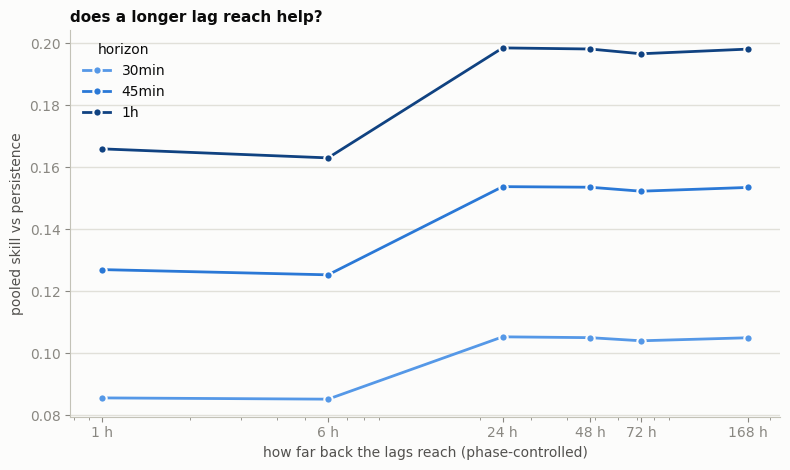

In [17]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

# ------------------------------------------------ setup (dev period only)
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()
assert dev.index.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
for sub in ("reports", "figs"): (RUN / sub).mkdir(exist_ok=True)

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False})

HZ = {"30min": 6, "45min": 9, "1h": 12}                          # horizons in 5-min steps
EMB = P.embargo_steps; EMBt = pd.Timedelta(minutes=5 * EMB)
ALPHAS = np.logspace(-2, 4, 7)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy()
tod = np.asarray((dev.index.hour * 60 + dev.index.minute - 5) % 1440); th = 2 * np.pi * tod / 1440
BAD = ["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]
bad = dev[BAD].fillna(0).astype(bool).any(axis=1).to_numpy()     # non-causal flags: only used to choose which targets are trained/scored on

def metrics(yt, yp, y0):
    e = yt - yp; sse = (e ** 2).sum(); d = yt - y0; rt, rp = np.exp(yt), np.exp(yp)
    return dict(n=len(yt), mse_log=sse / len(yt), mae_log=np.abs(e).mean(),
                r2_log=1 - sse / ((yt - yt.mean()) ** 2).sum(), r2_delta=1 - sse / ((d - d.mean()) ** 2).sum(),
                r2_raw=1 - ((rt - rp) ** 2).sum() / ((rt - rt.mean()) ** 2).sum(),
                skill_vs_persist=1 - sse / (d ** 2).sum())

# ------------------------------------------------ nested lag sets (reach 1 h ... 7 days) + always-on phase control
STEPS = {"1h": [1, 2, 3, 6, 12], "6h": [24, 36, 72], "1d": [144, 216, 288],
         "2d": [432, 576], "3d": [720, 864], "7d": [1152, 1728, 2016]}
SETS, cur = {}, []
for k, ls in STEPS.items(): cur = cur + ls; SETS[f"to_{k}"] = list(cur)          # each set contains the previous one
ALL_L = SETS["to_7d"]; col = {L: k for k, L in enumerate(ALL_L)}
yf = pd.Series(y).ffill()
D = {L: (yf - yf.shift(L)).to_numpy() for L in ALL_L}                            # y(t) - y(t-L): uses data up to t only
CAL = [np.sin(th), np.cos(th), np.sin(2 * th), np.cos(2 * th)]                   # time-of-day terms, phase control

def ridge_cv(Z, yv, opos, H):                       # forward chaining with embargo gap; returns (mean MSE, alpha, block MSEs)
    edges = np.linspace(0, len(Z), 6).astype(int); best = (np.inf, None, None)
    for a in ALPHAS:
        mse = []
        for b in range(1, 5):
            fit = (opos + H) <= (opos[edges[b]] - EMB)
            if fit.sum() < 500: continue
            v = slice(edges[b], edges[b + 1])
            mse.append(((yv[v] - Ridge(alpha=a).fit(Z[fit], yv[fit]).predict(Z[v])) ** 2).mean())
        if mse and np.mean(mse) < best[0]: best = (np.mean(mse), a, np.array(mse))
    return best

def ic(Z, yv):                                       # AIC / BIC of the plain OLS fit on the training rows
    A = np.column_stack([np.ones(len(Z)), Z]); b = np.linalg.lstsq(A, yv, rcond=None)[0]
    n, k = len(yv), A.shape[1]; ll = n * np.log(((yv - A @ b) ** 2).sum() / n)
    return ll + 2 * k, ll + k * np.log(n)

# ------------------------------------------------ run: 3 horizons x 5 folds x 6 lag sets
store, chosen = {}, []
for hn, H in HZ.items():
    n = len(y); i = np.arange(n - H); j = i + H
    Xall = np.column_stack([D[L][i] for L in ALL_L] + [c[i] for c in CAL])
    ok = np.isfinite(y[i]) & np.isfinite(y[j]) & ~bad[j] & np.isfinite(Xall).all(axis=1)
    delta = y[j] - y[i]; tt, ot = dev.index[j], dev.index[i]
    for w in folds:
        tr = ok & ~bad[i] & np.asarray(tt <= w.val_start - EMBt)                 # train: TARGET time <= val_start - embargo
        va = ok & np.asarray((ot >= w.val_start) & (tt < w.val_end))             # val: origin >= val_start, target < val_end
        assert tt[tr].max() <= w.val_start - EMBt and ot[va].min() >= w.val_start
        Xt, Xv, dt, y0, yt, opos = Xall[tr], Xall[va], delta[tr], y[i][va], y[j][va], i[tr]
        R = {}
        for sname, ls in SETS.items():
            cols = [col[L] for L in ls] + list(range(len(ALL_L), len(ALL_L) + len(CAL)))
            mu, sd = Xt[:, cols].mean(0), Xt[:, cols].std(0) + 1e-12; Z = (Xt[:, cols] - mu) / sd
            cvm, a, blocks = ridge_cv(Z, dt, opos, H)
            p = y0 + Ridge(alpha=a).fit(Z, dt).predict((Xv[:, cols] - mu) / sd)
            R[sname] = dict(cv=cvm, blocks=blocks, p=p, **dict(zip(("aic", "bic"), ic(Z, dt))))
            store.setdefault((hn, sname), []).append((yt, p, y0))
        names = list(SETS); cvs = np.array([R[s]["cv"] for s in names]); b = int(cvs.argmin()); bl = R[names[b]]["blocks"]
        se = bl.std(ddof=1) / np.sqrt(len(bl)) if len(bl) > 1 else 0.0
        pick = {"sel_cv": names[b], "sel_1se": next(s for s, c in zip(names, cvs) if c <= cvs[b] + se),   # smallest set within 1 SE
                "sel_bic": min(names, key=lambda s: R[s]["bic"]), "sel_aic": min(names, key=lambda s: R[s]["aic"])}
        chosen.append(dict(H=hn, fold=w.name, **pick))
        for k, s in pick.items(): store.setdefault((hn, k), []).append((yt, R[s]["p"], y0))
    print("done", hn)

# ------------------------------------------------ reports
pooled = pd.DataFrame([dict(H=h, model=m, **metrics(*[np.concatenate(z) for z in zip(*v)])) for (h, m), v in store.items()])
order = list(SETS) + ["sel_1se", "sel_cv", "sel_bic", "sel_aic"]
pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:.4f}".format)
print("\npooled skill vs persistence (= R2 of the change), by lag reach")
print(pooled.pivot(index="model", columns="H", values="skill_vs_persist").reindex(order)[list(HZ)])
print("\nlag set chosen in each fold"); print(pd.DataFrame(chosen).to_string(index=False))
pooled.to_csv(RUN / "reports" / "ar_lag_selection_pooled.csv", index=False)
pd.DataFrame(chosen).to_csv(RUN / "reports" / "ar_lag_selection_chosen.csv", index=False)

reach_h = {"to_1h": 1, "to_6h": 6, "to_1d": 24, "to_2d": 48, "to_3d": 72, "to_7d": 168}
fig, ax = plt.subplots(figsize=(8, 4.8))
for hn, c in zip(HZ, (RAMP[1], RAMP[2], RAMP[4])):
    s = pooled[(pooled.H == hn) & pooled.model.isin(list(reach_h))].set_index("model")["skill_vs_persist"].reindex(list(reach_h))
    ax.plot(list(reach_h.values()), s.to_numpy(), color=c, lw=2, marker="o", ms=6, mec=SURF, mew=1.5, label=hn)
ax.set_xscale("log"); ax.set_xticks(list(reach_h.values())); ax.set_xticklabels([f"{v} h" for v in reach_h.values()])
ax.set_xlabel("how far back the lags reach (phase-controlled)"); ax.set_ylabel("pooled skill vs persistence")
ax.set_title("does a longer lag reach help?"); ax.legend(title="horizon", loc="upper left")
fig.tight_layout(); fig.savefig(RUN / "figs" / "ar_lag_reach.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output** (pooled skill vs persistence = $R^2_\Delta$)

| Lag reach | 30 min | 45 min | 1 h |
|---|---|---|---|
| to 1 h | 0.0857 | 0.1270 | 0.1660 |
| to 6 h | 0.0853 | 0.1254 | 0.1631 |
| **to 1 d** | **0.1054** | **0.1538** | **0.1986** |
| to 2 d | 0.1051 | 0.1536 | 0.1982 |
| to 3 d | 0.1041 | 0.1523 | 0.1967 |
| to 7 d | 0.1051 | 0.1535 | 0.1982 |

* The jump happens between **6 h and 1 d** (+0.020 at 30 min, +0.028 at 45 min, +0.036 at 1 h). Going beyond one day adds **nothing**: 2 d, 3 d and 7 d are equal or slightly worse.
* The selection rules disagree in an informative way: BIC and AIC pick the biggest set (`to_7d`) in almost every fold, **the 1-SE rule always picks `to_1h`**, and CV picks `to_7d` except in cv1. But the pooled scores show that all of these except the 1-SE rule reach the same ~0.105 / 0.153 / 0.198. The 1-SE rule is too conservative and gives up 0.019–0.033.
* **Decision.** Reach of **1 day** is enough: it captures essentially all the gain with 11 lags instead of many more, which is why `ar_final` uses lags up to 288 steps.

## 6.3 AR variants: which blocks of features earn their keep?

📘 **What.** Builds the AR in layers and scores each on the new short horizons (30 min, 45 min, 1 h), together with two baselines.

| Variant | Features |
|---|---|
| `smooth3` | the mean of the last 3 observations used as the forecast (a smoothed-persistence baseline) |
| `persist+seasonal_delta` | $y_t+\bar\Delta_{\text{bin}(t)}$ with the mean change in each 30-min time-of-day bin from training rows |
| `ar_short` | $d_1,d_2,d_3,d_6,d_{12}$ (the last hour only) |
| `ar_lags` | all 11 lags $d_L$ up to 24 h |
| `ar_lags+level` | `ar_lags` + $\text{dev}_{72},\text{dev}_{288},\text{dev}_{864}$ |
| `ar_full` | `ar_lags+level` + $s_1,c_1,s_2,c_2$ + $sd_1,sd_3$ |

The cell also checks causality (everything after sample 60,000 replaced with noise must not move earlier features), prints the largest standardised coefficients, and cross-checks the saved validation rows against an independent recomputation (Jaccard = 1.0).

flag columns used: ['outage_noncausal', 'qc_near_outage_noncausal', 'qc_spike_noncausal']
causality test passed for all features and horizons
done 30min
done 45min
done 1h

skill_vs_persist (pooled over the 5 folds)
H                        30min   45min      1h
model                                         
persist                 0.0000  0.0000  0.0000
smooth3                -0.0813 -0.0582 -0.0438
persist+seasonal_delta  0.0749  0.1130  0.1500
ar_short               -0.0015 -0.0019 -0.0029
ar_lags                 0.0978  0.1431  0.1850
ar_lags+level           0.0991  0.1452  0.1879
ar_full                 0.1070  0.1568  0.2030

r2_delta (pooled over the 5 folds)
H                        30min   45min      1h
model                                         
persist                -0.0000 -0.0000 -0.0000
smooth3                -0.0813 -0.0583 -0.0438
persist+seasonal_delta  0.0749  0.1130  0.1500
ar_short               -0.0015 -0.0019 -0.0029
ar_lags                 0.0978  0.1431  0.1

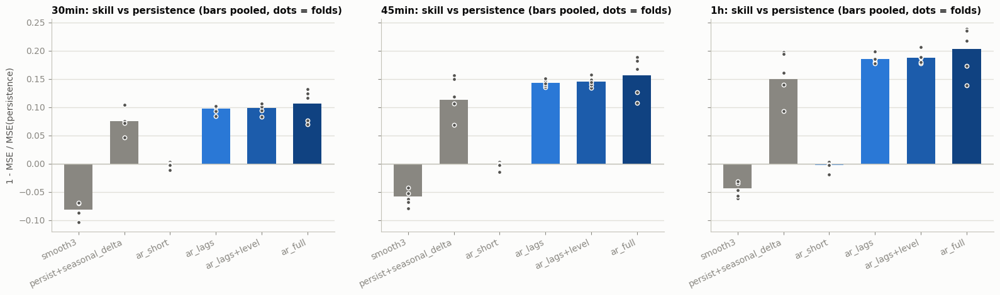

In [13]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()
assert dev.index.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
for sub in ("preds", "reports", "figs"): (RUN / sub).mkdir(exist_ok=True)

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False})

HZ = {"30min": 6, "45min": 9, "1h": 12}                       # horizons in 5-min steps
EMB = P.embargo_steps; EMBt = pd.Timedelta(minutes=5 * EMB)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy()   # log electron flux, NaN where missing
tod = np.asarray((dev.index.hour * 60 + dev.index.minute - 5) % 1440); th = 2 * np.pi * tod / 1440

# ------------------------------------------------ non-causal flags: used ONLY to choose which targets are scored/trained on
def electron_bad():
    cand = [c for c in dev.columns if any(s in c for s in ("outage", "spike"))]
    other = lambda c: ("proton" in c) or c.endswith(("_p", "_p_noncausal")) or ("_p_" in c)
    mine = [c for c in cand if not other(c)]
    bad = dev[mine].fillna(0).astype(bool).any(axis=1).to_numpy() if mine else np.zeros(len(dev), bool)
    s = pd.Series(y)
    if not any("spike" in c for c in mine):
        d1 = s.diff(); bad = bad | ((d1.abs() >= P.spike_log_jump) | (d1.shift(-1).abs() >= P.spike_log_jump)).to_numpy()
        print("WARNING: no electron spike flag found -> fallback |dlog| >= P.spike_log_jump")
    if not any("near" in c for c in mine):
        nan = s.isna(); run = nan.groupby((~nan).cumsum()).transform("sum")
        out = (nan & (run >= P.outage_min_steps)).astype(float)
        bad = bad | (out.rolling(2 * P.near_outage_steps + 1, center=True, min_periods=1).max() > 0).to_numpy()
        print("WARNING: no near-outage flag found -> fallback from NaN runs")
    print("flag columns used:", mine); return bad
bad = electron_bad()

# ------------------------------------------------ causal features (forward-filled level; everything uses data up to t only)
LAGS = [1, 2, 3, 6, 12, 24, 36, 72, 144, 216, 288]
def build_features(yv, H):
    s = pd.Series(yv); yf = s.ffill(); F = {}
    for L in LAGS: F[f"d{L}"] = (yf - yf.shift(L)).to_numpy()                       # y(t) - y(t-L)
    for K in (72, 288, 864): F[f"dev{K}"] = (yf - yf.rolling(K, min_periods=K // 2).mean()).to_numpy()
    for h in (1, 2): F[f"s{h}"] = np.sin(h * th); F[f"c{h}"] = np.cos(h * th)
    sd = np.vstack([(yf.shift(288 * k - H) - yf.shift(288 * k)).to_numpy() for k in (1, 2, 3)])
    F["sd1"] = sd[0]; F["sd3"] = np.nanmean(sd, axis=0)                              # same-phase change 1 day / 3-day mean
    F["sm3"] = yf.rolling(3).mean().to_numpy()                                       # smoothed-persistence baseline only
    return F

BLOCKS = {
    "ar_short": ["d1", "d2", "d3", "d6", "d12"],
    "ar_lags": [f"d{L}" for L in LAGS],
    "ar_lags+level": [f"d{L}" for L in LAGS] + ["dev72", "dev288", "dev864"],
    "ar_full": [f"d{L}" for L in LAGS] + ["dev72", "dev288", "dev864", "s1", "c1", "s2", "c2", "sd1", "sd3"],
}
def causal_test(H, cut=60000, seed=0):                    # replace everything after `cut` with noise; features at <= cut must not move
    y2 = y.copy(); y2[cut + 1:] = np.random.default_rng(seed).normal(0, 3, len(y) - cut - 1)
    A, B = build_features(y, H), build_features(y2, H)
    for k in A: assert np.allclose(A[k][:cut + 1], B[k][:cut + 1], equal_nan=True), f"feature {k} uses the future (H={H})"
for H in HZ.values(): causal_test(H)
print("causality test passed for all features and horizons")

# ------------------------------------------------ metrics and ridge with inner blocked CV
def metrics(yt, yp, y0):
    e = yt - yp; sse = (e ** 2).sum(); d = yt - y0; rt, rp = np.exp(yt), np.exp(yp)
    return dict(n=len(yt), mse_log=sse / len(yt), mae_log=np.abs(e).mean(),
                r2_log=1 - sse / ((yt - yt.mean()) ** 2).sum(), r2_delta=1 - sse / ((d - d.mean()) ** 2).sum(),
                r2_raw=1 - ((rt - rp) ** 2).sum() / ((rt - rt.mean()) ** 2).sum(),
                skill_vs_persist=1 - sse / (d ** 2).sum())

ALPHAS = np.logspace(-2, 4, 7)
def fit_ridge(X, yv, opos, H):
    mu, sd = X.mean(0), X.std(0) + 1e-12; Z = (X - mu) / sd
    edges = np.linspace(0, len(Z), 6).astype(int); score = {}
    for a in ALPHAS:
        sse = 0.0
        for b in range(1, 5):                              # forward chaining with an embargo gap before each validation block
            fit = (opos + H) <= (opos[edges[b]] - EMB)
            if fit.sum() < 500: continue
            v = slice(edges[b], edges[b + 1])
            sse += ((yv[v] - Ridge(alpha=a).fit(Z[fit], yv[fit]).predict(Z[v])) ** 2).sum()
        score[a] = sse
    a = min(score, key=score.get)
    return Ridge(alpha=a).fit(Z, yv), mu, sd, a

# ------------------------------------------------ run: 3 horizons x 5 folds x (3 baselines + 4 AR variants)
rows, store, coefs, alphas, SAVE, mine_pos = [], {}, {}, {}, {}, {}
for hn, H in HZ.items():
    F = build_features(y, H); n = len(y); i = np.arange(n - H); j = i + H
    cols = {k: F[k][i] for k in F}
    need = BLOCKS["ar_full"] + ["sm3"]
    ok = np.isfinite(y[i]) & np.isfinite(y[j]) & ~bad[j] & np.isfinite(np.column_stack([cols[c] for c in need])).all(axis=1)
    delta = y[j] - y[i]; tt = dev.index[j]; ot = dev.index[i]; sbin = tod[i] // 30
    for w in folds:
        tr = ok & ~bad[i] & np.asarray(tt <= w.val_start - EMBt)                    # train: TARGET time <= val_start - embargo
        va = ok & np.asarray((ot >= w.val_start) & (tt < w.val_end))                # val: origin >= val_start, target < val_end
        assert tt[tr].max() <= w.val_start - EMBt and ot[va].min() >= w.val_start
        y0, yt = y[i][va], y[j][va]
        if hn == "45min": mine_pos[w.name] = i[va]
        sdm = pd.Series(delta[tr]).groupby(sbin[tr]).mean()
        preds = {"persist": y0.copy(), "smooth3": cols["sm3"][va],
                 "persist+seasonal_delta": y0 + pd.Series(sbin[va]).map(sdm).fillna(0).to_numpy()}
        for name, cl in BLOCKS.items():
            X = np.column_stack([cols[c][tr] for c in cl]); Xv = np.column_stack([cols[c][va] for c in cl])
            mdl, mu, sd, a = fit_ridge(X, delta[tr], i[tr], H)
            preds[name] = y0 + mdl.predict((Xv - mu) / sd); alphas[(hn, w.name, name)] = a
            if w is folds[-1]: coefs[(hn, name)] = pd.Series(mdl.coef_, index=cl)
        SAVE[f"{hn}_{w.name}_pos"], SAVE[f"{hn}_{w.name}_y"], SAVE[f"{hn}_{w.name}_y0"] = i[va], yt, y0
        for name, p in preds.items():
            SAVE[f"{hn}_{w.name}_{name}"] = p
            rows.append(dict(H=hn, fold=w.name, model=name, alpha=alphas.get((hn, w.name, name), np.nan), **metrics(yt, p, y0)))
            store.setdefault((hn, name), []).append((yt, p, y0))
    print(f"done {hn}")

# ------------------------------------------------ reports
order = ["persist", "smooth3", "persist+seasonal_delta", *BLOCKS]
res = pd.DataFrame(rows); pooled = pd.DataFrame([dict(H=h, model=m, **metrics(*[np.concatenate(z) for z in zip(*v)]))
                                                 for (h, m), v in store.items()])
res["model"] = pd.Categorical(res["model"], order, ordered=True); res["H"] = pd.Categorical(res["H"], list(HZ), ordered=True)
pd.set_option("display.width", 220); pd.set_option("display.float_format", "{:.4f}".format)
for col in ("skill_vs_persist", "r2_delta", "r2_log", "r2_raw", "mse_log"):
    print(f"\n{col} (pooled over the 5 folds)"); print(pooled.pivot(index="model", columns="H", values=col).reindex(order)[list(HZ)])
print("\nskill_vs_persist per fold"); print(res.pivot_table(index=["H", "model"], columns="fold", values="skill_vs_persist", observed=True))
for (hn, name), s in coefs.items():
    if name == "ar_full":
        print(f"\n{hn}: ar_full coefficients on standardised features (cv5 fit), largest |coef| first")
        print(s.reindex(s.abs().sort_values(ascending=False).index).head(10))

# ------------------------------------------------ sanity: does this reproduce the earlier 45-min split and baseline?
print("\nmean-over-folds persistence mse_log at 45min:", round(res[(res.H == "45min") & (res.model == "persist")]["mse_log"].mean(), 3), "(earlier run: 0.144)")
for w in folds:
    try:
        sp = runio.load_split(w.name, "45min"); vs = np.asarray(sp["val_scored"] if isinstance(sp, dict) else sp[2])
        a, b = set(vs.tolist()), set(mine_pos[w.name].tolist())
        print(w.name, "saved val_scored", len(a), "| mine", len(b), "| Jaccard", round(len(a & b) / max(len(a | b), 1), 4))
    except Exception as e:
        print("could not compare with the saved split:", type(e).__name__, e); break

res.to_csv(RUN / "reports" / "ar_short_horizons_per_fold.csv", index=False); pooled.to_csv(RUN / "reports" / "ar_short_horizons_pooled.csv", index=False)
pd.concat(coefs, axis=1).to_csv(RUN / "reports" / "ar_short_horizons_coefs.csv")
np.savez_compressed(RUN / "preds" / "ar_short_horizons.npz", **SAVE)

def fig_skill():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
    colr = {"smooth3": MUTED, "persist+seasonal_delta": MUTED, **dict(zip(BLOCKS, RAMP[1:]))}
    for ax, hn in zip(axes, HZ):
        for xi, m in enumerate(order[1:]):
            r = res[(res.H == hn) & (res.model == m)]; pv = pooled[(pooled.H == hn) & (pooled.model == m)]["skill_vs_persist"].iloc[0]
            ax.bar(xi, pv, 0.62, color=colr[m]); ax.plot(np.full(len(r), xi), r["skill_vs_persist"], "o", ms=4.5, color=INK2, mec=SURF, mew=1.1, zorder=3)
        ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(range(len(order) - 1)); ax.set_xticklabels(order[1:], rotation=25, ha="right")
        ax.set_title(f"{hn}: skill vs persistence (bars pooled, dots = folds)")
    axes[0].set_ylabel("1 - MSE / MSE(persistence)")
    fig.tight_layout(); fig.savefig(RUN / "figs" / "ar_short_horizons_skill.png", dpi=150, bbox_inches="tight"); plt.show()
fig_skill()

👀 **How to read this output**

*$R^2_\Delta$ pooled over five folds (from the next cell's table, same numbers):*

| Model | 30 min | 45 min | 1 h |
|---|---|---|---|
| persistence | 0 | 0 | 0 |
| `smooth3` | **−0.081** | −0.058 | −0.044 |
| `persist+seasonal_delta` | 0.075 | 0.113 | 0.150 |
| `ar_short` | −0.0015 | −0.0019 | −0.0029 |
| `ar_lags` | 0.098 | 0.143 | 0.185 |
| `ar_lags+level` | 0.099 | 0.145 | 0.188 |
| **`ar_full`** | **0.107** | **0.157** | **0.203** |

* **Very recent lags carry no information.** `ar_short` is indistinguishable from persistence (−0.002). Everything the AR gains comes from the **previous day**.
* `smooth3` is worse than persistence: smoothing throws away the most recent value.
* Adding the deviation-from-mean block gives +0.001–0.003; adding the **time-of-day and same-phase terms** gives the largest extra step (+0.008 at 30 min, +0.012 at 45 min, +0.015 at 1 h).
* **Largest standardised coefficients** (cv5 fit): `c1` (+0.071 / +0.104 / +0.134, rising with horizon), then `d216` (−0.048 / −0.068 / −0.086), `d24`, `dev288`, `s1`. The cosine term of the daily cycle is the single most important input, and its weight grows with the horizon, matching the signed 1-day autocorrelation of 3.4.
* `d216` and `dev288` have **negative** signs: after a large rise relative to 18 h ago or to the 1-day average, the model expects some give-back, which is mean reversion.
* The per-fold table shows `ar_full` is not uniformly best: in cv2 and cv3 it is below `ar_lags` (e.g. 30 min cv3: 0.069 vs 0.093). The extra terms lift the pooled score mainly through cv1, cv4, cv5.

## 6.4 Pooled read-out of the AR variants

📘 **What.** Re-reads the saved predictions of cell 24 and recomputes, **pooled over the five folds**, three views of every model: $R^2_{\log}$ (level), the *unexplained share of the level* $1-R^2_{\log}$, and $R^2_\Delta$ (change).

🎯 **Why.** To show side by side how a model that changes the unexplained level share by only 1–2 percentage points can still explain 10–20 % of the change.

In [14]:
import sys
import numpy as np, pandas as pd
sys.path.insert(0, "/kaggle/working/final_run")
from core import make_folds
from runio import RUN

Z = np.load(RUN / "preds" / "ar_short_horizons.npz")
HZ = ["30min", "45min", "1h"]
MODELS = ["persist", "smooth3", "persist+seasonal_delta", "ar_short", "ar_lags", "ar_lags+level", "ar_full"]
folds = [w.name for w in make_folds()]

def r2s(yt, p, y0):
    sse = ((yt - p) ** 2).sum(); d = yt - y0                       # d = the actual change over the horizon
    sst_level = ((yt - yt.mean()) ** 2).sum()
    return dict(r2_level=1 - sse / sst_level,
                unexplained_level=sse / sst_level,
                r2_change=1 - sse / ((d - d.mean()) ** 2).sum(),
                skill_vs_persist=1 - sse / (d ** 2).sum())

pooled, per_fold = [], []
for hn in HZ:
    for m in MODELS:
        parts = [(Z[f"{hn}_{f}_y"], Z[f"{hn}_{f}_{m}"], Z[f"{hn}_{f}_y0"]) for f in folds]
        pooled.append(dict(H=hn, model=m, **r2s(*[np.concatenate(z) for z in zip(*parts)])))
        for f, (yt, p, y0) in zip(folds, parts): per_fold.append(dict(H=hn, model=m, fold=f, **r2s(yt, p, y0)))
pooled, per_fold = pd.DataFrame(pooled), pd.DataFrame(per_fold)

pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:.4f}".format)
for col in ("r2_level", "unexplained_level", "r2_change"):
    print(f"\n{col} (pooled over the 5 folds)")
    print(pooled.pivot(index="model", columns="H", values=col).reindex(MODELS)[HZ])
print("\nr2_change per fold")
pf = per_fold.pivot_table(index=["H", "model"], columns="fold", values="r2_change", sort=False)
print(pf.reindex(pd.MultiIndex.from_product([HZ, MODELS])))


r2_level (pooled over the 5 folds)
H                       30min  45min     1h
model                                      
persist                0.9670 0.9505 0.9335
smooth3                0.9644 0.9476 0.9306
persist+seasonal_delta 0.9695 0.9561 0.9435
ar_short               0.9670 0.9504 0.9333
ar_lags                0.9703 0.9576 0.9458
ar_lags+level          0.9703 0.9577 0.9460
ar_full                0.9706 0.9582 0.9470

unexplained_level (pooled over the 5 folds)
H                       30min  45min     1h
model                                      
persist                0.0330 0.0495 0.0665
smooth3                0.0356 0.0524 0.0694
persist+seasonal_delta 0.0305 0.0439 0.0565
ar_short               0.0330 0.0496 0.0667
ar_lags                0.0297 0.0424 0.0542
ar_lags+level          0.0297 0.0423 0.0540
ar_full                0.0294 0.0418 0.0530

r2_change (pooled over the 5 folds)
H                        30min   45min      1h
model                                      

👀 **How to read this output**

| 45 min | $R^2_{\log}$ | unexplained level | $R^2_\Delta$ |
|---|---|---|---|
| persistence | 0.9505 | 0.0495 | 0.000 |
| `persist+seasonal_delta` | 0.9561 | 0.0439 | 0.113 |
| `ar_lags` | 0.9576 | 0.0424 | 0.143 |
| `ar_full` | **0.9582** | **0.0418** | **0.157** |

Going from persistence to `ar_full` takes the **unexplained level share from 4.95 % to 4.18 %** (a 15.6 % relative cut, exactly the 0.157 of $R^2_\Delta$), but looks like a rise from 0.9505 to 0.9582 on the level metric. The first notebook's 0.93 sat *below* this trivial baseline.

The per-fold table shows that the ranking `ar_full` > `ar_lags` > baseline holds in cv1, cv4, cv5, while cv2 and cv3 are the weak folds for the richer model (e.g. 1 h: `ar_full` 0.173 / 0.139 vs `ar_lags` 0.180 / 0.178).

## 6.5 `ar_final`: the frozen AR model, tested properly

📘 **What.** The final AR specification is **11 lags + 4 time-of-day terms** (15 inputs; no deviation block, no same-phase block):
$$\hat\Delta_t^{H}=b+\sum_{L\in\mathcal L}\beta_L\,\tilde d_L(t)+\beta_{s1}\tilde s_1+\beta_{c1}\tilde c_1+\beta_{s2}\tilde s_2+\beta_{c2}\tilde c_2,\qquad \mathcal L=\{1,2,3,6,12,24,36,72,144,216,288\}$$
(tilde = standardised on the training rows). It is fitted for every fold and horizon with $\alpha$ chosen by the blocked forward-chaining search of 6.1. In the notebook the model is also compared with the seasonal baseline
$$\hat y^{\text{seas}}_{t+H}=y_t+\bar\Delta_{b(t)},\qquad \bar\Delta_{b}=\text{mean of }\Delta\text{ over training rows whose origin falls in the 30-min bin }b .$$

The cell then runs **four layers of evidence** on the predictions:

1. **Skill and $R^2$**, pooled and per fold (vs persistence and vs the seasonal baseline).
2. **Diebold–Mariano tests** on squared log errors with HAC bandwidth of one day (288 lags):
$$d_t=\big(e_t^{\text{base}}\big)^2-\big(e_t^{\text{AR}}\big)^2,\qquad \text{DM}=\frac{\bar d}{\sqrt{\widehat{\text{LRV}}(d)/T}}\ \ (\text{positive = AR better}).$$
3. **Day-block bootstrap** of the skill (2,000 resamples of whole days, so the strong autocorrelation within a day is kept intact):
$$\text{skill}^{*}=1-\frac{\sum_{\text{days }b^*}\text{SSE}^{\text{AR}}}{\sum_{\text{days }b^*}\text{SSE}^{\text{base}}},\qquad \text{report the 2.5th and 97.5th percentiles.}$$
4. **Residual diagnostics**: bias, skew, excess kurtosis, the share of errors beyond 3 RMSE, the residual ACF to lag 300, and **error size by recent-volatility quintile** (volatility = rolling sd of one-step changes over the last hour, used only to slice the errors).

fitted 30min
fitted 45min
fitted 1h

AR final, pooled over the 5 folds
           n  r2_log  r2_delta  r2_raw  skill_vs_persist  skill_vs_seasonal  mse_log
H                                                                                   
30min  68870  0.9705    0.1060  0.9661            0.1060             0.0336   0.0856
45min  68852  0.9581    0.1547  0.9497            0.1547             0.0470   0.1216
1h     68836  0.9468    0.1997  0.9343            0.1997             0.0585   0.1546

per fold
      skill_vs_persist                             skill_vs_seasonal                             
fold               cv1    cv2    cv3    cv4    cv5               cv1     cv2    cv3    cv4    cv5
H                                                                                                
30min           0.1307 0.0778 0.0702 0.1166 0.1190            0.0601 -0.0294 0.0254 0.0486 0.0168
45min           0.1848 0.1289 0.1073 0.1666 0.1730            0.0752 -0.0323 0.0420 0.0671 0.0279
1h  

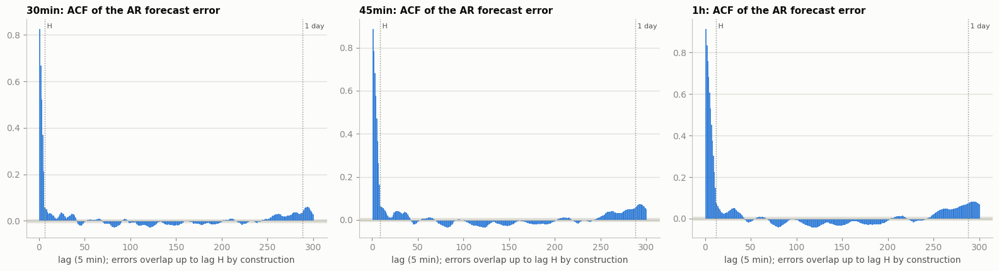

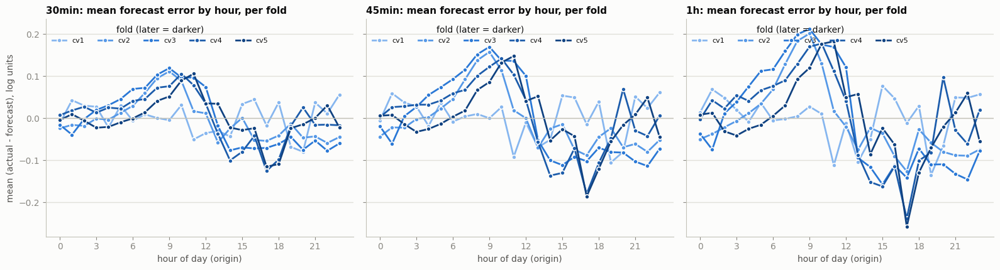

In [18]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import Ridge
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

# ------------------------------------------------ setup (dev period only)
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()
assert dev.index.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
for sub in ("preds", "reports", "figs"): (RUN / sub).mkdir(exist_ok=True)
SURF, INK, INK2, MUTED, GRID, AXIS, BLUE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#2a78d6"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False})

HZ = {"30min": 6, "45min": 9, "1h": 12}
EMB = P.embargo_steps; EMBt = pd.Timedelta(minutes=5 * EMB); ALPHAS = np.logspace(-2, 4, 7)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy()
tod = np.asarray((dev.index.hour * 60 + dev.index.minute - 5) % 1440); th = 2 * np.pi * tod / 1440
BAD = ["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]
bad = dev[BAD].fillna(0).astype(bool).any(axis=1).to_numpy()          # non-causal flags: choose trained/scored targets only

def metrics(yt, yp, y0):
    e = yt - yp; sse = (e ** 2).sum(); d = yt - y0; rt, rp = np.exp(yt), np.exp(yp)
    return dict(n=len(yt), mse_log=sse / len(yt), mae_log=np.abs(e).mean(),
                r2_log=1 - sse / ((yt - yt.mean()) ** 2).sum(), r2_delta=1 - sse / ((d - d.mean()) ** 2).sum(),
                r2_raw=1 - ((rt - rp) ** 2).sum() / ((rt - rt.mean()) ** 2).sum(), skill_vs_persist=1 - sse / (d ** 2).sum())

def ridge_cv(Z, yv, opos, H):                                          # forward chaining with embargo; (mean MSE, alpha, block MSEs)
    edges = np.linspace(0, len(Z), 6).astype(int); best = (np.inf, None, None)
    for a in ALPHAS:
        mse = []
        for b in range(1, 5):
            fit = (opos + H) <= (opos[edges[b]] - EMB)
            if fit.sum() < 500: continue
            v = slice(edges[b], edges[b + 1])
            mse.append(((yv[v] - Ridge(alpha=a).fit(Z[fit], yv[fit]).predict(Z[v])) ** 2).mean())
        if mse and np.mean(mse) < best[0]: best = (np.mean(mse), a, np.array(mse))
    return best

# ------------------------------------------------ final AR spec: 11 lags (reach 1 day) + time-of-day terms
LAGS = [1, 2, 3, 6, 12, 24, 36, 72, 144, 216, 288]
def build_X(yv):
    f = pd.Series(yv).ffill()
    return np.column_stack([(f - f.shift(L)).to_numpy() for L in LAGS] + [np.sin(th), np.cos(th), np.sin(2 * th), np.cos(2 * th)])
y2 = y.copy(); y2[60001:] = np.random.default_rng(0).normal(0, 3, len(y) - 60001)
assert np.allclose(build_X(y)[:60001], build_X(y2)[:60001], equal_nan=True), "features use the future"
XALL = build_X(y)
vol12 = pd.Series(y).ffill().diff().rolling(12).std().to_numpy()         # recent volatility at the origin, only used to slice errors

# ------------------------------------------------ fit every fold, keep predictions
store, SAVE, perfold = {}, {}, []
for hn, H in HZ.items():
    n = len(y); i = np.arange(n - H); j = i + H; X = XALL[i]
    ok = np.isfinite(y[i]) & np.isfinite(y[j]) & ~bad[j] & np.isfinite(X).all(axis=1)
    delta = y[j] - y[i]; tt, ot = dev.index[j], dev.index[i]; sbin = tod[i] // 30
    for w in folds:
        tr = ok & ~bad[i] & np.asarray(tt <= w.val_start - EMBt)                    # train: TARGET time <= val_start - embargo
        va = ok & np.asarray((ot >= w.val_start) & (tt < w.val_end))
        assert tt[tr].max() <= w.val_start - EMBt and ot[va].min() >= w.val_start
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-12; Z = (X[tr] - mu) / sd
        _, a, _ = ridge_cv(Z, delta[tr], i[tr], H); y0, yt = y[i][va], y[j][va]
        p_ar = y0 + Ridge(alpha=a).fit(Z, delta[tr]).predict((X[va] - mu) / sd)
        p_se = y0 + pd.Series(sbin[va]).map(pd.Series(delta[tr]).groupby(sbin[tr]).mean()).fillna(0).to_numpy()
        store.setdefault(hn, {})[w.name] = dict(pos=i[va], yt=yt, y0=y0, ar=p_ar, seas=p_se, persist=y0, ot=ot[va], vol=vol12[i][va])
        for k in ("pos", "yt", "y0", "ar", "seas"): SAVE[f"{hn}_{w.name}_{k}"] = store[hn][w.name][k]
        for nm, p in (("persist", y0), ("seasonal_delta", p_se), ("ar_final", p_ar)):
            perfold.append(dict(H=hn, fold=w.name, model=nm, alpha=a if nm == "ar_final" else np.nan, **metrics(yt, p, y0)))
    print("fitted", hn)
np.savez_compressed(RUN / "preds" / "ar_final.npz", **SAVE)
cat = lambda hn, k: np.concatenate([store[hn][f][k] for f in store[hn]])
pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:.4f}".format)

# ------------------------------------------------ 1. skill and R2
pf = pd.DataFrame(perfold); rows = []
for hn in HZ:
    yt, y0, ar, se = (cat(hn, k) for k in ("yt", "y0", "ar", "seas"))
    rows.append(dict(H=hn, **metrics(yt, ar, y0), skill_vs_seasonal=1 - ((yt - ar) ** 2).sum() / ((yt - se) ** 2).sum()))
pooled = pd.DataFrame(rows).set_index("H")
print("\nAR final, pooled over the 5 folds"); print(pooled[["n", "r2_log", "r2_delta", "r2_raw", "skill_vs_persist", "skill_vs_seasonal", "mse_log"]])
fs = [dict(H=hn, fold=f, skill_vs_persist=metrics(r["yt"], r["ar"], r["y0"])["skill_vs_persist"],
           skill_vs_seasonal=1 - ((r["yt"] - r["ar"]) ** 2).sum() / ((r["yt"] - r["seas"]) ** 2).sum()) for hn in HZ for f, r in store[hn].items()]
print("\nper fold"); print(pd.DataFrame(fs).pivot(index="H", columns="fold", values=["skill_vs_persist", "skill_vs_seasonal"]).loc[list(HZ)])

# ------------------------------------------------ 2. Diebold-Mariano (squared log error, HAC bandwidth = 1 day)
def dm(lb, lm, L=288):
    d = lb - lm; r = sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": L})
    return d.mean(), float(r.tvalues[0]), float(r.pvalues[0])
dm_rows = []
for hn in HZ:
    for base in ("persist", "seas"):
        for scope in ["pooled", *store[hn]]:
            g_ = (lambda k: cat(hn, k)) if scope == "pooled" else (lambda k, s=scope: store[hn][s][k])
            m_, t_, p_ = dm((g_("yt") - g_(base)) ** 2, (g_("yt") - g_("ar")) ** 2)
            dm_rows.append(dict(H=hn, vs=base, scope=scope, mean_loss_gain=m_, t=t_, p=p_))
dmd = pd.DataFrame(dm_rows)
print("\nDiebold-Mariano t (positive = AR better; |t| > 2 is significant)")
print(dmd.pivot_table(index=["H", "vs"], columns="scope", values="t", sort=False)[["pooled", *[f.name for f in folds]]])

# ------------------------------------------------ 3. day-block bootstrap of the skill
def day_boot(hn, base, B=2000, seed=0):
    parts = [pd.DataFrame({"day": r["ot"].normalize(), "a": (r["yt"] - r["ar"]) ** 2, "b": (r["yt"] - r[base]) ** 2}).groupby("day").sum()
             for r in store[hn].values()]
    d = pd.concat(parts); a, b = d["a"].to_numpy(), d["b"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(d), size=(B, len(d)))
    return 1 - a.sum() / b.sum(), *np.percentile(1 - a[idx].sum(1) / b[idx].sum(1), [2.5, 97.5])
bt = pd.DataFrame([dict(H=hn, vs=base, skill=s, lo95=lo, hi95=hi) for hn in HZ for base in ("persist", "seas")
                   for s, lo, hi in [day_boot(hn, base)]]).set_index(["H", "vs"])
print("\nskill with 95% day-block bootstrap interval"); print(bt)

# ------------------------------------------------ 4. residual diagnostics
ERR = {}
for hn in HZ:
    e = np.full(len(y), np.nan)
    for r in store[hn].values(): e[r["pos"]] = r["yt"] - r["ar"]
    c = e - np.nanmean(e); v = np.nanmean(c ** 2)
    ERR[hn] = (np.array([np.nanmean(c[k:] * c[:-k]) for k in range(1, 301)]) / v, int(np.isfinite(e).sum()))
rr = []
for hn in HZ:
    for scope in ["pooled", *store[hn]]:
        e = (cat(hn, "yt") - cat(hn, "ar")) if scope == "pooled" else (store[hn][scope]["yt"] - store[hn][scope]["ar"])
        rr.append(dict(H=hn, scope=scope, n=len(e), bias=e.mean(), rmse=np.sqrt((e ** 2).mean()), skew=pd.Series(e).skew(),
                       excess_kurtosis=pd.Series(e).kurt(), share_beyond_3rmse=(np.abs(e) > 3 * np.sqrt((e ** 2).mean())).mean()))
print("\nerror summary (actual - forecast, log units)"); print(pd.DataFrame(rr).set_index(["H", "scope"]))
vq = []
for hn in HZ:
    vol, yt, y0, ar = cat(hn, "vol"), cat(hn, "yt"), cat(hn, "y0"), cat(hn, "ar"); m = np.isfinite(vol)
    q = pd.qcut(vol[m], 5, labels=[1, 2, 3, 4, 5])
    gq = pd.DataFrame({"q": q, "a": (yt[m] - ar[m]) ** 2, "b": (yt[m] - y0[m]) ** 2}).groupby("q", observed=True).mean()
    vq += [dict(H=hn, vol_quintile=int(k), rmse_ar=np.sqrt(r_.a), rmse_persist=np.sqrt(r_.b), skill=1 - r_.a / r_.b) for k, r_ in gq.iterrows()]
vq = pd.DataFrame(vq); print("\nerror size by recent volatility (quintile 5 = most volatile)")
print(vq.pivot(index="vol_quintile", columns="H", values=["rmse_ar", "skill"])[[("rmse_ar", h) for h in HZ] + [("skill", h) for h in HZ]])

pf.to_csv(RUN / "reports" / "ar_final_per_fold.csv", index=False); pooled.to_csv(RUN / "reports" / "ar_final_pooled.csv")
dmd.to_csv(RUN / "reports" / "ar_final_dm.csv", index=False); bt.to_csv(RUN / "reports" / "ar_final_bootstrap.csv")
pd.DataFrame(rr).to_csv(RUN / "reports" / "ar_final_residuals.csv", index=False); vq.to_csv(RUN / "reports" / "ar_final_by_vol.csv", index=False)

# ------------------------------------------------ figures
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, hn in zip(axes, HZ):
    r, N = ERR[hn]; lg = np.arange(1, 301); b = 1.96 / np.sqrt(N)
    ax.axhspan(-b, b, color=GRID, zorder=0); ax.vlines(lg, 0, r, color=BLUE, lw=1.2); ax.axhline(0, color=AXIS, lw=1)
    for x, t in ((HZ[hn], "H"), (288, "1 day")):
        ax.axvline(x, color=MUTED, lw=1, ls=":"); ax.text(x, 0.98, " " + t, transform=ax.get_xaxis_transform(), fontsize=8, color=INK2, va="top")
    ax.set_title(f"{hn}: ACF of the AR forecast error"); ax.set_xlabel("lag (5 min); errors overlap up to lag H by construction")
fig.tight_layout(); fig.savefig(RUN / "figs" / "ar_final_error_acf.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, hn in zip(axes, HZ):
    for (f, r), c in zip(store[hn].items(), RAMP):
        hb = tod[r["pos"]] // 60; e = pd.Series(r["yt"] - r["ar"]).groupby(hb).mean()
        ax.plot(e.index, e.to_numpy(), color=c, lw=2, marker="o", ms=5, mec=SURF, mew=1.2, label=f)
    ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hour of day (origin)")
    ax.set_title(f"{hn}: mean forecast error by hour, per fold"); ax.legend(title="fold (later = darker)", ncol=5, loc="upper left", fontsize=8)
axes[0].set_ylabel("mean (actual - forecast), log units")
fig.tight_layout(); fig.savefig(RUN / "figs" / "ar_final_bias_by_hour.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output**

**1. Skill (pooled).**

| | 30 min | 45 min | 1 h |
|---|---|---|---|
| $R^2_{\log}$ | 0.9705 | 0.9581 | 0.9468 |
| **$R^2_\Delta$ = skill vs persistence** | **0.1060** | **0.1547** | **0.1997** |
| skill vs seasonal baseline | 0.0336 | 0.0470 | 0.0585 |
| MSE of log flux | 0.0856 | 0.1216 | 0.1546 |

Per fold the skill vs persistence is 0.131 / 0.078 / 0.070 / 0.117 / 0.119 at 30 min (cv1…cv5): **positive in every fold**, weakest in cv3 and cv2.
Skill vs the seasonal baseline is positive in four folds and **negative in cv2** (−0.029 / −0.032 / −0.032).

**2. Diebold–Mariano $t$** (positive = AR better):

| vs | pooled 30 / 45 / 1 h | cv2 |
|---|---|---|
| persistence | **10.2 / 11.3 / 12.0** | 3.6 / 4.2 / 4.5 |
| seasonal baseline | **3.7 / 4.1 / 4.3** | **−2.1 / −1.8 / −1.5** |

Against persistence the AR is significant in every fold. Against the seasonal baseline it is significant pooled, **not significant in cv5 (0.95 / 1.31 / 1.52)** nor in cv3 at 30 min (1.93), and *worse in cv2*. This is an honest limit: a good part of the AR's skill is the daily pattern that the seasonal baseline already has.

**3. Bootstrap 95 % intervals** exclude zero everywhere: skill vs persistence 0.106 [0.094, 0.118] · 0.155 [0.140, 0.170] · 0.200 [0.181, 0.219]; skill vs seasonal 0.034 [0.019, 0.049] · 0.047 [0.029, 0.065] · 0.059 [0.038, 0.079].

**4. Residuals.** Bias is essentially zero (−0.0003 / −0.0002 / 0.0000). RMSE is 0.293 / 0.349 / 0.393 in log units. Excess kurtosis is **28.0 / 19.0 / 14.5**: errors are very heavy-tailed, with about 2 % of them beyond 3 RMSE (a Gaussian would give 0.27 %). Skew is positive (+0.48) pooled but **flips sign by fold** (cv2 −1.27, cv4 +1.51), which again reflects the very different character of the folds.

**Error by volatility.** In the calmest quintile the RMSE is 0.14 (30 min) and the model beats persistence by 18 % (skill 0.185); in the most volatile quintile the RMSE is **0.51** and the skill is 0.098. The model helps everywhere, most in calm conditions, but the *size* of the error is overwhelmingly a function of volatility. This is the empirical motivation for the variance track (Part 8).

## 6.6 Master performance table (AR family)

📘 **What.** Merges the AR-variant results with `ar_final`, adds *skill vs the seasonal baseline* computed from MSE,
$$\text{skill}_{\text{seas}}=1-\frac{\text{MSE}_{\text{model}}}{\text{MSE}_{\text{persist+seasonal}}},$$
prints six metric tables (change $R^2$, level $R^2$, raw-flux $R^2$, MSE, MAE, skill vs seasonal) and saves `master_performance_short_horizons.csv`. It also prints the earlier 45 min / 6 h / 12 h tables for reference.

In [19]:
import sys
import numpy as np, pandas as pd
sys.path.insert(0, "/kaggle/working/final_run")
from runio import RUN
R = RUN / "reports"

a = pd.read_csv(R / "ar_short_horizons_pooled.csv")                        # 7 models x 3 short horizons
f = pd.read_csv(R / "ar_final_pooled.csv").assign(model="ar_final")        # final spec
cols = ["H", "model", "n", "r2_delta", "r2_log", "r2_raw", "mse_log", "mae_log", "skill_vs_persist"]
m = pd.concat([a[cols], f[cols]], ignore_index=True)
ms = m[m.model == "persist+seasonal_delta"].set_index("H")["mse_log"]
m["skill_vs_seasonal"] = 1 - m["mse_log"] / m["H"].map(ms)

order = ["persist", "smooth3", "persist+seasonal_delta", "ar_short", "ar_lags", "ar_lags+level", "ar_full", "ar_final"]
hz = ["30min", "45min", "1h"]
pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:.4f}".format)
for c in ("r2_delta", "r2_log", "r2_raw", "mse_log", "mae_log", "skill_vs_seasonal"):
    print(f"\n{c}"); print(m.pivot(index="model", columns="H", values=c).reindex(order)[hz])
m.to_csv(R / "master_performance_short_horizons.csv", index=False)

for name in ("baselines_pooled.csv", "linear_pooled.csv"):                 # your earlier 45 min / 6 h / 12 h tables, as saved
    print("\n", name); print(pd.read_csv(R / name).round(4).to_string(index=False))


r2_delta
H                        30min   45min      1h
model                                         
persist                -0.0000 -0.0000 -0.0000
smooth3                -0.0813 -0.0583 -0.0438
persist+seasonal_delta  0.0749  0.1130  0.1500
ar_short               -0.0015 -0.0019 -0.0029
ar_lags                 0.0978  0.1431  0.1850
ar_lags+level           0.0991  0.1452  0.1879
ar_full                 0.1070  0.1568  0.2030
ar_final                0.1060  0.1547  0.1997

r2_log
H                       30min  45min     1h
model                                      
persist                0.9670 0.9505 0.9335
smooth3                0.9644 0.9476 0.9306
persist+seasonal_delta 0.9695 0.9561 0.9435
ar_short               0.9670 0.9504 0.9333
ar_lags                0.9703 0.9576 0.9458
ar_lags+level          0.9703 0.9577 0.9460
ar_full                0.9706 0.9582 0.9470
ar_final               0.9705 0.9581 0.9468

r2_raw
H                       30min  45min     1h
model               

👀 **How to read this output**

* `ar_final` ($R^2_\Delta$ 0.1060 / 0.1547 / 0.1997) is within 0.001–0.003 of `ar_full` (0.1070 / 0.1568 / 0.2030) with **fewer inputs**: the deviation block and the same-phase terms were not needed.
* On **raw flux** ($R^2_{\text{raw}}$, no logs) `ar_final` scores 0.966 / 0.950 / 0.934 against persistence 0.961 / 0.939 / 0.915: the gain is larger at longer horizons.
* On **MAE** `ar_lags` (0.1662 / 0.2046 / 0.2368) is slightly better than `ar_final` (0.1690 / 0.2091 / 0.2430). Ridge minimises squared error, so it chases big moves; on a typical 5-min origin the plain lag model is a little closer. Which metric matters depends on the use: squared error (rare big storms matter) or absolute error (typical accuracy).

## 6.7 Placebo test for the AR model: is the skill really coming from recent history?

📘 **What.** A permutation-style test. For each fold and horizon the **block of lag features is shuffled among days at the same time of day** (both in the training and in the validation rows), the AR is refitted and scored, and this is repeated $B=30$ times. The time-of-day terms are left intact.

🎯 **Why.** The seasonal baseline already knows the clock. The question is whether the AR's *extra* skill really comes from the **recent past** and not from some artefact. Shuffling the lags among days with the same clock time keeps every marginal distribution and the time-of-day structure but destroys the link between yesterday's / the last hours' behaviour and the target. If the real skill were an artefact, the placebo would reproduce it.

📐 **p-value** (with the real fit counted as one of the draws):
$$p=\frac{1+\#\{b:\ \text{skill}^{\text{placebo}}_b\ge\text{skill}^{\text{real}}\}}{B+1},\qquad \text{floor }=\tfrac1{31}=0.0323 .$$

In [20]:
import sys, warnings
import numpy as np, pandas as pd
from sklearn.linear_model import Ridge
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()
assert dev.index.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
HZ = {"30min": 6, "45min": 9, "1h": 12}; EMB = P.embargo_steps; EMBt = pd.Timedelta(minutes=5 * EMB); ALPHAS = np.logspace(-2, 4, 7)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy()
tod = np.asarray((dev.index.hour * 60 + dev.index.minute - 5) % 1440); th = 2 * np.pi * tod / 1440
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy()
LAGS = [1, 2, 3, 6, 12, 24, 36, 72, 144, 216, 288]; NL = len(LAGS)
yf = pd.Series(y).ffill()
XALL = np.column_stack([(yf - yf.shift(L)).to_numpy() for L in LAGS] + [np.sin(th), np.cos(th), np.sin(2 * th), np.cos(2 * th)])

def ridge_cv(Z, yv, opos, H):
    edges = np.linspace(0, len(Z), 6).astype(int); best = (np.inf, None)
    for a in ALPHAS:
        mse = []
        for b in range(1, 5):
            fit = (opos + H) <= (opos[edges[b]] - EMB)
            if fit.sum() < 500: continue
            v = slice(edges[b], edges[b + 1]); mse.append(((yv[v] - Ridge(alpha=a).fit(Z[fit], yv[fit]).predict(Z[v])) ** 2).mean())
        if mse and np.mean(mse) < best[0]: best = (np.mean(mse), a)
    return best[1]

B = 30; rng = np.random.default_rng(0); out = []
for hn, H in HZ.items():
    n = len(y); i = np.arange(n - H); j = i + H; X = XALL[i]
    ok = np.isfinite(y[i]) & np.isfinite(y[j]) & ~bad[j] & np.isfinite(X).all(axis=1)
    delta = y[j] - y[i]; tt, ot = dev.index[j], dev.index[i]; sbin = tod[i] // 30
    sse_real = sse_seas = 0.0; sse_null = np.zeros(B)
    for w in folds:
        tr = ok & ~bad[i] & np.asarray(tt <= w.val_start - EMBt)
        va = ok & np.asarray((ot >= w.val_start) & (tt < w.val_end))
        Xt, Xv = X[tr], X[va]; mu, sd = Xt.mean(0), Xt.std(0) + 1e-12; Zt, Zv = (Xt - mu) / sd, (Xv - mu) / sd
        a = ridge_cv(Zt, delta[tr], i[tr], H); y0, yt = y[i][va], y[j][va]
        sse_real += ((yt - (y0 + Ridge(alpha=a).fit(Zt, delta[tr]).predict(Zv))) ** 2).sum()
        p_se = y0 + pd.Series(sbin[va]).map(pd.Series(delta[tr]).groupby(sbin[tr]).mean()).fillna(0).to_numpy()
        sse_seas += ((yt - p_se) ** 2).sum()
        g_tr = [np.flatnonzero(tod[i][tr] // 5 == s) for s in range(288)]; g_va = [np.flatnonzero(tod[i][va] // 5 == s) for s in range(288)]
        for b in range(B):                                    # shuffle the lag block among days at the same time of day
            Zt_b, Zv_b = Zt.copy(), Zv.copy()
            for G, Zb, Zo in ((g_tr, Zt_b, Zt), (g_va, Zv_b, Zv)):
                for idx in G:
                    if len(idx) > 1: Zb[idx, :NL] = Zo[rng.permutation(idx), :NL]
            sse_null[b] += ((yt - (y0 + Ridge(alpha=a).fit(Zt_b, delta[tr]).predict(Zv_b))) ** 2).sum()
    real, null = 1 - sse_real / sse_seas, 1 - sse_null / sse_seas
    out.append(dict(H=hn, real_skill_vs_seasonal=real, placebo_mean=null.mean(), placebo_p95=np.percentile(null, 95),
                    placebo_max=null.max(), p_value=(1 + (null >= real).sum()) / (B + 1)))
    print("done", hn)
res = pd.DataFrame(out).set_index("H"); pd.set_option("display.float_format", "{:.4f}".format); print(res)
res.to_csv(RUN / "reports" / "ar_placebo_test.csv")

done 30min
done 45min
done 1h
       real_skill_vs_seasonal  placebo_mean  placebo_p95  placebo_max  p_value
H                                                                             
30min                  0.0336        0.0031       0.0038       0.0039   0.0323
45min                  0.0470        0.0038       0.0044       0.0045   0.0323
1h                     0.0585        0.0044       0.0054       0.0060   0.0323


👀 **How to read this output**

| Horizon | real skill vs seasonal | placebo mean | placebo 95th pct | placebo max | $p$ |
|---|---|---|---|---|---|
| 30 min | **0.0336** | 0.0031 | 0.0038 | 0.0039 | 0.0323 |
| 45 min | **0.0470** | 0.0038 | 0.0044 | 0.0045 | 0.0323 |
| 1 h | **0.0585** | 0.0044 | 0.0054 | 0.0060 | 0.0323 |

The real skill is **about 9 to 10 times larger than the best of 30 placebo draws**. The $p$-value sits at its floor $1/31$ because no draw came close; with more draws it would be smaller still. The placebo mean is slightly positive (0.003–0.004) because the time-of-day terms are left intact. ✅ The AR skill is genuine.

---
# Part 7 · LightGBM

> 🎯 **Why add a non-linear model?** The AR is linear: each feature has one fixed weight. Geophysical flux responds non-linearly (a rise after a calm night is not the same as a rise during a storm), and a tree ensemble can learn **interactions and regimes** (for example "if recent volatility is high and it is 14:00 then …") without hand-crafting them. The comparison stays fair: same folds, same rows, same target, same embargo.

## 7.1 The model

**Gradient boosting in one line.** Predictions are built as a sum of small regression trees,
$$F_M(x)=F_0+\eta\sum_{m=1}^{M}h_m(x),$$
where each new tree $h_m$ is fitted to the **negative gradient** of the loss at the current prediction (for squared loss that is just the residual) and $\eta$ is the learning rate. With a leaf $j$ collecting gradients $G_j=\sum g_i$ and Hessians $H_j=\sum h_i$ of its samples, the leaf weight is
$$w_j=-\frac{G_j}{H_j+\lambda},$$
so the L2 penalty $\lambda$ shrinks small leaves towards zero.

**Two losses.**
$$L_2(r)=\tfrac12 r^2,\qquad
L_\delta(r)=\begin{cases}\tfrac12 r^2 & |r|\le\delta\\[2pt] \delta\big(|r|-\tfrac12\delta\big)& |r|>\delta\end{cases},\qquad
\delta=1.345\,\hat\sigma_{\text{MAD}},\ \ \hat\sigma_{\text{MAD}}=1.4826\,\operatorname{median}\big|\Delta-\operatorname{median}(\Delta)\big| .$$
The target has **excess kurtosis ≈ 14–26**, so under squared loss a handful of giant moves dominate the fit. Huber loss is quadratic for ordinary moves and linear for extreme ones, so it is more robust (and 1.345 is the classical choice that keeps 95 % efficiency under normal noise).

**Hyper-parameters** (identical for every fold and horizon):

| Parameter | Value | Why |
|---|---|---|
| `learning_rate` | 0.03 | small steps, many trees |
| `num_leaves` | 15 | shallow trees limit overfitting |
| `min_child_samples` | **500** | a leaf must contain ≥ 500 rows (≈ 1.7 days of 5-min data), which averages out noise |
| `subsample` / `subsample_freq` | 0.8 / 1 | row bagging every tree |
| `colsample_bytree` | 0.8 | feature bagging |
| `reg_lambda` | 10 | L2 penalty $\lambda$ |
| `n_estimators` | early-stopped | see below |

**Early stopping without leakage.** Inside the training rows the **last 20 %** are held out as an inner validation block, with a 24 h gap before it (the same embargo logic). Training stops when the inner error has not improved for 100 rounds, giving best round $m^*$; the final model is **refit on all training rows with $\lfloor1.1\,m^*\rfloor+1$ trees** (10 % more because there is more data). The outer validation window never influences the number of trees.

## 7.2 Features (`EXT_COLS`, 26 columns)

| Group | Features | Meaning |
|---|---|---|
| Lags (11) | $d_L=y_t-y_{t-L}$, $L\in\{1,2,3,6,12,24,36,72,144,216,288\}$ | recent changes from 5 min to 24 h |
| Deviation (3) | $\text{dev}_{72},\text{dev}_{288},\text{dev}_{864}$ | distance from the 6 h / 1 d / 3 d mean level |
| Time of day (5) | $s_1,c_1,s_2,c_2$, and `tod` (minutes since midnight) | the daily cycle; the raw minutes let trees split at specific clock times |
| Same phase (2) | $sd_1=y_{t+H-288}-y_{t-288}$, $sd_3$ = mean of the same over 3 days | what happened at this time of day on previous days |
| Volatility (4) | $\text{vol}_{12},\text{vol}_{72},\text{vol}_{288}$ = rolling sd of 1-step changes over 1 h / 6 h / 1 d; $\text{rng}_{72}$ = max − min of $y$ over 6 h | current state of turbulence |
| Data health (1) | `stale` = steps since the last real observation (capped at 288) | causal marker of data quality |

`lgb_base` uses only the AR inputs (11 lags + 4 time-of-day terms); `lgb_ext` uses all 26; `lgb_ext_huber` uses all 26 with Huber loss. **Every feature is checked for causality** by replacing everything after sample 60,000 with noise and asserting that features before it do not move (the first line of output).

📐 For the tests below, DM and bootstrap are exactly as in 6.5.

causality test passed for all features and horizons
done 30min
done 45min
done 1h

r2_delta (pooled over the 5 folds)
H               30min   45min      1h
model                                
persist       -0.0000 -0.0000 -0.0000
seasonal       0.0749  0.1130  0.1500
ar_final       0.1060  0.1547  0.1997
lgb_base       0.1317  0.1843  0.2243
lgb_ext        0.1419  0.1935  0.2412
lgb_ext_huber  0.1452  0.1920  0.2359

r2_log (pooled over the 5 folds)
H              30min  45min     1h
model                             
persist       0.9670 0.9505 0.9335
seasonal      0.9695 0.9561 0.9435
ar_final      0.9705 0.9581 0.9468
lgb_base      0.9714 0.9596 0.9484
lgb_ext       0.9717 0.9601 0.9495
lgb_ext_huber 0.9718 0.9600 0.9492

r2_raw (pooled over the 5 folds)
H              30min  45min     1h
model                             
persist       0.9612 0.9388 0.9148
seasonal      0.9665 0.9503 0.9346
ar_final      0.9661 0.9497 0.9343
lgb_base      0.9698 0.9560 0.9427
lgb_ext       0.9704

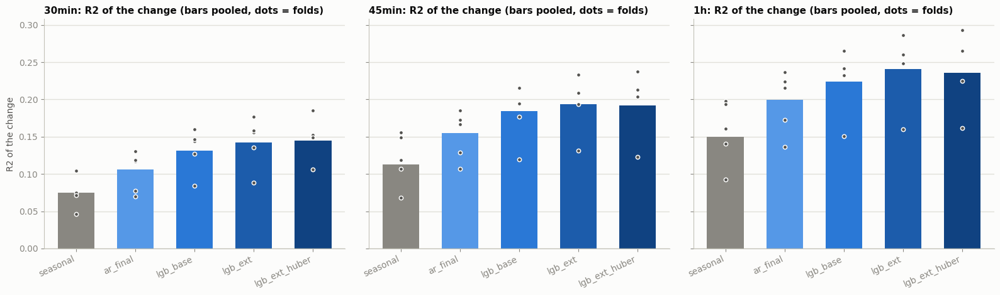

In [21]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import lightgbm as lgb
from sklearn.linear_model import Ridge
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

# ------------------------------------------------ setup (dev period only)
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()
assert dev.index.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
for sub in ("preds", "reports", "figs"): (RUN / sub).mkdir(exist_ok=True)
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False})

HZ = {"30min": 6, "45min": 9, "1h": 12}
EMB = P.embargo_steps; EMBt = pd.Timedelta(minutes=5 * EMB); ALPHAS = np.logspace(-2, 4, 7)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy()
tod = np.asarray((dev.index.hour * 60 + dev.index.minute - 5) % 1440); th = 2 * np.pi * tod / 1440
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy()

def metrics(yt, yp, y0):
    e = yt - yp; sse = (e ** 2).sum(); d = yt - y0; rt, rp = np.exp(yt), np.exp(yp)
    return dict(n=len(yt), mse_log=sse / len(yt), mae_log=np.abs(e).mean(),
                r2_log=1 - sse / ((yt - yt.mean()) ** 2).sum(), r2_delta=1 - sse / ((d - d.mean()) ** 2).sum(),
                r2_raw=1 - ((rt - rp) ** 2).sum() / ((rt - rt.mean()) ** 2).sum(), skill_vs_persist=1 - sse / (d ** 2).sum())

def ridge_cv(Z, yv, opos, H):                                   # forward chaining with embargo (for the AR comparison model)
    edges = np.linspace(0, len(Z), 6).astype(int); best = (np.inf, None, None)
    for a in ALPHAS:
        mse = []
        for b in range(1, 5):
            fit = (opos + H) <= (opos[edges[b]] - EMB)
            if fit.sum() < 500: continue
            v = slice(edges[b], edges[b + 1]); mse.append(((yv[v] - Ridge(alpha=a).fit(Z[fit], yv[fit]).predict(Z[v])) ** 2).mean())
        if mse and np.mean(mse) < best[0]: best = (np.mean(mse), a, np.array(mse))
    return best

# ------------------------------------------------ causal features
LAGS = [1, 2, 3, 6, 12, 24, 36, 72, 144, 216, 288]
def build_feats(yv, H):
    yf = pd.Series(yv).ffill(); F = {}
    for L in LAGS: F[f"d{L}"] = (yf - yf.shift(L)).to_numpy()
    for K in (72, 288, 864): F[f"dev{K}"] = (yf - yf.rolling(K, min_periods=K // 2).mean()).to_numpy()
    F["s1"], F["c1"], F["s2"], F["c2"] = np.sin(th), np.cos(th), np.sin(2 * th), np.cos(2 * th)
    F["tod"] = tod.astype(float)
    sd = np.vstack([(yf.shift(288 * k - H) - yf.shift(288 * k)).to_numpy() for k in (1, 2, 3)])
    F["sd1"] = sd[0]; F["sd3"] = np.nanmean(sd, axis=0)                              # same-phase change 1 day ago / 3-day mean
    dy = yf.diff()
    for K in (12, 72, 288): F[f"vol{K}"] = dy.rolling(K, min_periods=K // 2).std().to_numpy()
    F["rng72"] = (yf.rolling(72, min_periods=36).max() - yf.rolling(72, min_periods=36).min()).to_numpy()
    obs = np.isfinite(yv); last = np.maximum.accumulate(np.where(obs, np.arange(len(yv)), -1))
    F["stale"] = np.minimum(np.arange(len(yv)) - last, 288).astype(float)           # steps since the last real observation
    return F

AR_COLS = [f"d{L}" for L in LAGS] + ["s1", "c1", "s2", "c2"]
EXT_COLS = [f"d{L}" for L in LAGS] + ["dev72", "dev288", "dev864", "s1", "c1", "s2", "c2", "tod", "sd1", "sd3",
                                      "vol12", "vol72", "vol288", "rng72", "stale"]
y2 = y.copy(); y2[60001:] = np.random.default_rng(0).normal(0, 3, len(y) - 60001)   # perturbation test: nothing after the cut may leak backwards
for H in HZ.values():
    A, B_ = build_feats(y, H), build_feats(y2, H)
    for k in A: assert np.allclose(A[k][:60001], B_[k][:60001], equal_nan=True), f"feature {k} uses the future (H={H})"
print("causality test passed for all features and horizons")

# ------------------------------------------------ LightGBM with inner early stopping
def fit_lgb(Xt, dt, opos, H, objective):
    n = len(Xt); cut = int(n * 0.8)                                                   # inner validation: last 20% of training rows
    inner = (opos + H) <= (opos[cut] - EMB)                                           # embargo gap before the inner validation block
    scale = 1.4826 * np.median(np.abs(dt - np.median(dt)))
    params = dict(objective=objective, learning_rate=0.03, num_leaves=15, min_child_samples=500, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=10.0, n_estimators=3000, n_jobs=-1, verbose=-1, random_state=0)
    if objective == "huber": params["alpha"] = 1.345 * scale
    m = lgb.LGBMRegressor(**params).fit(Xt[inner], dt[inner], eval_set=[(Xt[cut:], dt[cut:])],
                                        callbacks=[lgb.early_stopping(100, verbose=False)])
    best = m.best_iteration_ or params["n_estimators"]; params["n_estimators"] = int(best * 1.1) + 1
    return lgb.LGBMRegressor(**params).fit(Xt, dt), best

MODELS = ["persist", "seasonal", "ar_final", "lgb_base", "lgb_ext", "lgb_ext_huber"]
ALL = list(range(len(EXT_COLS))); AR_IDX = [EXT_COLS.index(c) for c in AR_COLS]
LGB = {"lgb_base": (AR_IDX, "regression"), "lgb_ext": (ALL, "regression"), "lgb_ext_huber": (ALL, "huber")}

# ------------------------------------------------ run: 3 horizons x 5 folds
store, imp, iters, SAVE, perfold = {}, {}, [], {}, []
for hn, H in HZ.items():
    F = build_feats(y, H); n = len(y); i = np.arange(n - H); j = i + H
    XE = np.column_stack([F[c][i] for c in EXT_COLS]); XA = XE[:, AR_IDX]
    ok = np.isfinite(y[i]) & np.isfinite(y[j]) & ~bad[j] & np.isfinite(XA).all(axis=1)       # same rows as the AR model; LightGBM may see NaN in extras
    delta = y[j] - y[i]; tt, ot = dev.index[j], dev.index[i]; sbin = tod[i] // 30
    for w in folds:
        tr = ok & ~bad[i] & np.asarray(tt <= w.val_start - EMBt)
        va = ok & np.asarray((ot >= w.val_start) & (tt < w.val_end))
        assert tt[tr].max() <= w.val_start - EMBt and ot[va].min() >= w.val_start
        y0, yt, dt, opos = y[i][va], y[j][va], delta[tr], i[tr]
        preds = {"persist": y0.copy(),
                 "seasonal": y0 + pd.Series(sbin[va]).map(pd.Series(dt).groupby(sbin[tr]).mean()).fillna(0).to_numpy()}
        mu, sd = XA[tr].mean(0), XA[tr].std(0) + 1e-12; Z = (XA[tr] - mu) / sd
        _, a, _ = ridge_cv(Z, dt, opos, H); preds["ar_final"] = y0 + Ridge(alpha=a).fit(Z, dt).predict((XA[va] - mu) / sd)
        XEt, XEv = XE[tr], XE[va]
        for name, (cols, obj) in LGB.items():
            m, bi = fit_lgb(XEt[:, cols], dt, opos, H, obj); preds[name] = y0 + m.predict(XEv[:, cols])
            iters.append(dict(H=hn, fold=w.name, model=name, best_iter=bi))
            if name == "lgb_ext": imp.setdefault(hn, []).append(pd.Series(m.booster_.feature_importance("gain"), index=EXT_COLS))
        store.setdefault(hn, {})[w.name] = dict(yt=yt, y0=y0, pos=i[va], ot=ot[va], preds=preds)
        SAVE.update({f"{hn}_{w.name}_{k}": v for k, v in preds.items()}); SAVE[f"{hn}_{w.name}_y"] = yt; SAVE[f"{hn}_{w.name}_pos"] = i[va]
        for m_, p in preds.items(): perfold.append(dict(H=hn, fold=w.name, model=m_, **metrics(yt, p, y0)))
    print("done", hn)
np.savez_compressed(RUN / "preds" / "lgbm.npz", **SAVE)

# ------------------------------------------------ reports
cat = lambda hn, k: np.concatenate([store[hn][f][k] for f in store[hn]])
catp = lambda hn, m: np.concatenate([store[hn][f]["preds"][m] for f in store[hn]])
pf = pd.DataFrame(perfold); rows = []
for hn in HZ:
    yt, y0 = cat(hn, "yt"), cat(hn, "y0"); Pm = {m: catp(hn, m) for m in MODELS}
    sse = {m: ((yt - p) ** 2).sum() for m, p in Pm.items()}; mae_p = np.abs(yt - Pm["persist"]).mean()
    for m in MODELS:
        mt = metrics(yt, Pm[m], y0)
        rows.append(dict(H=hn, model=m, **mt, skill_vs_seasonal=1 - sse[m] / sse["seasonal"], skill_vs_ar=1 - sse[m] / sse["ar_final"],
                         skill_mae_vs_persist=1 - mt["mae_log"] / mae_p))
pooled = pd.DataFrame(rows)
pd.set_option("display.width", 220); pd.set_option("display.float_format", "{:.4f}".format)
for c in ("r2_delta", "r2_log", "r2_raw", "skill_vs_seasonal", "skill_vs_ar", "skill_mae_vs_persist", "mse_log"):
    print(f"\n{c} (pooled over the 5 folds)"); print(pooled.pivot(index="model", columns="H", values=c).reindex(MODELS)[list(HZ)])
print("\nR2 of the change per fold")
print(pf.pivot_table(index=["H", "model"], columns="fold", values="r2_delta", sort=False))

def dm(lb, lm, L=288):                                           # Diebold-Mariano with HAC; positive = second model better
    d = lb - lm; return float(sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": L}).tvalues[0])
dm_rows = []
for hn in HZ:
    for m in ("lgb_base", "lgb_ext", "lgb_ext_huber"):
        for base in ("ar_final", "seasonal"):
            row = dict(H=hn, model=m, vs=base)
            for scope in ["pooled", *store[hn]]:
                yt_ = cat(hn, "yt") if scope == "pooled" else store[hn][scope]["yt"]
                get = (lambda k: catp(hn, k)) if scope == "pooled" else (lambda k, s=scope: store[hn][s]["preds"][k])
                row[scope] = dm((yt_ - get(base)) ** 2, (yt_ - get(m)) ** 2)
            dm_rows.append(row)
dmd = pd.DataFrame(dm_rows); print("\nDiebold-Mariano t (positive = LightGBM better; |t| > 2 significant)")
print(dmd.set_index(["H", "model", "vs"]))

def day_boot(hn, m, base, B=2000, seed=0):                      # day-block bootstrap of 1 - SSE(m)/SSE(base)
    parts = [pd.DataFrame({"day": r["ot"].normalize(), "a": (r["yt"] - r["preds"][m]) ** 2, "b": (r["yt"] - r["preds"][base]) ** 2}).groupby("day").sum()
             for r in store[hn].values()]
    d = pd.concat(parts); a, b = d["a"].to_numpy(), d["b"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(d), size=(B, len(d)))
    return 1 - a.sum() / b.sum(), *np.percentile(1 - a[idx].sum(1) / b[idx].sum(1), [2.5, 97.5])
bt = pd.DataFrame([dict(H=hn, model=m, vs=base, skill=s, lo95=lo, hi95=hi) for hn in HZ for m in ("lgb_base", "lgb_ext", "lgb_ext_huber")
                   for base in ("ar_final", "seasonal") for s, lo, hi in [day_boot(hn, m, base)]]).set_index(["H", "model", "vs"])
print("\nskill with 95% day-block bootstrap interval"); print(bt)

print("\nlgb_ext feature importance (% of total gain, mean over folds), top 12")
fi = pd.DataFrame({hn: (lambda s: 100 * s / s.sum())(pd.concat(v, axis=1).mean(axis=1)) for hn, v in imp.items()})
print(fi.sort_values("45min", ascending=False).head(12))
print("\nbest number of trees (early stopping) per fold"); print(pd.DataFrame(iters).pivot_table(index=["H", "model"], columns="fold", values="best_iter"))

pooled.to_csv(RUN / "reports" / "lgbm_pooled.csv", index=False); pf.to_csv(RUN / "reports" / "lgbm_per_fold.csv", index=False)
dmd.to_csv(RUN / "reports" / "lgbm_dm.csv", index=False); bt.to_csv(RUN / "reports" / "lgbm_bootstrap.csv"); fi.to_csv(RUN / "reports" / "lgbm_importance.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
ms = ["seasonal", "ar_final", "lgb_base", "lgb_ext", "lgb_ext_huber"]; colr = dict(zip(ms, [MUTED, *RAMP[1:]]))
for ax, hn in zip(axes, HZ):
    for xi, m in enumerate(ms):
        pv = pooled[(pooled.H == hn) & (pooled.model == m)]["r2_delta"].iloc[0]; fv = pf[(pf.H == hn) & (pf.model == m)]["r2_delta"]
        ax.bar(xi, pv, 0.62, color=colr[m]); ax.plot(np.full(len(fv), xi), fv, "o", ms=4.5, color=INK2, mec=SURF, mew=1.1, zorder=3)
    ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(range(len(ms))); ax.set_xticklabels(ms, rotation=25, ha="right")
    ax.set_title(f"{hn}: R2 of the change (bars pooled, dots = folds)")
axes[0].set_ylabel("R2 of the change")
fig.tight_layout(); fig.savefig(RUN / "figs" / "lgbm_r2_change.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output**

First line: `causality test passed for all features and horizons`.

**$R^2_\Delta$, pooled over five folds**

| Model | 30 min | 45 min | 1 h |
|---|---|---|---|
| seasonal baseline | 0.0749 | 0.1130 | 0.1500 |
| `ar_final` | 0.1060 | 0.1547 | 0.1997 |
| `lgb_base` (AR inputs only) | 0.1317 | 0.1843 | 0.2243 |
| `lgb_ext` | 0.1419 | 0.1935 | 0.2412 |
| `lgb_ext_huber` | **0.1452** | 0.1920 | 0.2359 |

* **Same inputs, non-linear model:** `lgb_base` − `ar_final` = +0.026 / +0.030 / +0.025. That is the value of non-linearity alone.
* **More inputs:** `lgb_ext` − `lgb_base` = +0.010 / +0.009 / +0.017. That is the value of the volatility, range, same-phase and deviation features.
* **Skill vs the AR** (reduction in squared error): `lgb_ext` 4.0 % / 4.6 % / 5.2 %, `lgb_ext_huber` 4.4 % / 4.4 % / 4.5 %. **Skill vs seasonal baseline:** 7.2–10.7 % (`lgb_ext`).
* **MAE skill vs persistence** is better for Huber (0.118 / 0.155 / 0.188 vs 0.097 / 0.132 / 0.165 for `lgb_ext`): as expected, the robust loss wins on typical (absolute) error.
* **Per fold** `lgb_ext` beats `ar_final` in all five folds at every horizon (e.g. 30 min: 0.156 vs 0.131, 0.136 vs 0.078, 0.088 vs 0.070, 0.158 vs 0.117, 0.177 vs 0.119).

**Diebold–Mariano $t$ (positive = LightGBM better).** Pooled `lgb_ext` vs `ar_final`: 5.19 / 4.55 / 4.63; `lgb_ext_huber` vs `ar_final`: **9.24 / 7.43 / 6.13**. For `lgb_ext` the weakest fold is cv1 (1.2–1.5, not significant); for the Huber variant the soft spots are cv3 at 45 min (1.32) and cv4 at 1 h (1.06).

**Bootstrap 95 % intervals** of skill vs the AR all exclude zero, e.g. `lgb_ext` 30 min 0.040 [0.025, 0.054]; 1 h 0.052 [0.030, 0.072].

**Feature importance** (% of total gain, `lgb_ext`, mean over folds): `c1` dominates at **22.1 % / 24.4 % / 28.8 %** (the cosine of the daily cycle, more important as the horizon grows), then `d216` (8.5–11.7 %), `d24`, `vol12`, `dev72`, `vol288`, `vol72`, `rng72`, `dev288`, `tod`. The volatility features together hold roughly 20 % of the gain: **the model uses current turbulence to decide how large a move to expect**.

**Best number of trees per fold** ranges from about 60 to 660 (e.g. 30 min `lgb_ext`: 514 / 200 / 70 / 156 / 157): early stopping chooses very different capacities for different folds, which is one reason the number is never fixed by hand.

## 7.3 Controls: is LightGBM's edge a rich-AR-in-disguise or a lucky seed?

📘 **What.** Three controls, run in the same session as the LightGBM cell:

* **`ar_rich`**: a ridge AR given everything a tree could exploit linearly: 11 lags, **6 harmonics** of the daily cycle ($\sin k\theta,\cos k\theta$, $k=1..6$) and **lag × time-of-day interactions** for $L\in\{1,3,12,72,288\}$ with $\sin\theta$ and $\cos\theta$. If LightGBM only exploits seasonality interactions, this model would match it.
* **Four extra seeds** of `lgb_ext` (seeds 1–4) to measure random-seed noise, plus an ensemble of 5 seeds.
* **`lgb_ext_fix200`**: the same model with exactly 200 trees, to show that the data-dependent early stopping is not what produces the result.

In [22]:

# run in the SAME kernel session, right after the LightGBM cell (reuses y, th, bad, dev, folds, store, build_feats, ridge_cv, dm ...)
def fit_lgb2(Xt, dt, opos, H, seed, n_fixed=None):
    base = dict(objective="regression", learning_rate=0.03, num_leaves=15, min_child_samples=500, subsample=0.8,
                subsample_freq=1, colsample_bytree=0.8, reg_lambda=10.0, n_jobs=-1, verbose=-1, random_state=seed)
    if n_fixed is None:
        cut = int(len(Xt) * 0.8); inner = (opos + H) <= (opos[cut] - EMB)
        m = lgb.LGBMRegressor(n_estimators=3000, **base).fit(Xt[inner], dt[inner], eval_set=[(Xt[cut:], dt[cut:])],
                                                            callbacks=[lgb.early_stopping(100, verbose=False)])
        n_fixed = int((m.best_iteration_ or 3000) * 1.1) + 1
    return lgb.LGBMRegressor(n_estimators=n_fixed, **base).fit(Xt, dt)

def r2d(yt, yp, y0):
    d = yt - y0; return 1 - ((yt - yp) ** 2).sum() / ((d - d.mean()) ** 2).sum()

out = {hn: {} for hn in HZ}
for hn, H in HZ.items():
    F = build_feats(y, H); n = len(y); i = np.arange(n - H); j = i + H
    XE = np.column_stack([F[c][i] for c in EXT_COLS]); XA = XE[:, AR_IDX]
    ok = np.isfinite(y[i]) & np.isfinite(y[j]) & ~bad[j] & np.isfinite(XA).all(axis=1)       # identical row rule to the LightGBM cell
    delta = y[j] - y[i]; tt, ot = dev.index[j], dev.index[i]
    harm = [f(k * th)[i] for k in range(1, 7) for f in (np.sin, np.cos)]                      # 6 harmonics of the daily cycle
    inter = [F[f"d{L}"][i] * t[i] for L in (1, 3, 12, 72, 288) for t in (np.sin(th), np.cos(th))]   # lag x time-of-day interactions
    XR = np.column_stack([F[f"d{L}"][i] for L in LAGS] + harm + inter)
    for w in folds:
        tr = ok & ~bad[i] & np.asarray(tt <= w.val_start - EMBt)
        va = ok & np.asarray((ot >= w.val_start) & (tt < w.val_end))
        ref = store[hn][w.name]; assert np.allclose(ref["yt"], y[j][va]), "row mismatch with the LightGBM cell"
        dt, opos, y0 = delta[tr], i[tr], ref["y0"]
        mu, sd = XR[tr].mean(0), XR[tr].std(0) + 1e-12; Z = (XR[tr] - mu) / sd
        _, a, _ = ridge_cv(Z, dt, opos, H)
        pr = {"ar_rich": y0 + Ridge(alpha=a).fit(Z, dt).predict((XR[va] - mu) / sd)}
        for s in range(1, 5): pr[f"lgb_ext_s{s}"] = y0 + fit_lgb2(XE[tr], dt, opos, H, s).predict(XE[va])
        pr["lgb_ext_fix200"] = y0 + fit_lgb2(XE[tr], dt, opos, H, 0, n_fixed=200).predict(XE[va])
        for k, v in pr.items(): out[hn].setdefault(k, []).append(v)
    print("done", hn)

rows = []
for hn in HZ:
    yt = np.concatenate([store[hn][f]["yt"] for f in store[hn]]); y0 = np.concatenate([store[hn][f]["y0"] for f in store[hn]])
    Pm = {k: np.concatenate(v) for k, v in out[hn].items()}
    for m in ("seasonal", "ar_final", "lgb_base", "lgb_ext"):
        Pm[m] = np.concatenate([store[hn][f]["preds"][m] for f in store[hn]])
    seeds = [Pm["lgb_ext"]] + [Pm[f"lgb_ext_s{s}"] for s in range(1, 5)]
    Pm["lgb_ext_ens5"] = np.mean(seeds, axis=0)
    sse = {k: ((yt - p) ** 2).sum() for k, p in Pm.items()}
    for m in ("seasonal", "ar_final", "ar_rich", "lgb_base", "lgb_ext", "lgb_ext_fix200", "lgb_ext_ens5"):
        rows.append(dict(H=hn, model=m, r2_delta=r2d(yt, Pm[m], y0), skill_vs_ar=1 - sse[m] / sse["ar_final"],
                         skill_vs_ar_rich=1 - sse[m] / sse["ar_rich"]))
    r2s = [r2d(yt, p, y0) for p in seeds]
    print(f"{hn}: lgb_ext R2 over 5 seeds mean {np.mean(r2s):.4f}, sd {np.std(r2s, ddof=1):.4f}, range [{min(r2s):.4f}, {max(r2s):.4f}]")
    for m in ("lgb_base", "lgb_ext"):
        print(f"{hn}: DM {m} vs ar_rich t = {dm((yt - Pm['ar_rich']) ** 2, (yt - Pm[m]) ** 2):.2f}  (positive = LightGBM better)")
res = pd.DataFrame(rows)
order = ["seasonal", "ar_final", "ar_rich", "lgb_base", "lgb_ext", "lgb_ext_fix200", "lgb_ext_ens5"]
for c in ("r2_delta", "skill_vs_ar", "skill_vs_ar_rich"):
    print(f"\n{c} (pooled over the 5 folds)"); print(res.pivot(index="model", columns="H", values=c).reindex(order)[list(HZ)])
res.to_csv(RUN / "reports" / "lgbm_controls.csv", index=False)

done 30min
done 45min
done 1h
30min: lgb_ext R2 over 5 seeds mean 0.1422, sd 0.0005, range [0.1418, 0.1428]
30min: DM lgb_base vs ar_rich t = 6.49  (positive = LightGBM better)
30min: DM lgb_ext vs ar_rich t = 6.06  (positive = LightGBM better)
45min: lgb_ext R2 over 5 seeds mean 0.1911, sd 0.0018, range [0.1891, 0.1935]
45min: DM lgb_base vs ar_rich t = 6.45  (positive = LightGBM better)
45min: DM lgb_ext vs ar_rich t = 5.40  (positive = LightGBM better)
1h: lgb_ext R2 over 5 seeds mean 0.2398, sd 0.0016, range [0.2373, 0.2412]
1h: DM lgb_base vs ar_rich t = 5.46  (positive = LightGBM better)
1h: DM lgb_ext vs ar_rich t = 5.32  (positive = LightGBM better)

r2_delta (pooled over the 5 folds)
H               30min  45min     1h
model                              
seasonal       0.0749 0.1130 0.1500
ar_final       0.1060 0.1547 0.1997
ar_rich        0.1018 0.1497 0.1950
lgb_base       0.1317 0.1843 0.2243
lgb_ext        0.1419 0.1935 0.2412
lgb_ext_fix200 0.1423 0.1959 0.2432
lgb_ext_en

👀 **How to read this output**

| $R^2_\Delta$ pooled | 30 min | 45 min | 1 h |
|---|---|---|---|
| `ar_final` | 0.1060 | 0.1547 | 0.1997 |
| **`ar_rich`** | 0.1018 | 0.1497 | 0.1950 |
| `lgb_ext` | 0.1419 | 0.1935 | 0.2412 |
| `lgb_ext_fix200` | 0.1423 | 0.1959 | 0.2432 |
| 5-seed ensemble | 0.1432 | 0.1924 | 0.2411 |

* **`ar_rich` is *worse* than `ar_final`** (−0.0046 / −0.0060 / −0.0058 in skill). More linear seasonal structure only adds noise. LightGBM's gain therefore does **not** come from daily-cycle interactions: against `ar_rich` the skill is 4.5 % / 5.2 % / 5.7 %, with **DM $t$ = 6.06 / 5.40 / 5.32** for `lgb_ext`.
* **Seed noise is tiny:** the standard deviation of $R^2_\Delta$ over 5 seeds is **0.0005 / 0.0018 / 0.0016**, far smaller than the 0.03–0.04 gap to the AR.
* **200 fixed trees** gives the same numbers (0.1423 vs 0.1419), so early stopping is not responsible for the result.

## 7.4 Where do the errors live? Eight diagnostic views of the residuals

📘 **What.** For `ar_final`, `lgb_ext`, `lgb_ext_huber` (plus the baselines), with residual $e_t=y_{t+H}-\hat y_{t+H}$:

1. **Distribution** and bias (day-level $t$-statistic of the mean).
2. **ACF of residuals and of squared residuals** up to lag 300.
3. **Error by trailing-volatility quintile** (rolling sd over 288 steps).
4. **Calibration slope**: regress the *actual* change on the *predicted* change,
$$\Delta_t=a+\kappa\,\hat\Delta_t+\varepsilon_t .$$
$\kappa=1$ means forecasts are correctly scaled; $\kappa<1$ means they are too large (shrink them); $\kappa>1$ means they are too timid. HAC standard errors.
5. **Asymmetry after big moves**: bias and skill after the top/bottom 10 % one-hour moves.
6. **Per-fold bias and RMSE.**
7. **Concentration of squared error** over days.
8. **Worst days** and each model's skill on them.

🎯 **Why.** A single $R^2$ hides *where* a model fails. These views decide the next step (improve the mean, or model the variance).

**A point on overlap.** A forecast made every 5 min for a horizon $H$ has targets that overlap by $H-k$ steps at lag $k$, so even a perfect forecaster has residual ACF $\approx 1-k/H$ for $k<H$ (the column `overlap_ref`). Only lags $\ge H$ are informative.

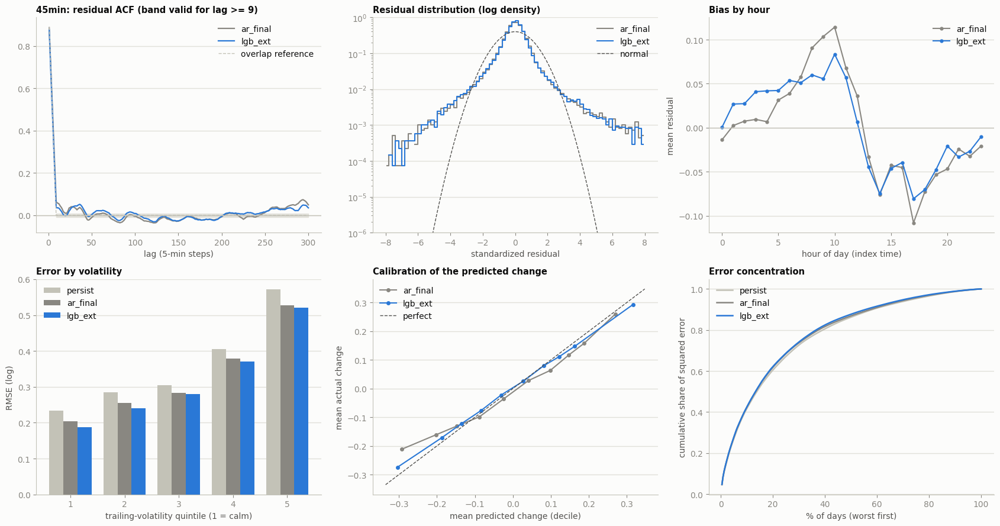

1. residual distribution (actual - predicted, log scale); bias_t_days = day-level t of the mean
                         n    bias  median   rmse    mae   skew  ex_kurt  pct_gt3sd     q01    q99  bias_t_days
H     model                                                                                                    
30min persist        68870 -0.0007 -0.0006 0.3094 0.1808 0.5611  29.6761     1.8920 -0.8145 0.9913      -0.4932
      seasonal       68870 -0.0003 -0.0007 0.2976 0.1670 0.5653  32.8785     1.9878 -0.8078 0.9745      -0.2211
      ar_final       68870 -0.0003 -0.0004 0.2926 0.1690 0.4753  28.0259     1.9602 -0.8135 0.9282      -0.1093
      lgb_base       68870  0.0006  0.0042 0.2883 0.1636 0.1973  29.9756     2.0067 -0.8273 0.9129       0.1976
      lgb_ext        68870  0.0013  0.0052 0.2866 0.1632 0.1469  29.5867     2.0067 -0.8264 0.9045       0.4263
      lgb_ext_huber  68870  0.0043  0.0049 0.2861 0.1594 0.4416  33.2251     1.9704 -0.7859 0.9272       1.8145
45min pe

In [23]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()
assert dev.index.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "legend.frameon": False})
COL = {"persist": AXIS, "ar_final": MUTED, "lgb_ext": RAMP[2], "lgb_ext_huber": RAMP[4]}

Z = np.load(RUN / "preds" / "lgbm.npz")
HZ = {"30min": 6, "45min": 9, "1h": 12}
MODELS = ["persist", "seasonal", "ar_final", "lgb_base", "lgb_ext", "lgb_ext_huber"]
FN = [w.name for w in folds]
idx = dev.index; n = len(dev)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy(); yf = pd.Series(y).ffill()
vol288 = yf.diff().rolling(288, min_periods=144).std().to_numpy()        # causal trailing volatility at the origin
d12 = (yf - yf.shift(12)).to_numpy()                                       # change over the last hour at the origin

def load(hn):
    ln = [len(Z[f"{hn}_{f}_pos"]) for f in FN]
    pos = np.concatenate([Z[f"{hn}_{f}_pos"] for f in FN]); yt = np.concatenate([Z[f"{hn}_{f}_y"] for f in FN])
    pr = {m: np.concatenate([Z[f"{hn}_{f}_{m}"] for f in FN]) for m in MODELS}
    return pos, yt, np.repeat(FN, ln), pr

def summ(e):
    return dict(n=len(e), bias=e.mean(), median=np.median(e), rmse=np.sqrt((e ** 2).mean()), mae=np.abs(e).mean(),
                skew=stats.skew(e), ex_kurt=stats.kurtosis(e), pct_gt3sd=100 * (np.abs(e - e.mean()) > 3 * e.std()).mean(),
                q01=np.percentile(e, 1), q99=np.percentile(e, 99))

def acf_full(e, pos, lags):                                                # ACF on the 5-min grid, gaps are NaN (pairwise)
    a = np.full(n, np.nan); a[pos] = e - e.mean(); out = []
    for k in lags:
        u, v = a[:-k], a[k:]; m = np.isfinite(u) & np.isfinite(v)
        out.append((u[m] * v[m]).sum() / np.sqrt((u[m] ** 2).sum() * (v[m] ** 2).sum()))
    return np.array(out)

R3 = ("ar_final", "lgb_ext", "lgb_ext_huber")
rs, racf, rvol, rcal, rhr, rst, rfold, rconc, rworst = [], [], [], [], [], [], [], [], []
for hn, H in HZ.items():
    pos, yt, fold, pr = load(hn); assert len(np.unique(pos)) == len(pos), "origins overlap between folds"
    y0 = pr["persist"]; day = idx[pos].normalize().values; hr = idx[pos].hour.to_numpy()
    E = {m: yt - pr[m] for m in MODELS}; ad = yt - y0                       # E["persist"] is the actual change

    for m in MODELS:                                                        # 1. distribution and bias
        dm_ = pd.Series(E[m]).groupby(day).mean()
        rs.append(dict(H=hn, model=m, **summ(E[m]), bias_t_days=dm_.mean() / (dm_.std(ddof=1) / np.sqrt(len(dm_)))))

    lags = np.arange(1, 301)                                                # 2. autocorrelation of residuals and squared residuals
    A = {m: acf_full(E[m], pos, lags) for m in R3}; A2 = {m: acf_full(E[m] ** 2, pos, lags) for m in R3}
    for k in sorted({1, H // 2, H - 1, H, H + 1, 2 * H, 36, 72, 144, 288}):
        racf.append(dict(H=hn, lag=k, overlap_ref=max(0.0, 1 - k / H), **{f"acf_{m}": A[m][k - 1] for m in R3},
                         **{f"acf_sq_{m}": A2[m][k - 1] for m in R3}))
    for m in R3: racf.append(dict(H=hn, lag=f"max|acf| lags {H}-300", overlap_ref=np.nan, **{f"acf_{mm}": np.abs(A[mm][H - 1:]).max() if mm == m else np.nan for mm in R3}))

    v = vol288[pos]; okv = np.isfinite(v); q = pd.qcut(v[okv], 5, labels=False); where = np.where(okv)[0]   # 3. by volatility
    for qi in range(5):
        mk = where[q == qi]; sp = (E["persist"][mk] ** 2).sum()
        rvol.append(dict(H=hn, vol_q=qi + 1, n=len(mk), **{f"rmse_{m}": np.sqrt((E[m][mk] ** 2).mean()) for m in ("persist", *R3)},
                         **{f"skill_{m}": 1 - (E[m][mk] ** 2).sum() / sp for m in ("seasonal", *R3)},
                         **{f"bias_{m}": E[m][mk].mean() for m in ("ar_final", "lgb_ext")}))

    for m in R3:                                                            # 4. calibration: actual change on predicted change
        pdl = pr[m] - y0
        for scope in ["pooled", *FN]:
            mk = np.ones(len(ad), bool) if scope == "pooled" else fold == scope
            r = sm.OLS(ad[mk], sm.add_constant(pdl[mk])).fit(cov_type="HAC", cov_kwds={"maxlags": 288})
            rcal.append(dict(H=hn, model=m, scope=scope, intercept=r.params[0], slope=r.params[1], slope_se=r.bse[1],
                             t_vs_1=(r.params[1] - 1) / r.bse[1]))

    for m in ("ar_final", "lgb_ext"):                                       # 5. bias by hour of day (index time)
        d = pd.DataFrame({"h": hr, "e": E[m], "e2": E[m] ** 2}).groupby("h").agg(bias=("e", "mean"), rmse=("e2", lambda s: np.sqrt(s.mean())), n=("e", "size"))
        for h_, r in d.iterrows(): rhr.append(dict(H=hn, model=m, hour=h_, bias=r["bias"], rmse=r["rmse"], n=r["n"]))

    s = d12[pos]; oks = np.isfinite(s); lo, hi = np.percentile(s[oks], [10, 90])      # 6. asymmetry after big moves in the last hour
    cat = np.where(s <= lo, "after 1h fall (bottom 10%)", np.where(s >= hi, "after 1h rise (top 10%)", "middle 80%")); cat[~oks] = "n/a"
    for m in ("ar_final", "lgb_ext"):
        for c in np.unique(cat):
            mk = cat == c
            rst.append(dict(H=hn, model=m, state=c, n=mk.sum(), bias=E[m][mk].mean(), rmse=np.sqrt((E[m][mk] ** 2).mean()),
                            skill_vs_persist=1 - (E[m][mk] ** 2).sum() / (E["persist"][mk] ** 2).sum()))

    for f in FN:                                                            # 7. per fold
        mk = fold == f
        for m in ("seasonal", *R3):
            rfold.append(dict(H=hn, fold=f, model=m, bias=E[m][mk].mean(), rmse=np.sqrt((E[m][mk] ** 2).mean()), ex_kurt=stats.kurtosis(E[m][mk])))

    DS = {}                                                                 # 8. concentration of squared error
    for m in ("persist", "ar_final", "lgb_ext"):
        e2 = E[m] ** 2; ds = pd.Series(e2).groupby(day).sum().sort_values(ascending=False); tot = ds.sum(); DS[m] = ds; srt = np.sort(e2)[::-1]
        rconc.append(dict(H=hn, model=m, n_days=len(ds), top1_day=ds.iloc[0] / tot, top5_days=ds.iloc[:5].sum() / tot,
                          top10_days=ds.iloc[:10].sum() / tot, top1pct_points=srt[:int(0.01 * len(srt))].sum() / tot))
    for dday in DS["lgb_ext"].index[:8]:
        rworst.append(dict(H=hn, day=str(pd.Timestamp(dday).date()), share_of_lgb_sse=DS["lgb_ext"][dday] / DS["lgb_ext"].sum(),
                           lgb_vs_persist_skill_that_day=1 - DS["lgb_ext"][dday] / DS["persist"][dday],
                           lgb_vs_ar_skill_that_day=1 - DS["lgb_ext"][dday] / DS["ar_final"][dday]))

    # ---------------- figure
    fig, ax = plt.subplots(2, 3, figsize=(17, 9)); ax = ax.ravel()
    for m in ("ar_final", "lgb_ext"): ax[0].plot(lags, A[m], color=COL[m], lw=1.6, label=m)
    ax[0].plot(lags, np.maximum(0, 1 - lags / H), color=AXIS, lw=1, ls="--", label="overlap reference")
    b = 2 / np.sqrt(len(pos)); ax[0].fill_between(lags[lags >= H], -b, b, color=GRID, alpha=0.9, zorder=0)
    ax[0].axhline(0, color=AXIS, lw=1); ax[0].set_xlabel("lag (5-min steps)"); ax[0].legend(); ax[0].set_title(f"{hn}: residual ACF (band valid for lag >= {H})")
    for m in ("ar_final", "lgb_ext"):
        z = (E[m] - E[m].mean()) / E[m].std(); h_, ed = np.histogram(z, bins=np.linspace(-8, 8, 81), density=True)
        ax[1].step(0.5 * (ed[1:] + ed[:-1]), np.where(h_ > 0, h_, np.nan), where="mid", color=COL[m], lw=1.5, label=m)
    xg = np.linspace(-8, 8, 400); ax[1].plot(xg, stats.norm.pdf(xg), color=INK2, lw=1, ls="--", label="normal")
    ax[1].set_yscale("log"); ax[1].set_ylim(1e-6, 1); ax[1].set_xlabel("standardized residual"); ax[1].legend(); ax[1].set_title("Residual distribution (log density)")
    for m in ("ar_final", "lgb_ext"):
        d = pd.DataFrame({"h": hr, "e": E[m]}).groupby("h")["e"].mean(); ax[2].plot(d.index, d.values, "-o", ms=3.5, color=COL[m], label=m)
    ax[2].axhline(0, color=AXIS, lw=1); ax[2].set_xlabel("hour of day (index time)"); ax[2].set_ylabel("mean residual"); ax[2].legend(); ax[2].set_title("Bias by hour")
    vt = pd.DataFrame(rvol); vt = vt[vt.H == hn]; wd = 0.26
    for k, m in enumerate(("persist", "ar_final", "lgb_ext")): ax[3].bar(vt.vol_q + (k - 1) * wd, vt[f"rmse_{m}"], wd, color=COL[m], label=m)
    ax[3].set_xlabel("trailing-volatility quintile (1 = calm)"); ax[3].set_ylabel("RMSE (log)"); ax[3].legend(); ax[3].set_title("Error by volatility")
    for m in ("ar_final", "lgb_ext"):
        pdl = pr[m] - y0; dq = pd.qcut(pdl, 10, labels=False, duplicates="drop")
        cm = pd.DataFrame({"p": pdl, "a": ad, "q": dq}).groupby("q").mean(); ax[4].plot(cm.p, cm.a, "-o", ms=4, color=COL[m], label=m)
    lim = [min(ax[4].get_xlim()[0], ax[4].get_ylim()[0]), max(ax[4].get_xlim()[1], ax[4].get_ylim()[1])]
    ax[4].plot(lim, lim, color=INK2, lw=1, ls="--", label="perfect"); ax[4].set_xlabel("mean predicted change (decile)"); ax[4].set_ylabel("mean actual change")
    ax[4].legend(); ax[4].set_title("Calibration of the predicted change")
    for m in ("persist", "ar_final", "lgb_ext"):
        cs = DS[m].cumsum().to_numpy() / DS[m].sum(); ax[5].plot(100 * np.arange(1, len(cs) + 1) / len(cs), cs, color=COL[m], lw=1.8, label=m)
    ax[5].set_xlabel("% of days (worst first)"); ax[5].set_ylabel("cumulative share of squared error"); ax[5].legend(); ax[5].set_title("Error concentration")
    fig.tight_layout(); fig.savefig(RUN / "figs" / f"lgbm_residuals_{hn}.png", dpi=150, bbox_inches="tight")
    plt.show() if hn == "45min" else plt.close(fig)

# ---------------- tables
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:.4f}".format)
S, AC, VQ, CAL = pd.DataFrame(rs), pd.DataFrame(racf), pd.DataFrame(rvol), pd.DataFrame(rcal)
ST, FO, CO, WO = pd.DataFrame(rst), pd.DataFrame(rfold), pd.DataFrame(rconc), pd.DataFrame(rworst)
print("1. residual distribution (actual - predicted, log scale); bias_t_days = day-level t of the mean"); print(S.set_index(["H", "model"]))
print("\n2. residual ACF; overlap_ref = approximate value expected from overlapping targets alone; only lags >= H are informative"); print(AC.set_index(["H", "lag"]))
print("\n3. by trailing-volatility quintile"); print(VQ.set_index(["H", "vol_q"]))
print("\n4. calibration slope of actual change on predicted change (1 = well scaled)")
print(CAL.pivot_table(index=["H", "model"], columns="scope", values="slope", sort=False)[["pooled", *FN]])
print("   t of (slope - 1), HAC"); print(CAL.pivot_table(index=["H", "model"], columns="scope", values="t_vs_1", sort=False)[["pooled", *FN]])
print("\n5. asymmetry after big moves in the last hour"); print(ST.set_index(["H", "model", "state"]))
print("\n6. per fold: bias"); print(FO.pivot_table(index=["H", "model"], columns="fold", values="bias", sort=False))
print("   per fold: RMSE"); print(FO.pivot_table(index=["H", "model"], columns="fold", values="rmse", sort=False))
print("\n7. concentration of squared error"); print(CO.set_index(["H", "model"]))
print("\n8. worst days for lgb_ext"); print(WO.set_index(["H", "day"]))
S.to_csv(RUN / "reports" / "lgbm_resid_summary.csv", index=False); AC.to_csv(RUN / "reports" / "lgbm_resid_acf.csv", index=False)
VQ.to_csv(RUN / "reports" / "lgbm_resid_by_vol.csv", index=False); CAL.to_csv(RUN / "reports" / "lgbm_resid_calibration.csv", index=False)
ST.to_csv(RUN / "reports" / "lgbm_resid_state.csv", index=False); FO.to_csv(RUN / "reports" / "lgbm_resid_per_fold.csv", index=False)
CO.to_csv(RUN / "reports" / "lgbm_resid_concentration.csv", index=False); WO.to_csv(RUN / "reports" / "lgbm_resid_worst_days.csv", index=False)
pd.DataFrame(rhr).to_csv(RUN / "reports" / "lgbm_resid_by_hour.csv", index=False)

👀 **How to read this output**

**(1) Distribution.** Bias is tiny for every model (|bias| < 0.007). `lgb_ext_huber` has the largest day-level bias $t$ (+1.8 at 30 min, +1.8 at 45 min, +1.2 at 1 h), still inside ±2. Excess kurtosis 14–33 for all models: residuals are heavy-tailed whatever the model.

**(2) Residual ACF.** At lag 1 the residual ACF is 0.83 (30 min) against the overlap reference 0.83: the entire short-lag autocorrelation is **mechanical overlap**. At lag $H$ (the first honest lag) it is 0.060 for `ar_final` and 0.023 for `lgb_ext` (30 min), and **the largest |ACF| anywhere in lags $H$–300 is 0.044–0.082**. There is essentially **no linear structure left in the mean**.
The *squared* residuals tell the opposite story: ACF 0.65 at lag 1 and still **0.16 at lag $H$** (30 min), 0.07 at lag 36, 0.03 at one day. **The size of the error is strongly predictable.**

**(3) By volatility quintile** (30 min, skill vs persistence for `lgb_ext`): 0.282, 0.205, 0.107, 0.114, 0.131 for quintiles 1…5, with RMSE rising from 0.15 to 0.45. Skill is highest when the flux is calm.

**(4) Calibration slope $\kappa$** (pooled): `ar_final` **0.85 / 0.86 / 0.87** (forecasts too large), `lgb_ext` 0.94 / 0.92 / 0.94, `lgb_ext_huber` **1.15 / 1.12 / 1.11** (too timid). The two LightGBM variants miss in *opposite* directions, which is the reason the blend works. By fold the weakest scaling is cv2 (0.64–0.69 for the AR and 0.79–0.82 for `lgb_ext`: the calm period, forecasts too large) and cv4 for Huber (1.31–1.39).

**(5) After big moves.** After the 10 % largest one-hour **falls** the 30-min bias is −0.068 (`ar_final`) / −0.041 (`lgb_ext`) and after the largest **rises** +0.035 / +0.017. Bias is actual − forecast, so in both cases the flux keeps going further than the model expected: **momentum after big moves is not fully captured**. RMSE after falls (0.53) is 2.3× the middle-80 % RMSE (0.22).

**(6) Per fold.** Bias stays within ±0.013; RMSE is lowest in cv2 (0.22 at 30 min) and highest in cv1/cv4 (0.33).

**(7) Concentration.** The single worst day carries ≈ 5 % of all squared error at 30 min, the 10 worst days (out of 240) carry about 25 %, and the worst 1 % of points carry 40 %. Errors are concentrated, but **no single day dominates**.

**(8) Worst days.** 2017-11-08 (4.96 % of `lgb_ext`'s squared error at 30 min), 2018-04-20 (3.4–3.9 %), 2018-03-18 (2.8–3.2 %), then 2017-11-07, 2017-12-17, 2017-12-05, 2018-05-06, 2018-03-25. On 2018-03-18 and 2017-12-17 `lgb_ext` is *worse* than the AR (−3.6 % / −2.7 % at 30 min); on 2018-04-20 it is 9–12 % better.

✅ **Take-away (Pivot 9).** The mean is essentially exhausted (a rough back-of-envelope estimate from the residual ACF, about $0.05^2\approx0.002$ of $R^2$, not a tested result), but the **variance of the error is highly predictable**. The next gain is in modelling variance.

## 7.5 Placebo test for LightGBM

📘 **What.** The same idea as 6.7, adapted to trees. All **history features** (everything except $s_1,c_1,s_2,c_2$ and `tod`) are **replaced by the history of another day**: the block of history columns is rolled by $k$ whole days, with $k$ drawn from 20–150 (`np.roll(..., k*288)`). Because the shift is a whole number of days, the **time-of-day phase is preserved**, but the recent past no longer matches the target. The model (fixed 200 trees) is refitted and scored 30 times.

📐 $z=\dfrac{\text{skill}^{\text{real}}-\overline{\text{skill}^{\text{placebo}}}}{\text{sd}(\text{skill}^{\text{placebo}})}$, with the same permutation $p$-value as in 6.7.

30min draw  0 (real): skill vs seasonal 0.0728
30min draw  5 (46d shift): skill vs seasonal -0.0081
30min draw 10 (71d shift): skill vs seasonal -0.0050
30min draw 15 (47d shift): skill vs seasonal -0.0042
30min draw 20 (143d shift): skill vs seasonal -0.0011
30min draw 25 (115d shift): skill vs seasonal -0.0056
30min draw 30 (77d shift): skill vs seasonal -0.0045
45min draw  0 (real): skill vs seasonal 0.0934
45min draw  5 (46d shift): skill vs seasonal -0.0120
45min draw 10 (71d shift): skill vs seasonal -0.0087
45min draw 15 (47d shift): skill vs seasonal -0.0061
45min draw 20 (143d shift): skill vs seasonal -0.0014
45min draw 25 (115d shift): skill vs seasonal -0.0074
45min draw 30 (77d shift): skill vs seasonal -0.0076
1h draw  0 (real): skill vs seasonal 0.1096
1h draw  5 (46d shift): skill vs seasonal -0.0168
1h draw 10 (71d shift): skill vs seasonal -0.0114
1h draw 15 (47d shift): skill vs seasonal -0.0076
1h draw 20 (143d shift): skill vs seasonal -0.0052
1h draw 25 (115d shif

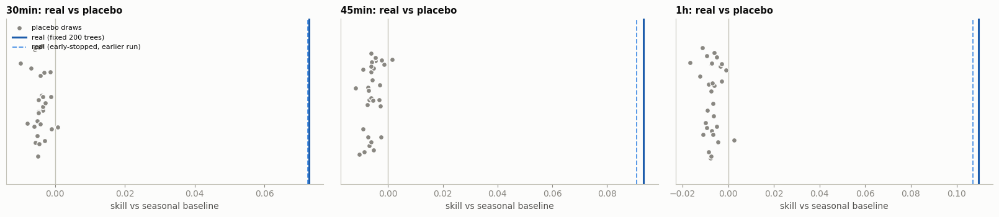

In [24]:
B = 30                                    # placebo draws; p-value floor = 1/(B+1)
RUN_H = ["30min", "45min", "1h"]          # drop horizons to save time
HIST = [k for k, c in enumerate(EXT_COLS) if c not in ("s1", "c1", "s2", "c2", "tod")]   # every feature except time of day

def fit_fix(Xt, dt, seed=0, n_trees=200):
    return lgb.LGBMRegressor(objective="regression", learning_rate=0.03, num_leaves=15, min_child_samples=500, subsample=0.8,
                             subsample_freq=1, colsample_bytree=0.8, reg_lambda=10.0, n_estimators=n_trees, n_jobs=-1,
                             verbose=-1, random_state=seed).fit(Xt, dt)

shifts = np.random.default_rng(12345).integers(20, 151, size=B)          # whole-day shifts, so the time-of-day phase is preserved
res = []
for hn in RUN_H:
    H = HZ[hn]; F = build_feats(y, H); n = len(y); i = np.arange(n - H); j = i + H
    XE = np.column_stack([F[c][i] for c in EXT_COLS]); XA = XE[:, AR_IDX]
    ok = np.isfinite(y[i]) & np.isfinite(y[j]) & ~bad[j] & np.isfinite(XA).all(axis=1)      # same rows as every earlier model
    delta = y[j] - y[i]; tt, ot = dev.index[j], dev.index[i]
    sets = []
    for w in folds:
        tr = ok & ~bad[i] & np.asarray(tt <= w.val_start - EMBt)
        va = ok & np.asarray((ot >= w.val_start) & (tt < w.val_end))
        ref = store[hn][w.name]; assert np.allclose(ref["yt"], y[j][va]), "row mismatch with the LightGBM cell"
        sets.append((tr, va, ref))
    yt_all = np.concatenate([s[2]["yt"] for s in sets]); y0_all = np.concatenate([s[2]["y0"] for s in sets])
    seas = np.concatenate([s[2]["preds"]["seasonal"] for s in sets])
    d_all = yt_all - y0_all; den = ((d_all - d_all.mean()) ** 2).sum(); sse_seas = ((yt_all - seas) ** 2).sum()
    for dr in range(B + 1):                                                                   # draw 0 = real features, 1..B = placebo
        k_days = 0 if dr == 0 else int(shifts[dr - 1])
        XP = XE.copy()
        if k_days: XP[:, HIST] = np.roll(XE[:, HIST], k_days * 288, axis=0)                   # history taken from another day
        pred = np.concatenate([ref["y0"] + fit_fix(XP[tr], delta[tr]).predict(XP[va]) for tr, va, ref in sets])
        sse = ((yt_all - pred) ** 2).sum()
        res.append(dict(H=hn, draw=dr, kind="real" if dr == 0 else "placebo", shift_days=k_days,
                        skill_vs_seasonal=1 - sse / sse_seas, r2_delta=1 - sse / den))
        if dr % 5 == 0: print(f"{hn} draw {dr:2d} ({'real' if dr == 0 else str(k_days) + 'd shift'}): skill vs seasonal {res[-1]['skill_vs_seasonal']:.4f}")

R = pd.DataFrame(res); rows = []
for hn in RUN_H:
    r = R[(R.H == hn) & (R.draw == 0)].iloc[0]; p = R[(R.H == hn) & (R.draw > 0)]; pm, ps = p.skill_vs_seasonal.mean(), p.skill_vs_seasonal.std(ddof=1)
    rows.append(dict(H=hn, real_skill=r.skill_vs_seasonal, placebo_mean=pm, placebo_sd=ps, placebo_max=p.skill_vs_seasonal.max(),
                     z=(r.skill_vs_seasonal - pm) / ps, p_value=(1 + (p.skill_vs_seasonal >= r.skill_vs_seasonal).sum()) / (len(p) + 1),
                     real_r2_delta=r.r2_delta, placebo_r2_delta_mean=p.r2_delta.mean(), placebo_r2_delta_max=p.r2_delta.max()))
summary = pd.DataFrame(rows).set_index("H"); pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:.4f}".format)
print("\nPlacebo test: skill vs the seasonal baseline (fixed 200 trees, same config for real and placebo)"); print(summary)
R.to_csv(RUN / "reports" / "lgbm_placebo_draws.csv", index=False); summary.to_csv(RUN / "reports" / "lgbm_placebo.csv")

ref_es = {"30min": 0.0724, "45min": 0.0907, "1h": 0.1072}                  # earlier early-stopped lgb_ext, for reference
fig, axes = plt.subplots(1, len(RUN_H), figsize=(5.4 * len(RUN_H), 3.6), sharey=True)
axes = np.atleast_1d(axes); jr = np.random.default_rng(1)
for ax, hn in zip(axes, RUN_H):
    p = R[(R.H == hn) & (R.draw > 0)].skill_vs_seasonal.to_numpy(); r = R[(R.H == hn) & (R.draw == 0)].skill_vs_seasonal.iloc[0]
    ax.scatter(p, jr.uniform(0.15, 0.85, len(p)), s=34, color=MUTED, edgecolor=SURF, linewidth=1, zorder=3, label="placebo draws")
    ax.axvline(r, color=RAMP[3], lw=2.2, label="real (fixed 200 trees)")
    ax.axvline(ref_es[hn], color=RAMP[1], lw=1.4, ls="--", label="real (early-stopped, earlier run)")
    ax.axvline(0, color=AXIS, lw=1); ax.set_yticks([]); ax.set_ylim(0, 1); ax.grid(False)
    ax.set_xlabel("skill vs seasonal baseline"); ax.set_title(f"{hn}: real vs placebo")
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(RUN / "figs" / "lgbm_placebo.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output**

| Horizon | real skill vs seasonal | placebo mean ± sd | placebo max | $z$ | $p$ |
|---|---|---|---|---|---|
| 30 min | **+0.0728** | −0.0044 ± 0.0021 | +0.0008 | **37.0** | 0.0323 |
| 45 min | **+0.0934** | −0.0058 ± 0.0028 | +0.0015 | **35.5** | 0.0323 |
| 1 h | **+0.1096** | −0.0071 ± 0.0036 | +0.0025 | **32.2** | 0.0323 |

With scrambled history the model's skill over the seasonal baseline **falls to slightly below zero**; the real model is **32–37 standard deviations above** the placebo distribution.
The $R^2_\Delta$ columns say the same thing in another way: with scrambled history the model still gets $R^2_\Delta=0.071 / 0.108 / 0.144$ (that is exactly what the clock alone provides, close to the seasonal baseline 0.075 / 0.113 / 0.150); the real model gets 0.142 / 0.196 / 0.243. So **recent history adds about 0.071 / 0.088 / 0.099 of $R^2_\Delta$ on top of time of day**, and that part is genuine.

## 7.6 What does the target look like? Distribution of log changes

📘 **What.** Descriptive statistics of $\Delta_t^H$ on the scored rows of the development period, with a 95 % bootstrap interval on kurtosis, a comparison against the normal law, the effect of the quality mask, and the effect of removing the time-of-day mean, plus kurtosis and skew by fold.

📐 **Measures.** Excess kurtosis $\kappa_4=\dfrac{\mu_4}{\sigma^4}-3$ (0 for a normal); skew $\mu_3/\sigma^3$; `sd_over_madsigma` $=\dfrac{\text{sd}}{1.4826\,\text{MAD}}$ (1 for a normal; large when a few huge values inflate the sd); a tail-to-core ratio $\dfrac{q_{0.975}-q_{0.025}}{q_{0.75}-q_{0.25}}$ (2.91 for a normal; the notebook calls it `cs_ratio`).

Log change distribution, scored rows, dev period (normal: skew 0, excess kurtosis 0, sd/MAD-sigma 1, CS ratio 2.91, |z|>3 0.27%, |z|>5 0.00006%)
H                             30min       45min          1h
n                       103084.0000 103048.0000 103012.0000
mean                        -0.0002     -0.0004     -0.0005
sd                           0.3232      0.3947      0.4561
mad_sigma                    0.1684      0.2228      0.2741
sd_over_madsigma             1.9190      1.7721      1.6637
skew                         0.9534      0.6955      0.4212
excess_kurt                 25.9616     18.6704     14.1221
pearson_kurt                28.9616     21.6704     17.1221
cs_ratio                     5.2494      5.0390      4.7966
pct_abs_z_gt3                2.0149      2.0049      2.0677
pct_abs_z_gt5                0.6073      0.5561      0.5194
kurt_ci_lo                  20.9649     14.8641     11.2875
kurt_ci_hi                  30.6534     22.1488     16.7331
excess_kurt_no_

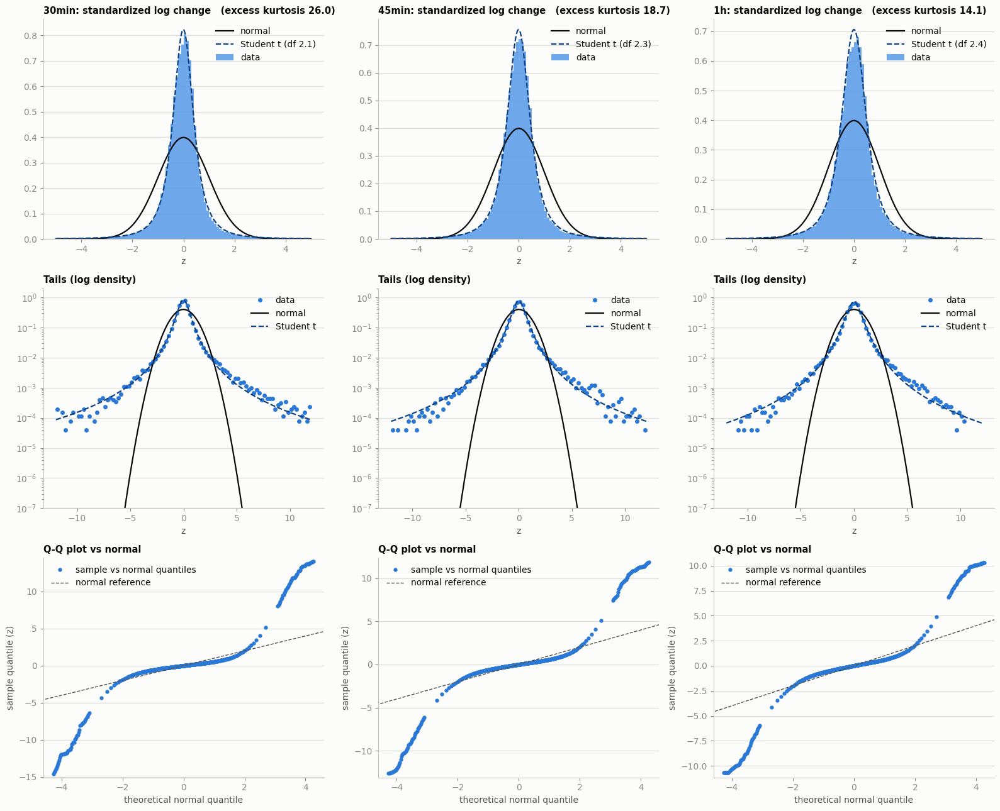

In [25]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()
assert dev.index.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
for sub in ("reports", "figs"): (RUN / sub).mkdir(exist_ok=True)
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "legend.frameon": False})

HZ = {"30min": 6, "45min": 9, "1h": 12}
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy(); n = len(y)
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy()
tod = np.asarray((dev.index.hour * 60 + dev.index.minute - 5) % 1440)

def describe(d):
    q = np.percentile(d, [2.5, 97.5, 25, 75]); z = (d - d.mean()) / d.std(); mad_sigma = 1.4826 * np.median(np.abs(d - np.median(d)))
    return dict(n=len(d), mean=d.mean(), sd=d.std(), mad_sigma=mad_sigma, sd_over_madsigma=d.std() / mad_sigma,
                skew=stats.skew(d), excess_kurt=stats.kurtosis(d), pearson_kurt=stats.kurtosis(d) + 3,
                cs_ratio=(q[1] - q[0]) / (q[3] - q[2]),                                   # Crow-Siddiqui robust tail ratio, normal = 2.91
                pct_abs_z_gt3=100 * (np.abs(z) > 3).mean(), pct_abs_z_gt5=100 * (np.abs(z) > 5).mean())

def boot_kurt(d, day, B=2000, seed=0):                                                  # day-block bootstrap of excess kurtosis via per-day moment sums
    S = pd.DataFrame({"s1": d, "s2": d ** 2, "s3": d ** 3, "s4": d ** 4, "c": 1.0}).groupby(day.values).sum().to_numpy()
    T = S[np.random.default_rng(seed).integers(0, len(S), size=(B, len(S)))].sum(axis=1); nn = T[:, 4]
    m1 = T[:, 0] / nn; m2 = T[:, 1] / nn - m1 ** 2
    m4 = T[:, 3] / nn - 4 * m1 * T[:, 2] / nn + 6 * m1 ** 2 * T[:, 1] / nn - 3 * m1 ** 4
    return np.percentile(m4 / m2 ** 2 - 3, [2.5, 97.5])

rows, rfold, Z = [], [], {}
for hn, H in HZ.items():
    i = np.arange(n - H); j = i + H
    fin = np.isfinite(y[i]) & np.isfinite(y[j]); ok = fin & ~bad[i] & ~bad[j]
    d_all = y[j] - y[i]; d = d_all[ok]; day = dev.index[i][ok].normalize()
    sbin = tod[i][ok] // 30; d_ds = d - pd.Series(d).groupby(sbin).transform("mean").to_numpy()   # time-of-day mean removed (descriptive)
    lo, hi = boot_kurt(d, day)
    rows.append(dict(H=hn, **describe(d), kurt_ci_lo=lo, kurt_ci_hi=hi, excess_kurt_no_qc_mask=stats.kurtosis(d_all[fin]),
                     n_no_qc_mask=fin.sum(), excess_kurt_tod_removed=stats.kurtosis(d_ds)))
    tt, ot = dev.index[j], dev.index[i]
    for w in folds:
        va = ok & np.asarray((ot >= w.val_start) & (tt < w.val_end))
        rfold.append(dict(H=hn, fold=w.name, n=va.sum(), sd=d_all[va].std(), skew=stats.skew(d_all[va]), excess_kurt=stats.kurtosis(d_all[va])))
    Z[hn] = (d - d.mean()) / d.std()

T = pd.DataFrame(rows).set_index("H"); F = pd.DataFrame(rfold)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:.4f}".format)
print("Log change distribution, scored rows, dev period (normal: skew 0, excess kurtosis 0, sd/MAD-sigma 1, CS ratio 2.91, |z|>3 0.27%, |z|>5 0.00006%)")
print(T.T)
print("\nexcess kurtosis per validation fold"); print(F.pivot_table(index="H", columns="fold", values="excess_kurt").reindex(list(HZ)))
print("\nskew per validation fold"); print(F.pivot_table(index="H", columns="fold", values="skew").reindex(list(HZ)))
T.to_csv(RUN / "reports" / "log_change_distribution.csv"); F.to_csv(RUN / "reports" / "log_change_distribution_per_fold.csv", index=False)

# ---------------- figure: histogram, log-density, QQ
fig, ax = plt.subplots(3, 3, figsize=(16, 13))
p = np.unique(np.r_[np.linspace(0.001, 0.999, 400), np.logspace(-5, -3, 50), 1 - np.logspace(-5, -3, 50)])
for c, (hn, z) in enumerate(Z.items()):
    dfree, tloc, tscale = stats.t.fit(z); k = T.loc[hn, "excess_kurt"]
    a = ax[0, c]; h, ed = np.histogram(z, bins=np.linspace(-5, 5, 101), density=True); mid = 0.5 * (ed[1:] + ed[:-1])
    a.bar(mid, h, width=ed[1] - ed[0], color=RAMP[1], alpha=0.85, label="data")
    xg = np.linspace(-5, 5, 500); a.plot(xg, stats.norm.pdf(xg), color=INK, lw=1.6, label="normal")
    a.plot(xg, stats.t.pdf(xg, dfree, tloc, tscale), color=RAMP[4], lw=1.6, ls="--", label=f"Student t (df {dfree:.1f})")
    a.set_title(f"{hn}: standardized log change   (excess kurtosis {k:.1f})"); a.set_xlabel("z"); a.legend()
    a = ax[1, c]; h, ed = np.histogram(z, bins=np.linspace(-12, 12, 97), density=True); mid = 0.5 * (ed[1:] + ed[:-1])
    a.plot(mid[h > 0], h[h > 0], "o", ms=4, color=RAMP[2], label="data")
    xg = np.linspace(-12, 12, 600); a.plot(xg, stats.norm.pdf(xg), color=INK, lw=1.6, label="normal")
    a.plot(xg, stats.t.pdf(xg, dfree, tloc, tscale), color=RAMP[4], lw=1.6, ls="--", label="Student t")
    a.set_yscale("log"); a.set_ylim(1e-7, 2); a.set_xlabel("z"); a.set_title("Tails (log density)"); a.legend()
    a = ax[2, c]; tq = stats.norm.ppf(p); sq = np.quantile(z, p)
    a.plot(tq, sq, "o", ms=3.5, color=RAMP[2], label="sample vs normal quantiles"); lim = [-6, 6]
    a.plot(lim, lim, color=INK2, lw=1, ls="--", label="normal reference"); a.set_xlim(-4.6, 4.6); a.set_ylim(sq.min() - 0.5, sq.max() + 0.5)
    a.set_xlabel("theoretical normal quantile"); a.set_ylabel("sample quantile (z)"); a.set_title("Q-Q plot vs normal"); a.legend(loc="upper left")
fig.tight_layout(); fig.savefig(RUN / "figs" / "log_change_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output** (n ≈ 103,000 per horizon)

| | 30 min | 45 min | 1 h | Normal |
|---|---|---|---|---|
| sd | 0.323 | 0.395 | 0.456 | |
| MAD-sigma | 0.168 | 0.223 | 0.274 | |
| **sd / MAD-sigma** | **1.92** | 1.77 | 1.66 | 1 |
| skew | **+0.95** | +0.70 | +0.42 | 0 |
| **excess kurtosis** | **26.0** (CI 21.0–30.7) | 18.7 (14.9–22.1) | 14.1 (11.3–16.7) | 0 |
| share with $\lvert z\rvert>3$ | 2.01 % | 2.00 % | 2.07 % | 0.27 % |
| share with $\lvert z\rvert>5$ | **0.61 %** | 0.56 % | 0.52 % | 0.00006 % |
| tail-to-core ratio (`cs_ratio`) | 5.25 | 5.04 | 4.80 | 2.91 |

* The distribution is **extremely heavy-tailed**: 0.6 % of changes are beyond 5 standard deviations, about 10,000 times more often than a Gaussian would allow. The tails **thin with the horizon** (kurtosis 26 → 14) as the central limit effect starts to bite.
* **Positive skew:** big rises are more extreme than big falls.
* **The quality mask matters:** without it the 30-min kurtosis is 31.4 (vs 26.0). This is disclosed as a protocol amendment.
* **By fold** (30 min) kurtosis ranges 15.9–25.5 and skew **flips sign** between cv2 (−0.81) and cv4 (+1.96).

✅ **Take-away.** A Gaussian band around a point forecast would be badly wrong. This is why the variance track uses a **Student-t** with free degrees of freedom, and why the probabilistic bands are checked and recalibrated empirically.

## 7.7 Volatility clustering: autocorrelation of $|\Delta|$

📘 **What.** The ACF and PACF of the **absolute change** $|\Delta|$ (non-overlapping series), raw and **deseasonalised** (the time-of-day mean of $|\Delta|$ removed), at 5 min, 30 min, 45 min and 1 h, next to the ordinary signed ACF. Also the first lag at which the ACF falls below 0.1 and the decay exponent $\alpha$ of the ACF between 1 h and 1 day,
$$\rho_{|\Delta|}(k)\propto k^{-\alpha}.$$

🎯 **Why.** This is the classical *stylised fact* test that justifies GARCH: **returns themselves are uncorrelated, but their sizes are strongly correlated**.

done 5 min
done 30 min
done 45 min
done 1 h

ACF of |log change| at selected lags (non-overlapping series; deseason = time-of-day mean removed; signed = ordinary change)
                    lag_steps  acf_raw  acf_deseason  acf_signed
series lag_minutes                                              
5 min  5                    1   0.4002        0.3833      0.0565
       30                   6   0.2536        0.2241     -0.0149
       60                  12   0.2177        0.1908      0.0050
       360                 72   0.0741        0.0856     -0.0032
       720                144   0.0247        0.0688     -0.0164
       1440               288   0.0804        0.0537      0.0254
       2880               576   0.0480        0.0185      0.0203
       4320               864   0.0252       -0.0056      0.0139
30 min 30                   1   0.3754        0.3350     -0.0025
       60                   2   0.3100        0.2875      0.0126
       90                   3   0.2693        0.24

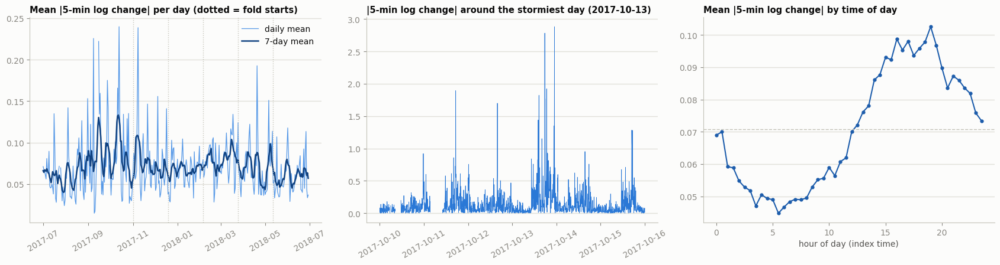

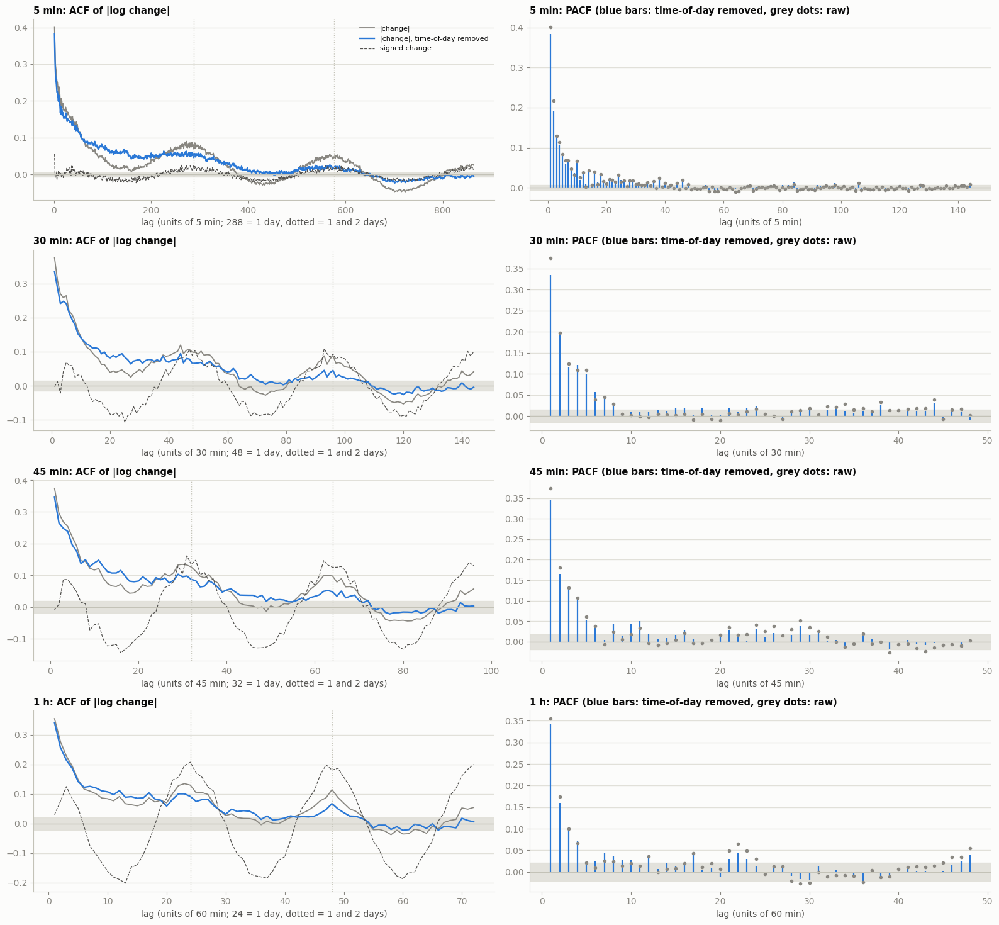

In [27]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()
assert dev.index.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
for sub in ("reports", "figs"): (RUN / sub).mkdir(exist_ok=True)
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "legend.frameon": False})

y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy(); n = len(y); idx = dev.index
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy()
yb = y.copy(); yb[bad] = np.nan                                         # flagged / missing points become gaps, never filled

def acf_nan(x, lags):                                                   # pairwise ACF, gaps (NaN) are skipped
    a = x - np.nanmean(x); out = []
    for k in lags:
        u, v = a[:-k], a[k:]; m = np.isfinite(u) & np.isfinite(v)
        out.append((u[m] * v[m]).sum() / np.sqrt((u[m] ** 2).sum() * (v[m] ** 2).sum()))
    return np.array(out)

def pacf_from_acf(r):                                                   # Levinson-Durbin; r[0] = 1
    K = len(r) - 1; phi = np.zeros((K + 1, K + 1)); pac = np.full(K + 1, np.nan); pac[0] = 1.0
    phi[1, 1] = r[1]; pac[1] = r[1]; v = 1 - r[1] ** 2
    for k in range(2, K + 1):
        if v <= 1e-9: break
        phi[k, k] = (r[k] - (phi[k - 1, 1:k] * r[k - 1:0:-1]).sum()) / v
        phi[k, 1:k] = phi[k - 1, 1:k] - phi[k, k] * phi[k - 1, k - 1:0:-1]
        v *= 1 - phi[k, k] ** 2; pac[k] = phi[k, k]
    return pac

SER = {"5 min": 1, "30 min": 6, "45 min": 9, "1 h": 12}
res = {}
for name, step in SER.items():
    ends = np.arange(step, n, step)                                     # non-overlapping changes over `step` 5-min steps
    d = yb[ends] - yb[ends - step]; mag = np.abs(d)
    tbin = (idx[ends].hour * 2 + idx[ends].minute // 30).to_numpy()
    seas = pd.Series(mag).groupby(tbin).transform("mean").to_numpy(); magds = mag / seas      # time-of-day mean of the magnitude removed
    K = 3 * 288 // step; Kp = 144 if step == 1 else 48; lg = np.arange(1, K + 1)
    r_raw, r_ds, r_sg = acf_nan(mag, lg), acf_nan(magds, lg), acf_nan(d, lg)
    res[name] = dict(step=step, ends=ends, mag=mag, lg=lg, r_raw=r_raw, r_ds=r_ds, r_sg=r_sg, n_eff=int(np.isfinite(mag).sum()),
                     p_raw=pacf_from_acf(np.r_[1.0, r_raw[:Kp]])[1:], p_ds=pacf_from_acf(np.r_[1.0, r_ds[:Kp]])[1:])
    print("done", name)

# ---------------- tables
rows, summ = [], []
for name, R in res.items():
    step = R["step"]; lgs = [1, 6, 12, 72, 144, 288, 576, 864] if step == 1 else [1, 2, 3, 288 // step, 2 * 288 // step]
    for L in lgs:
        rows.append(dict(series=name, lag_minutes=L * 5 * step, lag_steps=L, acf_raw=R["r_raw"][L - 1], acf_deseason=R["r_ds"][L - 1], acf_signed=R["r_sg"][L - 1]))
    below = np.where(R["r_ds"] < 0.1)[0]
    s = dict(series=name, n=R["n_eff"], mean_abs_change=np.nanmean(R["mag"]),
             first_lag_below_0p1_minutes=(below[0] + 1) * 5 * step if len(below) else np.nan,
             pacf1_deseason=R["p_ds"][0], pacf2_deseason=R["p_ds"][1], pacf3_deseason=R["p_ds"][2])
    if step == 1:                                                       # hyperbolic decay exponent: acf ~ lag^-alpha over 1 h .. 1 day
        mk = (R["lg"] >= 12) & (R["lg"] <= 288) & (R["r_ds"] > 0)
        s["decay_alpha_1h_to_1d"] = -np.polyfit(np.log(R["lg"][mk]), np.log(R["r_ds"][mk]), 1)[0]
    summ.append(s)
pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:.4f}".format)
TA, SU = pd.DataFrame(rows), pd.DataFrame(summ).set_index("series")
print("\nACF of |log change| at selected lags (non-overlapping series; deseason = time-of-day mean removed; signed = ordinary change)")
print(TA.set_index(["series", "lag_minutes"]))
print("\nsummary"); print(SU.T)
TA.to_csv(RUN / "reports" / "abs_change_acf_table.csv", index=False); SU.to_csv(RUN / "reports" / "abs_change_acf_summary.csv")

# ---------------- figure 1: the magnitude series
m1 = pd.Series(res["5 min"]["mag"], index=idx[res["5 min"]["ends"]])
fig1, ax = plt.subplots(1, 3, figsize=(17, 4.6))
dmean = m1.resample("D").mean()
ax[0].plot(dmean.index, dmean.values, color=RAMP[1], lw=0.9, label="daily mean"); ax[0].plot(dmean.rolling(7, center=True, min_periods=3).mean(), color=RAMP[4], lw=1.8, label="7-day mean")
for w in folds: ax[0].axvline(w.val_start, color=AXIS, lw=1, ls=":")
ax[0].set_title("Mean |5-min log change| per day (dotted = fold starts)"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)
d0 = dmean.idxmax(); sl = m1.loc[d0 - pd.Timedelta(days=3): d0 + pd.Timedelta(days=3)]
ax[1].plot(sl.index, sl.values, color=RAMP[2], lw=0.6); ax[1].set_title(f"|5-min log change| around the stormiest day ({d0.date()})"); ax[1].tick_params(axis="x", rotation=30)
prof = m1.groupby(m1.index.hour * 2 + m1.index.minute // 30).mean()
ax[2].plot(prof.index / 2, prof.values, "-o", ms=3.5, color=RAMP[3]); ax[2].axhline(m1.mean(), color=AXIS, lw=1, ls="--")
ax[2].set_xlabel("hour of day (index time)"); ax[2].set_title("Mean |5-min log change| by time of day")
fig1.tight_layout(); fig1.savefig(RUN / "figs" / "abs_change_series.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------------- figure 2: ACF and PACF of the magnitude
fig2, ax = plt.subplots(len(SER), 2, figsize=(16, 3.7 * len(SER)))
for r, (name, R) in enumerate(res.items()):
    step = R["step"]; band = 1.96 / np.sqrt(R["n_eff"]); day = 288 // step
    a = ax[r, 0]; lg = R["lg"]
    a.axhspan(-band, band, color=GRID, alpha=0.9, zorder=0)
    a.plot(lg, R["r_raw"], color=MUTED, lw=1.3, label="|change|"); a.plot(lg, R["r_ds"], color=RAMP[2], lw=1.7, label="|change|, time-of-day removed")
    a.plot(lg, R["r_sg"], color=INK2, lw=0.9, ls="--", label="signed change")
    for k in (1, 2): a.axvline(k * day, color=AXIS, lw=1, ls=":")
    a.axhline(0, color=AXIS, lw=1); a.set_xlabel(f"lag (units of {5 * step} min; {day} = 1 day, dotted = 1 and 2 days)"); a.set_title(f"{name}: ACF of |log change|")
    b = ax[r, 1]; lp = np.arange(1, len(R["p_ds"]) + 1)
    b.axhspan(-band, band, color=GRID, alpha=0.9, zorder=0); b.vlines(lp, 0, R["p_ds"], color=RAMP[2], lw=1.6)
    b.plot(lp, R["p_raw"], "o", ms=3, color=MUTED); b.axhline(0, color=AXIS, lw=1)
    b.set_xlabel(f"lag (units of {5 * step} min)"); b.set_title(f"{name}: PACF (blue bars: time-of-day removed, grey dots: raw)")
ax[0, 0].legend(fontsize=8)
fig2.tight_layout(); fig2.savefig(RUN / "figs" / "abs_change_acf_pacf.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output**

| | 5 min | 30 min | 45 min | 1 h |
|---|---|---|---|---|
| ACF of $\lvert\Delta\rvert$ at lag 1 (raw) | **0.400** | 0.375 | 0.375 | 0.355 |
| ACF of $\lvert\Delta\rvert$ at lag 1 (deseasonalised) | 0.383 | 0.335 | 0.346 | 0.342 |
| signed ACF at lag 1 | 0.057 | −0.003 | −0.009 | 0.030 |
| first lag with ACF < 0.1 | 285 min | 510 min | 765 min | 660 min |
| signed ACF at **1 day** | 0.025 | 0.089 | **0.134** | **0.208** |

* Signed changes are almost uncorrelated at short lags (≈ 0), but **absolute changes are correlated at 0.34–0.40 at lag 1** and take **5 to 13 hours** to decay below 0.1. Removing the time-of-day mean barely changes this: the clustering is **not just the daily rhythm**. PACF values 0.38 / 0.19 / 0.12 (5 min) show more than one lag matters.
* The decay exponent between 1 h and 1 d is $\alpha\approx0.47$ (5 min): slow, hyperbolic decay, the signature of long memory in volatility.
* The signed 1-day autocorrelation **grows with the horizon** (0.025 → 0.089 → 0.134 → 0.208), the same effect that made the 24 h lag so important for the AR.

## 7.8 The blend and its tests

📘 **What.** The recommended point forecast is an **equal-weight average of the two LightGBM variants**:
$$\hat y^{\text{blend}}_{t+H}=0.5\,\hat y^{\text{lgb\_ext}}_{t+H}+0.5\,\hat y^{\text{lgb\_ext\_huber}}_{t+H}.$$
Both forecasts start from the same $y_t$, so this equals averaging the predicted *changes*. The weight 0.5 is set by design (the code comment says "fixed in advance, never tuned"), and the **weight sweep at the end is descriptive only**.

🎯 **Why average?** The two members err in opposite directions in scale (calibration slope 0.94 for squared loss, 1.15 for Huber), and have different tail behaviour; averaging two models with partly independent errors reduces variance. The cell tests whether the blend beats **each member** and the AR, with the same DM test and bootstrap as before.

📐 **Bootstrap of the gain.** $\Delta R^2=R^2_\Delta(\text{blend})-R^2_\Delta(\text{other})$ with day-block resampling; the column `share_boot_le_0` is the share of resamples with no gain.


r2_delta (pooled over the 5 folds)
H              30min  45min     1h
model                             
seasonal      0.0749 0.1130 0.1500
ar_final      0.1060 0.1547 0.1997
lgb_ext       0.1419 0.1935 0.2412
lgb_ext_huber 0.1452 0.1920 0.2359
blend         0.1494 0.2004 0.2458

r2_log (pooled over the 5 folds)
H              30min  45min     1h
model                             
seasonal      0.9695 0.9561 0.9435
ar_final      0.9705 0.9581 0.9468
lgb_ext       0.9717 0.9601 0.9495
lgb_ext_huber 0.9718 0.9600 0.9492
blend         0.9720 0.9604 0.9498

r2_raw (pooled over the 5 folds)
H              30min  45min     1h
model                             
seasonal      0.9665 0.9503 0.9346
ar_final      0.9661 0.9497 0.9343
lgb_ext       0.9704 0.9570 0.9446
lgb_ext_huber 0.9705 0.9576 0.9442
blend         0.9706 0.9576 0.9449

mae_skill_vs_persist (pooled over the 5 folds)
H              30min  45min     1h
model                             
seasonal      0.0762 0.1052 0.1299
ar_final

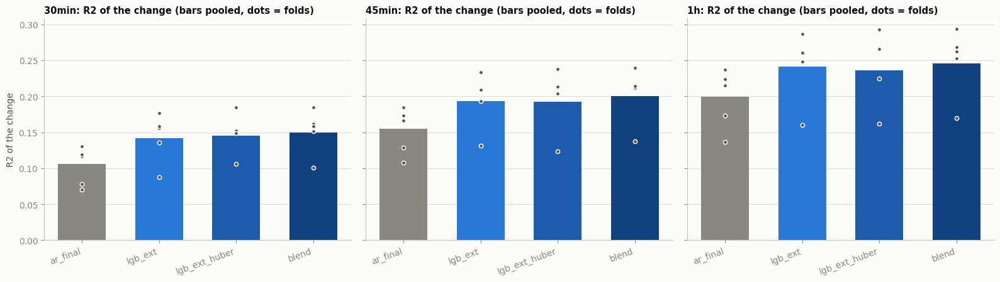

In [1]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds(); idx = dev.index
assert idx.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
for sub in ("preds", "reports", "figs"): (RUN / sub).mkdir(exist_ok=True)
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "legend.frameon": False})

W = 0.5                                                  # blend weight on lgb_ext, fixed in advance, never tuned
Z = np.load(RUN / "preds" / "lgbm.npz")
HZ = {"30min": 6, "45min": 9, "1h": 12}; FN = [w.name for w in folds]
MODELS = ["seasonal", "ar_final", "lgb_ext", "lgb_ext_huber", "blend"]

def load(hn):
    ln = [len(Z[f"{hn}_{f}_pos"]) for f in FN]
    pos = np.concatenate([Z[f"{hn}_{f}_pos"] for f in FN]); yt = np.concatenate([Z[f"{hn}_{f}_y"] for f in FN])
    pr = {m: np.concatenate([Z[f"{hn}_{f}_{m}"] for f in FN]) for m in ("persist", "seasonal", "ar_final", "lgb_ext", "lgb_ext_huber")}
    pr["blend"] = W * pr["lgb_ext"] + (1 - W) * pr["lgb_ext_huber"]            # same origin level, so this equals averaging the predicted changes
    return pos, yt, np.repeat(FN, ln), pr

def stats_(yt, yp, y0):
    e = yt - yp; d = yt - y0; rt, rp = np.exp(yt), np.exp(yp)
    return dict(r2_delta=1 - (e ** 2).sum() / ((d - d.mean()) ** 2).sum(), r2_log=1 - (e ** 2).sum() / ((yt - yt.mean()) ** 2).sum(),
                r2_raw=1 - ((rt - rp) ** 2).sum() / ((rt - rt.mean()) ** 2).sum(), mse_log=(e ** 2).mean(), mae_log=np.abs(e).mean(),
                bias=e.mean(), ex_kurt=stats.kurtosis(e))

def dm(lb, lm, L=288):                                   # positive = second model better
    d = lb - lm; return float(sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": L}).tvalues[0])

rows, pf, dmr, btr, cal, sweep, SAVE = [], [], [], [], [], [], {}
rng = np.random.default_rng(0)
for hn in HZ:
    pos, yt, fold, pr = load(hn); y0 = pr["persist"]; ad = yt - y0; day = idx[pos].normalize().values
    mae_p = np.abs(ad).mean(); sse = {m: ((yt - pr[m]) ** 2).sum() for m in MODELS}
    for m in MODELS:                                                              # pooled table
        s = stats_(yt, pr[m], y0)
        rows.append(dict(H=hn, model=m, **s, mae_skill_vs_persist=1 - s["mae_log"] / mae_p, skill_vs_seasonal=1 - sse[m] / sse["seasonal"],
                         skill_vs_ar=1 - sse[m] / sse["ar_final"], skill_vs_lgb_ext=1 - sse[m] / sse["lgb_ext"], skill_vs_huber=1 - sse[m] / sse["lgb_ext_huber"]))
    for f in FN:                                                                  # per fold R2 of the change
        mk = fold == f
        for m in MODELS: pf.append(dict(H=hn, fold=f, model=m, r2_delta=stats_(yt[mk], pr[m][mk], y0[mk])["r2_delta"]))
        SAVE[f"{hn}_{f}_blend"] = pr["blend"][mk]; SAVE[f"{hn}_{f}_y"] = yt[mk]; SAVE[f"{hn}_{f}_pos"] = pos[mk]
    for other in ("lgb_ext", "lgb_ext_huber", "ar_final"):                        # Diebold-Mariano: positive = blend better
        row = dict(H=hn, blend_vs=other)
        for scope in ["pooled", *FN]:
            mk = np.ones(len(yt), bool) if scope == "pooled" else fold == scope
            row[scope] = dm((yt[mk] - pr[other][mk]) ** 2, (yt[mk] - pr["blend"][mk]) ** 2)
        dmr.append(row)
    D = pd.DataFrame({"b": (yt - pr["blend"]) ** 2, "x1": (yt - pr["lgb_ext"]) ** 2, "x2": (yt - pr["lgb_ext_huber"]) ** 2,
                      "x3": (yt - pr["ar_final"]) ** 2, "dn": (ad - ad.mean()) ** 2, "day": day}).groupby("day").sum()      # day-block bootstrap
    A = D.to_numpy(); col = {c: k for k, c in enumerate(D.columns)}
    Tb = A[rng.integers(0, len(A), size=(2000, len(A)))].sum(axis=1)
    for name, c in (("lgb_ext", "x1"), ("lgb_ext_huber", "x2"), ("ar_final", "x3")):
        boot = (Tb[:, col[c]] - Tb[:, col["b"]]) / Tb[:, col["dn"]]
        btr.append(dict(H=hn, blend_minus=name, delta_r2=(A[:, col[c]].sum() - A[:, col["b"]].sum()) / A[:, col["dn"]].sum(),
                        lo95=np.percentile(boot, 2.5), hi95=np.percentile(boot, 97.5), share_boot_le_0=(boot <= 0).mean()))
    for m in ("lgb_ext", "lgb_ext_huber", "blend"):                               # calibration slope of actual change on predicted change
        pdl = pr[m] - y0
        for scope in ["pooled", *FN]:
            mk = np.ones(len(ad), bool) if scope == "pooled" else fold == scope
            r = sm.OLS(ad[mk], sm.add_constant(pdl[mk])).fit(cov_type="HAC", cov_kwds={"maxlags": 288})
            cal.append(dict(H=hn, model=m, scope=scope, slope=r.params[1], t_vs_1=(r.params[1] - 1) / r.bse[1]))
    for w in np.linspace(0, 1, 11):                                               # descriptive only, 0.5 stays the pre-declared weight
        s = stats_(yt, w * pr["lgb_ext"] + (1 - w) * pr["lgb_ext_huber"], y0)
        sweep.append(dict(H=hn, w_on_lgb_ext=round(w, 1), r2_delta=s["r2_delta"], mae_skill=1 - s["mae_log"] / mae_p))
np.savez_compressed(RUN / "preds" / "lgbm_blend.npz", **SAVE)

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:.4f}".format)
T, PF, DM, BT, CA, SW = (pd.DataFrame(x) for x in (rows, pf, dmr, btr, cal, sweep))
for c in ("r2_delta", "r2_log", "r2_raw", "mae_skill_vs_persist", "mse_log", "bias", "ex_kurt"):
    print(f"\n{c} (pooled over the 5 folds)"); print(T.pivot(index="model", columns="H", values=c).reindex(MODELS)[list(HZ)])
for c in ("skill_vs_lgb_ext", "skill_vs_huber", "skill_vs_ar", "skill_vs_seasonal"):
    print(f"\n{c}"); print(T.pivot(index="model", columns="H", values=c).reindex(MODELS)[list(HZ)])
print("\nR2 of the change per fold"); print(PF.pivot_table(index=["H", "model"], columns="fold", values="r2_delta", sort=False))
print("\nDiebold-Mariano t, blend vs other (positive = blend better; |t| > 2 significant)"); print(DM.set_index(["H", "blend_vs"]))
print("\ngain in R2 of the change, blend minus other, with 95% day-block bootstrap interval"); print(BT.set_index(["H", "blend_minus"]))
print("\ncalibration slope of actual change on predicted change (1 = well scaled)")
print(CA.pivot_table(index=["H", "model"], columns="scope", values="slope", sort=False)[["pooled", *FN]])
print("\nweight sweep (descriptive only; the weight stays 0.5)"); print(SW.pivot(index="w_on_lgb_ext", columns="H", values="r2_delta")[list(HZ)])
T.to_csv(RUN / "reports" / "blend_pooled.csv", index=False); PF.to_csv(RUN / "reports" / "blend_per_fold.csv", index=False)
DM.to_csv(RUN / "reports" / "blend_dm.csv", index=False); BT.to_csv(RUN / "reports" / "blend_bootstrap.csv", index=False)
CA.to_csv(RUN / "reports" / "blend_calibration.csv", index=False); SW.to_csv(RUN / "reports" / "blend_weight_sweep.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
ms = ["ar_final", "lgb_ext", "lgb_ext_huber", "blend"]; colr = dict(zip(ms, [MUTED, RAMP[2], RAMP[3], RAMP[4]]))
for ax, hn in zip(axes, HZ):
    for xi, m in enumerate(ms):
        pv = T[(T.H == hn) & (T.model == m)]["r2_delta"].iloc[0]; fv = PF[(PF.H == hn) & (PF.model == m)]["r2_delta"]
        ax.bar(xi, pv, 0.62, color=colr[m]); ax.plot(np.full(len(fv), xi), fv, "o", ms=4.5, color=INK2, mec=SURF, mew=1.1, zorder=3)
    ax.set_xticks(range(len(ms))); ax.set_xticklabels(ms, rotation=20, ha="right"); ax.set_title(f"{hn}: R2 of the change (bars pooled, dots = folds)")
axes[0].set_ylabel("R2 of the change")
fig.tight_layout(); fig.savefig(RUN / "figs" / "blend_r2_change.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output**

**$R^2_\Delta$ pooled:** blend **0.1494 / 0.2004 / 0.2458** (vs `lgb_ext` 0.1419 / 0.1935 / 0.2412 and Huber 0.1452 / 0.1920 / 0.2359). On the level the blend has $R^2_{\log}=0.9720 / 0.9604 / 0.9498$.

| Blend vs | gain in $R^2_\Delta$ (30 / 45 / 1 h) | 95 % interval excludes 0? | DM $t$ |
|---|---|---|---|
| `lgb_ext` | +0.0074 / +0.0069 / +0.0046 | yes / yes / **no** | 2.76 / 1.99 / 1.18 |
| `lgb_ext_huber` | +0.0042 / +0.0084 / +0.0099 | **no** / yes / yes | 1.47 / 2.39 / 2.41 |
| `ar_final` | **+0.0434 / +0.0456 / +0.0461** | yes (all) | **8.23 / 7.36 / 7.04** |

* The blend's gain over a single LightGBM is **small** (0.4–1.0 points of $R^2_\Delta$) and not always significant. Its robust, consistent edge is over the **AR** (+0.043 to +0.046, all folds positive).
* **Calibration slope of the blend:** 1.07 / 1.04 / 1.05: nearly perfectly scaled.
* **Weight sweep:** the optimum sits at $w\approx0.4$ (30 min), 0.5 (45 min), 0.6 (1 h); $w=0.5$ is within 0.0002 of the best at every horizon, so nothing is lost by fixing it.
* Bias stays below 0.005 in log units. Per-fold $R^2_\Delta$ of the blend is 0.162 / 0.151 / 0.101 / 0.159 / 0.185 at 30 min: **positive and better than the AR in every fold**.
* Because the blend was designed after seeing validation results, it is listed among the protocol disclosures.

---
# Part 8 · The variance track (GARCH family)

> 🎯 **Motivation, in the data's own words.** (i) Residual *squares* are strongly autocorrelated (7.4); (ii) absolute changes cluster for hours (7.7); (iii) the error is 3.6 times larger in the most turbulent quintile than in the calmest (RMSE 0.51 vs 0.14 at 30 min, 6.5). The mean forecast is nearly exhausted, but **how wrong we are likely to be** can still be forecast. That turns a point forecast into a *probabilistic* forecast.

## 8.0 Set-up common to all five steps

**Data on this track.** For a scale $m\in\{6,9,12\}$ steps (30 / 45 / 60 min), take **non-overlapping changes** $d_t=y_t-y_{t-m}$ (sampled every $m$ steps; flagged points are gaps). The intraday **scale** is estimated on **training rows only**,
$$s_b=\frac{1}{|\mathcal T_b|}\sum_{t\in\mathcal T_b}|d_t|\quad(\text{one value for each of the 48 half-hour bins }b),\qquad u_t=\frac{d_t}{s_{b(t)}} .$$
Dividing by $s_b$ removes the *deterministic* time-of-day rhythm of volatility so the GARCH can model the *stochastic* part.

**The model.**
$$u_t=\sigma_t\,z_t,\qquad z_t\overset{iid}{\sim}\text{unit-variance } t_\nu,\qquad
\boxed{\sigma_t^{2}=\omega+\sum_{i=1}^{p}\alpha_i\,\varepsilon_{t-i}^{2}+\gamma\,\varepsilon_{t-1}^{2}\,\mathbb 1[\varepsilon_{t-1}<0]+\sum_{j=1}^{q}\beta_j\,\sigma_{t-j}^{2}}$$
with $\varepsilon_t=u_t$. Reading the terms: $\omega$ is a base level; the **ARCH** terms $\alpha_i$ react to *recent surprises*; the **GARCH** terms $\beta_j$ carry *yesterday's variance* forward; the **GJR** term $\gamma$ adds an extra reaction **after a fall** (a down-move), so the response to a fall is $\alpha_1+\gamma$ and to a rise is $\alpha_1$ (the ratio $1+\gamma/\alpha_1$ is reported below). `GARCH(p,q)` has no $\gamma$; `GJR(p,q)` does.

**Persistence and long-run variance.** Because $\mathbb E[\varepsilon^2\mathbb 1(\varepsilon<0)]=\sigma^2/2$ for symmetric shocks,
$$\rho=\sum_i\alpha_i+\tfrac12\gamma+\sum_j\beta_j,\qquad \text{unconditional variance}=\frac{\omega}{1-\rho}\ \ (\rho<1 \text{ for stationarity}).$$
A value of $\rho$ near 1 means a volatility shock takes a very long time to die out.

**Innovation density** (Student-$t$ rescaled to unit variance, $\nu>2$):
$$\ln f(\varepsilon_t\mid\sigma_t^2,\nu)=\ln\Gamma\!\big(\tfrac{\nu+1}{2}\big)-\ln\Gamma\!\big(\tfrac{\nu}{2}\big)-\tfrac12\ln\!\big(\pi(\nu-2)\big)-\tfrac12\ln\sigma_t^{2}-\tfrac{\nu+1}{2}\ln\!\Big(1+\frac{\varepsilon_t^{2}}{\sigma_t^{2}(\nu-2)}\Big).$$
The **Gaussian** alternative is $-\tfrac12\ln2\pi-\tfrac12\ln\sigma_t^2-\varepsilon_t^2/(2\sigma_t^2)$.

**Estimation and safeguards (all in the code).**
* Maximum likelihood by L-BFGS-B, with several starts (and warm starts from smaller models).
* **Positivity and stationarity are built in:** the coefficients are $\rho\cdot\text{softmax}(\cdot)$ with $\rho=0.9999\cdot\text{logistic}(\theta)$, so they are non-negative and sum to at most $0.9999$ by construction. Also $\nu=2+e^{\theta}$.
* **Gaps:** a missing change is treated as an *expected shock*: it adds no likelihood term and sets $\varepsilon^2:=\sigma^2$, so the recursion carries on without bias.
* Every filter is **causal**: $\sigma_t^2$ uses only data before $t$.
* Everything is fitted on **training rows only** for each of the five windows. `cv1` is "fit once on the earliest training set"; `cv5` is the static split.

**Two schemes.** **refit**: each window uses its own expanding training fit. **frozen**: the cv1 fit is reused for all windows (no refitting).

**Information criteria**, with $k=K+2$ parameters ($K$ = number of ARCH/GJR/GARCH coefficients, plus $\omega$ and $\nu$):
$$\text{AIC}=-2\ell+2k,\qquad \text{BIC}=-2\ell+k\ln N .$$

### Cell 36: install the `arch` package
📘 The package is installed for reference. The fits in the following cells use a **custom numba likelihood** (`_ll`, `_filter`, `_run`) so that gaps, the softmax parametrisation and the Student-t density with free $\nu$ are handled exactly as above and run fast enough for 5 windows × 3 scales × 9 candidate models.

In [2]:
!pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.2 MB/s eta 0:00:0000:01


## 8.1 Step 1: how heavy are the tails? (Student-$t$ fit)

📘 **What.** For four scales (5, 30, 45, 60 min), five training windows and **three versions of the series**, fits a zero-mean Student-$t$ with free degrees of freedom $\nu$ and scale $s$ by maximum likelihood:
$$\ln f(x;\nu,s)=\ln\Gamma\!\big(\tfrac{\nu+1}{2}\big)-\ln\Gamma\!\big(\tfrac{\nu}{2}\big)-\tfrac12\ln(\nu\pi)-\ln s-\tfrac{\nu+1}{2}\ln\!\Big(1+\frac{(x/s)^2}{\nu}\Big).$$
The three series are: **raw** $u_t$; **`std_6h`**, $u_t$ divided by the root of the trailing 6-hour mean of $u^2$ (using data strictly before $t$); and **`std_1d`**, the same with a one-day trailing window. A **day-block bootstrap** gives a 95 % interval for $\nu$; a **profile likelihood** (re-optimising $s$ for each $\nu$) is plotted; and a **tail ratio** compares the fitted $t$ quantile of $|x|$ with the empirical one (1 = perfect match).

🎯 **Why.** $\nu$ decides how heavy the tails are: $\nu\le 2$ means infinite variance, $\nu\le4$ infinite kurtosis. If $\nu\approx2$ on the raw series and rises after standardising by a trailing volatility, then the heavy tails are largely *volatility clustering*, which a variance model can capture.

5 min: done in 70s
30 min: done in 15s
45 min: done in 12s
1 h: done in 10s
window cv1 = fit once on the earliest training set (train-once); cv2..cv5 = expanding; cv5 = the repo's static split

Student-t df [95% day-block bootstrap interval], series = raw
window                cv1                cv2                cv3                cv4                cv5
scale                                                                                                
5 min   1.98 [1.85, 2.15]  2.11 [1.94, 2.30]  2.27 [2.11, 2.45]  2.35 [2.22, 2.57]  2.35 [2.19, 2.56]
30 min  2.01 [1.84, 2.28]  2.13 [1.89, 2.36]  2.28 [2.13, 2.52]  2.28 [2.09, 2.50]  2.31 [2.16, 2.49]
45 min  2.19 [1.93, 2.51]  2.34 [2.11, 2.73]  2.51 [2.26, 2.87]  2.46 [2.23, 2.74]  2.47 [2.26, 2.70]
1 h     2.37 [2.08, 2.71]  2.57 [2.34, 2.86]  2.72 [2.46, 3.05]  2.66 [2.41, 2.95]  2.67 [2.45, 2.95]

Student-t df [95% day-block bootstrap interval], series = std_6h
window                cv1                cv2                cv3   

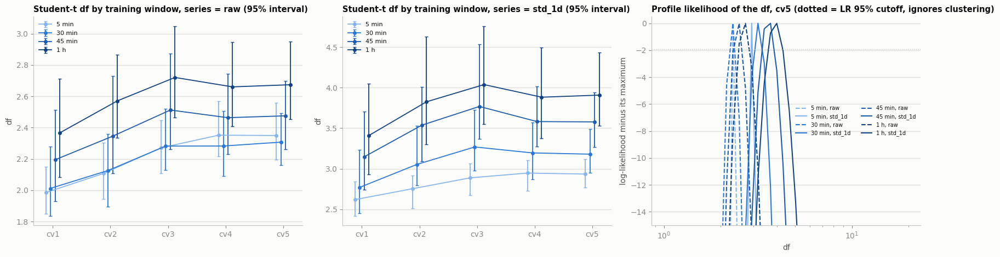

In [5]:
import sys, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from scipy.special import gammaln
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

B = 100                                                  # day-block bootstrap resamples per fit
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds(); idx = dev.index
assert idx.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
for sub in ("reports", "figs"): (RUN / sub).mkdir(exist_ok=True)
EMBt = pd.Timedelta(minutes=5 * P.embargo_steps)
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "legend.frameon": False})

y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy(); n = len(y)
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy()
yb = y.copy(); yb[bad] = np.nan                                           # flagged / missing points are gaps

def t_ll(x, nu, s):                                                       # mean log-density of a Student-t(nu, scale s), location 0
    return (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(nu * np.pi) - np.log(s) - (nu + 1) / 2 * np.log1p((x / s) ** 2 / nu)).mean()

def fit_t(x, x0=None):                                                    # MLE of (df, scale); two starts unless a warm start is given
    s0 = np.median(np.abs(x)) / 0.6745 + 1e-12
    starts = [np.asarray(x0)] if x0 is not None else [np.array([np.log(3.0), np.log(s0)]), np.array([np.log(8.0), np.log(s0)])]
    best = None
    for st in starts:
        r = optimize.minimize(lambda p: -t_ll(x, np.exp(p[0]), np.exp(p[1])), st, method="L-BFGS-B",
                              bounds=[(np.log(0.5), np.log(200.0)), (np.log(s0 * 0.02), np.log(s0 * 50))])
        if best is None or r.fun < best.fun: best = r
    return np.exp(best.x[0]), np.exp(best.x[1]), -best.fun, bool(best.success)

def roll_mean_sq(u, k):                                                   # trailing mean of u^2 over k steps, gaps skipped
    f = np.isfinite(u); s = np.where(f, u * u, 0.0); cs = np.r_[0.0, np.cumsum(s)]; cc = np.r_[0.0, np.cumsum(f)]
    a = np.arange(len(u)); lo = np.maximum(0, a - k + 1); num = cs[a + 1] - cs[lo]; cnt = cc[a + 1] - cc[lo]
    return np.where(cnt >= max(1, k // 2), num / np.maximum(cnt, 1), np.nan)

def boot_df(x, day_codes, x0, rng):                                       # day-block bootstrap interval for the df
    order = np.argsort(day_codes, kind="stable"); xs = x[order]; dc = day_codes[order]
    cuts = np.r_[0, np.flatnonzero(np.diff(dc)) + 1, len(xs)]; segs = [xs[cuts[i]:cuts[i + 1]] for i in range(len(cuts) - 1)]
    out = [fit_t(np.concatenate([segs[k] for k in rng.integers(0, len(segs), len(segs))]), x0=x0)[0] for _ in range(B)]
    return np.percentile(out, [2.5, 97.5])

def profile(x, grid):                                                     # log-likelihood as a function of df, scale re-optimised
    s0 = np.median(np.abs(x)) / 0.6745; out = []
    for nu in grid:
        r = optimize.minimize_scalar(lambda b: -t_ll(x, nu, np.exp(b)), bounds=(np.log(s0 * 0.02), np.log(s0 * 50)), method="bounded")
        out.append(-r.fun * len(x))
    out = np.array(out); return out - out.max()

SCALES = {"5 min": 1, "30 min": 6, "45 min": 9, "1 h": 12}
PROX = {"raw": None, "std_6h": 360, "std_1d": 1440}                        # minutes of trailing history used to standardise
rng = np.random.default_rng(0); res, KEEP = [], {}
for sname, step in SCALES.items():
    t0 = time.time()
    ends = np.arange(step, n, step); d = yb[ends] - yb[ends - step]; te = idx[ends]; tb = (te.hour * 2 + te.minute // 30).to_numpy()
    dcode = np.asarray((te.normalize() - idx[0].normalize()).days)
    for w in folds:
        pre = np.asarray(te <= w.val_start - EMBt); fin = np.isfinite(d)                     # training rows only
        sc = pd.Series(np.abs(d[pre & fin])).groupby(tb[pre & fin]).mean(); u0 = d / sc.reindex(tb).to_numpy()   # intraday scale, training only
        for pname, pmin in PROX.items():
            if pmin is None: x, lead = u0, 0
            else:
                K = max(2, int(round(pmin / (5 * step)))); m = roll_mean_sq(u0, K); prox = np.r_[np.nan, m[:-1]]   # uses data before t only
                x = u0 / np.sqrt(np.where(prox > 0, prox, np.nan)); lead = K
            rows = np.where(pre & np.isfinite(x) & (np.arange(len(x)) >= lead))[0]; xr = x[rows]
            nu, s, ll, ok = fit_t(xr); lo, hi = boot_df(xr, dcode[rows], np.array([np.log(nu), np.log(s)]), rng)
            res.append(dict(scale=sname, window=w.name, series=pname, N=len(xr), df=nu, df_lo=lo, df_hi=hi, t_scale=s, loglik=ll * len(xr), converged=ok,
                            **{f"tail_ratio_{p}": s * stats.t.ppf((1 + p) / 2, nu) / np.quantile(np.abs(xr), p) for p in (0.99, 0.999)}))
            if w.name == "cv5": KEEP[(sname, pname)] = xr
    print(f"{sname}: done in {time.time() - t0:.0f}s")

R = pd.DataFrame(res); WN = [w.name for w in folds]; SC = list(SCALES)
R["df_txt"] = [f"{a:.2f} [{b:.2f}, {c:.2f}]" for a, b, c in zip(R.df, R.df_lo, R.df_hi)]
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:.4f}".format)
print("window cv1 = fit once on the earliest training set (train-once); cv2..cv5 = expanding; cv5 = the repo's static split")
for pname in PROX:
    print(f"\nStudent-t df [95% day-block bootstrap interval], series = {pname}")
    print(R[R.series == pname].pivot(index="scale", columns="window", values="df_txt").reindex(SC)[WN])
print("\ntraining rows"); print(R[R.series == "raw"].pivot(index="scale", columns="window", values="N").reindex(SC)[WN])
for c in ("tail_ratio_0.99", "tail_ratio_0.999"):
    print(f"\n{c} = fitted-t quantile of |x| / empirical quantile (1 = the t matches that tail)"); print(R.pivot_table(index=["series", "scale"], columns="window", values=c, sort=False)[WN])
print(f"\nfits that did not report convergence: {int((~R.converged).sum())} of {len(R)}")
R.drop(columns="df_txt").to_csv(RUN / "reports" / "student_t_fit.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8)); cs = dict(zip(SC, [RAMP[0], RAMP[2], RAMP[3], RAMP[4]])); xs = np.arange(len(WN))
for a, pname in zip(ax[:2], ("raw", "std_1d")):
    for k, sname in enumerate(SC):
        q = R[(R.series == pname) & (R.scale == sname)].set_index("window").loc[WN]
        a.errorbar(xs + (k - 1.5) * 0.08, q.df, yerr=[q.df - q.df_lo, q.df_hi - q.df], fmt="-o", ms=4, lw=1.3, capsize=2, color=cs[sname], label=sname)
    a.set_xticks(xs); a.set_xticklabels(WN); a.set_ylabel("df"); a.set_title(f"Student-t df by training window, series = {pname} (95% interval)"); a.legend(fontsize=8)
grid = np.geomspace(1.0, 20, 40)
for sname in SC:
    for pname, ls in (("raw", "--"), ("std_1d", "-")):
        ax[2].plot(grid, profile(KEEP[(sname, pname)], grid), ls=ls, lw=1.5, color=cs[sname], label=f"{sname}, {pname}")
ax[2].axhline(-1.92, color=AXIS, lw=1, ls=":"); ax[2].set_xscale("log"); ax[2].set_ylim(-15, 0.5); ax[2].set_xlabel("df"); ax[2].set_ylabel("log-likelihood minus its maximum")
ax[2].set_title("Profile likelihood of the df, cv5 (dotted = LR 95% cutoff, ignores clustering)"); ax[2].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(RUN / "figs" / "student_t_fit.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output** (df with 95 % interval; cv1 → cv5)

| Series | 5 min | 30 min | 45 min | 1 h |
|---|---|---|---|---|
| **raw** | 1.98 → 2.35 | 2.01 → 2.31 | 2.19 → 2.47 | 2.37 → 2.67 |
| `std_6h` | 3.29 → 3.63 | 3.57 → 3.70 | 3.74 → 3.80 | 3.72 → 3.69 |
| `std_1d` | 2.62 → 2.93 | 2.77 → 3.18 | 3.15 → 3.58 | 3.41 → 3.91 |

* **Raw changes have $\nu\approx2$**: the variance is, for practical purposes, infinite. Bootstrap intervals are about ±0.15–0.25 wide at 5–30 min; $\nu$ drifts *upward* as more training data enters (the early window is the most extreme).
* After standardising by trailing volatility $\nu$ **rises to 2.6–4.2**: much of the heavy tail is *time-varying volatility*, but a heavy tail remains (conditional kurtosis is still infinite for $\nu<4$).
* Tails thin with horizon: $\nu$ at 1 h exceeds $\nu$ at 5 min by 0.3–1.0.
* **Tail ratio at the 99 % quantile** is 0.94–1.11 (the $t$ matches within about 10 %); at the **99.9 %** quantile the fitted $t$ over-states the extreme tail of the raw series by 13–60 % (5 min: 1.39 in cv1, 1.13 in cv5), i.e. it is slightly conservative where data are scarcest.
* Training rows: 33,974 → 89,069 (5 min), 5,657 → 14,835 (30 min), 3,769 → 9,884 (45 min), 2,827 → 7,416 (1 h). All fits converged.

✅ **Take-away.** Model the **variance** and use a **fat-tailed** innovation. This justifies the whole track.

## 8.2 Step 2: which GARCH order?

📘 **What.** Fits nine candidates in every training window and scale, each with free $\nu$:

`const`, `GARCH(1,1)`, `GJR(1,1)`, `GARCH(1,2)`, `GARCH(2,1)`, `GJR(1,2)`, `GJR(2,1)`, `GARCH(2,2)`, `GJR(2,2)`.

It reports **BIC minus BIC of GARCH(1,1)** (negative = better than the benchmark), the best model by BIC and by AIC, and the log-likelihood gain in *milli-nats per row*.

🎯 **Why.** To let the data pick the order instead of assuming GARCH(1,1), while penalising complexity (BIC charges $\ln N$ per parameter, so with 3 k–89 k rows each extra parameter must lower $-2\ell$ by about 8–11, i.e. raise the log-likelihood by 4–6).

1 h: done in 33s
45 min: done in 38s
30 min: done in 54s
5 min: done in 232s
p = ARCH lags (past squared shocks), q = GARCH lags (past variances); GJR adds a down-move term. nu is free in every fit.
window cv1 = training-only block (train once); cv2..cv5 = expanding; cv5 = static split. Training rows only.

=== 5 min: BIC minus BIC of GARCH(1,1)   (negative = better; 33974..89069 scored training rows) ===
window            cv1        cv2        cv3        cv4        cv5
model                                                            
const      10609.0000 13751.8000 16147.3000 19388.8000 22604.6000
GARCH(1,1)     0.0000     0.0000     0.0000     0.0000     0.0000
GJR(1,1)     -43.0000   -79.5000  -123.1000  -174.9000  -204.8000
GARCH(1,2)   -67.7000   -87.3000  -102.8000  -155.3000  -180.8000
GARCH(2,1)    10.5000    10.8000    11.0000    11.3000    11.5000
GJR(1,2)    -110.9000  -165.6000  -227.6000  -333.7000  -386.7000
GJR(2,1)     -32.6000   -68.7000  -112.0000  -163.7000  -193.30

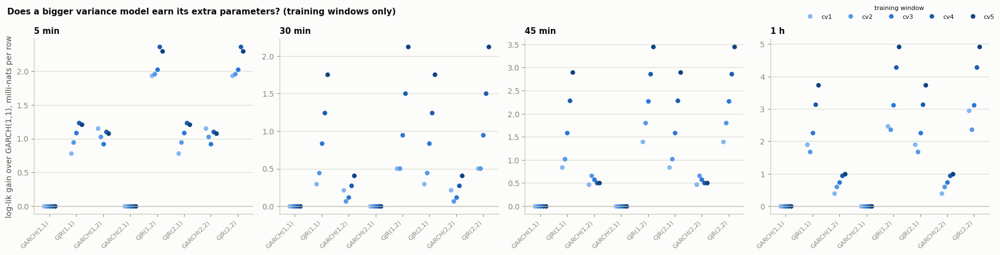

In [6]:
import sys, warnings, time, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
import numba as nb
warnings.filterwarnings("ignore")

# ---------------- variance model: GARCH(p,q) / GJR(p,q) with unit-variance Student-t innovations ----------------
# p = number of ARCH (past squared shock) lags, q = number of GARCH (past variance) lags, gjr adds a down-move term on lag 1
# parametrisation: persistence rho = sum(alpha) + gamma/2 + sum(beta) is capped at RHO_MAX, the coefficients are rho * softmax
# so every fit is non-negative and stationary by construction. A gap (NaN) is an expected shock: no likelihood term, e2 := sigma2
RHO_MAX = 0.9999

@nb.njit
def _ll(u, omega, alpha, gam, beta, s0, nu):
    n = u.shape[0]; p = alpha.shape[0]; q = beta.shape[0]
    sig2 = np.empty(n); e2 = np.empty(n); en = np.empty(n)
    c = math.lgamma((nu + 1.0) / 2.0) - math.lgamma(nu / 2.0) - 0.5 * math.log(math.pi * (nu - 2.0))
    ll = 0.0; cnt = 0
    for t in range(n):
        s = omega
        for i in range(p):
            j = t - 1 - i
            if j >= 0: s += alpha[i] * e2[j]
            else: s += alpha[i] * s0
        if t >= 1: s += gam * en[t - 1]
        else: s += gam * 0.5 * s0
        for i in range(q):
            j = t - 1 - i
            if j >= 0: s += beta[i] * sig2[j]
            else: s += beta[i] * s0
        if s < 1e-10: s = 1e-10
        if s > 1e10: s = 1e10
        sig2[t] = s
        x = u[t]
        if np.isnan(x):
            e2[t] = s; en[t] = 0.5 * s
        else:
            x2 = x * x
            e2[t] = x2; en[t] = x2 if x < 0.0 else 0.0
            ll += c - 0.5 * math.log(s) - 0.5 * (nu + 1.0) * math.log1p(x2 / (s * (nu - 2.0)))
            cnt += 1
    return ll, cnt

LNU = (np.log(0.05), np.log(98.0))                    # nu = 2 + exp(theta) in [2.05, 100]

def bnds(K):                                           # theta = [log omega, logit rho, K-1 softmax logits, log(nu-2)]
    return [(-20.0, 5.0), LNU] if K == 0 else [(-20.0, 5.0), (-12.0, 12.0)] + [(-12.0, 12.0)] * (K - 1) + [LNU]

def unpack(th, p, q, gjr):
    K = p + int(gjr) + q
    om = math.exp(th[0])
    if K == 0: return om, np.zeros(0), 0.0, np.zeros(0), 2.0 + math.exp(th[1])
    rho = RHO_MAX / (1.0 + math.exp(-th[1]))
    z = np.concatenate([th[2:2 + K - 1], [0.0]]); w = np.exp(z - z.max()); w /= w.sum(); c = rho * w
    return om, c[:p], (2.0 * c[p] if gjr else 0.0), c[p + int(gjr):], 2.0 + math.exp(th[2 + K - 1])

def to_theta(par, p, q, gjr):
    K = p + int(gjr) + q; lnu = math.log(max(par["nu"], 2.1) - 2.0)
    if K == 0: th = np.array([math.log(par["om"]), lnu])
    else:
        c = np.concatenate([par["a"], [par["g"] / 2.0] if gjr else [], par["b"]]); c = np.maximum(c, 1e-6)
        if c.sum() > 0.999: c = c * (0.999 / c.sum())
        rho = c.sum(); z = np.log(c) - np.log(c[-1]); r = rho / RHO_MAX
        th = np.concatenate([[math.log(par["om"]), math.log(r / (1.0 - r))], z[:-1], [lnu]])
    b = bnds(K); return np.clip(th, [x[0] for x in b], [x[1] for x in b])

def generic(p, q, gjr, rho0, nu0, s2):
    if p + q == 0: return dict(om=s2, a=np.zeros(0), g=0.0, b=np.zeros(0), nu=nu0, gjr=False)
    w = np.concatenate([[0.12, 0.03][:p], [0.04] if gjr else [], [0.80, 0.05][:q]]); c = w * rho0 / w.sum()
    return dict(om=s2 * (1.0 - rho0), a=c[:p], g=(2.0 * c[p] if gjr else 0.0), b=c[p + int(gjr):], nu=nu0, gjr=gjr)

def embed(par, p, q, gjr):                              # start a bigger model from a fitted smaller one
    a = np.full(p, 0.005); a[:len(par["a"])] = par["a"]; b = np.full(q, 0.005); b[:len(par["b"])] = par["b"]
    g = par["g"] if (gjr and par["gjr"]) else (0.01 if gjr else 0.0)
    return dict(om=par["om"], a=a, g=g, b=b, nu=par["nu"], gjr=gjr)

def fit_one(u, p, q, gjr, donors, nu_hints, s2):
    K = p + int(gjr) + q; N = int(np.isfinite(u).sum()); u = np.ascontiguousarray(u, dtype=np.float64)
    def f(th):
        om, a, g, b, nu = unpack(th, p, q, gjr); ll, cnt = _ll(u, om, a, g, b, s2, nu)
        return 1e10 if not np.isfinite(ll) else -ll / N
    starts = [to_theta(d, p, q, gjr) for d in donors]
    gen = [(0.95, nu_hints[0]), (0.99, nu_hints[1]), (0.90, 6.0)][: (3 if not donors else 1)]
    starts += [to_theta(generic(p, q, gjr, r0, n0, s2), p, q, gjr) for r0, n0 in gen]
    opt = dict(maxiter=500, maxfun=60000, ftol=1e-13, gtol=1e-7); runs = []
    for th0 in starts:
        r = optimize.minimize(f, th0, method="L-BFGS-B", bounds=bnds(K), options=opt); runs.append(r)
    best = min(runs, key=lambda r: r.fun)
    r2 = optimize.minimize(f, best.x, method="L-BFGS-B", bounds=bnds(K), options=opt)       # polish from the best start
    if r2.fun < best.fun: best = r2
    lls = np.array([-r.fun * N for r in runs]); ll = -best.fun * N
    om, a, g, b, nu = unpack(best.x, p, q, gjr)
    return dict(par=dict(om=om, a=a, g=g, b=b, nu=nu, gjr=gjr), ll=ll, N=N, k=K + 2, ok=bool(best.success),
                agree=float(np.mean(lls > ll - 1.0)), rho=float(a.sum() + g / 2.0 + b.sum()))

# ---------------- data: same series, windows and training-only rule as Step 1 ----------------
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
for sub in ("reports", "figs"): (RUN / sub).mkdir(exist_ok=True)
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds(); idx = dev.index
assert idx.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
EMBt = pd.Timedelta(minutes=5 * P.embargo_steps)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy(); n = len(y)
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy()
yb = y.copy(); yb[bad] = np.nan                                           # flagged / missing points are gaps (NaN)

CANDS = [("const", 0, 0, False), ("GARCH(1,1)", 1, 1, False), ("GJR(1,1)", 1, 1, True), ("GARCH(1,2)", 1, 2, False), ("GARCH(2,1)", 2, 1, False),
         ("GJR(1,2)", 1, 2, True), ("GJR(2,1)", 2, 1, True), ("GARCH(2,2)", 2, 2, False), ("GJR(2,2)", 2, 2, True)]
INFO = {c[0]: (c[1], c[2], c[3]) for c in CANDS}
SCALES = {"1 h": 12, "45 min": 9, "30 min": 6, "5 min": 1}                # coarse first
_f = RUN / "reports" / "student_t_fit.csv"; S1 = pd.read_csv(_f) if _f.exists() else None
def hint(sname, wname, series, default):                                  # Step 1 df used only as a starting value for nu
    if S1 is None: return default
    q = S1[(S1.scale == sname) & (S1.window == wname) & (S1.series == series)]
    return float(np.clip(q.df.iloc[0], 2.5, 30.0)) if len(q) else default

res = []
for sname, step in SCALES.items():
    t0 = time.time()
    ends = np.arange(step, n, step); d = yb[ends] - yb[ends - step]; te = idx[ends]; tb = (te.hour * 2 + te.minute // 30).to_numpy()
    for w in folds:
        pre = np.asarray(te <= w.val_start - EMBt); m = int(pre.sum())      # training rows only (a time prefix)
        assert pre[:m].all() and not pre[m:].any(), "training rows are not a prefix"
        fin = np.isfinite(d); sc = pd.Series(np.abs(d[pre & fin])).groupby(tb[pre & fin]).mean()
        u = (d / sc.reindex(tb).to_numpy())[:m]                              # intraday-scaled change; NaN = gap
        uu = u[np.isfinite(u)] ** 2; s2 = float(np.mean(np.minimum(uu, np.quantile(uu, 0.99))))
        hints = (hint(sname, w.name, "std_6h", 4.0), hint(sname, w.name, "std_1d", 3.0))
        fits = {}
        for name, p, q, gjr in CANDS:
            donors = [embed(fits[k]["par"], p, q, gjr) for k, (p2, q2, g2) in INFO.items()
                      if k in fits and k != "const" and p2 <= p and q2 <= q and int(g2) <= int(gjr) and (p - p2) + (q - q2) + (int(gjr) - int(g2)) == 1]
            fits[name] = fit_one(u, p, q, gjr, donors, hints, s2)
        for name, p, q, gjr in CANDS:
            f = fits[name]; par = f["par"]
            gap = min([f["ll"] - fits[k]["ll"] for k, (p2, q2, g2) in INFO.items() if k != name and p2 <= p and q2 <= q and int(g2) <= int(gjr)], default=np.nan)
            res.append(dict(scale=sname, window=w.name, model=name, p=p, q=q, gjr=gjr, N=f["N"], k=f["k"], ll=f["ll"],
                            aic=2 * f["k"] - 2 * f["ll"], bic=f["k"] * np.log(f["N"]) - 2 * f["ll"], nu=par["nu"], rho=f["rho"], omega=par["om"],
                            alpha1=par["a"][0] if p else np.nan, alpha2=par["a"][1] if p > 1 else np.nan, gamma=par["g"] if gjr else np.nan,
                            beta1=par["b"][0] if q else np.nan, beta2=par["b"][1] if q > 1 else np.nan,
                            nest_gap=gap, converged=f["ok"], agree=f["agree"]))
    print(f"{sname}: done in {time.time() - t0:.0f}s")

R = pd.DataFrame(res); key = ["scale", "window"]
ref = R[R.model == "GARCH(1,1)"][key + ["ll", "aic", "bic"]].rename(columns=dict(ll="ll0", aic="aic0", bic="bic0"))
R = R.merge(ref, on=key); R["dAIC"] = R.aic - R.aic0; R["dBIC"] = R.bic - R.bic0
R["gain_mnats_row"] = 1000 * (R.ll - R.ll0) / R.N; R["near_integrated"] = R.rho >= 0.999
R.drop(columns=["ll0", "aic0", "bic0"]).to_csv(RUN / "reports" / "garch_order_selection.csv", index=False)

WN = [w.name for w in folds]; MN = [c[0] for c in CANDS]; SC = ["5 min", "30 min", "45 min", "1 h"]
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("p = ARCH lags (past squared shocks), q = GARCH lags (past variances); GJR adds a down-move term. nu is free in every fit.")
print("window cv1 = training-only block (train once); cv2..cv5 = expanding; cv5 = static split. Training rows only.")
for s in SC:
    q = R[R.scale == s]
    print(f"\n=== {s}: BIC minus BIC of GARCH(1,1)   (negative = better; {int(q.N.min())}..{int(q.N.max())} scored training rows) ===")
    print(q.pivot(index="model", columns="window", values="dBIC").reindex(MN)[WN].round(1))
for crit in ("bic", "aic"):
    print(f"\nbest model by {crit.upper()}")
    print(R.loc[R.groupby(key)[crit].idxmin()].pivot(index="scale", columns="window", values="model").reindex(SC)[WN])
print("\nlog-likelihood gain over GARCH(1,1), milli-nats per training row (mean over windows)")
print(R.pivot_table(index="model", columns="scale", values="gain_mnats_row").reindex(MN)[SC].round(3))
for mdl in ("GARCH(1,1)", "GJR(1,1)"):
    q = R[R.model == mdl]
    print(f"\n{mdl}: fitted nu"); print(q.pivot(index="scale", columns="window", values="nu").reindex(SC)[WN].round(2))
    print(f"{mdl}: persistence (>= 0.999 means near-integrated)"); print(q.pivot(index="scale", columns="window", values="rho").reindex(SC)[WN].round(4))
q = R[R.model == "GJR(1,1)"]
print("\nGJR(1,1): gamma / alpha1 (extra variance response to a down-move relative to an up-move: 1 + gamma/alpha)")
print((1 + q.pivot(index="scale", columns="window", values="gamma") / q.pivot(index="scale", columns="window", values="alpha1")).reindex(SC)[WN].round(2))
print(f"\nconvergence checks: nested-model violations (a bigger model with lower log-lik by > 0.5): {int((R.nest_gap < -0.5).sum())} of {len(R)}; "
      f"fits where fewer than all starts reached the best likelihood: {int((R.agree < 1).sum())}; fits reporting no convergence: {int((~R.converged).sum())}")
print(R[R.nest_gap < -0.5][key + ["model", "nest_gap"]].to_string(index=False) if (R.nest_gap < -0.5).any() else "no nested-model violations")

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"; RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 10.5,
                     "axes.titleweight": "semibold", "legend.frameon": False})
fig, ax = plt.subplots(1, 4, figsize=(18, 4.6)); X = np.arange(len(MN) - 1)
for a, s in zip(ax, SC):
    for j, (wn, col) in enumerate(zip(WN, RAMP)):
        q = R[(R.scale == s) & (R.window == wn) & (R.model != "const")].set_index("model").loc[MN[1:]]
        a.plot(X + (j - 2) * 0.1, q.gain_mnats_row, "o", ms=5, color=col, label=wn)
    a.axhline(0, color=AXIS, lw=1); a.set_xticks(X); a.set_xticklabels(MN[1:], rotation=45, ha="right", fontsize=8); a.set_title(s)
ax[0].set_ylabel("log-lik gain over GARCH(1,1), milli-nats per row")
h, l = ax[0].get_legend_handles_labels(); fig.legend(h, l, loc="upper right", ncol=5, fontsize=8, title="training window", title_fontsize=8)
fig.suptitle("Does a bigger variance model earn its extra parameters? (training windows only)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(); fig.savefig(RUN / "figs" / "garch_order_selection.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output** (BIC − BIC of GARCH(1,1); lower is better)

**30 min:**

| Model | cv1 | cv2 | cv3 | cv4 | cv5 |
|---|---|---|---|---|---|
| const | +1,427 | +1,960 | +2,248 | +2,627 | +2,982 |
| GARCH(1,1) | 0 | 0 | 0 | 0 | 0 |
| GJR(1,1) | +5.3 | +1.9 | −8.0 | −21.8 | −42.4 |
| GJR(1,2) | +11.6 | +10.0 | −0.9 | −18.9 | **−43.9** |

* **`const` loses by thousands of BIC points** in every window and scale: volatility clustering is overwhelmingly supported.
* **At 5 min** `GJR(1,2)` wins in every window (BIC −111 … −387, i.e. by a lot).
* **At 30–60 min** the best order moves from `GARCH(1,1)` in the early windows (cv1–cv2 at 30 min, cv1 at 45 min) to `GJR(1,1)` and then `GJR(1,2)` in later ones, *because more data supports a more complex model*. The leverage term becomes decisive as the training sample grows (−42 BIC at 30 min in cv5).
* `GARCH(2,1)` has exactly the likelihood of `GARCH(1,1)` (its BIC is higher by $\ln N$, e.g. 8.6 at $N=5{,}657$): **the second ARCH lag gets zero weight**. `GJR(2,1)` ties `GJR(1,1)` for the same reason.
* AIC prefers `GJR(1,2)` almost everywhere (and `GJR(2,2)` in one 1 h window).
* The gain of the richer model is small in absolute terms: about **1.1 / 2.4 / 3.4 milli-nats per row** for `GJR(1,2)` over `GARCH(1,1)` at 30 / 45 / 60 min.

✅ **Take-away.** Asymmetry (GJR) matters; a second ARCH lag does not; a second *GARCH* lag helps only marginally.

### 8.2b Convergence audit and the fitted GJR(1,1) parameters

📘 **What.** Lists the fits for which the optimiser did **not** report convergence together with `agree` (the share of starting points reaching the best likelihood within 1 log-unit), then prints the GJR(1,1) coefficients per scale and window.

In [7]:
import sys; sys.path.insert(0, "/kaggle/working/final_run")
from runio import RUN
R = pd.read_csv(RUN / "reports" / "garch_order_selection.csv"); R = R[R.scale != "5 min"]
print(R[~R.converged][["scale", "window", "model", "agree"]].to_string(index=False))
w = R[R.model == "GJR(1,1)"]
for s in ["30 min", "45 min", "1 h"]:
    print(s); print(w[w.scale == s][["window", "alpha1", "gamma", "beta1", "rho", "nu"]].round(4).to_string(index=False))

 scale window    model  agree
   1 h    cv3    const 1.0000
45 min    cv3 GJR(1,1) 1.0000
45 min    cv3 GJR(2,1) 1.0000
30 min    cv4 GJR(1,1) 1.0000
30 min    cv5    const 1.0000
30 min
window  alpha1  gamma  beta1    rho     nu
   cv1  0.2759 0.0487 0.6997 0.9999 4.4927
   cv2  0.2666 0.0594 0.7036 0.9999 4.6619
   cv3  0.2631 0.0877 0.6928 0.9998 4.6793
   cv4  0.2671 0.1160 0.6748 0.9999 4.4672
   cv5  0.2574 0.1388 0.6730 0.9998 4.3233
45 min
window  alpha1  gamma  beta1    rho     nu
   cv1  0.2395 0.0819 0.7194 0.9999 4.3433
   cv2  0.2514 0.0929 0.7021 0.9999 4.8711
   cv3  0.2434 0.1219 0.6859 0.9903 4.9333
   cv4  0.2452 0.1595 0.6654 0.9903 4.5376
   cv5  0.2382 0.1807 0.6615 0.9901 4.4741
1 h
window  alpha1  gamma  beta1    rho     nu
   cv1  0.2391 0.1285 0.6966 0.9999 4.9375
   cv2  0.2351 0.1175 0.7060 0.9999 5.3097
   cv3  0.2258 0.1455 0.6954 0.9939 5.1333
   cv4  0.2061 0.1772 0.6936 0.9883 4.6784
   cv5  0.1973 0.1945 0.6909 0.9855 4.6179


👀 **How to read this output**

* Five fits are flagged (1 h cv3 `const`, 45 min cv3 `GJR(1,1)` and `GJR(2,1)`, 30 min cv4 `GJR(1,1)`, 30 min cv5 `const`) **but `agree = 1.0000` for all of them**: every start reached the same likelihood, so the "failure" is only a tolerance flag.

**GJR(1,1) parameters** (cv1 → cv5):

| Scale | $\alpha_1$ | $\gamma$ | $\beta_1$ | $\rho$ | $\nu$ |
|---|---|---|---|---|---|
| 30 min | 0.276 → 0.257 | **0.049 → 0.139** | 0.700 → 0.673 | 0.9999 → 0.9998 | 4.49 → 4.32 |
| 45 min | 0.240 → 0.238 | **0.082 → 0.181** | 0.719 → 0.662 | 0.9999 → 0.990 | 4.34 → 4.47 |
| 1 h | 0.239 → 0.197 | 0.129 → 0.195 | 0.697 → 0.691 | 0.9999 → 0.986 | 4.94 → 4.62 |

* $\alpha_1\approx0.2$–$0.28$ and $\beta_1\approx0.66$–$0.72$: **a large reaction to the latest shock** and a **moderate** carry-over (an unusually *spiky* GARCH, compared with finance's typical $\alpha\approx0.05$, $\beta\approx0.9$).
* **$\gamma$ grows with the training sample** (0.049 → 0.139 at 30 min): the asymmetry strengthens, so the parameters are **not constant over time**. This is one reason `refit` beats `frozen` later (Step 4).
* $\rho\approx0.99$–$1.00$: **very long volatility memory**, close to an integrated GARCH.
* $\nu\approx4.3$–$5.3$ for the *standardised* series: the same tail-thinning seen in Step 1.

## 8.3 Step 3: freeze the structure, GJR(1,1), and check that it removes the clustering

📘 **What.** Fixes **GJR(1,1)** as the working model (simpler than `GJR(1,2)`, and the extra lag brings a small gain), re-runs the filter from the stored parameters and verifies it **reproduces Step 2's log-likelihood**. It then compares the series **before** (the scaled change $u$) and **after** (the standardised residual $z_t=u_t/\hat\sigma_t$) the model:

* lag-1 and lag-3 autocorrelation of $|u|$ vs $|z|$ (if the model captures clustering, $|z|$ is uncorrelated);
* lag-1 autocorrelation and the mean of $z$ itself;
* **exceedance ratios**: observed/nominal share of $|z|$ beyond the model's 95 % and 99 % $t$-band (1 = calibrated; >1 means the band is too narrow).

Parameters are saved to `reports/gjr11_params_frozen.csv`.

GJR(1,1), Student-t, nu free; parameters from Step 2, one set per scale x window, fitted on training rows only; saved to reports/gjr11_params_frozen.csv

reproduction check: largest |log-lik recomputed - log-lik from Step 2| = 1.09e-11  (should be about 0)

lag-1 autocorrelation of |change| BEFORE the model (intraday-scaled change)
window    cv1    cv2    cv3    cv4    cv5
scale                                    
30 min 0.3341 0.3347 0.3360 0.3413 0.3296
45 min 0.3790 0.3958 0.3828 0.3667 0.3470
1 h    0.3659 0.3708 0.3581 0.3417 0.3380

lag-1 autocorrelation of |z| AFTER the model (z = change / fitted sigma; 0 = clustering removed)
window    cv1    cv2    cv3    cv4    cv5
scale                                    
30 min 0.0282 0.0192 0.0161 0.0212 0.0183
45 min 0.0310 0.0387 0.0296 0.0221 0.0181
1 h    0.0428 0.0447 0.0384 0.0378 0.0349

lag-3 autocorrelation of |change| before
window    cv1    cv2    cv3    cv4    cv5
scale                                    
30 min 0.2580 0.2740 0

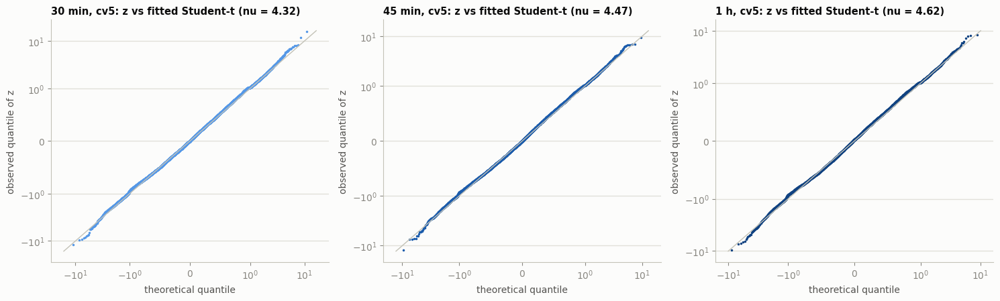

In [8]:
import sys, warnings, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import numba as nb
warnings.filterwarnings("ignore")
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid

@nb.njit
def _filter(u, om, a, g, b, nu, s0):                       # GJR(1,1) variance path + log-likelihood (same recursion as Step 2)
    n = u.shape[0]; sig2 = np.empty(n); ll = 0.0
    c = math.lgamma((nu + 1.0) / 2.0) - math.lgamma(nu / 2.0) - 0.5 * math.log(math.pi * (nu - 2.0))
    e2p = s0; enp = 0.5 * s0; sp = s0
    for t in range(n):
        s = om + a * e2p + g * enp + b * sp
        s = min(max(s, 1e-10), 1e10); sig2[t] = s; x = u[t]
        if np.isnan(x): e2p = s; enp = 0.5 * s
        else:
            x2 = x * x; e2p = x2; enp = x2 if x < 0.0 else 0.0
            ll += c - 0.5 * math.log(s) - 0.5 * (nu + 1.0) * math.log1p(x2 / (s * (nu - 2.0)))
        sp = s
    return sig2, ll

# ---- same data, windows and training-only rule as Steps 1 and 2 ----
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds(); idx = dev.index
assert idx.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
EMBt = pd.Timedelta(minutes=5 * P.embargo_steps)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy(); n = len(y)
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy()
yb = y.copy(); yb[bad] = np.nan
SCALES = {"30 min": 6, "45 min": 9, "1 h": 12}; SC = list(SCALES); WN = [w.name for w in folds]
S2 = pd.read_csv(RUN / "reports" / "garch_order_selection.csv"); S2 = S2[(S2.model == "GJR(1,1)") & S2.scale.isin(SC)].set_index(["scale", "window"])

def acf(x, k):                                              # lag-k autocorrelation over pairs where both values exist
    a, b = x[:-k], x[k:]; ok = np.isfinite(a) & np.isfinite(b); return float(np.corrcoef(a[ok], b[ok])[0, 1])

res, par, ZKEEP = [], [], {}
for sname, step in SCALES.items():
    ends = np.arange(step, n, step); d = yb[ends] - yb[ends - step]; te = idx[ends]; tb = (te.hour * 2 + te.minute // 30).to_numpy()
    for w in folds:
        pre = np.asarray(te <= w.val_start - EMBt); m = int(pre.sum()); fin = np.isfinite(d)
        sc = pd.Series(np.abs(d[pre & fin])).groupby(tb[pre & fin]).mean(); u = np.ascontiguousarray((d / sc.reindex(tb).to_numpy())[:m])
        uu = u[np.isfinite(u)] ** 2; s0 = float(np.mean(np.minimum(uu, np.quantile(uu, 0.99))))
        r = S2.loc[(sname, w.name)]; sig2, ll = _filter(u, r.omega, r.alpha1, r.gamma, r.beta1, r.nu, s0)
        z = u / np.sqrt(sig2); zf = z[np.isfinite(z)]; nu = r.nu; sc_t = math.sqrt((nu - 2.0) / nu)
        ex = lambda p: float(np.mean(np.abs(zf) > stats.t.ppf(1 - p / 2, nu) * sc_t))
        c1 = stats.t.ppf(0.995, nu) * sc_t
        res.append(dict(scale=sname, window=w.name, N=len(zf), ll_check=ll - r.ll, acf1_abs_u=acf(np.abs(u), 1), acf1_abs_z=acf(np.abs(z), 1),
                        acf3_abs_u=acf(np.abs(u), 3), acf3_abs_z=acf(np.abs(z), 3), acf1_z=acf(z, 1), mean_z=float(zf.mean()),
                        ex5=ex(0.05) / 0.05, ex1=ex(0.01) / 0.01, up1=float(np.mean(zf > c1)) / 0.005, dn1=float(np.mean(zf < -c1)) / 0.005))
        par.append(dict(scale=sname, window=w.name, train_end=w.val_start - EMBt, N=len(zf), s0=s0, omega=r.omega, alpha1=r.alpha1, gamma=r.gamma,
                        beta1=r.beta1, nu=nu, persistence=r.rho))
        if w.name == "cv5": ZKEEP[sname] = (zf, nu)

D = pd.DataFrame(res); pd.DataFrame(par).to_csv(RUN / "reports" / "gjr11_params_frozen.csv", index=False); D.to_csv(RUN / "reports" / "gjr11_fit_diagnostics.csv", index=False)
pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:.4f}".format)
print("GJR(1,1), Student-t, nu free; parameters from Step 2, one set per scale x window, fitted on training rows only; saved to reports/gjr11_params_frozen.csv")
print(f"\nreproduction check: largest |log-lik recomputed - log-lik from Step 2| = {D.ll_check.abs().max():.2e}  (should be about 0)")
def show(title, col): print(f"\n{title}"); print(D.pivot(index="scale", columns="window", values=col).reindex(SC)[WN])
show("lag-1 autocorrelation of |change| BEFORE the model (intraday-scaled change)", "acf1_abs_u")
show("lag-1 autocorrelation of |z| AFTER the model (z = change / fitted sigma; 0 = clustering removed)", "acf1_abs_z")
show("lag-3 autocorrelation of |change| before", "acf3_abs_u"); show("lag-3 autocorrelation of |z| after", "acf3_abs_z")
show("lag-1 autocorrelation of z itself (signed)", "acf1_z"); show("mean of z", "mean_z")
show("two-sided exceedance of the 95% t band: observed / nominal (1 = calibrated)", "ex5")
show("two-sided exceedance of the 99% t band: observed / nominal (1 = calibrated)", "ex1")
show("upper-tail exceedance of the 99% band: observed / nominal 0.5%", "up1")
show("lower-tail exceedance of the 99% band: observed / nominal 0.5%", "dn1")

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"; C = ["#5598e7", "#1c5cab", "#104281"]
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "semibold"})
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, s, col in zip(ax, SC, C):
    zf, nu = ZKEEP[s]; zs = np.sort(zf); pp = (np.arange(1, len(zs) + 1) - 0.5) / len(zs); th = stats.t.ppf(pp, nu) * math.sqrt((nu - 2.0) / nu)
    a.plot(th, zs, ".", ms=3, color=col); lim = max(abs(th).max(), abs(zs).max()) * 1.05; a.plot([-lim, lim], [-lim, lim], color=AXIS, lw=1)
    a.set_xscale("symlog", linthresh=1); a.set_yscale("symlog", linthresh=1); a.set_title(f"{s}, cv5: z vs fitted Student-t (nu = {nu:.2f})")
    a.set_xlabel("theoretical quantile"); a.set_ylabel("observed quantile of z")
fig.tight_layout(); fig.savefig(RUN / "figs" / "gjr11_qq_cv5.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output**

* **Reproduction check:** the largest difference between the recomputed and the Step 2 log-likelihood is **1.1e-11** — numerical noise. The filter is the same as the fitted one.
* **Clustering is removed.** Lag-1 ACF of $|u|$ was 0.33–0.40; of $|z|$ it is **0.016–0.045**. Lag-3: 0.20–0.27 before, −0.03 to +0.00 after. The model captures the persistence in size.
* **Signed structure remains** (lag-1 ACF of $z$: 0.12–0.18; mean of $z$: +0.04–0.05). This is by design: the variance model has **no mean equation**, and the signed pattern is the part the *point forecast* is supposed to handle. (A note on why it is positive here while signed ACF of raw changes is ≈0 was not investigated.)
* **Band calibration (two-sided exceedance ratio).** At 95 %: 30 min 1.09, 1.05, 0.95, 0.96, 0.92 (cv1…cv5); 45 min 1.06 … 0.98; 1 h 1.11 … 0.93: within ±10 %. At 99 % the ratio is 1.04–1.38: the *outer* band is a little too narrow, especially in early windows.

## 8.4 Step 4: does GJR beat the simple alternatives? (validation, pooled)

📘 **What.** Scores forecasts of the variance of the next change on the **validation windows only** (sealed test untouched), against five benchmarks:

| Benchmark | Variance forecast |
|---|---|
| `GARCH(1,1)` | reference, not a candidate |
| `EWMA` | $v_t=\lambda\,v_{t-1}+(1-\lambda)\,u_{t-1}^2$, with $\lambda\in\{0.5,\dots,0.99\}$ chosen on the training rows by Gaussian QLIKE |
| `roll_6h` | mean of $u^2$ over the previous 6 h (gaps skipped) |
| `roll_1d` | mean of $u^2$ over the previous day |
| `const` | training-sample mean of $u^2$ |

**Scoring rules** (all causal; $v_t$ is the forecast variance):

* **QLIKE** (Gaussian deviance, on the original change scale): $\ \text{QL}_t=\ln v_t+\dfrac{u_t^2}{v_t}+2\ln s_{b(t)}$. Lower is better. It ranks variance forecasts consistently even though the true variance is unobserved.
* **Student-$t$ log score**, same $\nu$ for every model: $\ \text{LS}_t=\ln f(u_t\mid v_t,\nu)-\ln s_{b(t)}$. Higher is better.
* **$R^2_{|\cdot|}$** (Mincer–Zarnowitz style): the squared correlation between $|u_t|$ and the forecast sd $\sqrt{v_t}$.
* **Ceiling.** If $\sigma_t$ were the *true* volatility and shocks were $t_\nu$, the best attainable $R^2_{|\cdot|}$ would be
$$R^2_{\max}=\frac{m_\nu^{2}\,V}{m_\nu^{2}\,V+\overline{\sigma^{2}}\,(1-m_\nu^{2})},\qquad m_\nu=\mathbb E|z|=\sqrt{\tfrac{\nu-2}{\nu}}\;\frac{2\sqrt{\nu}\,\Gamma(\tfrac{\nu+1}{2})}{\sqrt\pi\,(\nu-1)\,\Gamma(\tfrac\nu2)},$$
with $V=\text{Var}(\sigma_t)$. (Derivation: $\text{Var}|u|=m^2V+\overline{\sigma^2}(1-m^2)$ and $\text{Cov}(|u|,\sigma)=mV$.) It shows what "perfect" looks like for a noisy target.
* **Diebold–Mariano** with Bartlett HAC (lag = one day of rows), and a **day-block bootstrap** of the difference in $R^2_{|\cdot|}$.

scored on VALIDATION windows only (cv1..cv5 pooled), sealed test untouched. frozen = cv1 training fit for all windows; refit = each window's own training fit (expanding, 24 h embargo).
GJR(1,1) is the model fixed in Step 3; GARCH(1,1) is a reference, not a candidate. All variance forecasts are causal.
dQLIKE / dTscore are measured against GJR in the same scheme: positive dQLIKE and negative dTscore mean WORSE than GJR.

=== 30 min  (n = 11471 scored changes) ===
                   dQLIKE  dTscore  R2_abs  R2_sq  spearman  ceil_abs
scheme model                                                         
frozen GJR(1,1)    0.0000   0.0000  0.1619 0.0661    0.3515    0.2702
       GARCH(1,1)  0.0103  -0.0015  0.1588 0.0630    0.3506    0.2730
       EWMA        0.1059  -0.0345  0.1458 0.0641    0.3215       NaN
       roll_1d     0.2149  -0.0744  0.0736 0.0348    0.2297       NaN
       roll_6h     0.3039  -0.0694  0.1209 0.0487    0.3035       NaN
       const       0.4761  -0.1659  0.0000 

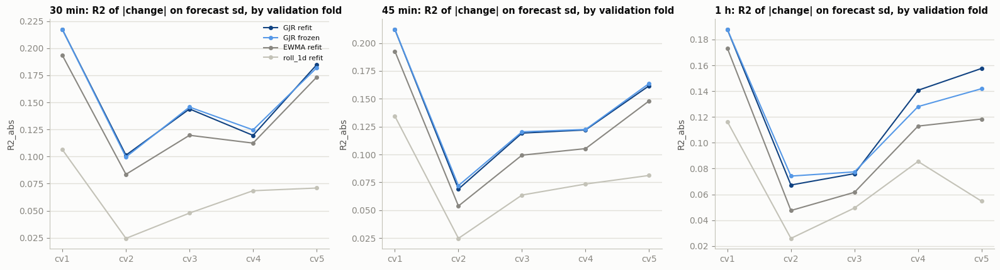

In [9]:
import sys, warnings, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln
import numba as nb
warnings.filterwarnings("ignore")
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid

@nb.njit
def _filter(u, om, a, g, b, nu, s0):                       # GJR(1,1) variance path (g = 0 gives GARCH(1,1)); causal: sigma2[t] uses data before t only
    n = u.shape[0]; sig2 = np.empty(n); ll = 0.0
    c = math.lgamma((nu + 1.0) / 2.0) - math.lgamma(nu / 2.0) - 0.5 * math.log(math.pi * (nu - 2.0))
    e2p = s0; enp = 0.5 * s0; sp = s0
    for t in range(n):
        s = om + a * e2p + g * enp + b * sp
        s = min(max(s, 1e-10), 1e10); sig2[t] = s; x = u[t]
        if np.isnan(x): e2p = s; enp = 0.5 * s
        else:
            x2 = x * x; e2p = x2; enp = x2 if x < 0.0 else 0.0
            ll += c - 0.5 * math.log(s) - 0.5 * (nu + 1.0) * math.log1p(x2 / (s * (nu - 2.0)))
        sp = s
    return sig2, ll

@nb.njit
def _ewma(u, lam, s0):
    n = u.shape[0]; out = np.empty(n); sp = s0; ep = s0
    for t in range(n):
        s = lam * sp + (1.0 - lam) * ep; out[t] = s; x = u[t]
        ep = s if np.isnan(x) else x * x; sp = s
    return out

def roll_var(u, k, fallback):                              # mean of u^2 over the k previous steps (gaps skipped)
    f = np.isfinite(u); s = np.where(f, u * u, 0.0); cs = np.r_[0.0, np.cumsum(s)]; cc = np.r_[0.0, np.cumsum(f)]
    a = np.arange(len(u)); lo = np.maximum(0, a - k); num = cs[a] - cs[lo]; cnt = cc[a] - cc[lo]
    return np.maximum(np.where(cnt >= max(2, k // 2), num / np.maximum(cnt, 1), fallback), 1e-8)

def mabs(nu):                                              # E|z| of a unit-variance Student-t
    return math.sqrt((nu - 2) / nu) * 2 * math.sqrt(nu) * math.exp(gammaln((nu + 1) / 2) - gammaln(nu / 2)) / (math.sqrt(math.pi) * (nu - 1))
def r2(a, b): return float(np.corrcoef(a, b)[0, 1] ** 2)
def ceil_abs(sd, nu):                                      # R2 of |u| on sigma if sigma were the TRUE volatility and shocks were t(nu)
    m = mabs(nu); V = sd.var(); return float(V * m * m / (V * m * m + np.mean(sd ** 2) * (1 - m * m)))
def dm(dif, L):                                            # Diebold-Mariano with Bartlett HAC; positive mean = benchmark worse than GJR
    n = len(dif); mu = dif.mean(); x = dif - mu; s = x @ x / n
    for l in range(1, L + 1): s += 2 * (1 - l / (L + 1)) * (x[l:] @ x[:-l]) / n
    z = mu / math.sqrt(max(s, 1e-18) / n); return float(mu), float(z), float(2 * stats.norm.sf(abs(z)))

# ---- data, windows, training-only scaling: same as Steps 1-3 ----
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds(); idx = dev.index
assert idx.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
EMBt = pd.Timedelta(minutes=5 * P.embargo_steps)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy(); n = len(y)
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy()
yb = y.copy(); yb[bad] = np.nan
SCALES = {"30 min": 6, "45 min": 9, "1 h": 12}; SC = list(SCALES); WN = [w.name for w in folds]
PAR = pd.read_csv(RUN / "reports" / "gjr11_params_frozen.csv").set_index(["scale", "window"])
G11 = pd.read_csv(RUN / "reports" / "garch_order_selection.csv"); G11 = G11[G11.model == "GARCH(1,1)"].set_index(["scale", "window"])
MODELS = ["GJR(1,1)", "GARCH(1,1)", "EWMA", "roll_1d", "roll_6h", "const"]; LAMS = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.94, 0.97, 0.99]
(RUN / "preds").mkdir(exist_ok=True); rng = np.random.default_rng(0)

store, saved, lam_rows = {}, {}, []
for sname, step in SCALES.items():
    ends = np.arange(step, n, step); d = yb[ends] - yb[ends - step]; te = idx[ends]; tb = (te.hour * 2 + te.minute // 30).to_numpy(); fin = np.isfinite(d)
    day = np.asarray((te.normalize() - idx[0].normalize()).days); dt = pd.Timedelta(minutes=5 * step); saved[f"{sname}_te"] = te.values.astype("int64")
    src = {}
    for w in folds:                                         # everything a scheme needs, built from that window's TRAINING rows only
        pre = np.asarray(te <= w.val_start - EMBt)
        sc = pd.Series(np.abs(d[pre & fin])).groupby(tb[pre & fin]).mean(); srow = sc.reindex(tb).to_numpy(); u = d / srow
        p = PAR.loc[(sname, w.name)]; q = G11.loc[(sname, w.name)]; s0 = float(p.s0); nu = float(p.nu); ut = u[pre]; uf = ut[np.isfinite(ut)]
        cv = float(np.mean(uf ** 2)); v = {"const": np.full(len(u), cv)}
        v["GJR(1,1)"] = _filter(u, p.omega, p.alpha1, p.gamma, p.beta1, nu, s0)[0]; v["GARCH(1,1)"] = _filter(u, q.omega, q.alpha1, 0.0, q.beta1, q.nu, s0)[0]
        v["roll_6h"] = roll_var(u, max(2, 360 // (5 * step)), cv); v["roll_1d"] = roll_var(u, max(2, 1440 // (5 * step)), cv)
        tl = []
        for lam in LAMS:
            vt = _ewma(np.ascontiguousarray(ut), lam, s0); ok = np.isfinite(ut); tl.append(np.mean(np.log(vt[ok]) + ut[ok] ** 2 / vt[ok]))
        lam = LAMS[int(np.argmin(tl))]; v["EWMA"] = _ewma(np.ascontiguousarray(u), lam, s0); lam_rows.append(dict(scale=sname, window=w.name, lam=lam, edge=lam in (LAMS[0], LAMS[-1])))
        src[w.name] = dict(u=u, srow=srow, v=v, nu=nu); saved[f"{sname}_{w.name}_v"] = v["GJR(1,1)"]; saved[f"{sname}_{w.name}_scale"] = srow
    for scheme in ("frozen", "refit"):                      # frozen = cv1's training fit used for every window; refit = each window's own (expanding, 24 h embargo)
        for k, w in enumerate(folds):
            S = src["cv1"] if scheme == "frozen" else src[w.name]
            vm = (te - dt >= w.val_start) & (te < w.val_end) & fin                                  # origin >= val_start, target < val_end
            u = S["u"][vm]; lsc = np.log(S["srow"][vm]); nu = S["nu"]; c = math.lgamma((nu + 1) / 2) - math.lgamma(nu / 2) - 0.5 * math.log(math.pi * (nu - 2))
            for m in MODELS:
                vv = S["v"][m][vm]
                store.setdefault((sname, scheme, m), []).append(dict(
                    fold=np.full(len(u), k), day=day[vm], au=np.abs(u), u2=u * u, sd=np.sqrt(vv), v=vv, nu=nu,
                    ql=np.log(vv) + u * u / vv + 2 * lsc,                                                  # QLIKE (Gaussian deviance) on the ORIGINAL change scale
                    ts=c - 0.5 * np.log(vv) - 0.5 * (nu + 1) * np.log1p(u * u / (vv * (nu - 2))) - lsc))   # Student-t log score, same nu for every model

def pool(key): 
    L = store[key]; return {c: np.concatenate([x[c] for x in L]) for c in ("fold", "day", "au", "u2", "sd", "v", "ql", "ts")} | {"nu": float(np.mean([x["nu"] for x in L]))}
rows, dmr, bsr = [], [], []
for sname in SC:
    L = 288 // SCALES[sname]
    for scheme in ("frozen", "refit"):
        Pg = pool((sname, scheme, "GJR(1,1)"))
        for m in MODELS:
            Q = pool((sname, scheme, m)); rows.append(dict(scale=sname, scheme=scheme, model=m, n=len(Q["au"]), ql=Q["ql"].mean(), ts=Q["ts"].mean(),
                R2_abs=r2(Q["au"], Q["sd"]) if Q["sd"].std() > 1e-9 else 0.0, R2_sq=r2(Q["u2"], Q["v"]) if Q["v"].std() > 1e-9 else 0.0,
                spearman=float(stats.spearmanr(Q["au"], Q["sd"])[0]) if Q["sd"].std() > 1e-9 else 0.0,
                ceil_abs=ceil_abs(Q["sd"], Pg["nu"]) if m in ("GJR(1,1)", "GARCH(1,1)") else np.nan))
            if m != "GJR(1,1)":
                a1, p1, p2 = dm(Q["ql"] - Pg["ql"], L); b1, q1, q2 = dm(Pg["ts"] - Q["ts"], L)
                dmr.append(dict(scale=sname, scheme=scheme, benchmark=m, dQL=a1, DM_QL=p1, p_QL=p2, dTS=b1, DM_TS=q1, p_TS=q2))
                if m in ("EWMA", "roll_1d"):
                    ud = np.unique(Pg["day"]); ix = [np.flatnonzero(Pg["day"] == x) for x in ud]; bs = []
                    for _ in range(300):
                        ii = np.concatenate([ix[j] for j in rng.integers(0, len(ud), len(ud))]); bs.append(r2(Pg["au"][ii], Pg["sd"][ii]) - r2(Q["au"][ii], Q["sd"][ii]))
                    bsr.append(dict(scale=sname, scheme=scheme, benchmark=m, dR2_abs=r2(Pg["au"], Pg["sd"]) - r2(Q["au"], Q["sd"]), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5)))
    for m in ("GJR(1,1)", "EWMA"):                          # same model, frozen vs refit, on the same scored rows
        F, Rf = pool((sname, "frozen", m)), pool((sname, "refit", m)); a1, p1, p2 = dm(F["ql"] - Rf["ql"], L); b1, q1, q2 = dm(Rf["ts"] - F["ts"], L)
        dmr.append(dict(scale=sname, scheme="frozen vs refit", benchmark=m + " (frozen)", dQL=a1, DM_QL=p1, p_QL=p2, dTS=b1, DM_TS=q1, p_TS=q2))
T = pd.DataFrame(rows); DMT = pd.DataFrame(dmr); BS = pd.DataFrame(bsr)
T.to_csv(RUN / "reports" / "var_scores.csv", index=False); DMT.to_csv(RUN / "reports" / "var_dm.csv", index=False); BS.to_csv(RUN / "reports" / "var_r2_bootstrap.csv", index=False)
np.savez(RUN / "preds" / "var_gjr11.npz", **saved)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:.4f}".format)

print("scored on VALIDATION windows only (cv1..cv5 pooled), sealed test untouched. frozen = cv1 training fit for all windows; refit = each window's own training fit (expanding, 24 h embargo).")
print("GJR(1,1) is the model fixed in Step 3; GARCH(1,1) is a reference, not a candidate. All variance forecasts are causal.")
print("dQLIKE / dTscore are measured against GJR in the same scheme: positive dQLIKE and negative dTscore mean WORSE than GJR.")
for sname in SC:
    q = T[T.scale == sname].copy(); ref = q[q.model == "GJR(1,1)"].set_index("scheme"); q["dQLIKE"] = q.ql - q.scheme.map(ref.ql); q["dTscore"] = q.ts - q.scheme.map(ref.ts)
    print(f"\n=== {sname}  (n = {int(q.n.iloc[0])} scored changes) ===")
    print(q.set_index(["scheme", "model"])[["dQLIKE", "dTscore", "R2_abs", "R2_sq", "spearman", "ceil_abs"]])
print("\nR2_abs = R-squared of |change| on the forecast sd (Mincer-Zarnowitz style); R2_sq = same with squared change on forecast variance (dominated by a few extreme points);")
print("ceil_abs (GJR and GARCH only) = the R2_abs you would get if the fitted sigma were the TRUE volatility and shocks were Student-t with the fitted nu: what 'perfect' looks like for this noisy target.")
print("\nR2_abs by validation fold"); 
for sname in SC:
    out = {}
    for lab, sch, m in (("GJR refit", "refit", "GJR(1,1)"), ("GJR frozen", "frozen", "GJR(1,1)"), ("EWMA refit", "refit", "EWMA"), ("roll_1d refit", "refit", "roll_1d")):
        Q = pool((sname, sch, m)); out[lab] = [r2(Q["au"][Q["fold"] == k], Q["sd"][Q["fold"] == k]) for k in range(len(folds))]
    print(f"\n{sname}"); print(pd.DataFrame(out, index=WN).T)
    Fz, Rf, Ew = pool((sname, "frozen", "GJR(1,1)")), pool((sname, "refit", "GJR(1,1)")), pool((sname, "refit", "EWMA"))
    print(pd.DataFrame({"QL frozen GJR - refit GJR": [ (Fz["ql"] - Rf["ql"])[Fz["fold"] == k].mean() for k in range(len(folds))],
                        "QL EWMA - GJR (refit)": [(Ew["ql"] - Rf["ql"])[Ew["fold"] == k].mean() for k in range(len(folds))]}, index=WN).T)
print("\nDiebold-Mariano, pooled over folds, HAC lag = 24 h of rows. dQL > 0 / dTS > 0 = the benchmark is worse than GJR; p two-sided.")
print(DMT.set_index(["scale", "scheme", "benchmark"]).round(4))
print("\nR2_abs of GJR minus R2_abs of the benchmark, day-block bootstrap 95% interval (300 resamples), pooled folds")
print(BS.set_index(["scale", "scheme", "benchmark"]).round(4))
LR = pd.DataFrame(lam_rows); print("\nEWMA decay chosen on each training window (grid 0.5..0.99):"); print(LR.pivot(index="scale", columns="window", values="lam").reindex(SC)[WN])
print(f"windows where the choice sat on the grid edge: {int(LR.edge.sum())} of {len(LR)}")

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "semibold", "legend.frameon": False})
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4)); cols = {"GJR refit": "#104281", "GJR frozen": "#5598e7", "EWMA refit": "#898781", "roll_1d refit": "#c3c2b7"}
for a, sname in zip(ax, SC):
    for lab, sch, m in (("GJR refit", "refit", "GJR(1,1)"), ("GJR frozen", "frozen", "GJR(1,1)"), ("EWMA refit", "refit", "EWMA"), ("roll_1d refit", "refit", "roll_1d")):
        Q = pool((sname, sch, m)); a.plot(range(len(folds)), [r2(Q["au"][Q["fold"] == k], Q["sd"][Q["fold"] == k]) for k in range(len(folds))], "-o", ms=4, lw=1.5, color=cols[lab], label=lab)
    a.set_xticks(range(len(folds))); a.set_xticklabels(WN); a.set_title(f"{sname}: R2 of |change| on forecast sd, by validation fold"); a.set_ylabel("R2_abs")
ax[0].legend(fontsize=8); fig.tight_layout(); fig.savefig(RUN / "figs" / "var_r2_by_fold.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output** (pooled over cv1–cv5; `refit` scheme)

| $R^2_{\lvert\cdot\rvert}$ | 30 min | 45 min | 1 h |
|---|---|---|---|
| **GJR(1,1)** | **0.1615** | **0.1499** | **0.1334** |
| GARCH(1,1) | 0.1557 | 0.1399 | 0.1201 |
| EWMA | 0.1457 | 0.1330 | 0.1116 |
| roll_6h | 0.1204 | 0.1169 | 0.0971 |
| roll_1d | 0.0756 | 0.0897 | 0.0769 |
| const | 0.0001 | 0.0006 | 0.0020 |
| **ceiling** | 0.260 | 0.230 | 0.215 |

* **GJR beats every benchmark on every scoring rule.** The DM statistics on QLIKE (refit) are 4.2–10.9 and on the $t$ log score 4.6–22 (all $p\approx0$). The gap to EWMA is +0.1015 / +0.0887 / +0.0803 in QLIKE.
* The **ceiling** (0.26 / 0.23 / 0.21) shows how to read 0.16 / 0.15 / 0.13: the achievable $R^2$ for a noisy absolute-value target is only about a quarter, so **GJR captures roughly 60 % of what a perfect volatility model could**.
* **Refit beats frozen.** The frozen-vs-refit DM on QLIKE is 3.57 / 3.24 / 5.36 at 30 / 45 / 60 min; the QLIKE cost of staying frozen grows over time (30 min: 0.013, 0.030, 0.060, 0.032 for cv2…cv5; 1 h cv4: 0.131). The parameters drift, so the model should be refitted.
* **Folds swing** (cell 47): GJR refit $R^2_{|\cdot|}$ at 30 min is 0.217 / 0.101 / 0.144 / 0.120 / 0.185 for cv1…cv5, so a single-fold comparison would be misleading. GJR beats EWMA in **all five folds** at every scale (QLIKE gap 0.058–0.178).
* The rank correlation (Spearman) between $|u|$ and the forecast sd, 0.31–0.34, tells the same story as $R^2$: the ordering of turbulent vs calm moments is captured but far from perfect.

## 8.5 Step 5: Gaussian or Student-$t$ innovations, and are the bands calibrated?

📘 **What.** Two parts.

**Part 1 (training windows).** Re-fits all nine models with a **Gaussian** likelihood and compares them with the $t$ fits: BIC by model, persistence $\rho$, the asymmetry ratio $1+\gamma/\alpha_1$ (how much stronger the reaction to a fall is than to a rise), and the in-sample gain of the $t$ over the normal (milli-nats per row and BIC).

**Part 2 (validation).** Scores every variance forecast under two densities (so each model is judged on both footings), with $R^2_{|\cdot|}$, rank correlation, **calibration of central bands at 80 / 90 / 95 / 99 %** (observed share inside the band; bands centred on zero), and the upper/lower tail ratios of the 95 % band. DM tests include **N-GJR(1,1) vs t-GJR(1,1)**.

PART 1 - NORMAL (Gaussian) innovations, fitted on TRAINING rows only; same windows, scales and series as Steps 1-4. n = number of non-gap training rows.

=== 30 min: BIC minus BIC of N-GARCH(1,1)  (negative = better; 5657..14835 rows) ===
window           cv1       cv2       cv3       cv4       cv5
model                                                       
const      3939.5000 5387.3000 6542.6000 7530.2000 8214.3000
GARCH(1,1)    0.0000    0.0000    0.0000    0.0000    0.0000
GJR(1,1)     -8.7000  -29.1000  -71.9000 -151.5000 -261.2000
GARCH(1,2)   -3.4000    1.0000   -4.2000  -25.4000  -50.8000
GARCH(2,1)    8.6000    9.0000    9.2000    9.4000    9.6000
GJR(1,2)    -13.0000  -29.6000  -77.4000 -178.6000 -308.4000
GJR(2,1)     -0.0000  -20.1000  -62.7000 -142.0000 -251.6000
GARCH(2,2)    5.2000   10.0000    5.1000  -16.0000  -41.1000
GJR(2,2)     -4.3000  -20.7000  -68.2000 -169.1000 -298.8000

=== 45 min: BIC minus BIC of N-GARCH(1,1)  (negative = better; 3769..9884 rows) ===
windo

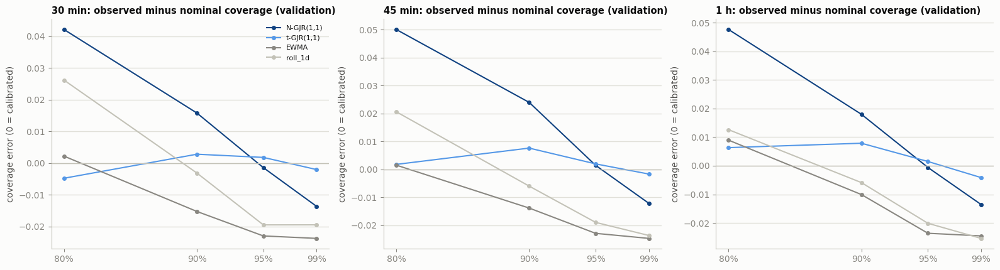

In [10]:
import sys, warnings, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from scipy.special import gammaln
import numba as nb
warnings.filterwarnings("ignore")
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid

# ---------------- variance recursion: GARCH(p,q) / GJR(p,q); nu > 0 -> unit-variance Student-t density, nu <= 0 -> NORMAL density ----------------
RHO_MAX = 0.9999
@nb.njit
def _run(u, om, alpha, gam, beta, s0, nu):
    n = u.shape[0]; p = alpha.shape[0]; q = beta.shape[0]; sig2 = np.empty(n); e2 = np.empty(n); en = np.empty(n)
    c = math.lgamma((nu + 1.0) / 2.0) - math.lgamma(nu / 2.0) - 0.5 * math.log(math.pi * (nu - 2.0)) if nu > 0.0 else -0.5 * math.log(2.0 * math.pi)
    ll = 0.0
    for t in range(n):
        s = om
        for i in range(p):
            j = t - 1 - i
            if j >= 0: s += alpha[i] * e2[j]
            else: s += alpha[i] * s0
        if t >= 1: s += gam * en[t - 1]
        else: s += gam * 0.5 * s0
        for i in range(q):
            j = t - 1 - i
            if j >= 0: s += beta[i] * sig2[j]
            else: s += beta[i] * s0
        s = min(max(s, 1e-10), 1e10); sig2[t] = s; x = u[t]
        if np.isnan(x): e2[t] = s; en[t] = 0.5 * s
        else:
            x2 = x * x; e2[t] = x2; en[t] = x2 if x < 0.0 else 0.0
            if nu > 0.0: ll += c - 0.5 * math.log(s) - 0.5 * (nu + 1.0) * math.log1p(x2 / (s * (nu - 2.0)))
            else: ll += c - 0.5 * math.log(s) - 0.5 * x2 / s
    return sig2, ll

@nb.njit
def _ewma(u, lam, s0):
    n = u.shape[0]; out = np.empty(n); sp = s0; ep = s0
    for t in range(n):
        s = lam * sp + (1.0 - lam) * ep; out[t] = s; x = u[t]; ep = s if np.isnan(x) else x * x; sp = s
    return out

# Gaussian fit: theta = [log omega, logit rho, K-1 softmax logits]; coefficients = rho * softmax, so non-negative and stationary by construction
def bnds(K): return [(-20.0, 5.0)] if K == 0 else [(-20.0, 5.0), (-12.0, 12.0)] + [(-12.0, 12.0)] * (K - 1)
def unpack(th, p, q, gjr):
    K = p + int(gjr) + q; om = math.exp(th[0])
    if K == 0: return om, np.zeros(0), 0.0, np.zeros(0)
    rho = RHO_MAX / (1.0 + math.exp(-th[1])); z = np.concatenate([th[2:2 + K - 1], [0.0]]); w = np.exp(z - z.max()); w /= w.sum(); c = rho * w
    return om, c[:p], (2.0 * c[p] if gjr else 0.0), c[p + int(gjr):]
def to_theta(par, p, q, gjr):
    K = p + int(gjr) + q
    if K == 0: return np.array([math.log(par["om"])])
    c = np.concatenate([par["a"], [par["g"] / 2.0] if gjr else [], par["b"]]); c = np.maximum(c, 1e-6)
    if c.sum() > 0.999: c = c * (0.999 / c.sum())
    rho = c.sum(); z = np.log(c) - np.log(c[-1]); r = rho / RHO_MAX; th = np.concatenate([[math.log(par["om"]), math.log(r / (1.0 - r))], z[:-1]])
    b = bnds(K); return np.clip(th, [x[0] for x in b], [x[1] for x in b])
def generic(p, q, gjr, rho0, s2):
    if p + q == 0: return dict(om=s2, a=np.zeros(0), g=0.0, b=np.zeros(0), gjr=False)
    w = np.concatenate([[0.12, 0.03][:p], [0.04] if gjr else [], [0.80, 0.05][:q]]); c = w * rho0 / w.sum()
    return dict(om=s2 * (1.0 - rho0), a=c[:p], g=(2.0 * c[p] if gjr else 0.0), b=c[p + int(gjr):], gjr=gjr)
def embed(par, p, q, gjr):
    a = np.full(p, 0.005); a[:len(par["a"])] = par["a"]; b = np.full(q, 0.005); b[:len(par["b"])] = par["b"]
    return dict(om=par["om"], a=a, g=par["g"] if (gjr and par["gjr"]) else (0.01 if gjr else 0.0), b=b, gjr=gjr)
def fit_one(u, p, q, gjr, donors, s2):
    K = p + int(gjr) + q; N = int(np.isfinite(u).sum()); u = np.ascontiguousarray(u, dtype=np.float64)
    def f(th):
        om, a, g_, b = unpack(th, p, q, gjr); ll = _run(u, om, a, g_, b, s2, 0.0)[1]; return 1e10 if not np.isfinite(ll) else -ll / N
    starts = [to_theta(d_, p, q, gjr) for d_ in donors] + [to_theta(generic(p, q, gjr, r0, s2), p, q, gjr) for r0 in (0.95, 0.99, 0.90)[: (3 if not donors else 1)]]
    opt = dict(maxiter=500, maxfun=60000, ftol=1e-13, gtol=1e-7); runs = [optimize.minimize(f, th0, method="L-BFGS-B", bounds=bnds(K), options=opt) for th0 in starts]
    best = min(runs, key=lambda r: r.fun); r2_ = optimize.minimize(f, best.x, method="L-BFGS-B", bounds=bnds(K), options=opt)
    if r2_.fun < best.fun: best = r2_
    lls = np.array([-r.fun * N for r in runs]); ll = -best.fun * N; om, a, g_, b = unpack(best.x, p, q, gjr)
    return dict(par=dict(om=om, a=a, g=g_, b=b, gjr=gjr), ll=ll, N=N, k=K + 1, ok=bool(best.success), agree=float(np.mean(lls > ll - 1.0)), rho=float(a.sum() + g_ / 2.0 + b.sum()))

def roll_var(u, k, fallback):
    f = np.isfinite(u); s = np.where(f, u * u, 0.0); cs = np.r_[0.0, np.cumsum(s)]; cc = np.r_[0.0, np.cumsum(f)]
    a = np.arange(len(u)); lo = np.maximum(0, a - k); num = cs[a] - cs[lo]; cnt = cc[a] - cc[lo]
    return np.maximum(np.where(cnt >= max(2, k // 2), num / np.maximum(cnt, 1), fallback), 1e-8)
def r2(a, b): return float(np.corrcoef(a, b)[0, 1] ** 2)
def dm(dif, L):
    n = len(dif); mu = dif.mean(); x = dif - mu; s = x @ x / n
    for l in range(1, L + 1): s += 2 * (1 - l / (L + 1)) * (x[l:] @ x[:-l]) / n
    z = mu / math.sqrt(max(s, 1e-18) / n); return float(mu), float(z), float(2 * stats.norm.sf(abs(z)))

# ---- data, windows, training-only scaling: same as Steps 1-4 ----
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds(); idx = dev.index
assert idx.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
EMBt = pd.Timedelta(minutes=5 * P.embargo_steps)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy(); n = len(y)
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy(); yb = y.copy(); yb[bad] = np.nan
SCALES = {"30 min": 6, "45 min": 9, "1 h": 12}; SC = list(SCALES); WN = [w.name for w in folds]
PAR = pd.read_csv(RUN / "reports" / "gjr11_params_frozen.csv").set_index(["scale", "window"])
S2 = pd.read_csv(RUN / "reports" / "garch_order_selection.csv"); S2 = S2[S2.scale.isin(SC)]; G11 = S2[S2.model == "GARCH(1,1)"].set_index(["scale", "window"])
CANDS = [("const", 0, 0, False), ("GARCH(1,1)", 1, 1, False), ("GJR(1,1)", 1, 1, True), ("GARCH(1,2)", 1, 2, False), ("GARCH(2,1)", 2, 1, False),
         ("GJR(1,2)", 1, 2, True), ("GJR(2,1)", 2, 1, True), ("GARCH(2,2)", 2, 2, False), ("GJR(2,2)", 2, 2, True)]; INFO = {c[0]: c[1:] for c in CANDS}
NM = ["N-" + c[0] for c in CANDS[1:]]; MODELS = NM + ["t-GJR(1,1)", "t-GARCH(1,1)", "EWMA", "roll_1d", "roll_6h", "const"]; REF = "t-GJR(1,1)"
TMOD = {"t-GJR(1,1)", "t-GARCH(1,1)"}; LAMS = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.94, 0.97, 0.99]; LV = [0.8, 0.9, 0.95, 0.99]

store, fit_rows = {}, []
for sname, step in SCALES.items():
    ends = np.arange(step, n, step); d = yb[ends] - yb[ends - step]; te = idx[ends]; tb = (te.hour * 2 + te.minute // 30).to_numpy(); fin = np.isfinite(d)
    day = np.asarray((te.normalize() - idx[0].normalize()).days); dt = pd.Timedelta(minutes=5 * step); src = {}
    for w in folds:
        pre = np.asarray(te <= w.val_start - EMBt)                                              # TRAINING rows only for every fit and every scale table
        sc = pd.Series(np.abs(d[pre & fin])).groupby(tb[pre & fin]).mean(); srow = sc.reindex(tb).to_numpy(); u = d / srow
        p_ = PAR.loc[(sname, w.name)]; q_ = G11.loc[(sname, w.name)]; s0 = float(p_.s0); ut = u[pre]; uf = ut[np.isfinite(ut)]; s2 = float(np.mean(np.minimum(uf ** 2, np.quantile(uf ** 2, 0.99))))
        assert abs(s2 - s0) < 1e-9 * max(1.0, s0), "start variance does not match Step 3"
        assert len(ut) == int(pre.sum()) and te[pre].max() <= w.val_start - EMBt, "fit sample is not the training prefix"
        fits = {}; v = {"const": np.full(len(u), float(np.mean(uf ** 2)))}
        for name, p, q, gjr in CANDS:
            donors = [embed(fits[k]["par"], p, q, gjr) for k, (p2, q2, g2) in INFO.items() if k in fits and k != "const" and p2 <= p and q2 <= q and int(g2) <= int(gjr) and (p - p2) + (q - q2) + (int(gjr) - int(g2)) == 1]
            fits[name] = fit_one(ut, p, q, gjr, donors, s2)                                           # fit on TRAINING rows only
            if name != "const": pr = fits[name]["par"]; v["N-" + name] = _run(u, pr["om"], pr["a"], pr["g"], pr["b"], s0, 0.0)[0]
        for name, p, q, gjr in CANDS:
            f = fits[name]; pr = f["par"]; gap = min([f["ll"] - fits[k]["ll"] for k, (p2, q2, g2) in INFO.items() if k != name and p2 <= p and q2 <= q and int(g2) <= int(gjr)], default=np.nan)
            fit_rows.append(dict(scale=sname, window=w.name, model=name, N=f["N"], k=f["k"], ll=f["ll"], aic=2 * f["k"] - 2 * f["ll"], bic=f["k"] * np.log(f["N"]) - 2 * f["ll"], rho=f["rho"],
                                 alpha1=pr["a"][0] if p else np.nan, gamma=pr["g"] if gjr else np.nan, beta1=pr["b"][0] if q else np.nan, nest_gap=gap, converged=f["ok"], agree=f["agree"]))
        v["t-GJR(1,1)"] = _run(u, p_.omega, np.array([p_.alpha1]), p_.gamma, np.array([p_.beta1]), s0, float(p_.nu))[0]
        v["t-GARCH(1,1)"] = _run(u, q_.omega, np.array([q_.alpha1]), 0.0, np.array([q_.beta1]), s0, float(q_.nu))[0]
        v["roll_6h"] = roll_var(u, max(2, 360 // (5 * step)), v["const"][0]); v["roll_1d"] = roll_var(u, max(2, 1440 // (5 * step)), v["const"][0])
        tl = [np.mean(np.log(_ewma(np.ascontiguousarray(ut), lm, s0)[np.isfinite(ut)]) + uf ** 2 / _ewma(np.ascontiguousarray(ut), lm, s0)[np.isfinite(ut)]) for lm in LAMS]
        v["EWMA"] = _ewma(np.ascontiguousarray(u), LAMS[int(np.argmin(tl))], s0); src[w.name] = dict(u=u, srow=srow, v=v, nu=float(p_.nu))
    for scheme in ("frozen", "refit"):
        for k, w in enumerate(folds):
            S = src["cv1"] if scheme == "frozen" else src[w.name]; vm = (te - dt >= w.val_start) & (te < w.val_end) & fin
            u = S["u"][vm]; lsc = np.log(S["srow"][vm]); nu = S["nu"]; ct = math.lgamma((nu + 1) / 2) - math.lgamma(nu / 2) - 0.5 * math.log(math.pi * (nu - 2))
            qn = {c: stats.norm.ppf((1 + c) / 2) for c in LV}; qt = {c: stats.t.ppf((1 + c) / 2, nu) * math.sqrt((nu - 2) / nu) for c in LV}
            for m in MODELS:
                vv = S["v"][m][vm]; sd = np.sqrt(vv); qq = qt if m in TMOD else qn
                rec = dict(fold=np.full(len(u), k), day=day[vm], au=np.abs(u), u2=u * u, sd=sd, v=vv, ql=np.log(vv) + u * u / vv + 2 * lsc,
                           lsn=-0.5 * math.log(2 * math.pi) - 0.5 * np.log(vv) - 0.5 * u * u / vv - lsc,
                           lst=ct - 0.5 * np.log(vv) - 0.5 * (nu + 1) * np.log1p(u * u / (vv * (nu - 2))) - lsc,
                           up95=(u > qq[0.95] * sd).astype(float), dn95=(u < -qq[0.95] * sd).astype(float))
                for c in LV: rec[f"cov{int(c * 100)}"] = (np.abs(u) <= qq[c] * sd).astype(float)
                store.setdefault((sname, scheme, m), []).append(rec)

def pool(key): L = store[key]; return {c: np.concatenate([x[c] for x in L]) for c in L[0]}
FR = pd.DataFrame(fit_rows); key = ["scale", "window"]
ref = FR[FR.model == "GARCH(1,1)"][key + ["ll", "aic", "bic"]].rename(columns=dict(ll="ll0", aic="aic0", bic="bic0")); FR = FR.merge(ref, on=key)
FR["dBIC"] = FR.bic - FR.bic0; FR["gain_mnats_row"] = 1000 * (FR.ll - FR.ll0) / FR.N
TT = S2[["scale", "window", "model", "ll", "bic"]].rename(columns=dict(ll="ll_t", bic="bic_t")); FR = FR.merge(TT, on=key + ["model"], how="left")
FR["t_minus_N_mnats_row"] = 1000 * (FR.ll_t - FR.ll) / FR.N; FR["dBIC_t_vs_N"] = FR.bic_t - FR.bic
FR.drop(columns=["ll0", "aic0", "bic0"]).to_csv(RUN / "reports" / "garch_normal_order_selection.csv", index=False)

rows, dmr, bsr = [], [], []; rng = np.random.default_rng(0)
for sname in SC:
    L = 288 // SCALES[sname]
    for scheme in ("frozen", "refit"):
        for m in MODELS:
            Q = pool((sname, scheme, m)); rows.append(dict(scale=sname, scheme=scheme, model=m, n=len(Q["au"]), ql=Q["ql"].mean(), lsn=Q["lsn"].mean(), lst=Q["lst"].mean(),
                R2_abs=r2(Q["au"], Q["sd"]) if Q["sd"].std() > 1e-9 else 0.0, R2_sq=r2(Q["u2"], Q["v"]) if Q["v"].std() > 1e-9 else 0.0,
                spearman=float(stats.spearmanr(Q["au"], Q["sd"])[0]) if Q["sd"].std() > 1e-9 else 0.0, up95_ratio=Q["up95"].mean() / 0.025, dn95_ratio=Q["dn95"].mean() / 0.025,
                **{f"cov{int(c * 100)}": Q[f"cov{int(c * 100)}"].mean() for c in LV}))
    for scheme, A, B in [("refit", "N-GJR(1,1)", REF), ("refit", "N-GJR(1,1)", "N-GARCH(1,1)"), ("refit", "N-GJR(1,1)", "EWMA"), ("refit", "N-GJR(1,1)", "roll_1d"), ("refit", REF, "EWMA"), ("frozen", "N-GJR(1,1)", REF)]:
        QA, QB = pool((sname, scheme, A)), pool((sname, scheme, B)); r = dict(scale=sname, scheme=scheme, A=A, B=B)
        for nm, col, sgn in (("QL", "ql", 1), ("LSn", "lsn", -1), ("LSt", "lst", -1)):
            mu, z, p_ = dm(sgn * (QB[col] - QA[col]), L); r[f"d{nm}"] = mu; r[f"z_{nm}"] = z
        dmr.append(r)
    for A, B in (("N-GJR(1,1)", REF), ("N-GJR(1,1)", "EWMA")):
        QA, QB = pool((sname, "refit", A)), pool((sname, "refit", B)); ud = np.unique(QA["day"]); ix = [np.flatnonzero(QA["day"] == x) for x in ud]; bs = []
        for _ in range(300):
            ii = np.concatenate([ix[j] for j in rng.integers(0, len(ud), len(ud))]); bs.append(r2(QA["au"][ii], QA["sd"][ii]) - r2(QB["au"][ii], QB["sd"][ii]))
        bsr.append(dict(scale=sname, A=A, B=B, dR2_abs=r2(QA["au"], QA["sd"]) - r2(QB["au"], QB["sd"]), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5)))
T = pd.DataFrame(rows); DMT = pd.DataFrame(dmr); BS = pd.DataFrame(bsr)
T.to_csv(RUN / "reports" / "normal_vs_t_scores.csv", index=False); DMT.to_csv(RUN / "reports" / "normal_vs_t_dm.csv", index=False); BS.to_csv(RUN / "reports" / "normal_vs_t_r2_bootstrap.csv", index=False)
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:.4f}".format)
MN = [c[0] for c in CANDS]; ORD = lambda df: df.reindex(MN)[WN]

print("PART 1 - NORMAL (Gaussian) innovations, fitted on TRAINING rows only; same windows, scales and series as Steps 1-4. n = number of non-gap training rows.")
for s in SC:
    q = FR[FR.scale == s]; print(f"\n=== {s}: BIC minus BIC of N-GARCH(1,1)  (negative = better; {int(q.N.min())}..{int(q.N.max())} rows) ===")
    print(ORD(q.pivot(index="model", columns="window", values="dBIC")).round(1))
for crit in ("bic", "aic"):
    print(f"\nbest Gaussian model by {crit.upper()}"); print(FR.loc[FR.groupby(key)[crit].idxmin()].pivot(index="scale", columns="window", values="model").reindex(SC)[WN])
print("\nGaussian log-likelihood gain over N-GARCH(1,1), milli-nats per row (mean over windows)"); print(FR.pivot_table(index="model", columns="scale", values="gain_mnats_row").reindex(MN)[SC].round(3))
for mdl in ("GARCH(1,1)", "GJR(1,1)"):
    q = FR[FR.model == mdl]; print(f"\nN-{mdl}: persistence"); print(q.pivot(index="scale", columns="window", values="rho").reindex(SC)[WN].round(4))
q = FR[FR.model == "GJR(1,1)"]; print("\nN-GJR(1,1): 1 + gamma/alpha1 (down-move vs up-move response)"); print((1 + q.pivot(index="scale", columns="window", values="gamma") / q.pivot(index="scale", columns="window", values="alpha1")).reindex(SC)[WN].round(2))
for mdl in ("GJR(1,1)", "GARCH(1,1)"):
    q = FR[FR.model == mdl]; print(f"\nIN-SAMPLE, {mdl}: how much better the Student-t fits the same training rows than the normal, milli-nats per row (positive = t better)")
    print(q.pivot(index="scale", columns="window", values="t_minus_N_mnats_row").reindex(SC)[WN].round(2))
    print(f"{mdl}: BIC(t) - BIC(normal), negative = t wins even after paying for nu"); print(q.pivot(index="scale", columns="window", values="dBIC_t_vs_N").reindex(SC)[WN].round(1))
print(f"\nconvergence: nested-model violations {int((FR.nest_gap < -0.5).sum())} of {len(FR)}; fits where not every start reached the best likelihood: {int((FR.agree < 1).sum())}; fits reporting no convergence: {int((~FR.converged).sum())}")

print("\n\nPART 2 - VALIDATION windows cv1..cv5 pooled (sealed test untouched). refit = each window's own training fit; frozen = cv1's fit for all windows.")
print(f"Differences are measured against {REF} in the same scheme. dQLIKE: positive = worse. dLogScore columns: positive = BETTER. N-* = normal fit, t-* = Student-t fit.")
print("LS_normal scores every forecast with a normal density, LS_t scores every forecast with a Student-t density (nu = the t-GJR fit's), so each row is judged on the same footing.")
for s in SC:
    q = T[(T.scale == s) & (T.scheme == "refit")].set_index("model").reindex(MODELS); r_ = q.loc[REF]
    out = pd.DataFrame({"dQLIKE": q.ql - r_.ql, "dLS_normal": q.lsn - r_.lsn, "dLS_t": q.lst - r_.lst, "R2_abs": q.R2_abs, "R2_sq": q.R2_sq, "spearman": q.spearman})
    print(f"\n=== {s}, refit  (n = {int(q.n.iloc[0])} scored changes) ==="); print(out)
print("\nCALIBRATION on validation (refit): observed share of changes inside the model's own central band (nominal in the header), centred on ZERO. Normal bands for N-*, EWMA, rolling, const; t bands for t-*.")
print("up95/dn95 = observed / nominal 2.5% for the upper / lower tail of the 95% band (1 = calibrated).")
for s in SC:
    q = T[(T.scale == s) & (T.scheme == "refit")].set_index("model").reindex(MODELS); print(f"\n{s}"); print(q[["cov80", "cov90", "cov95", "cov99", "up95_ratio", "dn95_ratio"]])
print("\nDiebold-Mariano, pooled over folds, HAC lag = 24 h of rows. Positive d* = model A is better than model B; z is the DM statistic (|z| > 2 is about p < 0.05).")
print(DMT.set_index(["scale", "scheme", "A", "B"]).round(4))
print("\nR2_abs of model A minus model B, day-block bootstrap 95% interval (refit, pooled folds)"); print(BS.set_index(["scale", "A", "B"]).round(4))

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "semibold", "legend.frameon": False})
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4)); cols = {"N-GJR(1,1)": "#104281", REF: "#5598e7", "EWMA": "#898781", "roll_1d": "#c3c2b7"}
for a, s in zip(ax, SC):
    q = T[(T.scale == s) & (T.scheme == "refit")].set_index("model")
    for m, col in cols.items(): a.plot(LV, [q.loc[m, f"cov{int(c * 100)}"] - c for c in LV], "-o", ms=4, lw=1.5, color=col, label=m)
    a.axhline(0, color=AXIS, lw=1); a.set_xticks(LV); a.set_xticklabels(["80%", "90%", "95%", "99%"]); a.set_title(f"{s}: observed minus nominal coverage (validation)"); a.set_ylabel("coverage error (0 = calibrated)")
ax[0].legend(fontsize=8); fig.tight_layout(); fig.savefig(RUN / "figs" / "normal_vs_t_calibration.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output**

**Part 1 (in sample).**
* The Student-$t$ fits the same training rows far better than the normal: **50–90 milli-nats per row**, with **BIC$(t)$ − BIC(normal) of −324 … −2,634** (negative = $t$ wins even after paying for $\nu$).
* Under the Gaussian, persistence hits the **0.9999 cap everywhere**: a Gaussian likelihood treats outliers as "variance shocks that never decay".
* **Asymmetry (Gaussian GJR(1,1))**: $1+\gamma/\alpha_1$ rises from 1.31 (cv1) to **2.14** (cv5) at 30 min, 1.59 → 2.39 at 45 min and 1.59 → 2.12 at 1 h: a fall raises next-period variance up to **2.1–2.4 times as much as a rise of the same size**, growing with data.
* Order choice under the Gaussian again favours `GJR(1,2)`; the second shock lag is unused.

**Part 2 (validation).**
* On **ranking**, normal and $t$ are equivalent: $R^2_{|\cdot|}$ N-GJR(1,1) 0.1637 vs t-GJR(1,1) 0.1615 (30 min); the **DM test on the $t$ log score** between them has $|z|\le1.1$ at every scale (−0.59, +0.44, −1.03). The Gaussian's QLIKE edge (z ≈ 2.1–2.4) is expected because QLIKE *is* the Gaussian deviance.
* The best of the nine by pooled $R^2_{|\cdot|}$ is **N-GJR(1,2)** (0.1661 / 0.1567 / 0.1368), a hair above t-GJR(1,1) (0.1615 / 0.1499 / 0.1334); the bootstrap interval for N-GJR(1,1) − t-GJR(1,1) at 30 min is [−0.000, +0.004]: **not a real difference**.
* **Shape of the bands (30 min):**

| Model | 80 % band | 90 % | 95 % | 99 % |
|---|---|---|---|---|
| nominal | 0.80 | 0.90 | 0.95 | 0.99 |
| N-GJR(1,1) | **0.842** | 0.916 | 0.949 | **0.976** |
| **t-GJR(1,1)** | 0.795 | 0.903 | 0.952 | **0.988** |
| EWMA | 0.802 | 0.885 | 0.927 | 0.966 |
| roll_6h | 0.783 | 0.867 | 0.911 | 0.956 |

The **Normal bands are too wide at 80 % and 90 % and too narrow at 99 %** (the textbook sign of ignoring fat tails). The **$t$ bands are calibrated** at every level. EWMA and the rolling windows **under-cover** (the 95 % band covers only 89–93 %).
* **Tail asymmetry:** for the GARCH family the upper tail of the 95 % band is breached **1.2–1.35× the nominal rate** and the lower tail **0.66–0.79×**. All bands are centred on zero while the changes are positively skewed. This is what motivates re-centring on the point forecast in Part 9.

✅ **Take-away.** The innovation law barely changes how well risk is *ranked*; it matters for the **shape of the interval**. Hence pivot 11: **Student-$t$ is a calibration choice, not a model choice.**

## 8.6 Best-model figures (cv5 validation window)

📘 **What.** For each scale, one panel per variance model (nine panels: N-GJR(1,2), N-GJR(1,1), N-GARCH(1,1), t-GJR(1,1), t-GARCH(1,1), EWMA, roll_1d, roll_6h, const), each showing the 95 % band built from the forecast sd, with **breaches marked** and the panel's pooled-validation $R^2_{|\cdot|}$. The best model is picked **by pooled validation** $R^2_{|\cdot|}$ over cv1–cv5, but the panels are drawn on **cv5 only** (2018-05-12 → 2018-06-28), refitted on cv5's own training rows. The cell first re-checks that its Gaussian GJR(1,2) refit reproduces the log-likelihood of Step 5.

(This cell is the first run. Cell 48 below is the same code with two lines added to save the panel data, so either one can be dropped in a final clean version.)

30 min: Gaussian GJR(1,2) refit log-lik -24355.42 vs Step 5 report -24355.42  (should agree to ~0.1)
30 min: best by pooled validation R2_abs = N-GJR(1,2) (0.1661); plotted window cv5: 2018-05-12 to 2018-06-28, 2297 changes


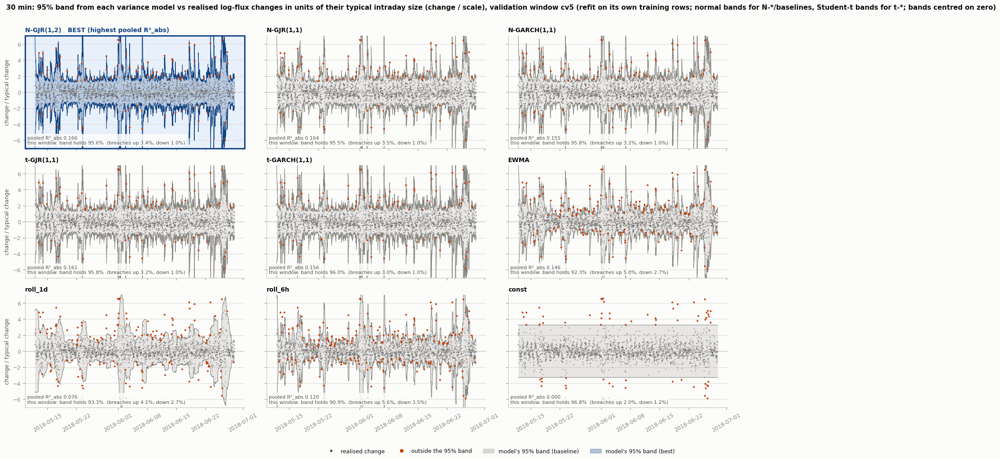

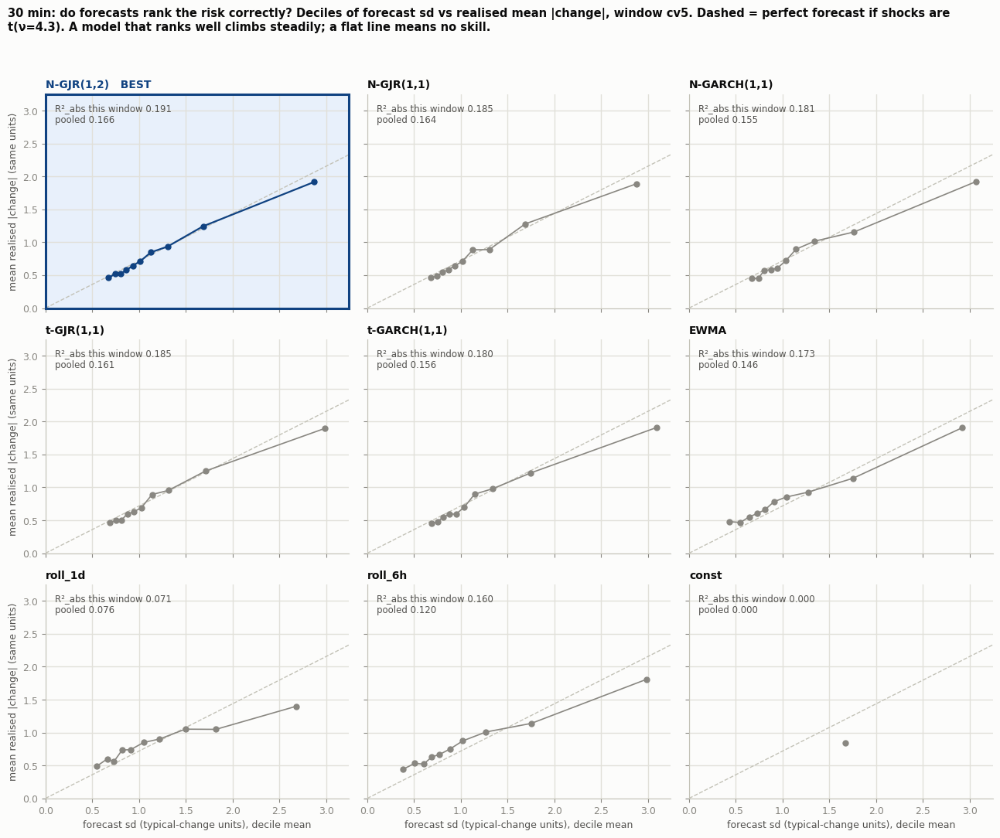

45 min: Gaussian GJR(1,2) refit log-lik -16217.48 vs Step 5 report -16217.48  (should agree to ~0.1)
45 min: best by pooled validation R2_abs = N-GJR(1,2) (0.1567); plotted window cv5: 2018-05-12 to 2018-06-28, 1533 changes


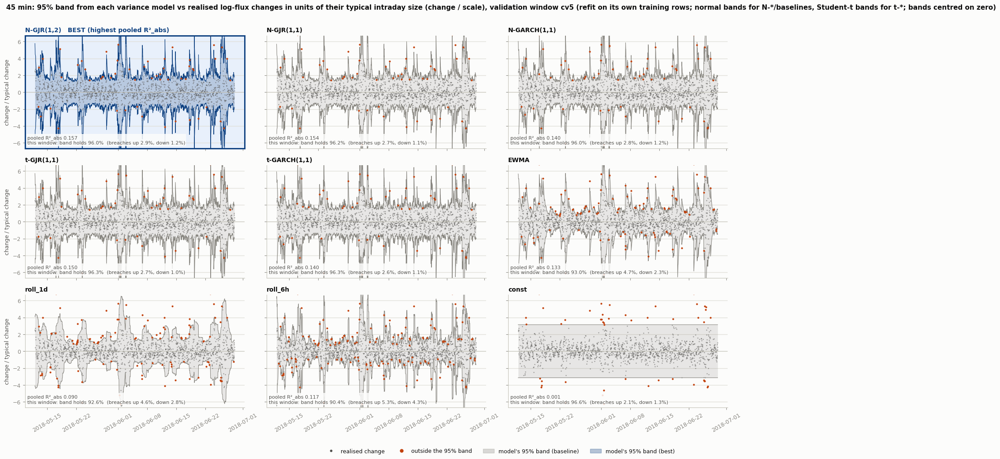

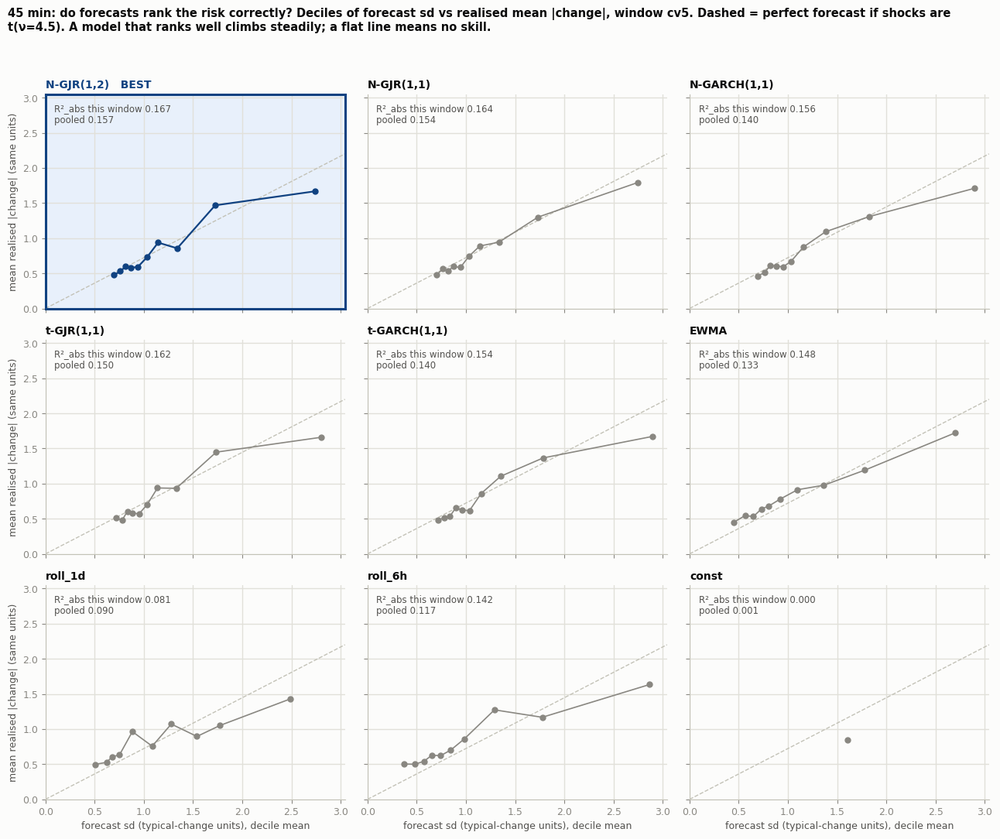

1 h: Gaussian GJR(1,2) refit log-lik -12263.25 vs Step 5 report -12263.25  (should agree to ~0.1)
1 h: best by pooled validation R2_abs = N-GJR(1,2) (0.1368); plotted window cv5: 2018-05-12 to 2018-06-28, 1147 changes


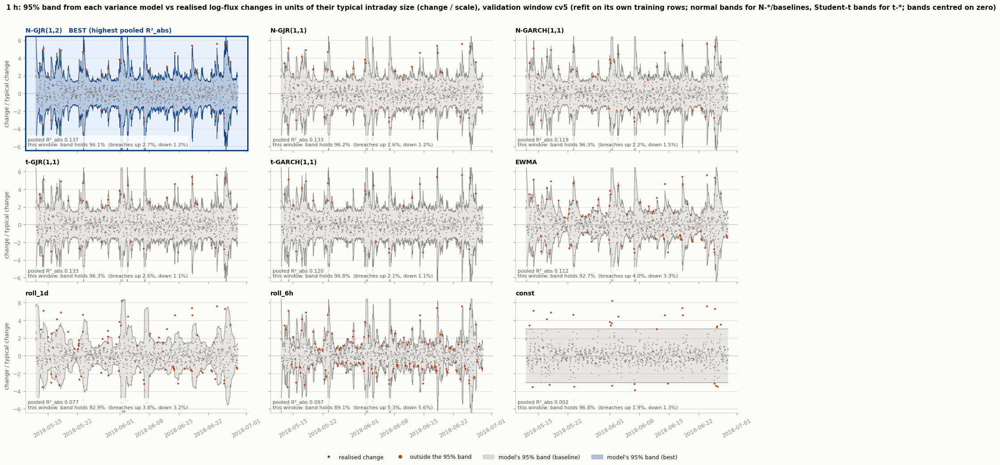

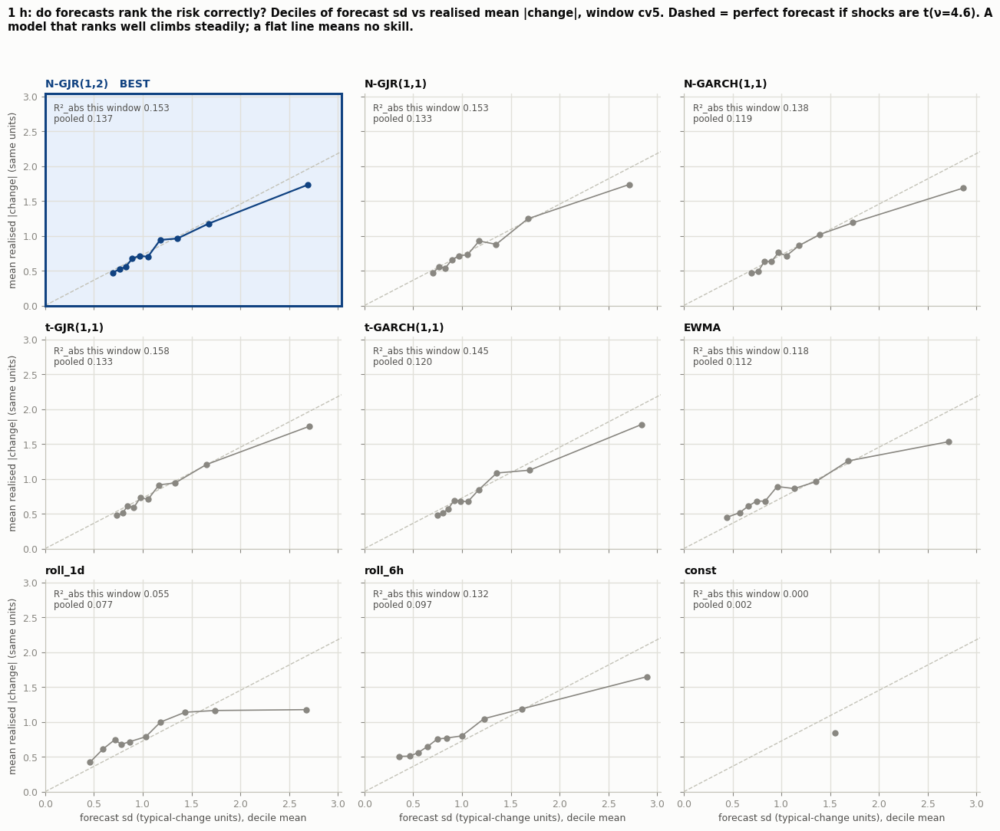

In [11]:
import sys, warnings, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from scipy.special import gammaln
import numba as nb
warnings.filterwarnings("ignore")
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid

WINDOW = "cv5"                                  # window whose validation period is drawn (cv5 = the static window); refit on its own training rows
SHOW = ["30 min", "45 min", "1 h"]              # one pair of figures per scale
PANELS = ["N-GJR(1,2)", "N-GJR(1,1)", "N-GARCH(1,1)", "t-GJR(1,1)", "t-GARCH(1,1)", "EWMA", "roll_1d", "roll_6h", "const"]
TMOD = {"t-GJR(1,1)", "t-GARCH(1,1)"}; SCALES = {"30 min": 6, "45 min": 9, "1 h": 12}

# ---------------- same variance recursion and Gaussian fit as Step 5 (nu <= 0 -> normal density) ----------------
RHO_MAX = 0.9999
@nb.njit
def _run(u, om, alpha, gam, beta, s0, nu):
    n = u.shape[0]; p = alpha.shape[0]; q = beta.shape[0]; sig2 = np.empty(n); e2 = np.empty(n); en = np.empty(n)
    c = math.lgamma((nu + 1.0) / 2.0) - math.lgamma(nu / 2.0) - 0.5 * math.log(math.pi * (nu - 2.0)) if nu > 0.0 else -0.5 * math.log(2.0 * math.pi)
    ll = 0.0
    for t in range(n):
        s = om
        for i in range(p):
            j = t - 1 - i
            if j >= 0: s += alpha[i] * e2[j]
            else: s += alpha[i] * s0
        if t >= 1: s += gam * en[t - 1]
        else: s += gam * 0.5 * s0
        for i in range(q):
            j = t - 1 - i
            if j >= 0: s += beta[i] * sig2[j]
            else: s += beta[i] * s0
        s = min(max(s, 1e-10), 1e10); sig2[t] = s; x = u[t]
        if np.isnan(x): e2[t] = s; en[t] = 0.5 * s
        else:
            x2 = x * x; e2[t] = x2; en[t] = x2 if x < 0.0 else 0.0
            if nu > 0.0: ll += c - 0.5 * math.log(s) - 0.5 * (nu + 1.0) * math.log1p(x2 / (s * (nu - 2.0)))
            else: ll += c - 0.5 * math.log(s) - 0.5 * x2 / s
    return sig2, ll

@nb.njit
def _ewma(u, lam, s0):
    n = u.shape[0]; out = np.empty(n); sp = s0; ep = s0
    for t in range(n):
        s = lam * sp + (1.0 - lam) * ep; out[t] = s; x = u[t]; ep = s if np.isnan(x) else x * x; sp = s
    return out

def bnds(K): return [(-20.0, 5.0)] if K == 0 else [(-20.0, 5.0), (-12.0, 12.0)] + [(-12.0, 12.0)] * (K - 1)
def unpack(th, p, q, gjr):
    K = p + int(gjr) + q; om = math.exp(th[0])
    rho = RHO_MAX / (1.0 + math.exp(-th[1])); z = np.concatenate([th[2:2 + K - 1], [0.0]]); w = np.exp(z - z.max()); w /= w.sum(); c = rho * w
    return om, c[:p], (2.0 * c[p] if gjr else 0.0), c[p + int(gjr):]
def to_theta(par, p, q, gjr):
    K = p + int(gjr) + q
    c = np.concatenate([par["a"], [par["g"] / 2.0] if gjr else [], par["b"]]); c = np.maximum(c, 1e-6)
    if c.sum() > 0.999: c = c * (0.999 / c.sum())
    rho = c.sum(); z = np.log(c) - np.log(c[-1]); r = rho / RHO_MAX; th = np.concatenate([[math.log(par["om"]), math.log(r / (1.0 - r))], z[:-1]])
    b = bnds(K); return np.clip(th, [x[0] for x in b], [x[1] for x in b])
def generic(p, q, gjr, rho0, s2):
    w = np.concatenate([[0.12, 0.03][:p], [0.04] if gjr else [], [0.80, 0.05][:q]]); c = w * rho0 / w.sum()
    return dict(om=s2 * (1.0 - rho0), a=c[:p], g=(2.0 * c[p] if gjr else 0.0), b=c[p + int(gjr):], gjr=gjr)
def embed(par, p, q, gjr):
    a = np.full(p, 0.005); a[:len(par["a"])] = par["a"]; b = np.full(q, 0.005); b[:len(par["b"])] = par["b"]
    return dict(om=par["om"], a=a, g=par["g"] if (gjr and par["gjr"]) else (0.01 if gjr else 0.0), b=b, gjr=gjr)
def fit_one(u, p, q, gjr, donors, s2):
    K = p + int(gjr) + q; N = int(np.isfinite(u).sum()); u = np.ascontiguousarray(u, dtype=np.float64)
    def f(th):
        om, a, g_, b = unpack(th, p, q, gjr); ll = _run(u, om, a, g_, b, s2, 0.0)[1]; return 1e10 if not np.isfinite(ll) else -ll / N
    starts = [to_theta(d_, p, q, gjr) for d_ in donors] + [to_theta(generic(p, q, gjr, r0, s2), p, q, gjr) for r0 in (0.95, 0.99, 0.90)[: (3 if not donors else 1)]]
    opt = dict(maxiter=500, maxfun=60000, ftol=1e-13, gtol=1e-7); runs = [optimize.minimize(f, th0, method="L-BFGS-B", bounds=bnds(K), options=opt) for th0 in starts]
    best = min(runs, key=lambda r: r.fun); r2_ = optimize.minimize(f, best.x, method="L-BFGS-B", bounds=bnds(K), options=opt)
    if r2_.fun < best.fun: best = r2_
    om, a, g_, b = unpack(best.x, p, q, gjr)
    return dict(par=dict(om=om, a=a, g=g_, b=b, gjr=gjr), ll=-best.fun * N, N=N)

def roll_var(u, k, fallback):
    f = np.isfinite(u); s = np.where(f, u * u, 0.0); cs = np.r_[0.0, np.cumsum(s)]; cc = np.r_[0.0, np.cumsum(f)]
    a = np.arange(len(u)); lo = np.maximum(0, a - k); num = cs[a] - cs[lo]; cnt = cc[a] - cc[lo]
    return np.maximum(np.where(cnt >= max(2, k // 2), num / np.maximum(cnt, 1), fallback), 1e-8)
def r2(a, b): return float(np.corrcoef(a, b)[0, 1] ** 2) if np.std(b) > 1e-9 else 0.0
def e_abs_t(nu): return 2 * math.sqrt(nu - 2) * math.exp(gammaln((nu + 1) / 2) - gammaln(nu / 2)) / (math.sqrt(math.pi) * (nu - 1))   # E|z| of a unit-variance Student-t

# ---------------- data and tables written by earlier steps ----------------
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds(); idx = dev.index
assert idx.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
EMBt = pd.Timedelta(minutes=5 * P.embargo_steps); w = next(x for x in folds if x.name == WINDOW)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy(); n = len(y)
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy(); yb = y.copy(); yb[bad] = np.nan
PAR = pd.read_csv(RUN / "reports" / "gjr11_params_frozen.csv").set_index(["scale", "window"])
S2 = pd.read_csv(RUN / "reports" / "garch_order_selection.csv"); G11 = S2[S2.model == "GARCH(1,1)"].set_index(["scale", "window"])
SC_T = pd.read_csv(RUN / "reports" / "normal_vs_t_scores.csv"); NF = pd.read_csv(RUN / "reports" / "garch_normal_order_selection.csv")
LAMS = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.94, 0.97, 0.99]

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"; ACC, ACC_L, BRK = "#104281", "#e8f0fb", "#c2410c"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 10, "axes.titleweight": "semibold", "legend.frameon": False})

for sname in SHOW:
    step = SCALES[sname]; ends = np.arange(step, n, step); d = yb[ends] - yb[ends - step]; te = idx[ends]; tb = (te.hour * 2 + te.minute // 30).to_numpy(); fin = np.isfinite(d)
    dt = pd.Timedelta(minutes=5 * step); pre = np.asarray(te <= w.val_start - EMBt)                    # TRAINING rows only for every fit
    sc = pd.Series(np.abs(d[pre & fin])).groupby(tb[pre & fin]).mean(); srow = sc.reindex(tb).to_numpy(); u = d / srow
    p_ = PAR.loc[(sname, WINDOW)]; q_ = G11.loc[(sname, WINDOW)]; s0 = float(p_.s0); ut = u[pre]; uf = ut[np.isfinite(ut)]; s2 = float(np.mean(np.minimum(uf ** 2, np.quantile(uf ** 2, 0.99))))
    assert abs(s2 - s0) < 1e-9 * max(1.0, s0), "start variance does not match Step 3"; assert te[pre].max() <= w.val_start - EMBt
    f11 = fit_one(ut, 1, 1, False, [], s2); fj11 = fit_one(ut, 1, 1, True, [embed(f11["par"], 1, 1, True)], s2); fj12 = fit_one(ut, 1, 2, True, [embed(fj11["par"], 1, 2, True)], s2)
    chk = NF[(NF.scale == sname) & (NF.window == WINDOW) & (NF.model == "GJR(1,2)")].ll.iloc[0]
    print(f"{sname}: Gaussian GJR(1,2) refit log-lik {fj12['ll']:.2f} vs Step 5 report {chk:.2f}  (should agree to ~0.1)")
    v = {"const": np.full(len(u), float(np.mean(uf ** 2)))}
    for nm, fz in (("N-GARCH(1,1)", f11), ("N-GJR(1,1)", fj11), ("N-GJR(1,2)", fj12)): pr = fz["par"]; v[nm] = _run(u, pr["om"], pr["a"], pr["g"], pr["b"], s0, 0.0)[0]
    nu = float(p_.nu)
    v["t-GJR(1,1)"] = _run(u, p_.omega, np.array([p_.alpha1]), p_.gamma, np.array([p_.beta1]), s0, nu)[0]
    v["t-GARCH(1,1)"] = _run(u, q_.omega, np.array([q_.alpha1]), 0.0, np.array([q_.beta1]), s0, float(q_.nu))[0]
    v["roll_6h"] = roll_var(u, max(2, 360 // (5 * step)), v["const"][0]); v["roll_1d"] = roll_var(u, max(2, 1440 // (5 * step)), v["const"][0])
    tl = [np.mean(np.log(_ewma(np.ascontiguousarray(ut), lm, s0)[np.isfinite(ut)]) + uf ** 2 / _ewma(np.ascontiguousarray(ut), lm, s0)[np.isfinite(ut)]) for lm in LAMS]
    v["EWMA"] = _ewma(np.ascontiguousarray(u), LAMS[int(np.argmin(tl))], s0)

    vm = (te - dt >= w.val_start) & (te < w.val_end) & fin; x = te[vm]; uu = u[vm]; chg = uu
    pooled = SC_T[(SC_T.scale == sname) & (SC_T.scheme == "refit") & SC_T.model.isin(PANELS)].set_index("model").reindex(PANELS)
    best = pooled.R2_abs.idxmax(); print(f"{sname}: best by pooled validation R2_abs = {best} ({pooled.R2_abs.max():.4f}); plotted window {WINDOW}: {x.min():%Y-%m-%d} to {x.max():%Y-%m-%d}, {len(x)} changes")
    qn = stats.norm.ppf(0.975); qt = stats.t.ppf(0.975, nu) * math.sqrt((nu - 2) / nu); ylim = 1.15 * np.quantile(np.abs(uu), 0.995)

    # ---- Figure A: forecast 95% band against what actually happened, one panel per model ----
    fig, axs = plt.subplots(3, 3, figsize=(17, 10.5), sharex=True, sharey=True)
    for a, m in zip(axs.ravel(), PANELS):
        hw = (qt if m in TMOD else qn) * np.sqrt(v[m][vm]); out = np.abs(chg) > hw; isb = (m == best); col = ACC if isb else MUTED
        if isb: a.set_facecolor(ACC_L)
        a.fill_between(x, -hw, hw, color=col, alpha=0.22 if isb else 0.18, lw=0); a.plot(x, hw, color=col, lw=0.8); a.plot(x, -hw, color=col, lw=0.8)
        a.scatter(x[~out], chg[~out], s=3, color=INK2, alpha=0.55, lw=0); a.scatter(x[out], chg[out], s=9, color=BRK, lw=0, zorder=3)
        a.axhline(0, color=AXIS, lw=0.8); a.set_ylim(-ylim, ylim)
        for sp in a.spines.values():
            if isb: sp.set_visible(True); sp.set_color(ACC); sp.set_linewidth(2.2)
        a.set_title(m + ("   BEST (highest pooled R²_abs)" if isb else ""), color=ACC if isb else INK, loc="left")
        a.text(0.01, 0.03, f"pooled R²_abs {pooled.loc[m, 'R2_abs']:.3f}\nthis window: band holds {100 * (1 - out.mean()):.1f}%  (breaches up {100 * (out & (chg > 0)).mean():.1f}%, down {100 * (out & (chg < 0)).mean():.1f}%)",
               transform=a.transAxes, va="bottom", fontsize=8, color=INK2, bbox=dict(facecolor=SURF, edgecolor="none", alpha=0.85, pad=1.5), zorder=5)
        a.tick_params(axis="x", labelrotation=30)
    for a in axs[:, 0]: a.set_ylabel("change / typical change")
    h = [plt.Line2D([], [], marker="o", ls="", ms=3, color=INK2), plt.Line2D([], [], marker="o", ls="", ms=5, color=BRK), plt.Rectangle((0, 0), 1, 1, color=MUTED, alpha=0.3), plt.Rectangle((0, 0), 1, 1, color=ACC, alpha=0.3)]
    fig.legend(h, ["realised change", "outside the 95% band", "model's 95% band (baseline)", "model's 95% band (best)"], loc="lower center", ncol=4, fontsize=9)
    fig.suptitle(f"{sname}: 95% band from each variance model vs realised log-flux changes in units of their typical intraday size (change / scale), validation window {WINDOW} (refit on its own training rows; normal bands for N-*/baselines, Student-t bands for t-*; bands centred on zero)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
    fig.tight_layout(rect=(0, 0.04, 1, 0.97)); fig.savefig(RUN / "figs" / f"best_model_bands_{sname.replace(' ', '')}.png", dpi=150, bbox_inches="tight"); plt.show()

    # ---- Figure B: does a higher forecast mean bigger realised moves? (the R2 view) deciles of forecast sd vs mean realised |change| ----
    ct = e_abs_t(nu); fig, axs = plt.subplots(3, 3, figsize=(13, 11), sharex=True, sharey=True); lim = 0
    for a, m in zip(axs.ravel(), PANELS):
        sd = np.sqrt(v[m][vm]); au = np.abs(uu); isb = (m == best); col = ACC if isb else MUTED
        if sd.std() > 1e-9:
            b = pd.qcut(pd.Series(sd).rank(method="first"), 10, labels=False).to_numpy(); bx = np.array([sd[b == k].mean() for k in range(10)]); by = np.array([au[b == k].mean() for k in range(10)])
        else: bx, by = np.array([sd.mean()]), np.array([au.mean()])
        lim = max(lim, bx.max(), by.max()); a.plot(bx, by, "-o", ms=5, lw=1.6 if isb else 1.2, color=col, zorder=3)
        if isb: a.set_facecolor(ACC_L)
        for sp in a.spines.values():
            if isb: sp.set_visible(True); sp.set_color(ACC); sp.set_linewidth(2.2)
        a.set_title(m + ("   BEST" if isb else ""), color=ACC if isb else INK, loc="left"); a.grid(axis="x", color=GRID)
        a.text(0.03, 0.96, f"R²_abs this window {r2(au, sd):.3f}\npooled {pooled.loc[m, 'R2_abs']:.3f}", transform=a.transAxes, va="top", fontsize=8.5, color=INK2)
    for a in axs.ravel(): a.plot([0, lim * 1.05], [0, ct * lim * 1.05], ls="--", lw=1, color=AXIS, zorder=1); a.set_xlim(0, lim * 1.05); a.set_ylim(0, lim * 1.05)
    for a in axs[-1]: a.set_xlabel("forecast sd (typical-change units), decile mean")
    for a in axs[:, 0]: a.set_ylabel("mean realised |change| (same units)")
    fig.suptitle(f"{sname}: do forecasts rank the risk correctly? Deciles of forecast sd vs realised mean |change|, window {WINDOW}. Dashed = perfect forecast if shocks are t(ν={nu:.1f}). A model that ranks well climbs steadily; a flat line means no skill.", x=0.01, ha="left", fontsize=10.5, fontweight="semibold", wrap=True)
    fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(RUN / "figs" / f"best_model_reliability_{sname.replace(' ', '')}.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output**

* The reproduction checks pass to the second decimal (e.g. 30 min: log-lik −24,355.42 vs −24,355.42).
* **Best by pooled validation $R^2_{|\cdot|}$: N-GJR(1,2) at all three scales** (0.1661 / 0.1567 / 0.1368).
* In the figures (and in cell 50, section D), the share of cv5 points outside the 95 % band (nominal 5 %): **N-GJR(1,2) 4.4 / 4.0 / 3.9 %**, t-GJR(1,1) 4.2 / 3.7 / 3.7 %, **EWMA 7.7 / 7.0 / 7.3 %, roll_1d 6.7 / 7.4 / 7.1 %, roll_6h 9.1 / 9.6 / 10.9 %**, const 3.2 / 3.4 / 3.2 %. GARCH-family bands are slightly *conservative* in this calm fold, EWMA and rolling windows breach far too often, and the constant band is too wide in calm times and cannot adapt in storms.
* Breaches of the GARCH bands are **mostly above** (about 2.1–3.5 % upper vs 1.0–1.5 % lower): positive skew again.

---
# Part 9 · The probabilistic forecast

> 🎯 **Goal.** A forecaster that says only "flux will be 2.3 in an hour" is incomplete. This part combines the **point forecast** (the LightGBM blend, Part 7) with the **variance forecast** (the t-GJR(1,1), Part 8) into a **5 % / 95 % band**, and then checks, honestly and in several ways, whether the band deserves to be believed.

## 9.1 Construction

**Ingredients.** For each validation origin $t$ at horizon $H$:

* point forecast $\hat y_{t+H}=\tfrac12\big(\hat y^{\text{lgb\_ext}}+\hat y^{\text{lgb\_ext\_huber}}\big)$ from the saved predictions;
* a variance forecast $v_t$ for the **change that ends at $t+H$**, known at $t$, from the frozen t-GJR(1,1) of that fold, converted back to log-flux units:
$$\hat\sigma_t=\sqrt{v_t}\;s_{b(t+H)} .$$

**One filter per 5-minute phase.** The variance model works on non-overlapping changes, i.e. one change every $H$ steps. To get a *fresh* variance forecast at **every** 5-min origin, the filter is run separately on each of the $H$ phases ($H=6,9,12$), and each origin takes the forecast of its own phase. The intraday scale $s_b$ is **pooled over all phases** (with phase 0 alone, at 45 min and 1 h some half-hour bins are never visited and the scale came out as NaN) and then **re-levelled** so that the training variance matches the Step 3 start value $s_0$:
$$c=\sqrt{\frac{\text{mean}\big(\min(u^2,\,q_{0.99}(u^2))\big)}{s_0}},\qquad s_b\leftarrow c\cdot s_b .$$
(Both choices are protocol disclosures: item 9 in the closing list.)

**Three bands** (target: central 90 % interval, 5 % below and 5 % above):

$$\textbf{plain:}\quad \Big[\hat y_{t+H}-q_\nu\hat\sigma_t,\ \ \hat y_{t+H}+q_\nu\hat\sigma_t\Big],\qquad q_\nu=t_\nu^{-1}(0.95)\sqrt{\tfrac{\nu-2}{\nu}}\ \ (\text{unit-variance }t\text{ quantile}),$$

$$\textbf{recal:}\quad \Big[\hat y_{t+H}+\hat q_{0.05}\,\hat\sigma_t,\ \ \hat y_{t+H}+\hat q_{0.95}\,\hat\sigma_t\Big],\qquad \hat q=\text{empirical quantiles of past }z=\frac{y-\hat y}{\hat\sigma},$$

$$\textbf{fixed:}\quad \Big[\hat y_{t+H}+\hat e_{0.05},\ \ \hat y_{t+H}+\hat e_{0.95}\Big],\qquad \hat e=\text{empirical quantiles of past errors }e=y-\hat y\ (\text{no GARCH}).$$

* `plain` trusts the GARCH sigma and the $t$ law.
* `recal` keeps the GARCH sigma but **re-learns the quantiles from how the blend actually erred**.
* `fixed` is the **control**: a constant width. If `fixed` were as good as `recal`, the GARCH would add nothing.

**Causal calibration.** For fold $k$ the quantiles use **only earlier folds** and only targets at least 24 h before the fold starts. Therefore `recal` and `fixed` **exist for cv2–cv5 only**.

## 9.2 How the bands are judged

For a band $[l,u]$ and outcome $y$, with $\alpha=0.10$:

* **Coverage and tail rates:** share of $y$ inside, below $l$, and above $u$ (targets 90 %, 5 %, 5 %).
* **Interval (Winkler) score** (lower is better; rewards narrow bands but punishes misses heavily):
$$\text{IS}=(u-l)+\frac{2}{\alpha}(l-y)\,\mathbb 1[y<l]+\frac{2}{\alpha}(y-u)\,\mathbb 1[y>u].$$
* **Pinball loss** at the two quantiles $\tau\in\{0.05,0.95\}$: $\rho_\tau(r)=\max\big(\tau r,\,(\tau-1)r\big)$ with $r=y-q_\tau$, averaged.
* **Kupiec test** (is the breach *rate* right?). With $x$ breaches in $n$ origins and target rate $p$:
$$\text{LR}_{uc}=-2\ln\frac{(1-p)^{\,n-x}p^{\,x}}{(1-\hat p)^{\,n-x}\hat p^{\,x}}\ \sim\ \chi^2_1,\qquad \hat p=x/n.$$
* **Christoffersen independence test** (do breaches **cluster**?): a first-order Markov likelihood ratio comparing the breach probability after a breach with the one after a non-breach.
* **Diebold–Mariano** on interval scores (HAC lag = one day of origins) to compare bands.
* Tests are run on **non-overlapping origins** (every $H$-th), because neighbouring 5-min origins share most of their forecast horizon, so their breaches are artificially correlated.

30min: blend R2 of the change, pooled over cv1-cv5 = 0.1494   (your earlier report: 0.1494 / 0.2004 / 0.2458 for 30 min / 45 min / 1 h)
45min: blend R2 of the change, pooled over cv1-cv5 = 0.2004   (your earlier report: 0.1494 / 0.2004 / 0.2458 for 30 min / 45 min / 1 h)
1h: blend R2 of the change, pooled over cv1-cv5 = 0.2458   (your earlier report: 0.1494 / 0.2004 / 0.2458 for 30 min / 45 min / 1 h)

Target: central 90% interval (5% / 95% quantiles): coverage90 = 0.90, lower_tail = upper_tail = 0.05. Widths are in log-flux units (width 0.30 = band spans a factor of exp(0.30) = 1.35).
Methods:  plain = GARCH sigma, t quantiles, centred on blend
          recal = GARCH sigma, empirical 5/95 of past standardised blend errors
          fixed = no GARCH: fixed width from past blend errors
recal and fixed need earlier folds to calibrate on, so they exist for cv2-cv5 only. Pooled rows over cv2-cv5 compare all three on the same rows.

POOLED
                            n  coverage90  lower_t

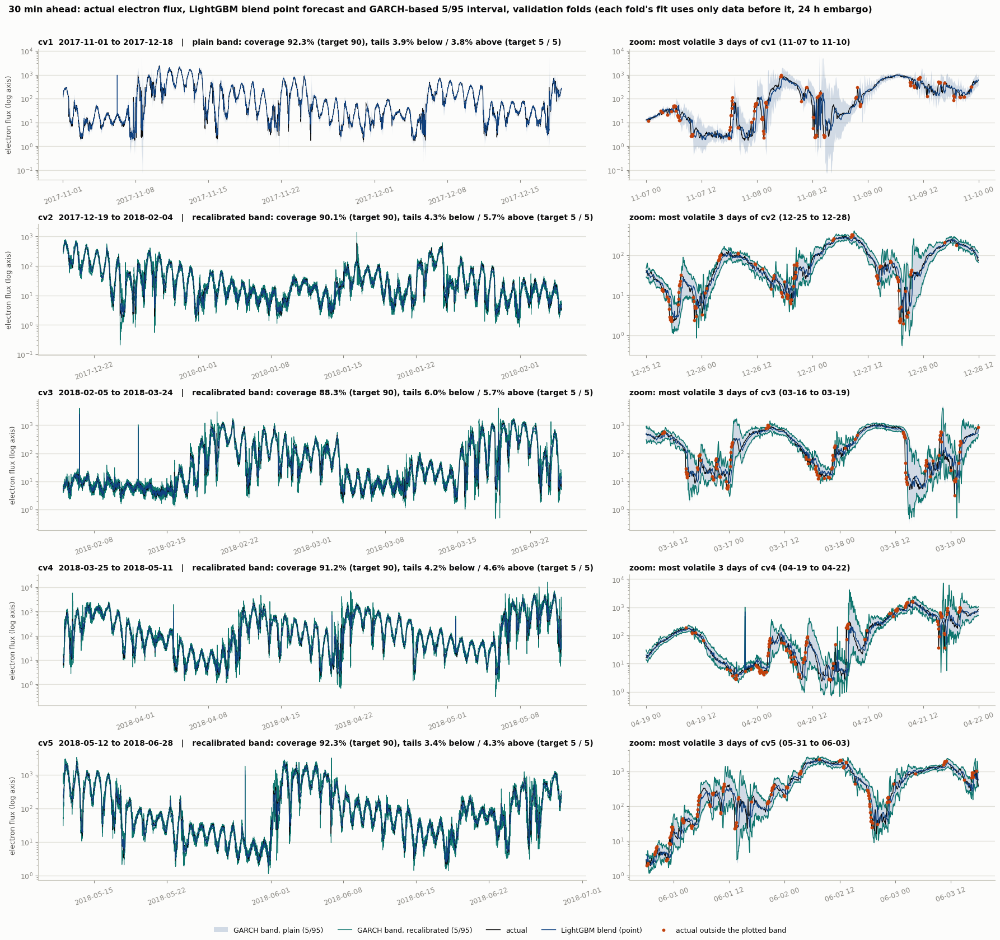

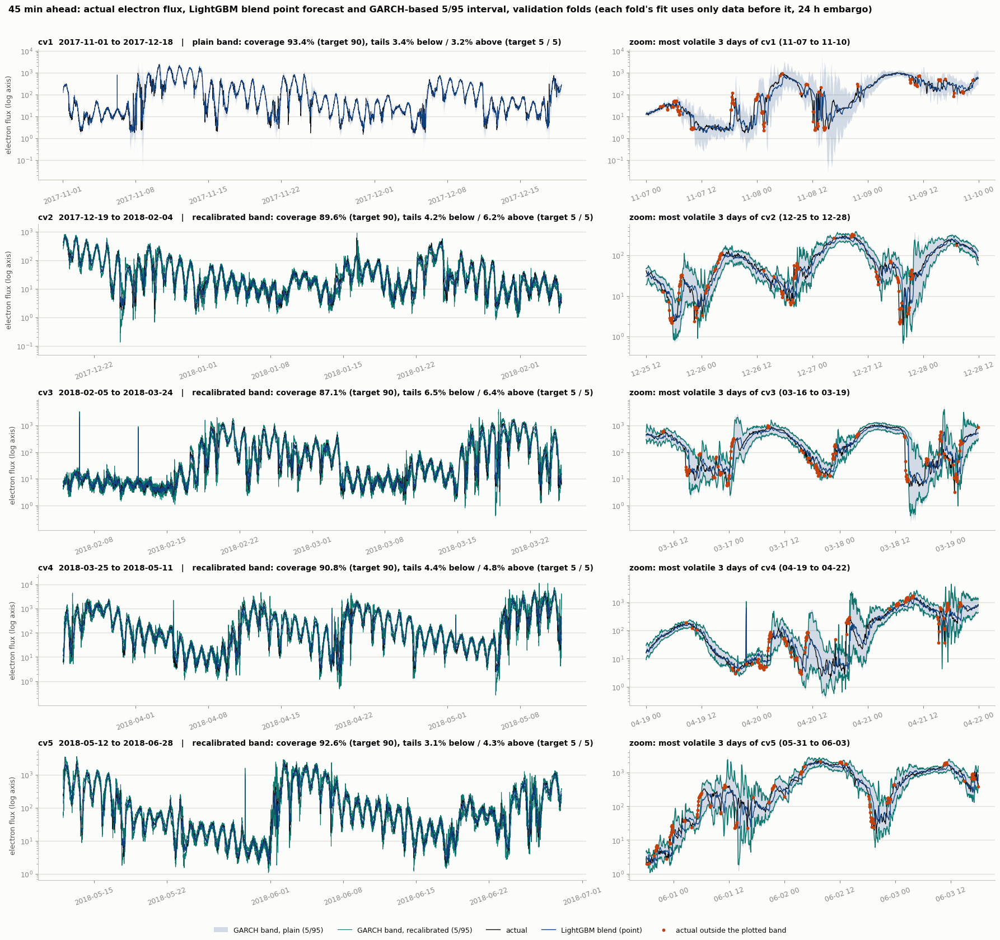

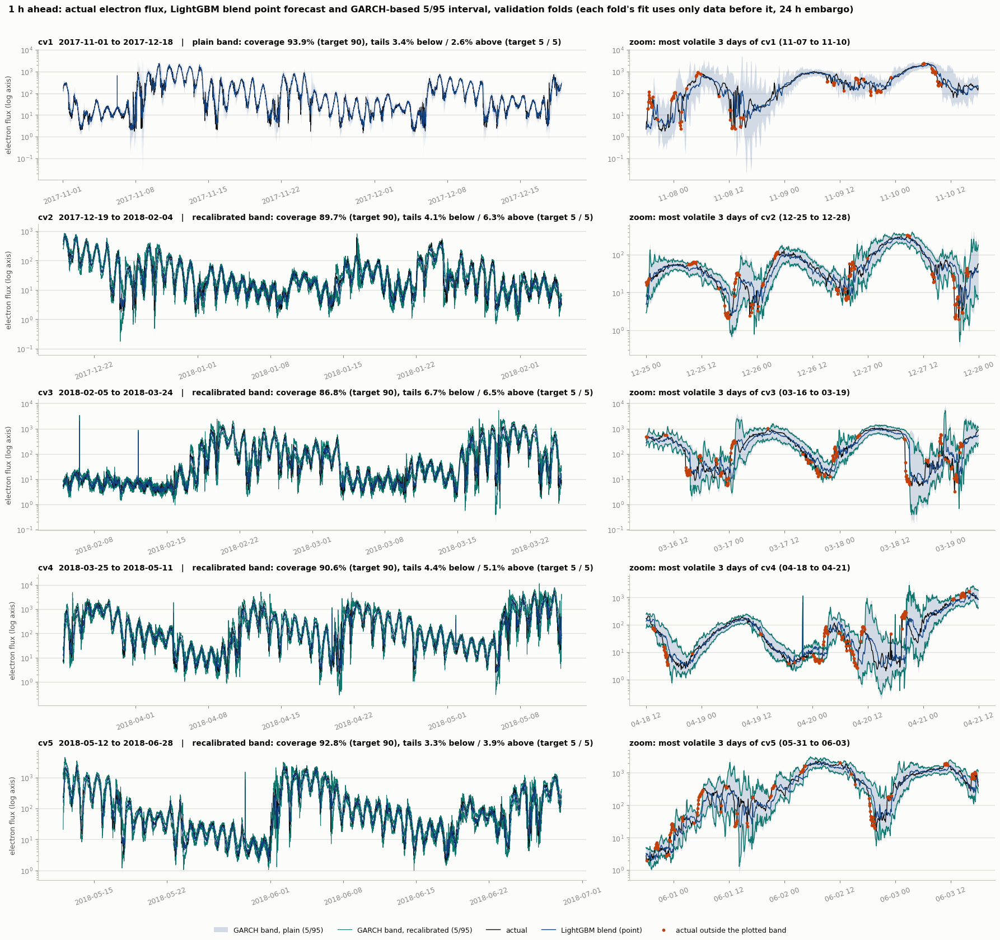

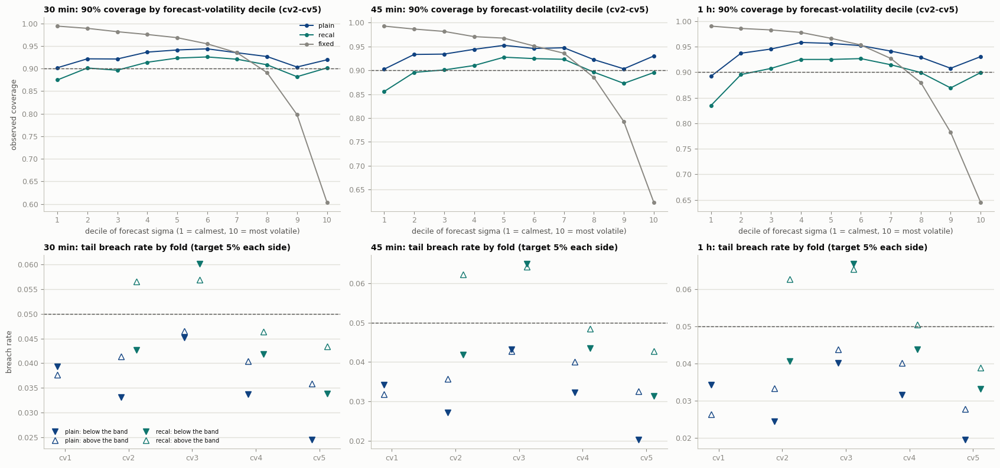

In [12]:
import sys, warnings, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import xlogy
import numba as nb
warnings.filterwarnings("ignore")
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid

HZ = {"30min": ("30 min", 6), "45min": ("45 min", 9), "1h": ("1 h", 12)}; FOLDS = [f"cv{k}" for k in range(1, 6)]
QL, QU = 0.05, 0.95; ALPHA = QL + (1 - QU)                       # 5% / 95% quantiles = 90% central interval
METHODS = {"plain": "GARCH sigma, t quantiles, centred on blend", "recal": "GARCH sigma, empirical 5/95 of past standardised blend errors", "fixed": "no GARCH: fixed width from past blend errors"}

# ---------------- t-GJR(1,1) variance filter (same recursion as Steps 3-5); returns the variance path only ----------------
@nb.njit
def _var(u, om, a, g, b, s0):
    n = u.shape[0]; s2 = np.empty(n); e2 = s0; en = 0.5 * s0; sp = s0
    for t in range(n):
        s = om + a * e2 + g * en + b * sp; s = min(max(s, 1e-10), 1e10); s2[t] = s; x = u[t]
        if np.isnan(x): e2 = s; en = 0.5 * s
        else: e2 = x * x; en = x * x if x < 0.0 else 0.0
        sp = s
    return s2

def dm(dif, L):
    n = len(dif); mu = dif.mean(); x = dif - mu; s = x @ x / n
    for l in range(1, L + 1): s += 2 * (1 - l / (L + 1)) * (x[l:] @ x[:-l]) / n
    z = mu / math.sqrt(max(s, 1e-18) / n); return float(mu), float(z)
def kupiec(x, n, p):
    ph = x / n; ll0 = xlogy(n - x, 1 - p) + xlogy(x, p); ll1 = xlogy(n - x, 1 - ph) + xlogy(x, ph); return float(stats.chi2.sf(max(-2 * (ll0 - ll1), 0.0), 1))
def christoffersen(s):                                           # independence of the breach sequence (first-order Markov)
    a, b = s[:-1].astype(int), s[1:].astype(int); n00 = int(((a == 0) & (b == 0)).sum()); n01 = int(((a == 0) & (b == 1)).sum()); n10 = int(((a == 1) & (b == 0)).sum()); n11 = int(((a == 1) & (b == 1)).sum())
    pi = (n01 + n11) / max(n00 + n01 + n10 + n11, 1); p01 = n01 / max(n00 + n01, 1); p11 = n11 / max(n10 + n11, 1)
    ll0 = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi); ll1 = xlogy(n00, 1 - p01) + xlogy(n01, p01) + xlogy(n10, 1 - p11) + xlogy(n11, p11); return float(stats.chi2.sf(max(-2 * (ll0 - ll1), 0.0), 1))
def iscore(y, lo, hi): return (hi - lo) + (2 / ALPHA) * np.maximum(lo - y, 0) + (2 / ALPHA) * np.maximum(y - hi, 0)        # Winkler / interval score
def pinball(y, lo, hi): return 0.5 * (np.maximum(QL * (y - lo), (QL - 1) * (y - lo)) + np.maximum(QU * (y - hi), (QU - 1) * (y - hi)))

# ---------------- data, windows, tables from earlier steps ----------------
g = load_grid(); dev = g.loc[:P.dev_end]; folds = {f.name: f for f in make_folds()}; idx = dev.index
assert idx.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
EMBt = pd.Timedelta(minutes=5 * P.embargo_steps); n = len(idx)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy()
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy(); yb = y.copy(); yb[bad] = np.nan
bin_all = (idx.hour * 2 + idx.minute // 30).to_numpy()
PAR = pd.read_csv(RUN / "reports" / "gjr11_params_frozen.csv").set_index(["scale", "window"]); Z = np.load(RUN / "preds" / "lgbm.npz")

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"; ACC, BRK, GRN = "#104281", "#c2410c", "#0f766e"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 10, "axes.titleweight": "semibold", "legend.frameon": False})

R = {}                                                                                      # per horizon: one DataFrame of every validation origin with point forecast, sigma and the three bands
for hn, (sname, H) in HZ.items():
    ends0 = np.arange(H, n, H); d0 = yb[ends0] - yb[ends0 - H]; te0 = idx[ends0]; fin0 = np.isfinite(d0); parts = []; blend_chk = []
    for k, fold in enumerate(FOLDS):
        w = folds[fold]; pos = Z[f"{hn}_{fold}_pos"]; yt = Z[f"{hn}_{fold}_y"]; tj = idx[pos + H]
        assert np.allclose(y[pos + H], yt), f"{hn} {fold}: saved targets do not line up with the grid"
        yhat = 0.5 * (Z[f"{hn}_{fold}_lgb_ext"] + Z[f"{hn}_{fold}_lgb_ext_huber"])           # the recommended blend
        p_ = PAR.loc[(sname, fold)]; nu = float(p_.nu); s0 = float(p_.s0); sig2_o = np.full(n, np.nan)
        pre = np.asarray(te0 <= w.val_start - EMBt)                                          # TRAINING rows only for the intraday scale
        ea = np.arange(H, n); da = yb[ea] - yb[ea - H]; pa = np.asarray(idx[ea] <= w.val_start - EMBt) & np.isfinite(da)      # scale pooled over all 5-min phases: with phase 0 alone, 45 min and 1 h never visit every half-hour bin
        binscale = pd.Series(np.abs(da[pa])).groupby(bin_all[ea][pa]).mean().reindex(range(48)).to_numpy(); assert np.isfinite(binscale).all()
        u0 = (d0 / binscale[bin_all[ends0]])[pre & fin0]; c = math.sqrt(np.mean(np.minimum(u0 ** 2, np.quantile(u0 ** 2, 0.99))) / s0); binscale = binscale * c   # re-level so the training variance matches the Step 3 start value s0
        for ph in range(H):                                                                  # one filter per 5-min phase, so every origin gets a fresh variance forecast
            ends = np.arange(H + ph, n, H); u = (yb[ends] - yb[ends - H]) / binscale[bin_all[ends]]
            sig2_o[ends - H] = _var(np.ascontiguousarray(u), p_.omega, p_.alpha1, p_.gamma, p_.beta1, s0)   # variance of the change ending at origin+H, known at the origin
        sig = np.sqrt(sig2_o[pos]) * binscale[bin_all[pos + H]]; assert np.isfinite(sig).all() and (sig > 0).all()
        D = pd.DataFrame(dict(fold=fold, pos=pos, tj=tj, y=yt, y0=y[pos], yhat=yhat, sig=sig, nu=nu)); D["z"] = (D.y - D.yhat) / D.sig; D["e"] = D.y - D.yhat
        qt = stats.t.ppf(QU, nu) * math.sqrt((nu - 2) / nu); D["lo_plain"] = D.yhat - qt * D.sig; D["hi_plain"] = D.yhat + qt * D.sig
        if k > 0:                                                                            # causal calibration: ONLY earlier folds, and only targets at least 24 h before this fold starts
            past = pd.concat([parts[j][parts[j].tj <= w.val_start - EMBt] for j in range(k)]); zq = np.quantile(past.z, [QL, QU]); eq = np.quantile(past.e, [QL, QU])
            D["lo_recal"] = D.yhat + zq[0] * D.sig; D["hi_recal"] = D.yhat + zq[1] * D.sig; D["lo_fixed"] = D.yhat + eq[0]; D["hi_fixed"] = D.yhat + eq[1]
        else:
            for c in ("lo_recal", "hi_recal", "lo_fixed", "hi_fixed"): D[c] = np.nan
        parts.append(D)
    D = pd.concat(parts, ignore_index=True); D["sub"] = (D.pos % H == 0); R[hn] = D
    d_ = D.y - D.y0; print(f"{hn}: blend R2 of the change, pooled over cv1-cv5 = {1 - ((D.y - D.yhat) ** 2).sum() / ((d_ - d_.mean()) ** 2).sum():.4f}   (your earlier report: 0.1494 / 0.2004 / 0.2458 for 30 min / 45 min / 1 h)")
    D.to_csv(RUN / "preds" / f"prob_forecast_{hn}.csv.gz", index=False)

# ---------------- diagnostics ----------------
def stats_of(D, m):
    lo, hi = D[f"lo_{m}"].to_numpy(), D[f"hi_{m}"].to_numpy(); yy = D.y.to_numpy(); b, a = yy < lo, yy > hi
    return dict(n=len(D), coverage90=1 - (b | a).mean(), lower_tail=b.mean(), upper_tail=a.mean(), mean_width_log=(hi - lo).mean(), interval_score=iscore(yy, lo, hi).mean(), pinball=pinball(yy, lo, hi).mean())
rf, rp, rt, rd = [], [], [], []
for hn, D in R.items():
    for fold in FOLDS:
        for m in METHODS:
            q = D[D.fold == fold]
            if q[f"lo_{m}"].notna().all(): rf.append(dict(horizon=hn, fold=fold, method=m, **stats_of(q, m)))
    Q = D[D.fold != "cv1"]
    for m in METHODS: rp.append(dict(horizon=hn, folds="cv2-cv5", method=m, **stats_of(Q, m)))
    rp.append(dict(horizon=hn, folds="cv1-cv5", method="plain", **stats_of(D, "plain")))
    S = Q[Q["sub"]].sort_values("tj"); L = max(1, 288 // HZ[hn][1])                            # non-overlapping origins: breaches and losses are not artificially autocorrelated
    for m in METHODS:
        b, a = (S.y < S[f"lo_{m}"]).to_numpy(), (S.y > S[f"hi_{m}"]).to_numpy()
        rt.append(dict(horizon=hn, method=m, n=len(S), p_kupiec_overall=kupiec(int((b | a).sum()), len(S), ALPHA), p_kupiec_lower=kupiec(int(b.sum()), len(S), QL), p_kupiec_upper=kupiec(int(a.sum()), len(S), 1 - QU), p_independence=christoffersen(b | a)))
    for A_, B_ in (("recal", "plain"), ("recal", "fixed"), ("plain", "fixed")):
        isA, isB = iscore(S.y.to_numpy(), S[f"lo_{A_}"].to_numpy(), S[f"hi_{A_}"].to_numpy()), iscore(S.y.to_numpy(), S[f"lo_{B_}"].to_numpy(), S[f"hi_{B_}"].to_numpy())
        mu, z = dm(isB - isA, L); rt.append(dict(horizon=hn, method=f"DM interval score: {A_} vs {B_} (positive = {A_} better)", n=len(S), mean_gain=mu, z=z))
    Q = Q.assign(dec=pd.qcut(Q.sig, 10, labels=False))
    for m in METHODS: rd.append(pd.DataFrame(dict(horizon=hn, method=m, decile=range(10), sigma=Q.groupby("dec").sig.mean().to_numpy(), coverage=[1 - ((q_.y < q_[f"lo_{m}"]) | (q_.y > q_[f"hi_{m}"])).mean() for _, q_ in Q.groupby("dec")])))
F = pd.DataFrame(rf); PL = pd.DataFrame(rp); T = pd.DataFrame(rt); DEC = pd.concat(rd)
F.to_csv(RUN / "reports" / "prob_forecast_per_fold.csv", index=False); PL.to_csv(RUN / "reports" / "prob_forecast_pooled.csv", index=False); T.to_csv(RUN / "reports" / "prob_forecast_tests.csv", index=False); DEC.to_csv(RUN / "reports" / "prob_forecast_sigma_deciles.csv", index=False)
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:.4f}".format)
print(f"\nTarget: central {100 * (QU - QL):.0f}% interval (5% / 95% quantiles): coverage90 = 0.90, lower_tail = upper_tail = 0.05. Widths are in log-flux units (width 0.30 = band spans a factor of exp(0.30) = 1.35).")
print("Methods:  plain = " + METHODS["plain"] + "\n          recal = " + METHODS["recal"] + "\n          fixed = " + METHODS["fixed"])
print("recal and fixed need earlier folds to calibrate on, so they exist for cv2-cv5 only. Pooled rows over cv2-cv5 compare all three on the same rows.")
print("\nPOOLED"); print(PL.set_index(["horizon", "folds", "method"]))
print("\nPER FOLD"); print(F.set_index(["horizon", "fold", "method"]))
print("\nTESTS on non-overlapping origins, cv2-cv5 (p-values: small = reject; Kupiec = right breach rate, independence = breaches not clustered). DM rows: z > 2 means the first method has the lower interval score.")
print(T.set_index(["horizon", "method"]))

# ---------------- figure 1: actual vs point forecast with the 5/95 band, one figure per horizon ----------------
def zoom_start(D, days=3):
    t = D.tj.to_numpy(); ad = np.abs(D.y - D.y0).to_numpy(); best, bs = -1.0, None
    for s_ in pd.date_range(D.tj.min().floor("D"), D.tj.max() - pd.Timedelta(days=days), freq="6h"):
        a, b = np.searchsorted(t, s_.to_datetime64()), np.searchsorted(t, (s_ + pd.Timedelta(days=days)).to_datetime64())
        if b - a > 0.8 * days * 288 and ad[a:b].mean() > best: best, bs = ad[a:b].mean(), s_
    return bs, bs + pd.Timedelta(days=days)
for hn, D in R.items():
    fig, axs = plt.subplots(5, 2, figsize=(18, 17), gridspec_kw=dict(width_ratios=[1.5, 1]))
    for r_, fold in enumerate(FOLDS):
        q = D[D.fold == fold]; m = "plain" if fold == "cv1" else "recal"; lo, hi = q[f"lo_{m}"].to_numpy(), q[f"hi_{m}"].to_numpy(); out = (q.y.to_numpy() < lo) | (q.y.to_numpy() > hi)
        z0, z1 = zoom_start(q)
        for c_, a in enumerate(axs[r_]):
            s = q if c_ == 0 else q[(q.tj >= z0) & (q.tj < z1)]; o = out if c_ == 0 else out[((q.tj >= z0) & (q.tj < z1)).to_numpy()]; x = s.tj
            a.fill_between(x, np.exp(s.lo_plain), np.exp(s.hi_plain), color=ACC, alpha=0.18, lw=0, label="GARCH band, plain (5/95)")
            if fold != "cv1": a.plot(x, np.exp(s.lo_recal), color=GRN, lw=0.8 if c_ == 0 else 1.1); a.plot(x, np.exp(s.hi_recal), color=GRN, lw=0.8 if c_ == 0 else 1.1, label="GARCH band, recalibrated (5/95)")
            a.plot(x, np.exp(s.y), color=INK, lw=0.6 if c_ == 0 else 1.0, label="actual"); a.plot(x, np.exp(s.yhat), color=ACC, lw=0.6 if c_ == 0 else 1.0, label="LightGBM blend (point)")
            if c_ == 1: a.scatter(x[o], np.exp(s.y)[o], s=10, color=BRK, zorder=4, label="actual outside the plotted band" if r_ == 0 else None)
            a.set_yscale("log"); a.tick_params(axis="x", labelrotation=20)
        sc_ = F[(F.horizon == hn) & (F.fold == fold) & (F.method == m)].iloc[0]
        axs[r_, 0].set_title(f"{fold}  {q.tj.min():%Y-%m-%d} to {q.tj.max():%Y-%m-%d}   |   {'plain' if fold == 'cv1' else 'recalibrated'} band: coverage {100 * sc_.coverage90:.1f}% (target 90), tails {100 * sc_.lower_tail:.1f}% below / {100 * sc_.upper_tail:.1f}% above (target 5 / 5)")
        axs[r_, 1].set_title(f"zoom: most volatile 3 days of {fold} ({z0:%m-%d} to {z1:%m-%d})"); axs[r_, 0].set_ylabel("electron flux (log axis)")
    h, l = axs[0, 1].get_legend_handles_labels(); hh, ll = axs[1, 0].get_legend_handles_labels(); d_ = dict(zip(ll + l, hh + h)); fig.legend(d_.values(), d_.keys(), loc="lower center", ncol=5, fontsize=9)
    fig.suptitle(f"{HZ[hn][0]} ahead: actual electron flux, LightGBM blend point forecast and GARCH-based 5/95 interval, validation folds (each fold's fit uses only data before it, 24 h embargo)", x=0.01, ha="left", fontsize=11.5, fontweight="semibold")
    fig.tight_layout(rect=(0, 0.025, 1, 0.97)); fig.savefig(RUN / "figs" / f"prob_forecast_{hn}.png", dpi=110, bbox_inches="tight"); plt.show()

# ---------------- figure 2: diagnostics ----------------
fig, axs = plt.subplots(2, 3, figsize=(17, 8)); mc = {"plain": ACC, "recal": GRN, "fixed": MUTED}
for c_, hn in enumerate(HZ):
    a = axs[0, c_]
    for m in METHODS: q = DEC[(DEC.horizon == hn) & (DEC.method == m)]; a.plot(q.decile + 1, q.coverage, "-o", ms=4, lw=1.4, color=mc[m], label=m)
    a.axhline(0.90, color=INK2, lw=1, ls="--"); a.set_xticks(range(1, 11)); a.set_xlabel("decile of forecast sigma (1 = calmest, 10 = most volatile)"); a.set_title(f"{HZ[hn][0]}: 90% coverage by forecast-volatility decile (cv2-cv5)")
    a = axs[1, c_]
    for off, m in zip((-0.12, 0.12), ("plain", "recal")):
        q = F[(F.horizon == hn) & (F.method == m)]; xs = np.array([FOLDS.index(f) for f in q.fold]) + off
        a.plot(xs, q.lower_tail, "v", ms=7, color=mc[m], label=f"{m}: below the band"); a.plot(xs, q.upper_tail, "^", ms=7, color=mc[m], mfc="none", label=f"{m}: above the band")
    a.axhline(0.05, color=INK2, lw=1, ls="--"); a.set_xticks(range(5)); a.set_xticklabels(FOLDS); a.set_title(f"{HZ[hn][0]}: tail breach rate by fold (target 5% each side)")
axs[0, 0].set_ylabel("observed coverage"); axs[1, 0].set_ylabel("breach rate"); axs[0, 0].legend(fontsize=8); axs[1, 0].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(RUN / "figs" / "prob_forecast_diagnostics.png", dpi=140, bbox_inches="tight"); plt.show()

👀 **How to read this output**

First, the **point forecast is reproduced exactly**: blend $R^2_\Delta$ = 0.1494 / 0.2004 / 0.2458, the same as Part 7. Widths are in log-flux units: a width of 0.30 means the band spans a factor $e^{0.30}=1.35$.

**Pooled over cv2–cv5 (same rows for all three bands):**

| | 30 min | 45 min | 1 h |
|---|---|---|---|
| **coverage90**: plain | 0.925 | 0.932 | 0.935 |
| coverage90: **recal** | **0.905** | **0.900** | **0.900** |
| coverage90: fixed | 0.909 | 0.909 | 0.909 |
| lower / upper tail, recal | 4.5 % / 5.1 % | 4.5 % / 5.4 % | 4.6 % / 5.4 % |
| mean width, plain / recal / fixed | 0.76 / **0.69** / 0.72 | 0.98 / **0.83** / 0.90 | 1.17 / **0.98** / 1.04 |
| interval score, plain / recal / fixed | 1.091 / **1.079** / 1.312 | 1.356 / **1.331** / 1.602 | 1.576 / **1.539** / 1.829 |

* `plain` **over-covers** (92.5–93.5 % instead of 90 %): its bands are too wide.
* `recal` hits the target pooled (90.5 / 90.0 / 90.0 %) **with the narrowest bands** and the best interval score. Its tails are close to even (lower 4.5 %, upper 5.1–5.4 %).
* **Does GARCH add value?** The DM test on interval scores says yes, strongly: `recal` vs `fixed` has $z$ = **9.8 / 9.4 / 8.8**, and even `plain` beats `fixed` ($z$ = 8.9 / 8.0 / 6.8). `recal` beats `plain` with $z$ = 5.8 / 6.1 / 6.1 (gain in interval score 0.013 / 0.031 / 0.044).
* **Per fold** (30 min): `recal` coverage is 0.901 / 0.883 / 0.912 / 0.923 for cv2…cv5, so it is *too narrow* in cv3 (88.3 %) and *too wide* in cv5 (92.3 %). `fixed` is worse: 0.953 / 0.879 / 0.875 / 0.930.

**Formal tests (non-overlapping origins, cv2–cv5).**

| | Kupiec $p$ (overall) 30 / 45 / 1 h | Independence $p$ |
|---|---|---|
| plain | 0.000 / 0.000 / 0.000 | 0.000 / 0.0001 / 0.275 |
| **recal** | **0.029 / 0.230 / 0.406** | **0.000 / 0.000 / 0.002** |
| fixed | 0.004 / 0.009 / 0.011 | 0.000 / 0.000 / 0.000 |

`recal` passes the **rate** test at 45 min and 1 h and only marginally fails it at 30 min ($p=0.029$). **But it fails independence at every horizon**: breaches come in runs, because the error regime changes more slowly than the band reacts. That is a real weakness and is shown again by the fold-by-fold instability below.

⚠️ **A reading that has not been tested.** `plain` over-covers possibly because the GARCH sigma was fitted to the *raw* change while the band is drawn around the *blend*, which has already removed 15–25 % of that variance; the plain band does not know this. `recal` is the correction.

### Cells 45–48: add-ons to Part 8 (they were run after Part 9)

### Cells 45–46: save patches
📘 Two one-line fragments that write the panel data (`preds/best_panels_*.npz`) and the cv5 Student-t residuals (`preds/gjr11_qq_cv5.npz`) for the interactive figures later. Cell 45 carries the indentation of the loop body in cell 43 (it was meant to sit inside that loop), which is why its source starts indented. In a clean version, merge the lines into the cell that creates the data (cell 48 already contains cell 45's content) and delete 43, 45 and 46.

In [14]:
    np.savez_compressed(RUN / "preds" / f"best_panels_{sname.replace(' ', '')}.npz", t=x.values.astype("datetime64[ns]").astype("int64"), u=uu, nu=nu, best=best, models=np.array(PANELS), pooled_r2=pooled.R2_abs.to_numpy(), **{"v_" + m: v[m][vm] for m in PANELS})

In [15]:
np.savez_compressed(RUN / "preds" / "gjr11_qq_cv5.npz", **{f"z_{s.replace(' ', '')}": ZKEEP[s][0] for s in SC}, **{f"nu_{s.replace(' ', '')}": np.array(ZKEEP[s][1]) for s in SC})

### Step 4 add-on: $R^2_{|\cdot|}$ by fold
📘 Tabulates the pooled-validation $R^2_{|\cdot|}$ **per fold** for GJR (refit and frozen), EWMA (refit) and `roll_1d` (refit); it feeds the fold-by-fold figure in cell 49.

In [18]:
R2F = pd.DataFrame([dict(scale=s_, series=lab, fold=WN[k], R2_abs=r2(Q_["au"][Q_["fold"] == k], Q_["sd"][Q_["fold"] == k]))
                    for s_ in SC
                    for lab, sch, m in (("GJR refit", "refit", "t-GJR(1,1)"), ("GJR frozen", "frozen", "t-GJR(1,1)"), ("EWMA refit", "refit", "EWMA"), ("roll_1d refit", "refit", "roll_1d"))
                    for Q_ in [pool((s_, sch, m))] for k in range(len(folds))])
R2F.to_csv(RUN / "reports" / "var_r2_by_fold.csv", index=False); print(R2F.pivot_table(index=["scale", "series"], columns="fold", values="R2_abs").round(4))

fold                    cv1    cv2    cv3    cv4    cv5
scale  series                                          
1 h    EWMA refit    0.1732 0.0475 0.0616 0.1129 0.1184
       GJR frozen    0.1878 0.0742 0.0774 0.1280 0.1419
       GJR refit     0.1878 0.0673 0.0761 0.1407 0.1576
       roll_1d refit 0.1164 0.0259 0.0495 0.0855 0.0547
30 min EWMA refit    0.1933 0.0836 0.1196 0.1124 0.1732
       GJR frozen    0.2172 0.0996 0.1457 0.1246 0.1818
       GJR refit     0.2172 0.1013 0.1439 0.1195 0.1847
       roll_1d refit 0.1064 0.0245 0.0479 0.0685 0.0709
45 min EWMA refit    0.1927 0.0538 0.0994 0.1053 0.1481
       GJR frozen    0.2121 0.0721 0.1204 0.1225 0.1637
       GJR refit     0.2121 0.0690 0.1192 0.1220 0.1617
       roll_1d refit 0.1344 0.0248 0.0636 0.0735 0.0812


👀 **How to read this output**

| 30 min, $R^2_{\lvert\cdot\rvert}$ | cv1 | cv2 | cv3 | cv4 | cv5 |
|---|---|---|---|---|---|
| GJR refit | 0.217 | 0.101 | 0.144 | 0.120 | 0.185 |
| GJR frozen | 0.217 | 0.100 | 0.146 | 0.125 | 0.182 |
| EWMA refit | 0.193 | 0.084 | 0.120 | 0.112 | 0.173 |
| roll_1d refit | 0.106 | 0.025 | 0.048 | 0.069 | 0.071 |

cv1 is identical for refit and frozen by construction. At 1 h in cv4 the refit is clearly better (0.141 vs 0.128). **Every row ranks GJR ≥ EWMA > rolling** in each fold, while the *level* of the score swings by a factor of two between folds.

### Best-model figures (re-run with the save lines)
📘 Identical to cell 43 plus two lines that save each scale's validation data for the interactive figures (cell 49). The outputs are the same as in cell 43.

30 min: Gaussian GJR(1,2) refit log-lik -24355.42 vs Step 5 report -24355.42  (should agree to ~0.1)
30 min: best by pooled validation R2_abs = N-GJR(1,2) (0.1661); plotted window cv5: 2018-05-12 to 2018-06-28, 2297 changes


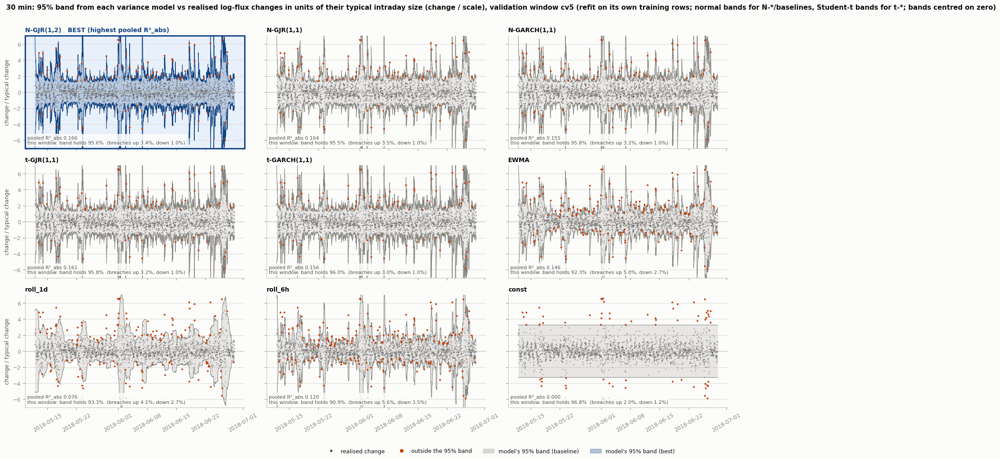

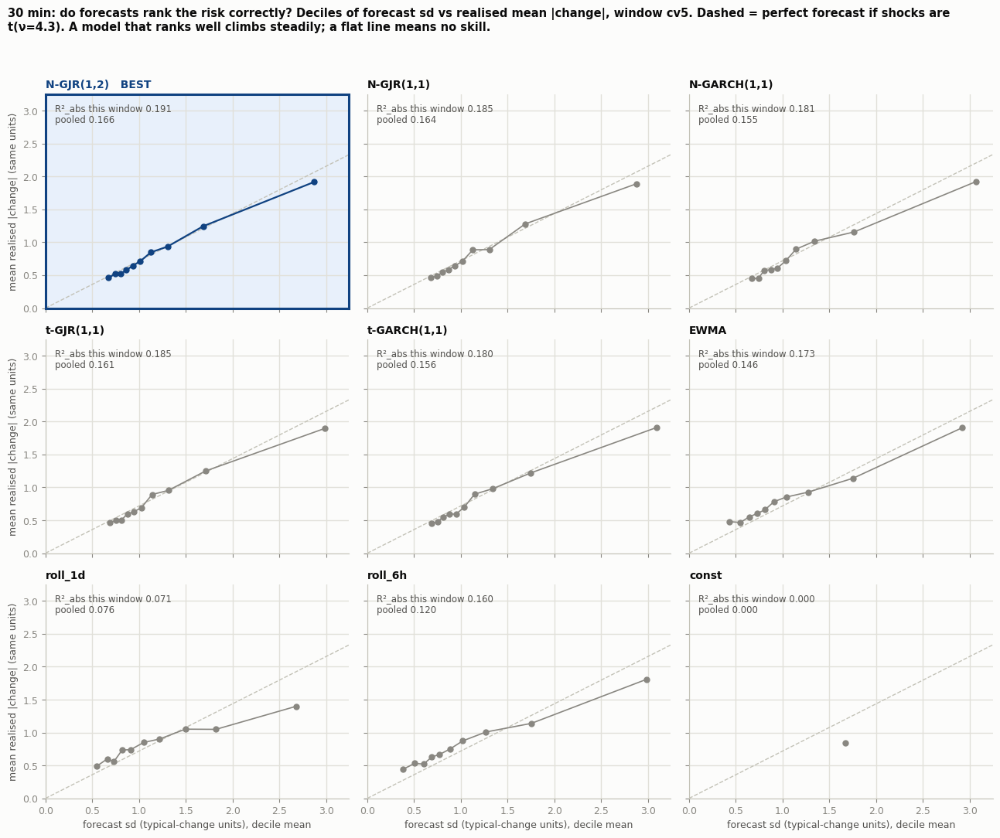

45 min: Gaussian GJR(1,2) refit log-lik -16217.48 vs Step 5 report -16217.48  (should agree to ~0.1)
45 min: best by pooled validation R2_abs = N-GJR(1,2) (0.1567); plotted window cv5: 2018-05-12 to 2018-06-28, 1533 changes


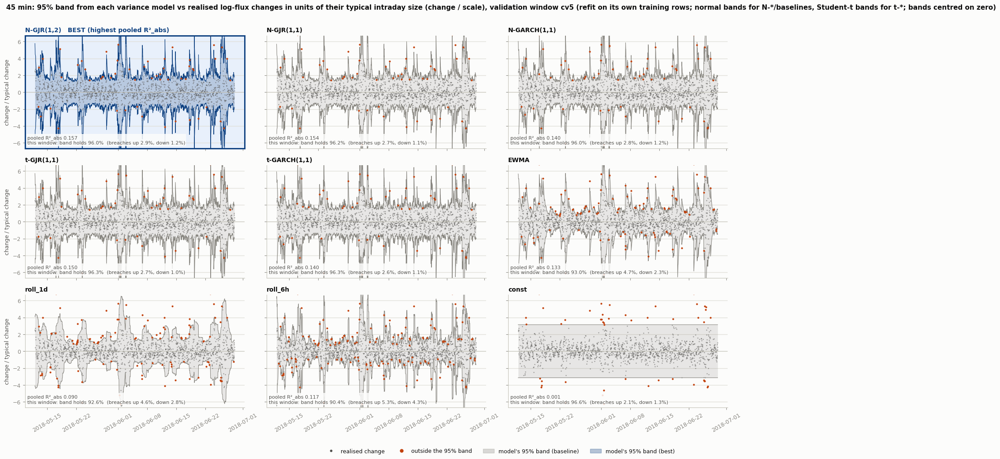

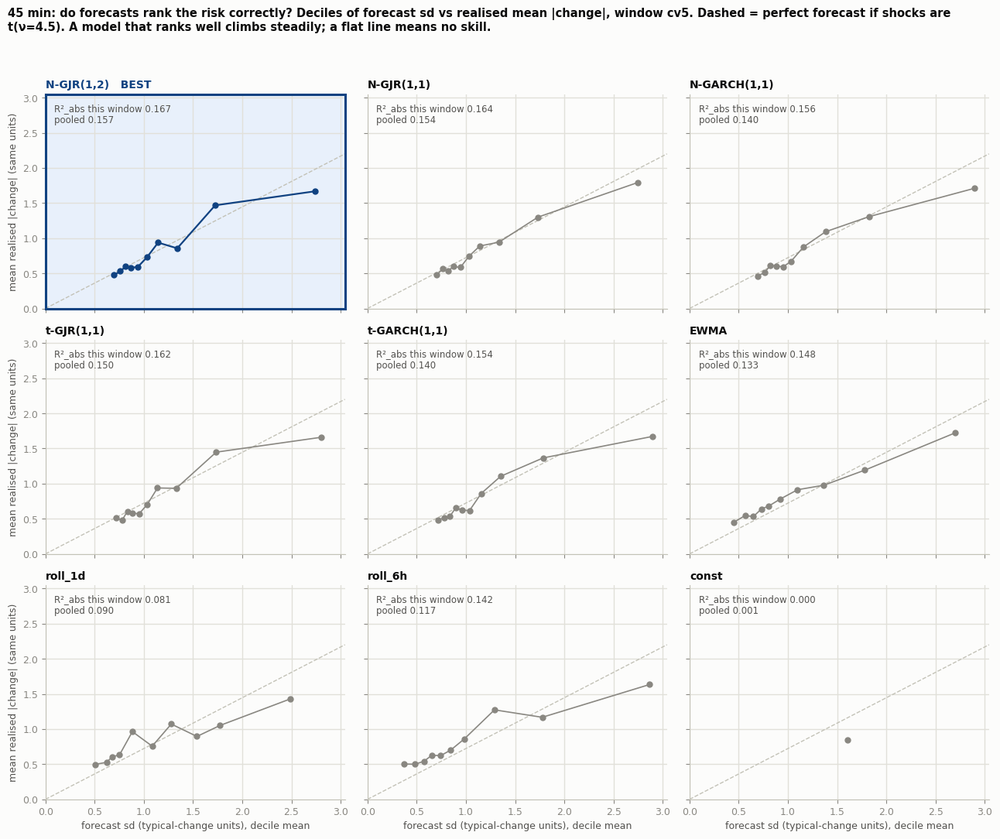

1 h: Gaussian GJR(1,2) refit log-lik -12263.25 vs Step 5 report -12263.25  (should agree to ~0.1)
1 h: best by pooled validation R2_abs = N-GJR(1,2) (0.1368); plotted window cv5: 2018-05-12 to 2018-06-28, 1147 changes


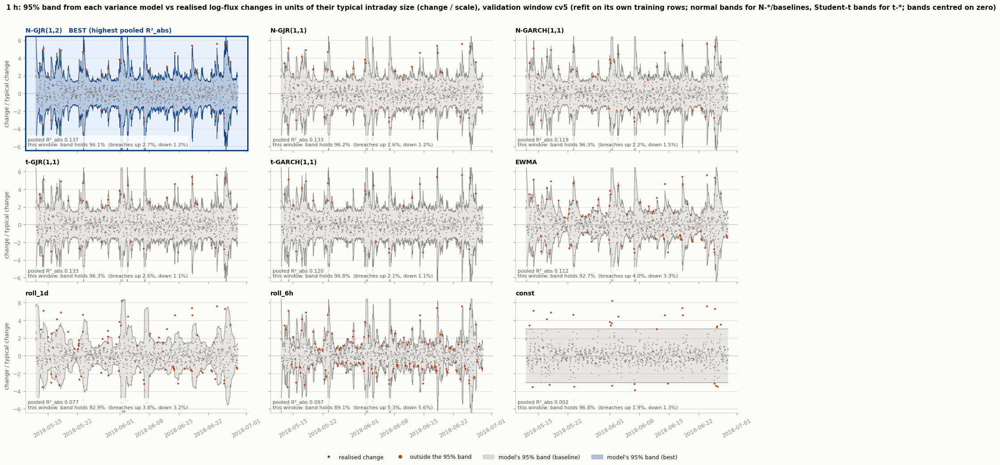

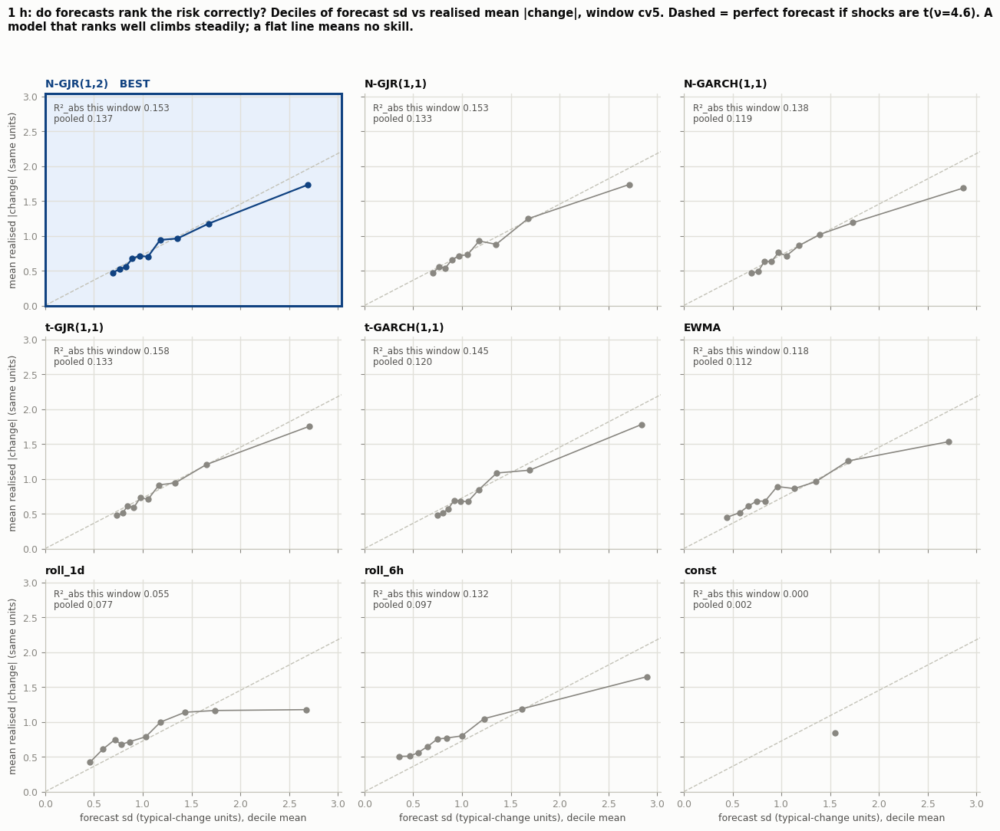

In [21]:
import sys, warnings, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from scipy.special import gammaln
import numba as nb
warnings.filterwarnings("ignore")
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid

WINDOW = "cv5"                                  # window whose validation period is drawn (cv5 = the static window); refit on its own training rows
SHOW = ["30 min", "45 min", "1 h"]              # one pair of figures per scale
PANELS = ["N-GJR(1,2)", "N-GJR(1,1)", "N-GARCH(1,1)", "t-GJR(1,1)", "t-GARCH(1,1)", "EWMA", "roll_1d", "roll_6h", "const"]
TMOD = {"t-GJR(1,1)", "t-GARCH(1,1)"}; SCALES = {"30 min": 6, "45 min": 9, "1 h": 12}

# ---------------- same variance recursion and Gaussian fit as Step 5 (nu <= 0 -> normal density) ----------------
RHO_MAX = 0.9999
@nb.njit
def _run(u, om, alpha, gam, beta, s0, nu):
    n = u.shape[0]; p = alpha.shape[0]; q = beta.shape[0]; sig2 = np.empty(n); e2 = np.empty(n); en = np.empty(n)
    c = math.lgamma((nu + 1.0) / 2.0) - math.lgamma(nu / 2.0) - 0.5 * math.log(math.pi * (nu - 2.0)) if nu > 0.0 else -0.5 * math.log(2.0 * math.pi)
    ll = 0.0
    for t in range(n):
        s = om
        for i in range(p):
            j = t - 1 - i
            if j >= 0: s += alpha[i] * e2[j]
            else: s += alpha[i] * s0
        if t >= 1: s += gam * en[t - 1]
        else: s += gam * 0.5 * s0
        for i in range(q):
            j = t - 1 - i
            if j >= 0: s += beta[i] * sig2[j]
            else: s += beta[i] * s0
        s = min(max(s, 1e-10), 1e10); sig2[t] = s; x = u[t]
        if np.isnan(x): e2[t] = s; en[t] = 0.5 * s
        else:
            x2 = x * x; e2[t] = x2; en[t] = x2 if x < 0.0 else 0.0
            if nu > 0.0: ll += c - 0.5 * math.log(s) - 0.5 * (nu + 1.0) * math.log1p(x2 / (s * (nu - 2.0)))
            else: ll += c - 0.5 * math.log(s) - 0.5 * x2 / s
    return sig2, ll

@nb.njit
def _ewma(u, lam, s0):
    n = u.shape[0]; out = np.empty(n); sp = s0; ep = s0
    for t in range(n):
        s = lam * sp + (1.0 - lam) * ep; out[t] = s; x = u[t]; ep = s if np.isnan(x) else x * x; sp = s
    return out

def bnds(K): return [(-20.0, 5.0)] if K == 0 else [(-20.0, 5.0), (-12.0, 12.0)] + [(-12.0, 12.0)] * (K - 1)
def unpack(th, p, q, gjr):
    K = p + int(gjr) + q; om = math.exp(th[0])
    rho = RHO_MAX / (1.0 + math.exp(-th[1])); z = np.concatenate([th[2:2 + K - 1], [0.0]]); w = np.exp(z - z.max()); w /= w.sum(); c = rho * w
    return om, c[:p], (2.0 * c[p] if gjr else 0.0), c[p + int(gjr):]
def to_theta(par, p, q, gjr):
    K = p + int(gjr) + q
    c = np.concatenate([par["a"], [par["g"] / 2.0] if gjr else [], par["b"]]); c = np.maximum(c, 1e-6)
    if c.sum() > 0.999: c = c * (0.999 / c.sum())
    rho = c.sum(); z = np.log(c) - np.log(c[-1]); r = rho / RHO_MAX; th = np.concatenate([[math.log(par["om"]), math.log(r / (1.0 - r))], z[:-1]])
    b = bnds(K); return np.clip(th, [x[0] for x in b], [x[1] for x in b])
def generic(p, q, gjr, rho0, s2):
    w = np.concatenate([[0.12, 0.03][:p], [0.04] if gjr else [], [0.80, 0.05][:q]]); c = w * rho0 / w.sum()
    return dict(om=s2 * (1.0 - rho0), a=c[:p], g=(2.0 * c[p] if gjr else 0.0), b=c[p + int(gjr):], gjr=gjr)
def embed(par, p, q, gjr):
    a = np.full(p, 0.005); a[:len(par["a"])] = par["a"]; b = np.full(q, 0.005); b[:len(par["b"])] = par["b"]
    return dict(om=par["om"], a=a, g=par["g"] if (gjr and par["gjr"]) else (0.01 if gjr else 0.0), b=b, gjr=gjr)
def fit_one(u, p, q, gjr, donors, s2):
    K = p + int(gjr) + q; N = int(np.isfinite(u).sum()); u = np.ascontiguousarray(u, dtype=np.float64)
    def f(th):
        om, a, g_, b = unpack(th, p, q, gjr); ll = _run(u, om, a, g_, b, s2, 0.0)[1]; return 1e10 if not np.isfinite(ll) else -ll / N
    starts = [to_theta(d_, p, q, gjr) for d_ in donors] + [to_theta(generic(p, q, gjr, r0, s2), p, q, gjr) for r0 in (0.95, 0.99, 0.90)[: (3 if not donors else 1)]]
    opt = dict(maxiter=500, maxfun=60000, ftol=1e-13, gtol=1e-7); runs = [optimize.minimize(f, th0, method="L-BFGS-B", bounds=bnds(K), options=opt) for th0 in starts]
    best = min(runs, key=lambda r: r.fun); r2_ = optimize.minimize(f, best.x, method="L-BFGS-B", bounds=bnds(K), options=opt)
    if r2_.fun < best.fun: best = r2_
    om, a, g_, b = unpack(best.x, p, q, gjr)
    return dict(par=dict(om=om, a=a, g=g_, b=b, gjr=gjr), ll=-best.fun * N, N=N)

def roll_var(u, k, fallback):
    f = np.isfinite(u); s = np.where(f, u * u, 0.0); cs = np.r_[0.0, np.cumsum(s)]; cc = np.r_[0.0, np.cumsum(f)]
    a = np.arange(len(u)); lo = np.maximum(0, a - k); num = cs[a] - cs[lo]; cnt = cc[a] - cc[lo]
    return np.maximum(np.where(cnt >= max(2, k // 2), num / np.maximum(cnt, 1), fallback), 1e-8)
def r2(a, b): return float(np.corrcoef(a, b)[0, 1] ** 2) if np.std(b) > 1e-9 else 0.0
def e_abs_t(nu): return 2 * math.sqrt(nu - 2) * math.exp(gammaln((nu + 1) / 2) - gammaln(nu / 2)) / (math.sqrt(math.pi) * (nu - 1))   # E|z| of a unit-variance Student-t

# ---------------- data and tables written by earlier steps ----------------
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds(); idx = dev.index
assert idx.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
EMBt = pd.Timedelta(minutes=5 * P.embargo_steps); w = next(x for x in folds if x.name == WINDOW)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy(); n = len(y)
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy(); yb = y.copy(); yb[bad] = np.nan
PAR = pd.read_csv(RUN / "reports" / "gjr11_params_frozen.csv").set_index(["scale", "window"])
S2 = pd.read_csv(RUN / "reports" / "garch_order_selection.csv"); G11 = S2[S2.model == "GARCH(1,1)"].set_index(["scale", "window"])
SC_T = pd.read_csv(RUN / "reports" / "normal_vs_t_scores.csv"); NF = pd.read_csv(RUN / "reports" / "garch_normal_order_selection.csv")
LAMS = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.94, 0.97, 0.99]

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"; ACC, ACC_L, BRK = "#104281", "#e8f0fb", "#c2410c"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 10, "axes.titleweight": "semibold", "legend.frameon": False})

for sname in SHOW:
    step = SCALES[sname]; ends = np.arange(step, n, step); d = yb[ends] - yb[ends - step]; te = idx[ends]; tb = (te.hour * 2 + te.minute // 30).to_numpy(); fin = np.isfinite(d)
    dt = pd.Timedelta(minutes=5 * step); pre = np.asarray(te <= w.val_start - EMBt)                    # TRAINING rows only for every fit
    sc = pd.Series(np.abs(d[pre & fin])).groupby(tb[pre & fin]).mean(); srow = sc.reindex(tb).to_numpy(); u = d / srow
    p_ = PAR.loc[(sname, WINDOW)]; q_ = G11.loc[(sname, WINDOW)]; s0 = float(p_.s0); ut = u[pre]; uf = ut[np.isfinite(ut)]; s2 = float(np.mean(np.minimum(uf ** 2, np.quantile(uf ** 2, 0.99))))
    assert abs(s2 - s0) < 1e-9 * max(1.0, s0), "start variance does not match Step 3"; assert te[pre].max() <= w.val_start - EMBt
    f11 = fit_one(ut, 1, 1, False, [], s2); fj11 = fit_one(ut, 1, 1, True, [embed(f11["par"], 1, 1, True)], s2); fj12 = fit_one(ut, 1, 2, True, [embed(fj11["par"], 1, 2, True)], s2)
    chk = NF[(NF.scale == sname) & (NF.window == WINDOW) & (NF.model == "GJR(1,2)")].ll.iloc[0]
    print(f"{sname}: Gaussian GJR(1,2) refit log-lik {fj12['ll']:.2f} vs Step 5 report {chk:.2f}  (should agree to ~0.1)")
    v = {"const": np.full(len(u), float(np.mean(uf ** 2)))}
    for nm, fz in (("N-GARCH(1,1)", f11), ("N-GJR(1,1)", fj11), ("N-GJR(1,2)", fj12)): pr = fz["par"]; v[nm] = _run(u, pr["om"], pr["a"], pr["g"], pr["b"], s0, 0.0)[0]
    nu = float(p_.nu)
    v["t-GJR(1,1)"] = _run(u, p_.omega, np.array([p_.alpha1]), p_.gamma, np.array([p_.beta1]), s0, nu)[0]
    v["t-GARCH(1,1)"] = _run(u, q_.omega, np.array([q_.alpha1]), 0.0, np.array([q_.beta1]), s0, float(q_.nu))[0]
    v["roll_6h"] = roll_var(u, max(2, 360 // (5 * step)), v["const"][0]); v["roll_1d"] = roll_var(u, max(2, 1440 // (5 * step)), v["const"][0])
    tl = [np.mean(np.log(_ewma(np.ascontiguousarray(ut), lm, s0)[np.isfinite(ut)]) + uf ** 2 / _ewma(np.ascontiguousarray(ut), lm, s0)[np.isfinite(ut)]) for lm in LAMS]
    v["EWMA"] = _ewma(np.ascontiguousarray(u), LAMS[int(np.argmin(tl))], s0)

    vm = (te - dt >= w.val_start) & (te < w.val_end) & fin; x = te[vm]; uu = u[vm]; chg = uu
    pooled = SC_T[(SC_T.scale == sname) & (SC_T.scheme == "refit") & SC_T.model.isin(PANELS)].set_index("model").reindex(PANELS)
    best = pooled.R2_abs.idxmax(); print(f"{sname}: best by pooled validation R2_abs = {best} ({pooled.R2_abs.max():.4f}); plotted window {WINDOW}: {x.min():%Y-%m-%d} to {x.max():%Y-%m-%d}, {len(x)} changes")
    qn = stats.norm.ppf(0.975); qt = stats.t.ppf(0.975, nu) * math.sqrt((nu - 2) / nu); ylim = 1.15 * np.quantile(np.abs(uu), 0.995)
    assert len(x) == len(uu) == len(v["t-GJR(1,1)"][vm]) == int(vm.sum()), "x/uu/v are not this scale's validation rows"
    np.savez_compressed(RUN / "preds" / f"best_panels_{sname.replace(' ', '')}.npz", t=x.values.astype("datetime64[ns]").astype("int64"), u=uu, nu=nu, best=best, models=np.array(PANELS), pooled_r2=pooled.R2_abs.to_numpy(), **{"v_" + m: v[m][vm] for m in PANELS})

    # ---- Figure A: forecast 95% band against what actually happened, one panel per model ----
    fig, axs = plt.subplots(3, 3, figsize=(17, 10.5), sharex=True, sharey=True)
    for a, m in zip(axs.ravel(), PANELS):
        hw = (qt if m in TMOD else qn) * np.sqrt(v[m][vm]); out = np.abs(chg) > hw; isb = (m == best); col = ACC if isb else MUTED
        if isb: a.set_facecolor(ACC_L)
        a.fill_between(x, -hw, hw, color=col, alpha=0.22 if isb else 0.18, lw=0); a.plot(x, hw, color=col, lw=0.8); a.plot(x, -hw, color=col, lw=0.8)
        a.scatter(x[~out], chg[~out], s=3, color=INK2, alpha=0.55, lw=0); a.scatter(x[out], chg[out], s=9, color=BRK, lw=0, zorder=3)
        a.axhline(0, color=AXIS, lw=0.8); a.set_ylim(-ylim, ylim)
        for sp in a.spines.values():
            if isb: sp.set_visible(True); sp.set_color(ACC); sp.set_linewidth(2.2)
        a.set_title(m + ("   BEST (highest pooled R²_abs)" if isb else ""), color=ACC if isb else INK, loc="left")
        a.text(0.01, 0.03, f"pooled R²_abs {pooled.loc[m, 'R2_abs']:.3f}\nthis window: band holds {100 * (1 - out.mean()):.1f}%  (breaches up {100 * (out & (chg > 0)).mean():.1f}%, down {100 * (out & (chg < 0)).mean():.1f}%)",
               transform=a.transAxes, va="bottom", fontsize=8, color=INK2, bbox=dict(facecolor=SURF, edgecolor="none", alpha=0.85, pad=1.5), zorder=5)
        a.tick_params(axis="x", labelrotation=30)
    for a in axs[:, 0]: a.set_ylabel("change / typical change")
    h = [plt.Line2D([], [], marker="o", ls="", ms=3, color=INK2), plt.Line2D([], [], marker="o", ls="", ms=5, color=BRK), plt.Rectangle((0, 0), 1, 1, color=MUTED, alpha=0.3), plt.Rectangle((0, 0), 1, 1, color=ACC, alpha=0.3)]
    fig.legend(h, ["realised change", "outside the 95% band", "model's 95% band (baseline)", "model's 95% band (best)"], loc="lower center", ncol=4, fontsize=9)
    fig.suptitle(f"{sname}: 95% band from each variance model vs realised log-flux changes in units of their typical intraday size (change / scale), validation window {WINDOW} (refit on its own training rows; normal bands for N-*/baselines, Student-t bands for t-*; bands centred on zero)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
    fig.tight_layout(rect=(0, 0.04, 1, 0.97)); fig.savefig(RUN / "figs" / f"best_model_bands_{sname.replace(' ', '')}.png", dpi=150, bbox_inches="tight"); plt.show()

    # ---- Figure B: does a higher forecast mean bigger realised moves? (the R2 view) deciles of forecast sd vs mean realised |change| ----
    ct = e_abs_t(nu); fig, axs = plt.subplots(3, 3, figsize=(13, 11), sharex=True, sharey=True); lim = 0
    for a, m in zip(axs.ravel(), PANELS):
        sd = np.sqrt(v[m][vm]); au = np.abs(uu); isb = (m == best); col = ACC if isb else MUTED
        if sd.std() > 1e-9:
            b = pd.qcut(pd.Series(sd).rank(method="first"), 10, labels=False).to_numpy(); bx = np.array([sd[b == k].mean() for k in range(10)]); by = np.array([au[b == k].mean() for k in range(10)])
        else: bx, by = np.array([sd.mean()]), np.array([au.mean()])
        lim = max(lim, bx.max(), by.max()); a.plot(bx, by, "-o", ms=5, lw=1.6 if isb else 1.2, color=col, zorder=3)
        if isb: a.set_facecolor(ACC_L)
        for sp in a.spines.values():
            if isb: sp.set_visible(True); sp.set_color(ACC); sp.set_linewidth(2.2)
        a.set_title(m + ("   BEST" if isb else ""), color=ACC if isb else INK, loc="left"); a.grid(axis="x", color=GRID)
        a.text(0.03, 0.96, f"R²_abs this window {r2(au, sd):.3f}\npooled {pooled.loc[m, 'R2_abs']:.3f}", transform=a.transAxes, va="top", fontsize=8.5, color=INK2)
    for a in axs.ravel(): a.plot([0, lim * 1.05], [0, ct * lim * 1.05], ls="--", lw=1, color=AXIS, zorder=1); a.set_xlim(0, lim * 1.05); a.set_ylim(0, lim * 1.05)
    for a in axs[-1]: a.set_xlabel("forecast sd (typical-change units), decile mean")
    for a in axs[:, 0]: a.set_ylabel("mean realised |change| (same units)")
    fig.suptitle(f"{sname}: do forecasts rank the risk correctly? Deciles of forecast sd vs realised mean |change|, window {WINDOW}. Dashed = perfect forecast if shocks are t(ν={nu:.1f}). A model that ranks well climbs steadily; a flat line means no skill.", x=0.01, ha="left", fontsize=10.5, fontweight="semibold", wrap=True)
    fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(RUN / "figs" / f"best_model_reliability_{sname.replace(' ', '')}.png", dpi=150, bbox_inches="tight"); plt.show()

## 9.3 Interactive figures (Plotly)

📘 **What.** Six groups of interactive figures, each also saved as a stand-alone `.html` file under `html/` (loaded with the Plotly CDN):

1. **Variance-model order selection** (Step 2): log-likelihood gain over GARCH(1,1) per window.
2. **Normal vs Student-$t$ calibration** (Step 5): observed minus nominal coverage at each level.
3. **One panel per variance model** (best highlighted with a blue frame), with bands, breaches and pooled $R^2_{|\cdot|}$.
4. **Actual vs blend forecast with the 5 %/95 % band** for the probabilistic forecast.
5. **Probabilistic diagnostics**: directional accuracy and breach rates (cell 50).
6. **Optional:** Student-$t$ Q-Q plot (Step 3) and $R^2_{|\cdot|}$ by fold (Step 4); these need the two save patches (cells 45–46).

🎯 **Why.** Static plots hide the detail that matters for a band: *when* it fails. Hovering over a breach shows the date, the realised value, the forecast and the band edges.

In [ ]:
import sys, math, warnings
from pathlib import Path
import numpy as np, pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats
from scipy.special import gammaln
warnings.filterwarnings("ignore")

RUN = Path("/kaggle/working/final_run"); (RUN / "html").mkdir(exist_ok=True)               # every figure is also saved as a standalone interactive .html in html/
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"; ACC, BRK, GRN = "#104281", "#c2410c", "#0f766e"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]; SCALES = ["30 min", "45 min", "1 h"]; KEYS = {"30 min": "30min", "45 min": "45min", "1 h": "1h"}
TMOD = {"t-GJR(1,1)", "t-GARCH(1,1)"}

def rgba(h, a): h = h.lstrip("#"); return f"rgba({int(h[0:2], 16)},{int(h[2:4], 16)},{int(h[4:6], 16)},{a})"
def sfx(k): return "" if k == 0 else str(k + 1)                                              # axis-name suffix of the k-th (0-based) subplot
def finish(fig, name, height, title):
    fig.update_layout(template="plotly_white", paper_bgcolor=SURF, plot_bgcolor=SURF, font=dict(color=INK2, size=11), height=height, margin=dict(l=65, r=30, t=125, b=50),
                      title=dict(text=title, x=0.01, xanchor="left", y=1, yref="container", yanchor="top", pad=dict(t=12), font=dict(size=14, color=INK)), legend=dict(orientation="h", yanchor="bottom", y=1 + 40 / (height - 175), x=0), hovermode="closest")
    fig.update_xaxes(showgrid=False, linecolor=AXIS, zeroline=False, tickfont=dict(color=MUTED)); fig.update_yaxes(gridcolor=GRID, linecolor=AXIS, zeroline=False, tickfont=dict(color=MUTED))
    fig.write_html(RUN / "html" / f"{name}.html", include_plotlyjs="cdn"); fig.show()
def need(*files):
    miss = [str(f.relative_to(RUN)) for f in files if not f.exists()]
    if miss: print("skipped, missing:", ", ".join(miss), "(see the one-line save patches)"); return False
    return True
def e_abs_t(nu): return 2 * math.sqrt(nu - 2) * math.exp(gammaln((nu + 1) / 2) - gammaln(nu / 2)) / (math.sqrt(math.pi) * (nu - 1))
def mark_best(fig, k, title, ncols):                                                          # blue frame + tint behind the best panel, bold blue title
    xa, ya = fig.layout["xaxis" + sfx(k)].domain, fig.layout["yaxis" + sfx(k)].domain
    fig.add_shape(type="rect", xref="paper", yref="paper", x0=xa[0], x1=xa[1], y0=ya[0], y1=ya[1], line=dict(color=ACC, width=2.5), fillcolor=rgba(ACC, 0.07), layer="below")
    an = fig.layout.annotations[k]; an.update(text=f"<b>{title}</b>", font=dict(size=12, color=ACC), x=xa[0], xanchor="left")

# =========================================================== 1. variance-model order selection (Step 2; training windows only)
def fig_order():
    f = RUN / "reports" / "garch_order_selection.csv"
    if not need(f): return
    S = pd.read_csv(f); SC = [s for s in SCALES if s in set(S.scale)]; WN = sorted(S.window.unique())
    MN = [m for m in ["GARCH(1,1)", "GJR(1,1)", "GARCH(1,2)", "GARCH(2,1)", "GJR(1,2)", "GJR(2,1)", "GARCH(2,2)", "GJR(2,2)"] if m in set(S.model)]
    fig = make_subplots(1, len(SC), subplot_titles=SC, shared_yaxes=True, horizontal_spacing=0.03)
    for c, s in enumerate(SC, 1):
        for j, w in enumerate(WN):
            q = S[(S.scale == s) & (S.window == w)].set_index("model").reindex(MN)
            fig.add_trace(go.Scatter(x=np.arange(len(MN)) + (j - (len(WN) - 1) / 2) * 0.1, y=q.gain_mnats_row, mode="markers", marker=dict(size=9, color=RAMP[j % 5]), name=w, legendgroup=w, showlegend=(c == 1),
                                     customdata=np.c_[q.index, q.dBIC, q.nu, q.rho], hovertemplate="%{customdata[0]}, " + w + "<br>gain %{y:.2f} milli-nats/row<br>dBIC vs GARCH(1,1) %{customdata[1]:.1f}<br>nu %{customdata[2]:.2f}, persistence %{customdata[3]:.4f}<extra></extra>"), row=1, col=c)
        fig.add_hline(y=0, line=dict(color=AXIS, width=1), row=1, col=c); fig.update_xaxes(tickvals=list(range(len(MN))), ticktext=MN, tickangle=-45, row=1, col=c)
    fig.update_yaxes(title_text="log-lik gain over GARCH(1,1), milli-nats per row", row=1, col=1)
    finish(fig, "garch_order_selection", 520, "Does a bigger variance model earn its extra parameters? (Student-t innovations, training windows only)")

# =========================================================== 2. normal vs t: out-of-sample calibration (Step 5)
def fig_calibration():
    f = RUN / "reports" / "normal_vs_t_scores.csv"
    if not need(f): return
    T = pd.read_csv(f); T = T[T.scheme == "refit"]; LV = [0.8, 0.9, 0.95, 0.99]; cols = {"N-GJR(1,1)": ACC, "t-GJR(1,1)": "#5598e7", "EWMA": MUTED, "roll_1d": AXIS}
    fig = make_subplots(1, 3, subplot_titles=[f"{s}: observed minus nominal coverage" for s in SCALES], shared_yaxes=True, horizontal_spacing=0.03)
    for c, s in enumerate(SCALES, 1):
        for m, col in cols.items():
            q = T[(T.scale == s) & (T.model == m)].iloc[0]; fig.add_trace(go.Scatter(x=[f"{int(l * 100)}%" for l in LV], y=[q[f"cov{int(l * 100)}"] - l for l in LV], mode="lines+markers", line=dict(color=col, width=2), marker=dict(size=7), name=m,
                                     legendgroup=m, showlegend=(c == 1), hovertemplate=m + "<br>nominal %{x}<br>coverage error %{y:+.4f}<extra></extra>"), row=1, col=c)
        fig.add_hline(y=0, line=dict(color=INK2, width=1, dash="dash"), row=1, col=c)
    fig.update_yaxes(title_text="coverage error (0 = calibrated)", row=1, col=1)
    finish(fig, "normal_vs_t_calibration", 480, "Out-of-sample calibration of the variance forecasts, centred on zero (validation folds, refit)")

# =========================================================== 3. one panel per variance model, best highlighted (bands + ranking), needs preds/best_panels_*.npz
def fig_best(scale):
    f = RUN / "preds" / f"best_panels_{KEYS[scale]}.npz"
    if not need(f): return
    z = np.load(f); t = pd.to_datetime(z["t"]); u = z["u"]; nu = float(z["nu"]); best = str(z["best"]); models = [str(m) for m in z["models"]]; r2p = z["pooled_r2"]
    if not (len(t) == len(u) == len(z["v_" + models[0]])): print(f"skipped {scale}: {f.name} is inconsistent (t {len(t)}, u {len(u)}); rerun the best-model cell with the save line inside its loop"); return
    qn = stats.norm.ppf(0.975); qt = stats.t.ppf(0.975, nu) * math.sqrt((nu - 2) / nu); ylim = 1.15 * np.quantile(np.abs(u), 0.995); ct = e_abs_t(nu); V = {m: z["v_" + m] for m in models}
    # ---- bands ----
    fig = make_subplots(3, 3, subplot_titles=models, shared_xaxes=True, shared_yaxes=True, horizontal_spacing=0.025, vertical_spacing=0.08)
    for k, m in enumerate(models):
        r, c = divmod(k, 3); hw = (qt if m in TMOD else qn) * np.sqrt(V[m]); out = np.abs(u) > hw; isb = (m == best); col = ACC if isb else MUTED
        fig.add_trace(go.Scatter(x=t, y=hw, mode="lines", line=dict(color=col, width=0.9), legendgroup="band", showlegend=False, hovertemplate="upper edge %{y:.2f}<extra>" + m + "</extra>"), row=r + 1, col=c + 1)
        fig.add_trace(go.Scatter(x=t, y=-hw, mode="lines", line=dict(color=col, width=0.9), fill="tonexty", fillcolor=rgba(col, 0.22 if isb else 0.16), legendgroup="band", showlegend=False, hovertemplate="lower edge %{y:.2f}<extra>" + m + "</extra>"), row=r + 1, col=c + 1)
        fig.add_trace(go.Scattergl(x=t[~out], y=u[~out], mode="markers", marker=dict(size=3, color=INK2, opacity=0.55), legendgroup="dots", showlegend=False, hovertemplate="%{x|%Y-%m-%d %H:%M}<br>change/scale %{y:.2f}<extra></extra>"), row=r + 1, col=c + 1)
        fig.add_trace(go.Scattergl(x=t[out], y=u[out], mode="markers", marker=dict(size=5, color=BRK), legendgroup="out", showlegend=False, hovertemplate="%{x|%Y-%m-%d %H:%M}<br>outside band: %{y:.2f}<extra></extra>"), row=r + 1, col=c + 1)
        fig.add_annotation(xref="x" + sfx(k) + " domain", yref="y" + sfx(k) + " domain", x=0.01, y=0.02, xanchor="left", yanchor="bottom", showarrow=False, font=dict(size=10, color=INK2), bgcolor=rgba(SURF, 0.85),
                           text=f"pooled R²_abs {r2p[k]:.3f}<br>band holds {100 * (1 - out.mean()):.1f}%  (up {100 * (out & (u > 0)).mean():.1f}%, down {100 * (out & (u < 0)).mean():.1f}%)")
    fig.update_yaxes(range=[-ylim, ylim]); fig.update_yaxes(title_text="change / typical change", col=1)
    for nm, sty in (("realised change", dict(mode="markers", marker=dict(size=5, color=INK2), legendgroup="dots")), ("outside the 95% band", dict(mode="markers", marker=dict(size=7, color=BRK), legendgroup="out")),
                    ("95% band, baseline", dict(mode="lines", line=dict(color=rgba(MUTED, 0.35), width=10), legendgroup="band")), ("95% band, best", dict(mode="lines", line=dict(color=rgba(ACC, 0.45), width=10)))):
        fig.add_trace(go.Scatter(x=[None], y=[None], name=nm, showlegend=True, **sty), row=1, col=1)
    for k, m in enumerate(models):
        if m == best: mark_best(fig, k, f"{m}   BEST (highest pooled R²_abs)", 3)
    finish(fig, f"best_model_bands_{KEYS[scale]}", 900, f"{scale}: 95% band of every variance model vs realised changes (units of typical intraday change), cv5 validation. Normal bands for N-* and baselines, Student-t bands for t-*, centred on zero")
    # ---- ranking (the R2 view) ----
    fig = make_subplots(3, 3, subplot_titles=models, shared_xaxes=True, shared_yaxes=True, horizontal_spacing=0.025, vertical_spacing=0.08); lim = 0; au = np.abs(u)
    for k, m in enumerate(models):
        r, c = divmod(k, 3); sd = np.sqrt(V[m]); isb = (m == best); col = ACC if isb else MUTED
        if sd.std() > 1e-9:
            b = pd.qcut(pd.Series(sd).rank(method="first"), 10, labels=False).to_numpy(); bx = np.array([sd[b == i].mean() for i in range(10)]); by = np.array([au[b == i].mean() for i in range(10)])
        else: bx, by = np.array([sd.mean()]), np.array([au.mean()])
        lim = max(lim, bx.max(), by.max()); rw = float(np.corrcoef(au, sd)[0, 1] ** 2) if sd.std() > 1e-9 else 0.0
        fig.add_trace(go.Scatter(x=bx, y=by, mode="lines+markers", line=dict(color=col, width=2.2 if isb else 1.5), marker=dict(size=8), showlegend=False, hovertemplate="decile mean forecast sd %{x:.3f}<br>mean realised |change| %{y:.3f}<extra>" + m + "</extra>"), row=r + 1, col=c + 1)
        fig.add_annotation(xref="x" + sfx(k) + " domain", yref="y" + sfx(k) + " domain", x=0.03, y=0.96, xanchor="left", yanchor="top", showarrow=False, font=dict(size=10, color=INK2), text=f"R²_abs this window {rw:.3f}<br>pooled {r2p[k]:.3f}")
    for k in range(9):
        r, c = divmod(k, 3); fig.add_trace(go.Scatter(x=[0, lim * 1.05], y=[0, ct * lim * 1.05], mode="lines", line=dict(color=AXIS, dash="dash", width=1), showlegend=(k == 0), name=f"perfect forecast if shocks ~ t(nu={nu:.1f})", hoverinfo="skip"), row=r + 1, col=c + 1)
    fig.update_xaxes(range=[0, lim * 1.05]); fig.update_yaxes(range=[0, lim * 1.05]); fig.update_xaxes(title_text="forecast sd, decile mean", row=3); fig.update_yaxes(title_text="mean realised |change|", col=1)
    for k, m in enumerate(models):
        if m == best: mark_best(fig, k, f"{m}   BEST", 3)
    finish(fig, f"best_model_reliability_{KEYS[scale]}", 900, f"{scale}: do forecasts rank the risk correctly? Deciles of forecast sd vs realised mean |change| (cv5). A model with skill climbs steadily; flat means no skill")

# =========================================================== 4. probabilistic forecast: actual vs blend point forecast with 5/95 band (needs the prob_forecast cell's outputs)
def zoom_start(D, days=3):
    t = D.tj.to_numpy(); ad = np.abs(D.y - D.y0).to_numpy(); best, bs = -1.0, None
    for s_ in pd.date_range(D.tj.min().floor("D"), D.tj.max() - pd.Timedelta(days=days), freq="6h"):
        a, b = np.searchsorted(t, s_.to_datetime64()), np.searchsorted(t, (s_ + pd.Timedelta(days=days)).to_datetime64())
        if b - a > 0.8 * days * 288 and ad[a:b].mean() > best: best, bs = ad[a:b].mean(), s_
    return bs, bs + pd.Timedelta(days=days)
def fig_prob(hn, label):
    f, f2 = RUN / "preds" / f"prob_forecast_{hn}.csv.gz", RUN / "reports" / "prob_forecast_per_fold.csv"
    if not need(f, f2): return
    D = pd.read_csv(f, parse_dates=["tj"]); F = pd.read_csv(f2); folds = sorted(D.fold.unique()); titles = []; zooms = {}
    for fo in folds:
        q = D[D.fold == fo]; zooms[fo] = zoom_start(q); m = "plain" if fo == "cv1" else "recal"; sc = F[(F.horizon == hn) & (F.fold == fo) & (F.method == m)].iloc[0]
        titles += [f"{fo}  {q.tj.min():%Y-%m-%d} to {q.tj.max():%Y-%m-%d} | {'plain' if fo == 'cv1' else 'recalibrated'} band: coverage {100 * sc.coverage90:.1f}% (target 90), tails {100 * sc.lower_tail:.1f}% / {100 * sc.upper_tail:.1f}% (target 5 / 5)",
                   f"zoom: most volatile 3 days ({zooms[fo][0]:%m-%d} to {zooms[fo][1]:%m-%d})"]
    fig = make_subplots(len(folds), 2, column_widths=[0.62, 0.38], subplot_titles=titles, horizontal_spacing=0.05, vertical_spacing=0.055)
    for r, fo in enumerate(folds, 1):
        q = D[D.fold == fo]; m = "plain" if fo == "cv1" else "recal"; z0, z1 = zooms[fo]
        for c in (1, 2):
            s = q.iloc[::6] if c == 1 else q[(q.tj >= z0) & (q.tj < z1)]; w = 1 if c == 1 else 1.6; x = s.tj; ex = lambda col: np.exp(s[col])
            fig.add_trace(go.Scatter(x=x, y=ex("hi_plain"), mode="lines", line=dict(width=0), legendgroup="plain", showlegend=False, hoverinfo="skip"), row=r, col=c)
            fig.add_trace(go.Scatter(x=x, y=ex("lo_plain"), mode="lines", line=dict(width=0), fill="tonexty", fillcolor=rgba(ACC, 0.18), legendgroup="plain", showlegend=False, hovertemplate="plain lower %{y:.4g}<extra></extra>"), row=r, col=c)
            if fo != "cv1":
                for col in ("hi_recal", "lo_recal"): fig.add_trace(go.Scatter(x=x, y=ex(col), mode="lines", line=dict(color=GRN, width=w), legendgroup="recal", showlegend=False, hovertemplate=("recal upper " if "hi" in col else "recal lower ") + "%{y:.4g}<extra></extra>"), row=r, col=c)
            fig.add_trace(go.Scatter(x=x, y=ex("y"), mode="lines", line=dict(color=INK, width=w), legendgroup="actual", showlegend=False, hovertemplate="%{x|%Y-%m-%d %H:%M}<br>actual %{y:.4g}<extra></extra>"), row=r, col=c)
            fig.add_trace(go.Scatter(x=x, y=ex("yhat"), mode="lines", line=dict(color=ACC, width=w), legendgroup="blend", showlegend=False, hovertemplate="blend forecast %{y:.4g}<extra></extra>"), row=r, col=c)
            if c == 2:
                o = (s.y < s[f"lo_{m}"]) | (s.y > s[f"hi_{m}"]); fig.add_trace(go.Scatter(x=s.tj[o], y=np.exp(s.y[o]), mode="markers", marker=dict(size=5, color=BRK), legendgroup="out", showlegend=False, hovertemplate="outside the band: %{y:.4g}<extra></extra>"), row=r, col=c)
    for nm, sty in (("actual", dict(line=dict(color=INK, width=2), legendgroup="actual", mode="lines")), ("LightGBM blend (point forecast)", dict(line=dict(color=ACC, width=2), legendgroup="blend", mode="lines")),
                    ("GARCH band, plain 5/95", dict(line=dict(color=rgba(ACC, 0.3), width=10), legendgroup="plain", mode="lines")), ("GARCH band, recalibrated 5/95", dict(line=dict(color=GRN, width=2), legendgroup="recal", mode="lines")),
                    ("actual outside the band", dict(marker=dict(size=7, color=BRK), legendgroup="out", mode="markers"))):
        fig.add_trace(go.Scatter(x=[None], y=[None], name=nm, showlegend=True, **sty), row=1, col=1)
    fig.update_yaxes(type="log"); fig.update_yaxes(title_text="electron flux (log axis)", col=1)
    finish(fig, f"prob_forecast_{hn}", 330 * len(folds) + 150, f"{label} ahead: actual electron flux, LightGBM blend forecast and GARCH-based 5/95 interval (full folds drawn at 30-min spacing, zooms at 5 min; click the legend to toggle)")

# =========================================================== 5. probabilistic forecast diagnostics
def fig_prob_diag():
    f1, f2 = RUN / "reports" / "prob_forecast_sigma_deciles.csv", RUN / "reports" / "prob_forecast_per_fold.csv"
    if not need(f1, f2): return
    DEC, F = pd.read_csv(f1), pd.read_csv(f2); mc = {"plain": ACC, "recal": GRN, "fixed": MUTED}; keys = [KEYS[s] for s in SCALES]
    fig = make_subplots(2, 3, subplot_titles=[f"{s}: 90% coverage by forecast-volatility decile (cv2-cv5)" for s in SCALES] + [f"{s}: tail breach rate by fold (target 5% each side)" for s in SCALES], horizontal_spacing=0.06, vertical_spacing=0.14)
    for c, hn in enumerate(keys, 1):
        for m in ("plain", "recal", "fixed"):
            q = DEC[(DEC.horizon == hn) & (DEC.method == m)]; fig.add_trace(go.Scatter(x=q.decile + 1, y=q.coverage, mode="lines+markers", line=dict(color=mc[m], width=2), marker=dict(size=7), name=m, legendgroup=m, showlegend=(c == 1),
                                       customdata=q.sigma, hovertemplate=m + "<br>decile %{x}, mean sigma %{customdata:.3f}<br>coverage %{y:.3f}<extra></extra>"), row=1, col=c)
        fig.add_hline(y=0.90, line=dict(color=INK2, width=1, dash="dash"), row=1, col=c)
        for m, off in (("plain", -0.12), ("recal", 0.12)):
            q = F[(F.horizon == hn) & (F.method == m)]; xs = [int(f_[2:]) - 1 + off for f_ in q.fold]
            fig.add_trace(go.Scatter(x=xs, y=q.lower_tail, mode="markers", marker=dict(symbol="triangle-down", size=11, color=mc[m]), name=f"{m}: below the band", legendgroup="t" + m, showlegend=(c == 1), text=q.fold, hovertemplate="%{text} below: %{y:.3f}<extra>" + m + "</extra>"), row=2, col=c)
            fig.add_trace(go.Scatter(x=xs, y=q.upper_tail, mode="markers", marker=dict(symbol="triangle-up-open", size=11, color=mc[m], line=dict(width=2)), name=f"{m}: above the band", legendgroup="u" + m, showlegend=(c == 1), text=q.fold, hovertemplate="%{text} above: %{y:.3f}<extra>" + m + "</extra>"), row=2, col=c)
        fig.add_hline(y=0.05, line=dict(color=INK2, width=1, dash="dash"), row=2, col=c); fig.update_xaxes(tickvals=list(range(5)), ticktext=[f"cv{i}" for i in range(1, 6)], row=2, col=c); fig.update_xaxes(tickvals=list(range(1, 11)), title_text="forecast sigma decile (1 = calm, 10 = volatile)", row=1, col=c)
    fig.update_yaxes(title_text="observed coverage", row=1, col=1); fig.update_yaxes(title_text="breach rate", row=2, col=1)
    finish(fig, "prob_forecast_diagnostics", 780, "Probabilistic forecast diagnostics: does the GARCH band adapt to volatility, and are the tails right?")

# =========================================================== 6. optional: Student-t QQ (Step 3) and R2 by fold (Step 4); need the two one-line save patches
def fig_qq():
    f = RUN / "preds" / "gjr11_qq_cv5.npz"
    if not need(f): return
    z = np.load(f); sl = lambda x: np.sign(x) * np.log1p(np.abs(x)); fig = make_subplots(1, 3, subplot_titles=[f"{s}, cv5: z vs fitted Student-t" for s in SCALES], horizontal_spacing=0.06)
    for c, s in enumerate(SCALES, 1):
        zs = np.sort(z["z_" + KEYS[s]]); nu = float(z["nu_" + KEYS[s]]); pp = (np.arange(1, len(zs) + 1) - 0.5) / len(zs); th = stats.t.ppf(pp, nu) * math.sqrt((nu - 2) / nu); lim = max(abs(th).max(), abs(zs).max()) * 1.05
        fig.add_trace(go.Scattergl(x=sl(th), y=sl(zs), mode="markers", marker=dict(size=3, color=RAMP[c + 1]), customdata=np.c_[th, zs], showlegend=False, hovertemplate="theoretical %{customdata[0]:.2f}<br>observed %{customdata[1]:.2f}<extra>nu=" + f"{nu:.2f}</extra>"), row=1, col=c)
        fig.add_trace(go.Scatter(x=[-sl(lim), sl(lim)], y=[-sl(lim), sl(lim)], mode="lines", line=dict(color=AXIS, width=1), showlegend=False, hoverinfo="skip"), row=1, col=c)
        tv = [v for v in (-100, -30, -10, -3, -1, 0, 1, 3, 10, 30, 100) if abs(v) <= lim]; fig.update_xaxes(tickvals=sl(np.array(tv)), ticktext=[str(v) for v in tv], title_text="theoretical quantile (symlog)", row=1, col=c); fig.update_yaxes(tickvals=sl(np.array(tv)), ticktext=[str(v) for v in tv], row=1, col=c)
    fig.update_yaxes(title_text="observed quantile of z (symlog)", row=1, col=1); finish(fig, "gjr11_qq_cv5", 480, "Standardised GJR(1,1) residuals against the fitted Student-t (symlog axes)")
def fig_r2_fold():
    f = RUN / "reports" / "var_r2_by_fold.csv"
    if not need(f): return
    R = pd.read_csv(f); cols = {"GJR refit": ACC, "GJR frozen": "#5598e7", "EWMA refit": MUTED, "roll_1d refit": AXIS}
    fig = make_subplots(1, 3, subplot_titles=[f"{s}: R² of |change| on forecast sd, by validation fold" for s in SCALES], shared_yaxes=True, horizontal_spacing=0.03)
    for c, s in enumerate(SCALES, 1):
        for lab, col in cols.items():
            q = R[(R.scale == s) & (R.series == lab)]; fig.add_trace(go.Scatter(x=q.fold, y=q.R2_abs, mode="lines+markers", line=dict(color=col, width=2), marker=dict(size=7), name=lab, legendgroup=lab, showlegend=(c == 1), hovertemplate=lab + "<br>%{x}: R²_abs %{y:.4f}<extra></extra>"), row=1, col=c)
    fig.update_yaxes(title_text="R2_abs", row=1, col=1); finish(fig, "var_r2_by_fold", 460, "Variance-forecast R² by validation fold: GJR(1,1) vs baselines")

fig_order(); fig_calibration()
for s in SCALES: fig_best(s)
for s in SCALES: fig_prob(KEYS[s], s)
fig_prob_diag(); fig_qq(); fig_r2_fold()
print("interactive copies saved in", RUN / "html")

## 9.4 Diagnostics: direction, breaches, where the breaches sit

📘 **What.** Four tables, all saved to `reports/`:

**A. Directional accuracy** of the blend: does $\text{sign}(\hat y_{t+H}-y_t)$ equal $\text{sign}(y_{t+H}-y_t)$? Reported on all origins and on **non-overlapping** origins (the honest one), against the best constant guess (always the commoner direction), split by predicted direction, and by **confidence** (top 25 % of predicted moves vs the rest). Tested with a binomial test against a coin flip.

**B. Band breaches** for plain / recal / fixed, per fold and pooled: counts, rates, tail split, number of **breach episodes** (runs of consecutive breaching origins) and their average length, mean width, and binomial tests on non-overlapping origins:
$$p=\Pr\big[\,\text{Bin}(n_{\text{indep}},0.10)\text{ as extreme as }x_{\text{indep}}\big].$$

**C. Which days hold the breaches** (clustering in time).

**D. The same breach count for the *variance models'* 95 % bands** (cv5), from Part 8.

In [24]:
import math, warnings
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
warnings.filterwarnings("ignore")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50); pd.set_option("display.float_format", lambda v: f"{v:.3f}")

RUN = Path("/kaggle/working/final_run")
HZ = {"30min": 6, "45min": 9, "1h": 12}; LABEL = {"30min": "30 min", "45min": "45 min", "1h": "1 h"}
METHODS = ["plain", "recal", "fixed"]          # plain = GARCH sigma x t quantile; recal = GARCH sigma x past empirical quantiles; fixed = constant width, no GARCH
TAIL = 0.05                                    # 5/95 band: 5% allowed below, 5% above

def bt(k, n, p):                               # two-sided binomial test p-value: is the observed rate different from the nominal rate?
    return float(stats.binomtest(int(k), int(n), p).pvalue) if n > 0 else np.nan
def episodes(q):                               # separate "breach episodes" = runs of consecutive origins that are outside the band (5-min origins overlap, so breaches cluster)
    tot = 0
    for _, g in q.sort_values("pos").groupby("fold"):
        f = g["out"].to_numpy(bool); tot += int((f & ~np.r_[False, f[:-1]]).sum())
    return tot
def groups(D):
    return [(fo, q) for fo, q in D.groupby("fold")] + [("cv2-cv5", D[D.fold != "cv1"])]

# ============================================================ A. directional accuracy of the LightGBM blend point forecast
def direction_table(D, H, hn):
    rows = []
    for fo, q in groups(D):
        d = (q.y - q.y0).to_numpy(); p = (q.yhat - q.y0).to_numpy(); ok = np.isfinite(d) & np.isfinite(p) & (d != 0) & (p != 0); q = q[ok]; d, p = d[ok], p[ok]
        hit = np.sign(d) == np.sign(p); ind = q["sub"].to_numpy(bool)                                  # ind = non-overlapping origins (independent trials)
        n_i, k_i = int(ind.sum()), int(hit[ind].sum()); up_share = float((d[ind] > 0).mean()) if n_i else np.nan
        big = np.abs(p) >= np.quantile(np.abs(p), 0.75)
        rows.append(dict(horizon=LABEL[hn], fold=fo, n_all=len(q), hit_all=hit.mean(), n_indep=n_i, hits_indep=k_i, hit_indep=k_i / max(n_i, 1), p_vs_50=bt(k_i, n_i, 0.5),
                         always_majority=max(up_share, 1 - up_share), when_pred_up=hit[p > 0].mean() if (p > 0).any() else np.nan, when_pred_down=hit[p < 0].mean() if (p < 0).any() else np.nan,
                         top25_confident=hit[big].mean(), rest=hit[~big].mean(), actual_up_share=(d > 0).mean()))
    return pd.DataFrame(rows)

# ============================================================ B. how many times did the actual breach the band (5/95 interval)
def breach_table(D, H, hn):
    rows = []
    for m in METHODS:
        lo, hi = f"lo_{m}", f"hi_{m}"
        if lo not in D or D[lo].notna().sum() == 0: continue
        Q = D.dropna(subset=["y", lo, hi]).copy(); Q["below"] = Q.y < Q[lo]; Q["above"] = Q.y > Q[hi]; Q["out"] = Q.below | Q.above
        for fo, q in groups(Q):
            if len(q) == 0: continue
            qi = q[q["sub"].astype(bool)]; n, ni = len(q), len(qi); nb, na, nt = int(q.below.sum()), int(q.above.sum()), int(q.out.sum()); ib, ia, it = int(qi.below.sum()), int(qi.above.sum()), int(qi.out.sum())
            ep = episodes(q)
            rows.append(dict(horizon=LABEL[hn], method=m, fold=fo, n_origins=n, breaches=nt, expected=round(2 * TAIL * n, 1), rate=nt / n, below=nb, above=na, below_rate=nb / n, above_rate=na / n,
                             episodes=ep, avg_run=nt / max(ep, 1), n_indep=ni, breaches_indep=it, expected_indep=round(2 * TAIL * ni, 1), p_total=bt(it, ni, 2 * TAIL), p_below=bt(ib, ni, TAIL), p_above=bt(ia, ni, TAIL),
                             avg_width_pct=100 * float(np.mean(np.exp(q[hi]) / np.exp(q[lo]) - 1))))
    return pd.DataFrame(rows)

# ============================================================ C. which days the breaches fall on (clustering)
def worst_days(D, hn, k=6):
    out = []
    for m in ("recal", "plain"):
        lo, hi = f"lo_{m}", f"hi_{m}"
        Q = D.dropna(subset=["y", lo, hi]).copy()
        if len(Q) == 0: continue
        Q["out"] = (Q.y < Q[lo]) | (Q.y > Q[hi]); Q["dir"] = np.where(Q.y > Q[hi], "above", np.where(Q.y < Q[lo], "below", ""))
        g = Q.groupby(Q.tj.dt.floor("D")).agg(origins=("out", "size"), breaches=("out", "sum"), above=("dir", lambda s: (s == "above").sum()), below=("dir", lambda s: (s == "below").sum()))
        g["share_of_all_breaches"] = g.breaches / g.breaches.sum(); g.index.name = "day"; g = g.reset_index(); g.insert(0, "horizon", LABEL[hn]); g.insert(1, "method", m)
        out.append(g.sort_values("breaches", ascending=False).head(k)); break          # recal if it exists, otherwise plain
    return pd.concat(out) if out else pd.DataFrame()

DIR, BR, WD = [], [], []
for hn, H in HZ.items():
    f = RUN / "preds" / f"prob_forecast_{hn}.csv.gz"
    if not f.exists(): print("missing", f.name, "- run the probabilistic forecast cell first"); continue
    D = pd.read_csv(f, parse_dates=["tj"]); D["sub"] = (D.pos % H == 0)
    DIR.append(direction_table(D, H, hn)); BR.append(breach_table(D, H, hn)); WD.append(worst_days(D, hn))
DIR, BR, WD = (pd.concat(x, ignore_index=True) if x else pd.DataFrame() for x in (DIR, BR, WD))

print("=" * 110); print("A. DIRECTIONAL ACCURACY of the LightGBM blend: does the sign of (forecast - value now) match the sign of (actual - value now)?")
print("   hit_all = all 5-min origins; hit_indep = non-overlapping origins only (the honest one); p_vs_50 = binomial test against a coin flip; always_majority = accuracy of always guessing the more common direction")
print("   top25_confident = hit rate on the 25% of forecasts with the biggest predicted move; if the model knows what it is doing this should beat 'rest'")
print(DIR[["horizon", "fold", "n_indep", "hit_all", "hit_indep", "p_vs_50", "always_majority", "when_pred_up", "when_pred_down", "top25_confident", "rest", "actual_up_share"]].to_string(index=False))
print(); print("=" * 110); print("B. BAND BREACHES: how many times did the actual leave the 5/95 band?  (expected = 10% of origins; below/above should each be 5%)")
print("   breaches/rate use every 5-min origin (breaches cluster because neighbouring origins overlap); episodes = separate runs of consecutive breaches; *_indep and p_* use non-overlapping origins only")
print(BR[["horizon", "method", "fold", "n_origins", "breaches", "expected", "rate", "below", "above", "below_rate", "above_rate", "episodes", "avg_run", "avg_width_pct"]].to_string(index=False))
print(); print("   independent-origin counts and binomial p-values (small p = the breach rate differs from nominal)")
print(BR[["horizon", "method", "fold", "n_indep", "breaches_indep", "expected_indep", "p_total", "p_below", "p_above"]].to_string(index=False))
print(); print("=" * 110); print("C. WHICH DAYS hold the breaches (recal band where available, else plain), top days per horizon")
print(WD.to_string(index=False) if len(WD) else "no data")

# ============================================================ D. same count for the variance-model 95% bands from the best-model cell (all models, cv5 validation)
rows = []
for s, k in (("30 min", "30min"), ("45 min", "45min"), ("1 h", "1h")):
    f = RUN / "preds" / f"best_panels_{k}.npz"
    if not f.exists(): print("missing", f.name); continue
    z = np.load(f); t = z["t"]; u = z["u"]; nu = float(z["nu"]); best = str(z["best"]); models = [str(m) for m in z["models"]]
    if not (len(t) == len(u) == len(z["v_" + models[0]])): print(f"skipped {s}: {f.name} is inconsistent; rerun the best-model cell"); continue
    qn = stats.norm.ppf(0.975); qt = stats.t.ppf(0.975, nu) * math.sqrt((nu - 2) / nu)
    for m in models:
        hw = (qt if m.startswith("t-") else qn) * np.sqrt(z["v_" + m]); up, dn = int((u > hw).sum()), int((u < -hw).sum()); n = len(u)
        rows.append(dict(scale=s, model=m + ("  <- best" if m == best else ""), n=n, breaches=up + dn, expected=round(0.05 * n, 1), rate=(up + dn) / n, above=up, below=dn, above_rate=up / n, below_rate=dn / n, p_total=bt(up + dn, n, 0.05)))
V = pd.DataFrame(rows)
print(); print("=" * 110); print("D. 95% variance-model bands (centred on zero, cv5 validation window): breaches against the nominal 5% (2.5% each side). p_total ignores overlap, so read it as a rough guide")
print(V.to_string(index=False) if len(V) else "no best_panels files found")

(RUN / "reports").mkdir(exist_ok=True)
DIR.to_csv(RUN / "reports" / "diag_directional_accuracy.csv", index=False); BR.to_csv(RUN / "reports" / "diag_band_breaches.csv", index=False); V.to_csv(RUN / "reports" / "diag_variance_band_breaches.csv", index=False)
print("\nsaved: reports/diag_directional_accuracy.csv, diag_band_breaches.csv, diag_variance_band_breaches.csv")

A. DIRECTIONAL ACCURACY of the LightGBM blend: does the sign of (forecast - value now) match the sign of (actual - value now)?
   hit_all = all 5-min origins; hit_indep = non-overlapping origins only (the honest one); p_vs_50 = binomial test against a coin flip; always_majority = accuracy of always guessing the more common direction
   top25_confident = hit rate on the 25% of forecasts with the biggest predicted move; if the model knows what it is doing this should beat 'rest'
horizon    fold  n_indep  hit_all  hit_indep  p_vs_50  always_majority  when_pred_up  when_pred_down  top25_confident  rest  actual_up_share
 30 min     cv1     2293    0.713      0.713    0.000            0.510         0.729           0.698            0.787 0.689            0.510
 30 min     cv2     2297    0.690      0.686    0.000            0.502         0.703           0.678            0.775 0.662            0.509
 30 min     cv3     2280    0.651      0.652    0.000            0.503         0.651           

👀 **How to read this output**

**A. Direction** (non-overlapping origins, cv2–cv5)

| | 30 min | 45 min | 1 h |
|---|---|---|---|
| **hit rate** | **68.9 %** | **72.3 %** | **74.8 %** |
| always guess the commoner direction | 50.9 % | 50.7 % | 50.9 % |
| hit rate, 25 % most confident forecasts | 77.9 % | 81.7 % | 85.0 % |
| hit rate, remaining 75 % | 66.2 % | 69.0 % | 71.0 % |
| when predicting up / down | 69.0 % / 69.3 % | 72.0 % / 72.4 % | 74.6 % / 74.3 % |

Every fold beats 50 % by a wide margin (binomial $p\approx0$ everywhere). Weakest fold: cv3 (65.2 % / 68.0 % / 70.4 %); strongest: cv4 (71.7 % / 75.5 % / 77.9 %). The model is **well ordered by confidence** (the top quartile is 11–14 points better than the rest) and **symmetric** (up and down calls equally good).
⚠️ *Not yet tested:* how much of this comes from the **daily cycle alone**. The seasonal baseline's own hit rate is the number to compare with (see Part 10, seasonality).

**B. Breaches** (nominal 10 %, cv2–cv5 pooled, every origin)

| | 30 min | 45 min | 1 h |
|---|---|---|---|
| plain | 4,139 / 55,100 = **7.5 %** | 6.8 % | 6.5 % |
| **recal** | 5,256 = **9.5 %** | 5,496 = **10.0 %** | 5,534 = **10.0 %** |
| fixed | 5,017 = 9.1 % | 9.1 % | 9.1 % |

* On **non-overlapping** origins `recal` has 856 of 9,182 breaches at 30 min (918 expected, $p=0.031$), 584 of 6,120 at 45 min (612, $p=0.24$) and 442 of 4,588 at 1 h (459, $p=0.43$).
* **Fold by fold `recal` is unstable:**

| `recal` breach rate | cv2 | cv3 | cv4 | cv5 |
|---|---|---|---|---|
| 30 min | 9.9 % | **11.7 %** | 8.8 % | **7.7 %** |
| 45 min | 10.4 % | **12.9 %** | 9.2 % | 7.4 % |
| 1 h | 10.3 % | **13.2 %** | 9.4 % | **7.2 %** |

The pooled number looks right **because the folds cancel**. cv5 under-breaches for *all* methods, so that period was calmer than the earlier ones; cv3 is too narrow.
* **`fixed` is the worst adapter:** 4.5–4.7 % in cv2 and 12–13 % in cv4. Its breach runs are longer (3.2–4.8 consecutive origins vs 2.2–3.1 for the GARCH bands).
* **Episodes.** `recal` breaches come as 2,354 / 2,011 / 1,766 separate episodes, averaging 2.2 / 2.7 / 3.1 consecutive origins.

**C. Days.** The worst day for `recal` is **2018-04-20** at all three horizons (66 / 69 / 82 breaches out of 288 origins) but it holds only 1.3–1.5 % of all breaches, so **no single day dominates**. Repeat offenders: 2018-05-06 and 2018-05-17 (all three horizons), 2018-03-23, 2018-01-22. Worth checking against known geomagnetic storm days.

**D. Variance-model bands (cv5, nominal 5 %).** N-GJR(1,2) 4.4 / 4.0 / 3.9 %, t-GJR(1,1) 4.2 / 3.7 / 3.7 %, **EWMA 7.7 / 7.0 / 7.3 %, roll_1d 6.7 / 7.4 / 7.1 %, roll_6h 9.1 / 9.6 / 10.9 %**, const 3.2 / 3.4 / 3.2 %. The upper tail of the GARCH family is breached 2.1–3.5 % and the lower only 1.0–1.5 %.

## 9.5 Sanity check: how wide are the `plain` bands, really?

📘 **What.** Summarises the log-width of the `plain` 1-hour band per fold (mean, sd, quantiles, max), lists the **eight largest $\hat\sigma$** in cv1, and prints the two CSVs written by cell 44 (`prob_forecast_pooled.csv`, `prob_forecast_tests.csv`).

🎯 **Why.** Cell 50 reported a *mean width* of 729 % (30 min), 2,220 % (45 min) and 5,134 % (1 h) for `plain` in cv1. A mean of the *percentage* width $e^{w}-1$ is dominated by a few enormous values. This cell checks whether the typical band is sensible.

In [25]:
import pandas as pd
from pathlib import Path
RUN = Path("/kaggle/working/final_run")
D = pd.read_csv(RUN / "preds" / "prob_forecast_1h.csv.gz", parse_dates=["tj"])
D["w_plain"] = D.hi_plain - D.lo_plain                      # band width in log units
print(D.groupby("fold").w_plain.describe(percentiles=[.5, .9, .99]).round(2))
print(D[D.fold == "cv1"].nlargest(8, "sig")[["tj", "sig", "nu", "y", "yhat"]])
for f in ["prob_forecast_pooled.csv", "prob_forecast_tests.csv"]:
    print("\n" + f); print(pd.read_csv(RUN / "reports" / f).to_string(index=False))

         count  mean   std   min   50%   90%   99%    max
fold                                                     
cv1  13764.000 1.310 0.940 0.270 1.030 2.390 4.890 11.910
cv2  13812.000 1.050 0.570 0.260 0.930 1.630 3.380  7.200
cv3  13699.000 1.230 0.750 0.290 1.030 2.070 4.160  8.600
cv4  13776.000 1.310 0.810 0.340 1.080 2.220 4.670  7.020
cv5  13785.000 1.080 0.600 0.330 0.940 1.740 3.390  6.960
                      tj   sig    nu     y  yhat
2185 2017-11-08 15:40:00 3.821 4.938 1.262 2.024
2197 2017-11-08 16:40:00 3.766 4.938 3.847 2.198
2186 2017-11-08 15:45:00 3.677 4.938 1.574 2.147
2198 2017-11-08 16:45:00 3.630 4.938 3.763 2.384
2187 2017-11-08 15:50:00 3.428 4.938 1.659 2.650
2199 2017-11-08 16:50:00 3.381 4.938 3.474 2.344
2184 2017-11-08 15:35:00 3.031 4.938 0.990 2.029
2196 2017-11-08 16:35:00 2.987 4.938 4.021 1.917

prob_forecast_pooled.csv
horizon   folds method     n  coverage90  lower_tail  upper_tail  mean_width_log  interval_score  pinball
  30min cv2-cv5  plai

👀 **How to read this output**

| 1 h `plain`, width $w$ (log units) | mean | median | 90th pct | 99th pct | max |
|---|---|---|---|---|---|
| cv1 | 1.31 | **1.03** | 2.39 | 4.89 | **11.91** |
| cv2 | 1.05 | 0.93 | 1.63 | 3.38 | 7.20 |
| cv3 | 1.23 | 1.03 | 2.07 | 4.16 | 8.60 |
| cv4 | 1.31 | 1.08 | 2.22 | 4.67 | 7.02 |
| cv5 | 1.08 | 0.94 | 1.74 | 3.39 | 6.96 |

* **The median band is sensible:** a 5 %–95 % width of about 1.0 log unit (a factor $e^{1}\approx2.7$ from the lower to the upper edge).
* The huge cv1 mean comes from **one event**: the eight largest $\hat\sigma$ (3.0–3.8, all with $\nu=4.94$) are 15:35–16:50 on **2017-11-08**, when the variance forecast was very high and the realised values swung well away from the point forecast in both directions (1.0 and 4.0 against forecasts of about 2.0–2.6), so the band becomes extremely wide (max width 11.9 log units, i.e. a factor of $e^{11.9}\approx150{,}000$).
* **Conclusion:** report **median** widths (and widths in log units) rather than means of percentage widths. The tables below this output are the CSVs already discussed in 9.1–9.2.

---
# Part 10 · Extra analyses

> These are *questions raised by the results*, answered with the same discipline (training rows only, sealed test untouched). Each cell is self-contained and uses the **static training rows** (everything up to 24 h before 2018-05-12; 90,432 rows).

## 10.1 Rolling bands and "jump" candidates

📘 **What.** Builds a **trailing one-hour band** on the log flux and asks how often the next point leaves it.

📐 With a window of $W=12$ steps (1 h), trailing mean and sd of the *log* flux
$$m_t=\frac1W\sum_{i=0}^{W-1}x_{t-i},\qquad s_t=\text{sd}\{x_{t-i}\}_{i<W},\qquad \text{band}_k=\exp\!\big(m_t\pm k\,s_t\big).$$
Computing the band in log space keeps it positive. A **jump candidate** compares each point with the band built from the **previous** hour (so a point never helps define its own band):
$$z_t=\frac{x_t-m_{t-1}}{s_{t-1}}.$$
**Noise-only reference.** If the hour were pure Gaussian noise, a new observation relative to a mean and sd estimated from only $W$ points follows a scaled Student-$t$ with $W-1$ degrees of freedom,
$$\Pr\big(|z|>c\big)=2\,\Pr\!\Big(t_{W-1}>\frac{c}{\sqrt{1+1/W}}\Big),$$
where the factor $\sqrt{1+1/W}$ is the prediction-interval correction for an estimated mean and sd.

(The plots in this cell are drawn with **matplotlib**. Figure 1 is the full range, with the mean and bands drawn every 6th point and points beyond 4σ marked; figure 2 is a zoom into 2017-11-05 → 2017-11-12 at full 5-min resolution with points beyond 2σ marked.)

static split: validation starts 2018-05-12; training rows 90,432 (2017-07-01 to 2018-05-11), usable points 89,103, points tested against a band 89,007
                   observed  if_noise_only   ratio
outside +-1 sigma    0.6162         0.3573  1.7246
outside +-2 sigma    0.2035         0.0809  2.5139
   above +2 sigma    0.0944         0.0405  2.3317
   below -2 sigma    0.1091         0.0405  2.6962
outside +-4 sigma    0.0127         0.0027  4.6347
(if_noise_only = what a calm, Gaussian hour would give with a 12-point mean and sigma; ratio well above 1 = jumps and ramps)


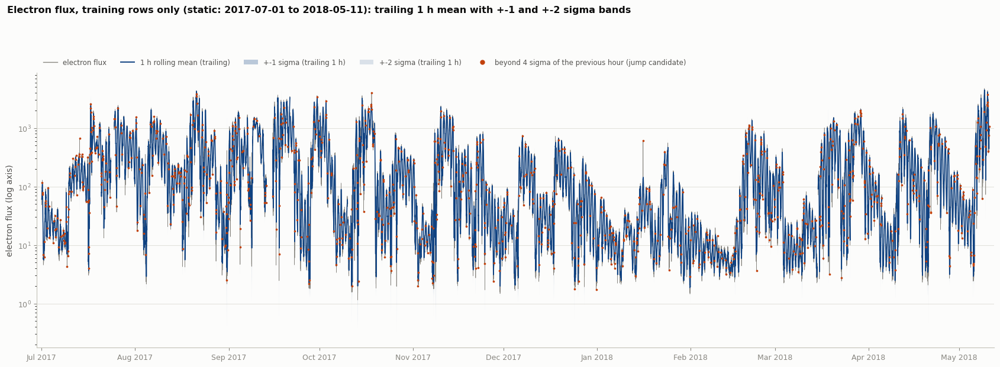

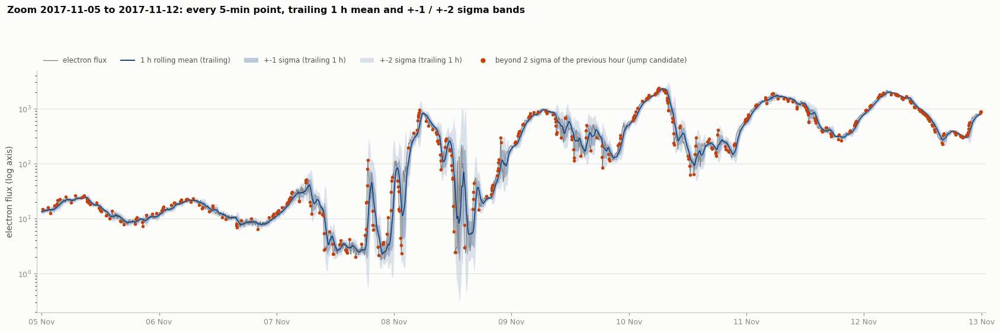

In [3]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
warnings.filterwarnings("ignore")
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, static_window
from runio import RUN, load_grid

WINDOW = "static"                      # the dedicated static train/val/test split (its training rows = everything up to 24 h before the static validation window)
WIN = 12                               # 1 hour = 12 five-minute steps
ZOOM = ("2017-11-05", "2017-11-12")    # second figure: this stretch at full 5-min resolution (change it to any stretch inside the training rows)
JUMP_Z_FULL, JUMP_Z_ZOOM = 4, 2       # mark points beyond this many previous-hour sigmas (full figure: only the big ones, otherwise the markers hide the series)
DRAW_EVERY = 6                         # full-range figure: draw the mean and bands every 6th point (30 min); the raw line uses every point
(RUN / "figs").mkdir(exist_ok=True)

# ---------------- training rows only ----------------
g = load_grid(); dev = g.loc[:P.dev_end]; w = static_window()
EMBt = pd.Timedelta(minutes=5 * P.embargo_steps)
tr = dev.loc[dev.index <= w.val_start - EMBt]                                   # validation and test rows are never touched
assert tr.index.max() < w.val_start
bad = tr[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1)
x = np.log(tr["electron"].where(tr["electron"] > 0)).where(~bad)                # log flux; flagged rows blanked (NaN), as in every earlier step

# ---------------- trailing 1 h mean and sigma, computed on log flux so the bands can never go negative ----------------
r = x.rolling(WIN, min_periods=int(WIN * 2 / 3)); m, s = r.mean(), r.std()
B = pd.DataFrame({"flux": np.exp(x), "mean": np.exp(m)})
for k in (1, 2): B[f"hi{k}"] = np.exp(m + k * s); B[f"lo{k}"] = np.exp(m - k * s)

# jump candidates: each point is compared with the band built from the PREVIOUS hour (so a point never helps define its own band)
z = (x - m.shift(1)) / s.shift(1).where(s.shift(1) > 0); v = z.dropna()
adj = np.sqrt(1 + 1 / WIN)                  # prediction-interval correction for a mean/sd estimated from only 12 points
ref = lambda c: 2 * stats.t.sf(c / adj, WIN - 1)                                 # share outside +-c sigma if the hour were pure Gaussian noise
tab = pd.DataFrame({"observed": [(v.abs() > 1).mean(), (v.abs() > 2).mean(), (v > 2).mean(), (v < -2).mean(), (v.abs() > 4).mean()],
                    "if_noise_only": [ref(1), ref(2), ref(2) / 2, ref(2) / 2, ref(4)]}, index=["outside +-1 sigma", "outside +-2 sigma", "   above +2 sigma", "   below -2 sigma", "outside +-4 sigma"])
tab["ratio"] = tab.observed / tab.if_noise_only
print(f"{WINDOW} split: validation starts {w.val_start:%Y-%m-%d}; training rows {len(tr):,} ({tr.index.min():%Y-%m-%d} to {tr.index.max():%Y-%m-%d}), usable points {int(x.notna().sum()):,}, points tested against a band {len(v):,}")
print(tab.round(4)); print("(if_noise_only = what a calm, Gaussian hour would give with a 12-point mean and sigma; ratio well above 1 = jumps and ramps)")

# ---------------- plots (matplotlib) ----------------
SURF, INK, INK2, MUTED, GRID, AXIS, BLUE, ORG = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#104281", "#c2410c"

def draw(Bs, zs, thr, title, name, figsize, every, date_fmt, locator):
    d = Bs.iloc[::every]
    fig, ax = plt.subplots(figsize=figsize, facecolor=SURF); ax.set_facecolor(SURF)
    ax.plot(Bs.index, Bs.flux, color=MUTED, lw=0.5 if every > 1 else 0.9, rasterized=True)            # raw 5-min flux (gaps stay as gaps)
    ax.fill_between(d.index, d.lo2, d.hi2, color=BLUE, alpha=0.14, lw=0)                                # +-2 sigma
    ax.fill_between(d.index, d.lo1, d.hi1, color=BLUE, alpha=0.28, lw=0)                                # +-1 sigma
    ax.plot(d.index, d["mean"], color=BLUE, lw=1.2)                                                     # trailing 1 h mean
    o = (zs.abs() > thr).reindex(Bs.index).fillna(False).to_numpy()
    ax.scatter(Bs.index[o], Bs.flux[o], s=7 if every > 1 else 16, color=ORG, zorder=5, linewidths=0)    # jump candidates
    ax.set_yscale("log"); ax.set_ylabel("electron flux (log axis)", color=INK2)
    ax.grid(axis="y", color=GRID, lw=0.7); ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(locator); ax.xaxis.set_major_formatter(mdates.DateFormatter(date_fmt))
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    for sp in ("left", "bottom"): ax.spines[sp].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9); ax.margins(x=0.005)
    handles = [Line2D([0], [0], color=MUTED, lw=1, label="electron flux"), Line2D([0], [0], color=BLUE, lw=1.4, label="1 h rolling mean (trailing)"),
               Patch(facecolor=BLUE, alpha=0.28, label="+-1 sigma (trailing 1 h)"), Patch(facecolor=BLUE, alpha=0.14, label="+-2 sigma (trailing 1 h)"),
               Line2D([0], [0], marker="o", ls="", color=ORG, ms=5, label=f"beyond {thr} sigma of the previous hour (jump candidate)")]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=5, frameon=False, fontsize=8.5, labelcolor=INK2)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11.5, color=INK, fontweight="bold", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(RUN / "figs" / f"{name}.png", dpi=150, facecolor=SURF); plt.show()

draw(B, z, JUMP_Z_FULL, f"Electron flux, training rows only ({WINDOW}: {tr.index.min():%Y-%m-%d} to {tr.index.max():%Y-%m-%d}): trailing 1 h mean with +-1 and +-2 sigma bands",
     "train_rolling_bands_full", (17, 6.2), DRAW_EVERY, "%b %Y", mdates.MonthLocator())
Bz = B.loc[ZOOM[0]:ZOOM[1]]
if len(Bz): draw(Bz, z.loc[Bz.index], JUMP_Z_ZOOM, f"Zoom {ZOOM[0]} to {ZOOM[1]}: every 5-min point, trailing 1 h mean and +-1 / +-2 sigma bands",
                 "train_rolling_bands_zoom", (17, 5.6), 1, "%d %b", mdates.DayLocator())
else: print("ZOOM is outside the training window; pick another stretch")

👀 **How to read this output**

Static split: validation starts 2018-05-12; training rows 90,432 (2017-07-01 → 2018-05-11); usable 89,103; **89,007 points tested** against a band.

| | observed | if noise only | ratio |
|---|---|---|---|
| outside ±1σ | 0.616 | 0.357 | 1.72 |
| outside ±2σ | **0.204** | 0.081 | **2.51** |
| above +2σ | 0.094 | 0.041 | 2.33 |
| below −2σ | 0.109 | 0.041 | 2.70 |
| outside ±4σ | 0.0127 | 0.0027 | **4.63** |

The flux leaves its one-hour band **2.5 times more often than noise would** at 2σ and **4.6 times** at 4σ. The series is not noise around a flat level: it **moves in ramps** (a trailing mean lags a trend, so a ramp keeps producing "jumps"), plus genuine step changes. Falls (10.9 %) are slightly more frequent beyond −2σ than rises beyond +2σ (9.4 %).

## 10.2 Do 2σ jumps cluster? Are they spikes or level shifts?

📘 **What.** Three tables built on the jump candidates ($|z_t|>2$ vs the previous hour):

* **A.** After a jump, how likely is another jump $k$ steps later (5, 10, 15, 30, 60 min), compared with the unconditional jump share (`usual_share`)? Split into up and down jumps, and for "fresh" jumps only (the first of a run) or every jump.
* **B.** After a fresh jump, the probability of **at least one more** in the next hour (vs from any point).
* **C.** After a fresh jump, does the flux **stay** beyond 2σ of the pre-jump hour (a level shift) or fall back (a one-point spike)?

📐 `ratio` $=\Pr(\text{jump at }t+k\mid\text{fresh jump at }t)\ /\ \Pr(\text{jump at any point})$; a ratio of 1 means no memory. Neighbouring jumps overlap, so the 95 % intervals are optimistic.

In [5]:
# ---- run this in the SAME kernel, right after the rolling-band cell (it reuses x, m, s, z from that cell) ----
THR, FWD, LAGS = 2.0, 12, [1, 2, 3, 6, 12]          # a "jump" = |z| > 2 vs the previous hour; look 1, 2, 3, 6, 12 steps (5, 10, 15, 30, 60 min) ahead

def wilson(k, n, a=0.05):                            # 95% interval for a share k/n
    if n == 0: return (np.nan, np.nan)
    p, zz = k / n, stats.norm.ppf(1 - a / 2); d = 1 + zz**2 / n; c = (p + zz**2 / (2 * n)) / d; h = zz * np.sqrt(p * (1 - p) / n + zz**2 / (4 * n**2)) / d
    return (c - h, c + h)

ok = z.notna().to_numpy(); zz_ = z.to_numpy(); xa, ma, sa = x.to_numpy(), m.shift(1).to_numpy(), s.shift(1).to_numpy()
n = len(zz_); ev = {"either": np.abs(np.nan_to_num(zz_)) > THR, "up": np.nan_to_num(zz_) > THR, "down": np.nan_to_num(zz_) < -THR}
sh = lambda a, k: np.r_[a[k:], np.zeros(k, bool)]   # value k steps ahead (False past the end)
prior = lambda a: np.array([a[max(0, i - FWD):i].any() for i in range(n)])      # was there a jump in the previous FWD steps?

# ============ A. is a jump followed by more jumps? (same direction for up/down) ============
rows = []
for kind, E in ev.items():
    base = E[ok].mean()
    fresh = E & ~prior(E) & ok                                                  # a NEW jump: none in the previous hour
    for who, O in (("every jump", E & ok), ("fresh jump only", fresh)):
        for k in LAGS:
            valid = O & sh(ok, k); nn = int(valid.sum()); hits = int((valid & sh(E, k)).sum()); lo, hi = wilson(hits, nn)
            rows.append(dict(kind=kind, origin=who, steps_ahead=k, minutes=5 * k, n_origin=nn, share_jump_again=hits / nn if nn else np.nan, ci_lo=lo, ci_hi=hi, usual_share=base, ratio=hits / nn / base if nn else np.nan))
A = pd.DataFrame(rows)
print(f"A. After a jump (|z| > {THR} vs the previous hour), how often is there another one k steps later?  usual_share = how often ANY point is a jump.")
print("   ratio ~ 1 = no memory; ratio >> 1 = jumps cluster.  (ci = 95% interval; neighbouring jumps overlap, so treat it as optimistic)")
print(A[A.origin == "fresh jump only"].round(3).to_string(index=False))
print("\n   same, counting every jump as an origin (includes the tail of a cluster):")
print(A[A.origin == "every jump"].round(3).to_string(index=False))

# ============ B. 'any more jumps in the next hour?' ============
rows = []
for kind, E in ev.items():
    fut = np.array([E[i + 1:i + 1 + FWD].any() for i in range(n)])
    allok = ok & np.array([ok[i + 1:i + 1 + FWD].all() if i + FWD < n else False for i in range(n)])
    fresh = E & ~prior(E) & allok
    c, u = fut[fresh], fut[allok]
    rows.append(dict(kind=kind, n_fresh_jumps=int(fresh.sum()), share_with_another_in_next_hour=c.mean(), same_for_ANY_point=u.mean(), ratio=c.mean() / u.mean()))
print("\nB. After a fresh jump, share with at least one more jump in the next hour, vs the same share starting from any ordinary point:")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ============ C. spike or level shift?  Keep the band from the hour BEFORE the jump frozen, and look where the flux sits afterwards ============
rows = []
for kind, sg in (("up", 1), ("down", -1)):
    E = ev[kind]; fresh = np.flatnonzero(E & ~prior(E) & ok)
    for k in LAGS:
        idx = fresh[fresh + k < n]; zf = sg * (xa[idx + k] - ma[idx]) / sa[idx]; zf = zf[np.isfinite(zf)]
        allt = np.flatnonzero(ok); allt = allt[allt + k < n]; zb = sg * (xa[allt + k] - ma[allt]) / sa[allt]; zb = zb[np.isfinite(zb)]
        rows.append(dict(kind=kind, minutes_after=5 * k, n=len(zf), still_beyond_2sigma_of_old_hour=(zf > THR).mean(), median_z_vs_old_hour=np.median(zf), same_for_ANY_point=(zb > THR).mean()))
print("\nC. After a fresh jump, does the flux STAY beyond 2 sigma of the hour before the jump (level shift) or fall back (one-point spike)?")
print(pd.DataFrame(rows).round(3).to_string(index=False))
A.to_csv(RUN / "reports" / "jump_followup_A.csv", index=False)

A. After a jump (|z| > 2.0 vs the previous hour), how often is there another one k steps later?  usual_share = how often ANY point is a jump.
   ratio ~ 1 = no memory; ratio >> 1 = jumps cluster.  (ci = 95% interval; neighbouring jumps overlap, so treat it as optimistic)
  kind          origin  steps_ahead  minutes  n_origin  share_jump_again  ci_lo  ci_hi  usual_share  ratio
either fresh jump only            1        5      2133             0.466  0.445  0.488        0.203  2.293
either fresh jump only            2       10      2133             0.377  0.357  0.398        0.203  1.852
either fresh jump only            3       15      2132             0.307  0.288  0.327        0.203  1.508
either fresh jump only            6       30      2130             0.187  0.171  0.204        0.203  0.918
either fresh jump only           12       60      2128             0.208  0.191  0.226        0.203  1.023
    up fresh jump only            1        5      1799             0.461  0.438  0.484

👀 **How to read this output**

**A. Clustering (either direction, fresh jumps).**

| After | 5 min | 10 min | 15 min | 30 min | 60 min |
|---|---|---|---|---|---|
| share with another jump | **46.6 %** | 37.7 % | 30.7 % | 18.7 % | 20.8 % |
| usual share (any point) | 20.3 % | 20.3 % | 20.3 % | 20.3 % | 20.3 % |
| **ratio** | **2.29** | 1.85 | 1.51 | 0.92 | 1.02 |

Same direction: after an **up** jump the share of further *up* jumps is 46 % at 5 min against a base rate of 9.4 % (ratio **4.9**), and after a **down** jump 45 % vs 10.9 % (ratio **4.1**). The excess **fades within about 15–30 minutes**: by 30 minutes the ratio is 0.92 for either direction and 1.07 / 1.24 for same-direction up / down jumps.

**B.** After a fresh jump 92.1 % of the next hours contain another jump, against 86.0 % from any point (ratio 1.07), a weak contrast only because jumps are so common (20 % of all points). In the *same direction* the effect is clear: 76 % after an up (or down) jump against 45.5 % / 48.5 % from any point (ratios 1.67 / 1.57).

**C. Level shift or spike?** After a fresh **up** jump the flux is still beyond 2σ of the old hour **66 %** of the time 5 min later and **63 % one hour later**, against 14–32 % from an ordinary point. The median $z$ against the old hour *grows* from 2.5 (5 min) to 3.4 (60 min). Down jumps behave the same (63 % → 59 %). **Jumps are mostly level shifts and ramps, not one-off spikes.**

✅ **Take-away.** Large moves cluster briefly (about 15 minutes) and persist. This is the same phenomenon the GARCH recursion already captures.

## 10.3 A Hawkes process for the jumps

📘 **What.** A **self-exciting point-process** model: a jump raises the probability of further jumps for a while. Fitted on the static training rows to jumps defined at **2σ, 3σ and 4σ**, in discrete time on the 5-min grid.

📐 **Model.** Let $N_t\in\{0,1\}$ indicate a jump in slot $t$. The intensity is
$$\lambda_t=e^{\mu(\tau_t)}+\sum_{j=1}^{k}S^{(j)}_t,\qquad S^{(j)}_{t+1}=b_j\,S^{(j)}_t+a_j\,N_t,\qquad \Pr(N_t=1\mid\mathcal F_{t-1})=1-e^{-\lambda_t}.$$
* $\mu(\tau)$ is the **baseline**: a constant (`const`) or a smooth function of the time of day $\tau$ (`tod`: two sine/cosine harmonics).
* Each of the $k=1$ or $2$ **memories** decays by a factor $b_j$ per slot and jumps by $a_j$ after an event.
* Using $1-e^{-\lambda}$ keeps the probability valid even if $\lambda>1$.
* Log-likelihood: $\ \ell=\sum_t\big[N_t\ln(1-e^{-\lambda_t})-(1-N_t)\lambda_t\big]$ (slots with no data are skipped; memory still decays through them).

**Derived quantities.**
$$\text{branching ratio }n=\sum_j\frac{a_j}{1-b_j}\ \ (\text{average number of extra jumps one jump triggers; must be }<1),\qquad
\text{half-life}_j=\frac{5\ln2}{-\ln b_j}\ \text{minutes}.$$
Models are compared with AIC ($2k_{\text{par}}+2\,\text{NLL}$), and with the log-likelihood gain over a constant jump rate without memory (milli-nats per slot).

In [6]:
# ---- run this in the SAME kernel, right after the rolling-band cell (it reuses z and tr from that cell). Static training rows only. ----
import numba as nb
from scipy import optimize

THRS = (2.0, 3.0, 4.0)                 # what counts as a jump: |z| > this many previous-hour sigmas
STEP_MIN = 5                           # one grid slot = 5 minutes

# Discrete-time Hawkes on the 5-min grid. In each slot the intensity is  lam_t = baseline_t + sum over kernels j of  S_j(t),
# where S_j decays by beta_j every slot and jumps by alpha_j after every event.  P(event in slot t) = 1 - exp(-lam_t)  (so it is a proper probability even when lam_t > 1).
# Slots with no usable data are skipped in the likelihood (the memory still decays through them).
@nb.njit
def _lam_path(e, obs, lmu, a, b, kk):
    n = e.shape[0]; S = np.zeros(2); out = np.empty(n)
    for t in range(n):
        lam = np.exp(lmu[t])
        for j in range(kk): lam += S[j]
        out[t] = lam
        for j in range(kk): S[j] = b[j] * S[j] + (a[j] * e[t] if obs[t] else 0.0)
    return out

@nb.njit
def _nll(e, obs, lmu, a, b, kk):
    n = e.shape[0]; S = np.zeros(2); ll = 0.0
    for t in range(n):
        lam = np.exp(lmu[t])
        for j in range(kk): lam += S[j]
        if obs[t]:
            if e[t] > 0: ll += np.log(-np.expm1(-lam) + 1e-300)
            else: ll -= lam
        for j in range(kk): S[j] = b[j] * S[j] + (a[j] * e[t] if obs[t] else 0.0)
    return -ll

def fit_hawkes(e, obs, tau, base, kk):
    """base = 'const' (one baseline rate) or 'tod' (baseline varies smoothly with time of day: 2 sine/cosine harmonics). kk = number of exponential memories (1 or 2)."""
    X = np.column_stack([np.ones(len(e))] + ([f(2 * np.pi * k * tau) for k in (1, 2) for f in (np.sin, np.cos)] if base == "tod" else []))
    nbp = X.shape[1]; rate = e[obs].mean()
    unpack = lambda th: (X @ th[:nbp], np.exp(th[nbp:nbp + kk]), 1 / (1 + np.exp(-th[nbp + kk:nbp + 2 * kk])))
    f = lambda th: _nll(e, obs, *unpack(th), kk)
    starts = ([(0.1, 0.5), (0.3, 0.8)] if kk == 1 else [((0.1, 0.4), (0.05, 0.9)), ((0.2, 0.6), (0.03, 0.97))]); best = None
    lo = [-12] * nbp + [-12] * kk + [-6] * kk; hi = [3] * nbp + [3] * kk + [8] * kk
    for st in starts:
        al, be = (np.atleast_1d(st[0]), np.atleast_1d(st[1])) if kk == 1 else (np.array(st[0]), np.array(st[1]))
        th0 = np.r_[np.log(-np.log(1 - rate) * 0.5), np.zeros(nbp - 1), np.log(al), np.log(be / (1 - be))]
        r = optimize.minimize(f, th0, method="L-BFGS-B", bounds=list(zip(lo, hi)))
        if best is None or r.fun < best.fun: best = r
    lmu, a, b = unpack(best.x); o = np.argsort(b); a, b = a[o], b[o]        # fast memory first
    return dict(nll=best.fun, k=len(best.x), lmu=lmu, a=a, b=b, theta=best.x, ok=bool(best.success))

def null_nll(e, obs):                                  # constant rate, no memory
    p = e[obs].mean(); return -(e[obs] * np.log(p) + (1 - e[obs]) * np.log(1 - p)).sum()

# ---------------- build the event series from z (jump = |z| > thr) ----------------
obs = z.notna().to_numpy(); zz = np.nan_to_num(z.to_numpy()); tau = ((tr.index.hour * 60 + tr.index.minute).to_numpy() / 1440.0)
rows, FITS = [], {}
for thr in THRS:
    e = ((np.abs(zz) > thr) & obs).astype(np.float64); n0 = null_nll(e, obs); N = int(obs.sum()); sub = []
    for base in ("const", "tod"):
        for kk in (1, 2):
            R = fit_hawkes(e, obs, tau, base, kk); FITS[(thr, base, kk)] = R; aic = 2 * R["k"] + 2 * R["nll"]
            hl = "/".join(f"{STEP_MIN * np.log(2) / -np.log(b_):.0f}" for b_ in R["b"]); br = float((R["a"] / (1 - R["b"])).sum())
            sub.append(dict(jump_size=f"{thr:g} sigma", events=int(e.sum()), rate_pct=round(100 * e[obs].mean(), 2), baseline=base, memories=kk, branching_ratio=round(br, 3),
                            half_life_min=hl, gain_mnats_per_slot=round(1000 * (n0 - R["nll"]) / N, 3), aic=aic, converged=R["ok"]))
    d = pd.DataFrame(sub); d["delta_aic"] = (d.aic - d.aic.min()).round(1); rows.append(d.drop(columns="aic"))
T = pd.concat(rows, ignore_index=True)
print("Hawkes fits on the static training rows.  branching_ratio = average number of extra jumps each jump triggers (must be < 1);  half_life_min = how fast that memory fades;")
print("gain_mnats_per_slot = log-likelihood gain over a constant jump rate with no memory;  delta_aic = 0 is the best model for that jump size (lower is better).")
print(T.to_string(index=False))

# ---------------- does the fitted model's probability match what happens? (best model per jump size, 5 equal-count bins) ----------------
print("\nCalibration of the best-AIC model per jump size: predicted vs observed jump share, from the lowest to the highest predicted probability")
for thr in THRS:
    key = min((k for k in FITS if k[0] == thr), key=lambda k: 2 * FITS[k]["k"] + 2 * FITS[k]["nll"]); R = FITS[key]
    e = ((np.abs(zz) > thr) & obs).astype(np.float64); lam = _lam_path(e, obs, R["lmu"], R["a"], R["b"], len(R["a"])); p = 1 - np.exp(-lam)
    q = pd.qcut(pd.Series(p[obs]), 5, duplicates="drop"); g = pd.DataFrame({"pred": p[obs], "obs": e[obs]}).groupby(q.values).mean()
    print(f"  {thr:g} sigma, best = baseline '{key[1]}', {key[2]} memory(ies):  predicted " + " ".join(f"{v:.3f}" for v in g.pred) + "   observed " + " ".join(f"{v:.3f}" for v in g.obs))

Hawkes fits on the static training rows.  branching_ratio = average number of extra jumps each jump triggers (must be < 1);  half_life_min = how fast that memory fades;
gain_mnats_per_slot = log-likelihood gain over a constant jump rate with no memory;  delta_aic = 0 is the best model for that jump size (lower is better).
jump_size  events  rate_pct baseline  memories  branching_ratio half_life_min  gain_mnats_per_slot  converged  delta_aic
  2 sigma   18111     20.35    const         1            0.552             2               53.380       True       89.6
  2 sigma   18111     20.35    const         2            0.552           2/2               53.380       True       93.6
  2 sigma   18111     20.35      tod         1            0.548             2               53.856       True       12.9
  2 sigma   18111     20.35      tod         2            0.730        2/5301               53.951       True        0.0
  3 sigma    4192      4.71    const         1            0.261        

👀 **How to read this output**

| Jump size | events | rate | best model (Δ AIC = 0) | branching ratio | half-life | gain (milli-nats/slot) |
|---|---|---|---|---|---|---|
| **2σ** | 18,111 | 20.35 % | `tod`, 2 memories | 0.730 (1 memory: 0.548) | 2 min / **5,301 min** | 53.95 |
| **3σ** | 4,192 | 4.71 % | `tod`, 1 memory | **0.261** | 1 min | 12.55 |
| **4σ** | 1,127 | 1.27 % | `tod`, 1 memory | **0.127** | 1 min | 2.58 |

* **The memory is real but short.** At 2σ one jump triggers on average **0.55** extra jumps with a single memory (**0.73** in the best model, which adds a slow component), at 3σ **0.26**, at 4σ **0.13**; the fast half-life is only **1–2 minutes** (one slot or less). This matches table A: the excess clustering is gone within 15–30 min.
* The 2-memory 2σ fit adds a *very slow* component (half-life 5,301 min ≈ 3.7 days). That is most likely not memory of individual jumps but **slow drift in the jump rate** (calm vs stormy weeks); the notebook does not test this directly.
* A time-of-day baseline always wins on AIC: at 2σ the best constant-baseline model is 89.6 AIC points behind and even the single-memory `tod` model is 12.9 behind; at 3σ and 4σ the constant baseline loses by 27.6 and 17.7. The jump rate depends on the clock.
* **Calibration** (predicted vs observed jump share by quintile of predicted probability): for 2σ predicted 0.113 / 0.124 / 0.134 / 0.166 / 0.481 against observed 0.117 / 0.124 / 0.127 / 0.166 / 0.483. The model is well calibrated, and the top quintile (states right after a jump) has a 48 % chance of another jump.

✅ **Take-away (not a main direction).** Hawkes works as an *aftershock model*, but the gain is small and short-lived; the GJR-GARCH of Part 8 already captures the clustering. It is documented as a negative result.

## 10.4 Is there a daily rhythm at 30, 45 and 60 min? (seasonality test)

📘 **What.** On the static training rows, for each horizon $h\in\{30,45,60\}$ min, takes **one non-overlapping change per slot of the day** and asks whether the mean (and the size) of the change depends on the clock. Two series are tested: the **signed** change $\Delta$ and its **size** $|\Delta|$.

📐 **Tests.**

* **HAC Wald test** that every time-of-day bin has the same mean, $H_0:\mu_1=\dots=\mu_B$ (small $p$ ⇒ a daily pattern).
* **In-sample $R^2$** of the bin means: $\ 1-\dfrac{\sum(\Delta_t-\bar\Delta_{b(t)})^2}{\sum(\Delta_t-\bar\Delta)^2}$.
* **Out-of-sample $R^2$**: bin means learned on the **first 60 %** of rows, scored on the **last 40 %** against the training mean (negative would mean the pattern does not carry over).
* **Autocorrelation at 1 day and 12 h** against the 95 % band $\pm1.96/\sqrt N$. A 24 h wave gives a **positive** value at 1 day and a **negative** one at 12 h.
* **Periodogram power at 1 and 2 cycles per day**, as a multiple of the median power (≈ 1 = nothing special; large = a cycle).

Seasonality of the 30 min, 45 min and 1 h changes in log flux, static training rows 2017-07-01 to 2018-05-11. One non-overlapping change per time-of-day slot.
p_equal_bins: HAC Wald test that every time-of-day bin has the same mean (small = there is a daily pattern).   R2_in_sample: share of the variance the bin means explain.
R2_out_of_sample: pattern learned on the first 60% of rows, scored on the last 40% (negative = the pattern does not carry over).   bin_mean_range_x100: highest minus lowest bin mean, in log-points x100.
acf_1day / acf_12h: autocorrelation at 1 day / 12 h (compare with +-acf_band_95).   spec_*: periodogram power at 1 or 2 cycles per day, as a multiple of the median power (about 1 = nothing special; large = a seasonal cycle).
horizon          series     n  p_equal_bins  R2_in_sample  R2_out_of_sample  bin_mean_range_x100  acf_1day  acf_12h  acf_band_95  spec_1perDay_x_median  spec_2perDay_x_median
 30 min change (signed) 14836             0       0.07489           

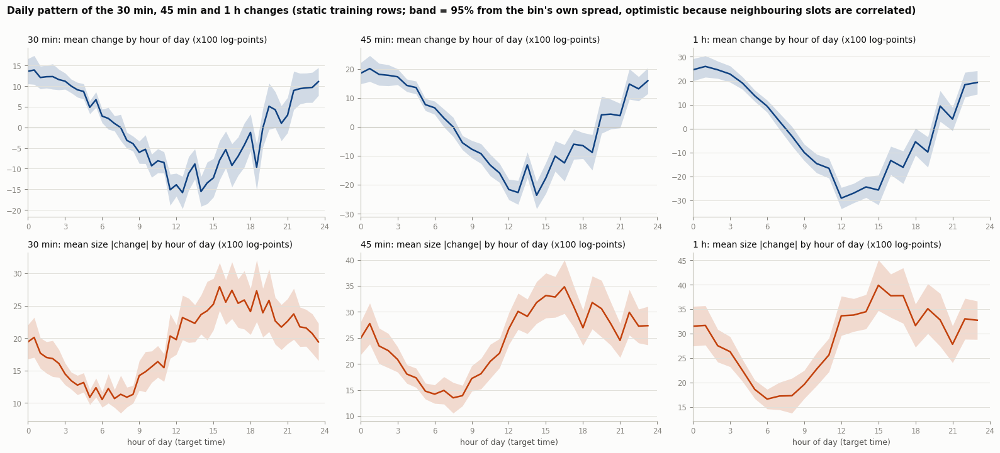

In [7]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, signal
warnings.filterwarnings("ignore")
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, static_window
from runio import RUN, load_grid

HZ = {"30 min": 6, "45 min": 9, "1 h": 12}          # horizons in 5-min steps; each divides 24 h exactly (48, 32, 24 slots per day)
SPLIT = 0.6                                         # out-of-sample check: learn the time-of-day pattern on the first 60% of the training rows, score on the last 40%
(RUN / "figs").mkdir(exist_ok=True); (RUN / "reports").mkdir(exist_ok=True)

# ---------------- training rows only (the static split's training set) ----------------
g = load_grid(); dev = g.loc[:P.dev_end]; w = static_window(); EMBt = pd.Timedelta(minutes=5 * P.embargo_steps)
tr = dev.loc[dev.index <= w.val_start - EMBt]; assert tr.index.max() < w.val_start
bad = tr[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1)
x = np.log(tr["electron"].where(tr["electron"] > 0)).where(~bad)
tod = (tr.index.hour * 60 + tr.index.minute).to_numpy()

def bins_fit(y, b, nb):                              # mean per time-of-day bin
    return np.array([y[b == k].mean() if (b == k).any() else np.nan for k in range(nb)])

def wald_p(y, b, nb, lags):                          # H0: every time-of-day bin has the same mean. Wald test with HAC errors (robust to autocorrelation / changing volatility)
    D = np.zeros((len(y), nb)); D[np.arange(len(y)), b] = 1; keep = D.sum(0) > 0; D = D[:, keep]; k = D.shape[1]
    import statsmodels.api as sm
    res = sm.OLS(y, D).fit(cov_type="HAC", cov_kwds={"maxlags": lags}); Rm = np.c_[-np.ones(k - 1), np.eye(k - 1)]
    d = Rm @ res.params; stat = float(d @ np.linalg.solve(Rm @ res.cov_params() @ Rm.T, d)); return stats.chi2.sf(stat, k - 1), stat, k - 1

def r2_bins(y, b, nb, cut):                          # in-sample R2 of the bin means, and out-of-sample R2 (pattern learned on y[:cut], scored on y[cut:] against the training mean)
    m = bins_fit(y, b, nb); r_in = 1 - ((y - m[b]) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    mt = bins_fit(y[:cut], b[:cut], nb); ok = np.isfinite(mt[b[cut:]]); yy, bb = y[cut:][ok], b[cut:][ok]
    r_out = 1 - ((yy - mt[bb]) ** 2).sum() / ((yy - y[:cut].mean()) ** 2).sum(); return r_in, r_out, m

rows, PLOT = [], {}
for name, H in HZ.items():
    step = 5 * H; nb = 1440 // step; per_day = nb
    d = (x - x.shift(H)); sel = (tod % step == 0); ds = d[sel]                      # non-overlapping changes, one per time-of-day slot, aligned to the day
    b_all = (tod[sel] // step).astype(int); v = ds.notna().to_numpy(); arr = ds.to_numpy()
    for lab, tf in (("change (signed)", lambda a: a), ("size |change|", np.abs)):
        yfull = tf(arr); y, b = yfull[v], b_all[v]; cut = int(len(y) * SPLIT)
        p, stat, dfree = wald_p(y, b, nb, lags=per_day); r_in, r_out, m = r2_bins(y, b, nb, cut)
        s = pd.Series(yfull); ac = lambda L: s.autocorr(L)                           # autocorrelation at 1 day / 12 h on the day-aligned series (gaps skipped)
        f = np.where(np.isfinite(yfull), yfull, np.nanmean(yfull)); fr, pw = signal.periodogram(f - f.mean(), fs=per_day, window="hann", detrend=False)
        pk = lambda c: pw[np.argmin(np.abs(fr - c))] / np.median(pw[1:])             # power at 1 cycle/day (or 2) relative to the typical frequency
        rows.append(dict(horizon=name, series=lab, n=len(y), p_equal_bins=p, R2_in_sample=r_in, R2_out_of_sample=r_out, bin_mean_range_x100=100 * (np.nanmax(m) - np.nanmin(m)),
                         acf_1day=ac(per_day), acf_12h=ac(per_day // 2), acf_band_95=1.96 / np.sqrt(v.sum()), spec_1perDay_x_median=pk(1.0), spec_2perDay_x_median=pk(2.0)))
        PLOT[(name, lab)] = (m, np.array([y[b == k].std(ddof=1) / np.sqrt((b == k).sum()) if (b == k).sum() > 1 else np.nan for k in range(nb)]), nb)
T = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.float_format", lambda v: f"{v:.4g}")
print(f"Seasonality of the 30 min, 45 min and 1 h changes in log flux, static training rows {tr.index.min():%Y-%m-%d} to {tr.index.max():%Y-%m-%d}. One non-overlapping change per time-of-day slot.")
print("p_equal_bins: HAC Wald test that every time-of-day bin has the same mean (small = there is a daily pattern).   R2_in_sample: share of the variance the bin means explain.")
print(f"R2_out_of_sample: pattern learned on the first {int(SPLIT*100)}% of rows, scored on the last {100-int(SPLIT*100)}% (negative = the pattern does not carry over).   bin_mean_range_x100: highest minus lowest bin mean, in log-points x100.")
print("acf_1day / acf_12h: autocorrelation at 1 day / 12 h (compare with +-acf_band_95).   spec_*: periodogram power at 1 or 2 cycles per day, as a multiple of the median power (about 1 = nothing special; large = a seasonal cycle).")
print(T.to_string(index=False)); T.to_csv(RUN / "reports" / "seasonality_30_45_60.csv", index=False)

# ---------------- picture: mean change and mean size of change by time of day ----------------
SURF, INK, INK2, MUTED, GRID, AXIS, BLUE, ORG = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#104281", "#c2410c"
fig, axs = plt.subplots(2, 3, figsize=(16, 7.2), facecolor=SURF)
for j, name in enumerate(HZ):
    for i, (lab, col, ttl) in enumerate((("change (signed)", BLUE, "mean change"), ("size |change|", ORG, "mean size |change|"))):
        m, se, nb = PLOT[(name, lab)]; hrs = np.arange(nb) * 24 / nb; ax = axs[i, j]; ax.set_facecolor(SURF)
        ax.fill_between(hrs, 100 * (m - 1.96 * se), 100 * (m + 1.96 * se), color=col, alpha=0.18, lw=0); ax.plot(hrs, 100 * m, color=col, lw=1.8)
        if i == 0: ax.axhline(0, color=AXIS, lw=0.8)
        ax.set_title(f"{name}: {ttl} by hour of day (x100 log-points)", fontsize=10, color=INK, loc="left"); ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3))
        ax.grid(axis="y", color=GRID, lw=0.7); ax.tick_params(colors=MUTED, labelsize=8.5)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
        for sp in ("left", "bottom"): ax.spines[sp].set_color(AXIS)
        if i == 1: ax.set_xlabel("hour of day (target time)", color=INK2, fontsize=9)
fig.text(0.01, 0.995, "Daily pattern of the 30 min, 45 min and 1 h changes (static training rows; band = 95% from the bin's own spread, optimistic because neighbouring slots are correlated)", ha="left", va="top", fontsize=11, color=INK, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(RUN / "figs" / "seasonality_30_45_60.png", dpi=150, facecolor=SURF); plt.show()

👀 **How to read this output**

| Series | $R^2$ in sample | **$R^2$ out of sample** | ACF 1 day (band) | ACF 12 h | power 1/day | power 2/day |
|---|---|---|---|---|---|---|
| 30 min, signed | 7.5 % | **5.0 %** | 0.088 (0.016) | −0.080 | **588×** | 1.1× |
| 45 min, signed | 11.6 % | **7.4 %** | 0.127 (0.020) | −0.144 | **694×** | 1.9× |
| 1 h, signed | 15.8 % | **11.4 %** | 0.202 (0.023) | −0.191 | **778×** | 1.0× |
| 30 min, size | 3.7 % | 0.9 % | 0.102 | +0.044 | 367× | **22×** |
| 45 min, size | 4.1 % | 2.0 % | 0.134 | +0.067 | 237× | **51×** |
| 1 h, size | 3.9 % | 0.4 % | 0.133 | +0.077 | 166× | **50×** |

* **The signed change has a real 24-hour wave.** $p\approx0$ for every horizon; **5.0 / 7.4 / 11.4 % of the variance is explained out of sample** by clock time alone; the 1-day ACF is positive and the 12-h ACF negative; essentially all power sits at **one cycle per day** (590–780× the median) and none at two. The highest bin mean minus the lowest is ≈ 0.30 / 0.44 / 0.55 in log units (a factor 1.35 – 1.7 between the clock times of strongest rise and strongest fall).
* **The size of the change has only a weak daily pattern**: out-of-sample $R^2$ is 0.9 / 2.0 / 0.4 %, with a visible 12-hour harmonic (22–51× the median power at two cycles per day).
* The **signed** effect grows with the horizon (out-of-sample $R^2$ 5.0 → 7.4 → 11.4 %), in line with the growing AR coefficient on the cosine term; the size effect does not grow in the same way.

✅ **Take-away.** The time-of-day sine/cosine terms already included in `ar_final` and in LightGBM (`s1,c1,s2,c2,tod`) cover this. A natural follow-up that has **not** been run is an **ablation**: drop those terms on the same folds to measure how much of each model's $R^2_\Delta$ they provide.

## 10.5 Robustness check: XGBoost against LightGBM

📘 **What.** Refits the same problem with **XGBoost** to see whether LightGBM's results depend on that library. Same rows, folds, embargo and 26 features; loads `preds/lgbm.npz` and asserts identical rows.

| | LightGBM | XGBoost counterpart |
|---|---|---|
| tree growth | leaf-wise, 15 leaves | `grow_policy="lossguide"`, `max_leaves=15` |
| min samples per leaf | `min_child_samples=500` | `min_child_weight=500` (equal for squared loss, Hessian = 1) |
| squared loss | `regression` | `reg:squarederror` |
| Huber loss | `huber`, $\alpha=1.345\hat\sigma_{\text{MAD}}$ | `reg:pseudohubererror`, `huber_slope` $=1.345\hat\sigma_{\text{MAD}}$ |
| early stopping | 100 rounds, then refit with $1.1\times$ best | the same |

(`pseudohubererror` is the smooth Pseudo-Huber loss $\delta^2\big(\sqrt{1+(r/\delta)^2}-1\big)$ rather than the exact Huber loss, so the two Huber variants are close but not identical.)

It reports pooled and per-fold $R^2_\Delta$ for single models and blends (`blend_lgb`, `blend_xgb`, and `blend4` = average of all four), **Diebold–Mariano tests** (LightGBM → XGBoost), bootstrap intervals of the squared-error reduction, the **correlation between predictions**, trees and fit times.

done 30min
done 45min
done 1h
R2 of the change, pooled over the 5 validation folds (same rows for every model)
H              30min  45min     1h
model                             
seasonal      0.0749 0.1130 0.1500
ar_final      0.1060 0.1547 0.1997
lgb_ext       0.1419 0.1935 0.2412
xgb_ext       0.1415 0.1892 0.2390
lgb_ext_huber 0.1452 0.1920 0.2359
xgb_ext_huber 0.1391 0.1924 0.2393
blend_lgb     0.1494 0.2004 0.2458
blend_xgb     0.1466 0.1977 0.2470
blend4        0.1485 0.1996 0.2471

R2 of the change per fold
fold                   cv1    cv2    cv3    cv4    cv5
H     model                                           
30min lgb_ext       0.1557 0.1358 0.0880 0.1580 0.1770
      xgb_ext       0.1604 0.1327 0.0825 0.1581 0.1762
      lgb_ext_huber 0.1508 0.1526 0.1063 0.1487 0.1850
      xgb_ext_huber 0.1480 0.1488 0.0848 0.1507 0.1794
      blend_lgb     0.1620 0.1512 0.1008 0.1586 0.1845
      blend_xgb     0.1617 0.1505 0.0896 0.1593 0.1817
      blend4        0.1626 0.1515 0.0

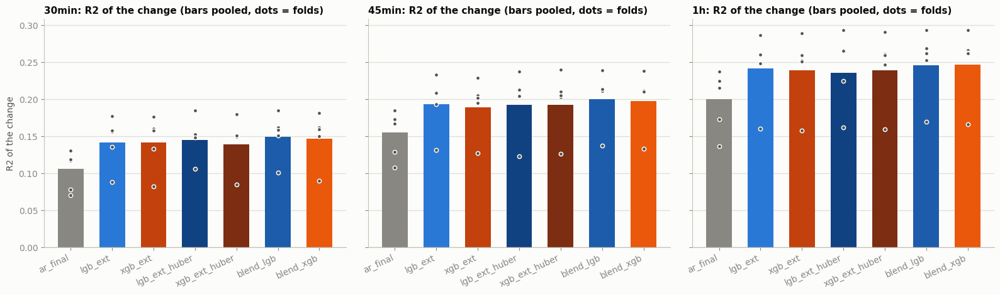

In [8]:
import sys, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import xgboost as xgb
sys.path.insert(0, "/kaggle/working/final_run")
import importlib, core, runio; importlib.reload(core); importlib.reload(runio)
from core import P, make_folds, test_window
from runio import RUN, load_grid
warnings.filterwarnings("ignore")

# ------------------------------------------------ setup: identical to the LightGBM cell (dev period only, same folds, same rows)
g = load_grid(); dev = g.loc[:P.dev_end]; folds = make_folds()
assert dev.index.max() < test_window(g.index).val_start, "dev window overlaps the sealed test"
for sub in ("preds", "reports", "figs"): (RUN / sub).mkdir(exist_ok=True)
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
                     "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "semibold", "legend.frameon": False})
HZ = {"30min": 6, "45min": 9, "1h": 12}
EMB = P.embargo_steps; EMBt = pd.Timedelta(minutes=5 * EMB)
y = np.log(dev["electron"].where(dev["electron"] > 0)).to_numpy()
tod = np.asarray((dev.index.hour * 60 + dev.index.minute - 5) % 1440); th = 2 * np.pi * tod / 1440
bad = dev[["outage_noncausal", "qc_near_outage_noncausal", "qc_spike_noncausal"]].fillna(0).astype(bool).any(axis=1).to_numpy()

def metrics(yt, yp, y0):
    e = yt - yp; sse = (e ** 2).sum(); d = yt - y0
    return dict(n=len(yt), mse_log=sse / len(yt), r2_log=1 - sse / ((yt - yt.mean()) ** 2).sum(), r2_delta=1 - sse / ((d - d.mean()) ** 2).sum(), skill_vs_persist=1 - sse / (d ** 2).sum())

LAGS = [1, 2, 3, 6, 12, 24, 36, 72, 144, 216, 288]
def build_feats(yv, H):                                          # exactly the same causal features as the LightGBM cell
    yf = pd.Series(yv).ffill(); F = {}
    for L in LAGS: F[f"d{L}"] = (yf - yf.shift(L)).to_numpy()
    for K in (72, 288, 864): F[f"dev{K}"] = (yf - yf.rolling(K, min_periods=K // 2).mean()).to_numpy()
    F["s1"], F["c1"], F["s2"], F["c2"] = np.sin(th), np.cos(th), np.sin(2 * th), np.cos(2 * th)
    F["tod"] = tod.astype(float)
    sd = np.vstack([(yf.shift(288 * k - H) - yf.shift(288 * k)).to_numpy() for k in (1, 2, 3)])
    F["sd1"] = sd[0]; F["sd3"] = np.nanmean(sd, axis=0)
    dy = yf.diff()
    for K in (12, 72, 288): F[f"vol{K}"] = dy.rolling(K, min_periods=K // 2).std().to_numpy()
    F["rng72"] = (yf.rolling(72, min_periods=36).max() - yf.rolling(72, min_periods=36).min()).to_numpy()
    obs = np.isfinite(yv); last = np.maximum.accumulate(np.where(obs, np.arange(len(yv)), -1))
    F["stale"] = np.minimum(np.arange(len(yv)) - last, 288).astype(float)
    return F
AR_COLS = [f"d{L}" for L in LAGS] + ["s1", "c1", "s2", "c2"]
EXT_COLS = [f"d{L}" for L in LAGS] + ["dev72", "dev288", "dev864", "s1", "c1", "s2", "c2", "tod", "sd1", "sd3", "vol12", "vol72", "vol288", "rng72", "stale"]
AR_IDX = [EXT_COLS.index(c) for c in AR_COLS]

# ------------------------------------------------ XGBoost, set up like the LightGBM models (same protocol, nothing tuned)
#   leaf-wise growth with 15 leaves (grow_policy="lossguide"), learning rate 0.03, 80% row and column sampling, L2 = 10,
#   min_child_weight = 500 (for squared error the hessian is 1 per row, so this equals LightGBM's min_child_samples = 500),
#   inner early stopping on the last 20% of the training rows with a 24 h gap, then refit on all training rows with 1.1 x the best number of trees.
def fit_xgb(Xt, dt, opos, H, objective):
    n = len(Xt); cut = int(n * 0.8); inner = (opos + H) <= (opos[cut] - EMB)
    scale = 1.4826 * np.median(np.abs(dt - np.median(dt)))
    params = dict(objective=objective, learning_rate=0.03, max_leaves=15, max_depth=0, grow_policy="lossguide", tree_method="hist", max_bin=255, min_child_weight=500,
                  subsample=0.8, colsample_bytree=0.8, reg_lambda=10.0, n_estimators=3000, n_jobs=-1, random_state=0, verbosity=0)
    if objective == "reg:pseudohubererror": params["huber_slope"] = 1.345 * scale                      # xgboost's smooth Huber (LightGBM uses the exact Huber; same slope setting)
    m = xgb.XGBRegressor(**params, early_stopping_rounds=100).fit(Xt[inner], dt[inner], eval_set=[(Xt[cut:], dt[cut:])], verbose=False)
    best = int(m.best_iteration) + 1; params["n_estimators"] = int(best * 1.1) + 1
    return xgb.XGBRegressor(**params).fit(Xt, dt), best
XGB = {"xgb_ext": "reg:squarederror", "xgb_ext_huber": "reg:pseudohubererror"}

Z = np.load(RUN / "preds" / "lgbm.npz")                          # the LightGBM predictions saved by the LightGBM cell (same rows, same folds)
store, iters, secs, SAVE = {}, [], [], {}
for hn, H in HZ.items():
    F = build_feats(y, H); n = len(y); i = np.arange(n - H); j = i + H
    XE = np.column_stack([F[c][i] for c in EXT_COLS]); XA = XE[:, AR_IDX]
    ok = np.isfinite(y[i]) & np.isfinite(y[j]) & ~bad[j] & np.isfinite(XA).all(axis=1)
    delta = y[j] - y[i]; tt, ot = dev.index[j], dev.index[i]
    for w in folds:
        tr = ok & ~bad[i] & np.asarray(tt <= w.val_start - EMBt)
        va = ok & np.asarray((ot >= w.val_start) & (tt < w.val_end))
        assert tt[tr].max() <= w.val_start - EMBt and ot[va].min() >= w.val_start
        y0, yt, dt, opos = y[i][va], y[j][va], delta[tr], i[tr]
        assert np.array_equal(Z[f"{hn}_{w.name}_pos"], i[va]) and np.allclose(Z[f"{hn}_{w.name}_y"], yt), "rows differ from the LightGBM run"
        preds = {k: Z[f"{hn}_{w.name}_{k}"] for k in ("persist", "seasonal", "ar_final", "lgb_ext", "lgb_ext_huber")}
        for name, obj in XGB.items():
            t0 = time.time(); m, bi = fit_xgb(XE[tr], dt, opos, H, obj); preds[name] = y0 + m.predict(XE[va])
            secs.append(dict(H=hn, fold=w.name, model=name, seconds=time.time() - t0)); iters.append(dict(H=hn, fold=w.name, model=name, best_iter=bi))
        preds["blend_lgb"] = 0.5 * preds["lgb_ext"] + 0.5 * preds["lgb_ext_huber"]; preds["blend_xgb"] = 0.5 * preds["xgb_ext"] + 0.5 * preds["xgb_ext_huber"]
        preds["blend4"] = 0.5 * preds["blend_lgb"] + 0.5 * preds["blend_xgb"]
        store.setdefault(hn, {})[w.name] = dict(yt=yt, y0=y0, ot=ot[va], preds=preds)
        SAVE.update({f"{hn}_{w.name}_{k}": preds[k] for k in ("xgb_ext", "xgb_ext_huber", "blend_xgb", "blend4")})
    print("done", hn)
np.savez_compressed(RUN / "preds" / "xgb.npz", **SAVE)

# ------------------------------------------------ reports
MODELS = ["seasonal", "ar_final", "lgb_ext", "xgb_ext", "lgb_ext_huber", "xgb_ext_huber", "blend_lgb", "blend_xgb", "blend4"]
cat = lambda hn, k: np.concatenate([store[hn][f][k] for f in store[hn]]); catp = lambda hn, m: np.concatenate([store[hn][f]["preds"][m] for f in store[hn]])
pf = pd.DataFrame([dict(H=hn, fold=f, model=m, **metrics(r["yt"], r["preds"][m], r["y0"])) for hn in HZ for f, r in store[hn].items() for m in MODELS])
pooled = pd.DataFrame([dict(H=hn, model=m, **metrics(cat(hn, "yt"), catp(hn, m), cat(hn, "y0"))) for hn in HZ for m in MODELS])
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None); pd.set_option("display.float_format", "{:.4f}".format)
print("R2 of the change, pooled over the 5 validation folds (same rows for every model)"); print(pooled.pivot(index="model", columns="H", values="r2_delta").reindex(MODELS)[list(HZ)])
print("\nR2 of the change per fold")
print(pf.pivot_table(index=["H", "model"], columns="fold", values="r2_delta", sort=False).loc[pd.IndexSlice[:, ["lgb_ext", "xgb_ext", "lgb_ext_huber", "xgb_ext_huber", "blend_lgb", "blend_xgb", "blend4"]], :])

def dm(lb, lm, L=288):                                           # Diebold-Mariano with HAC; positive = the second model (XGBoost) is better
    d = lb - lm; return float(sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": L}).tvalues[0])
PAIRS = [("lgb_ext", "xgb_ext"), ("lgb_ext_huber", "xgb_ext_huber"), ("blend_lgb", "blend_xgb"), ("blend_lgb", "blend4")]
dm_rows = []
for hn in HZ:
    for a, b in PAIRS:
        row = dict(H=hn, pair=f"{a} -> {b}")
        for scope in ["pooled", *store[hn]]:
            yt_ = cat(hn, "yt") if scope == "pooled" else store[hn][scope]["yt"]; get = (lambda k: catp(hn, k)) if scope == "pooled" else (lambda k, s=scope: store[hn][s]["preds"][k])
            row[scope] = dm((yt_ - get(a)) ** 2, (yt_ - get(b)) ** 2)
        dm_rows.append(row)
print("\nDiebold-Mariano t for 'LightGBM -> XGBoost' (positive = the second model is better; |t| > 2 is about p < 0.05)"); print(pd.DataFrame(dm_rows).set_index(["H", "pair"]))

def day_boot(hn, a, b, B=2000, seed=0):                          # day-block bootstrap of the squared-error reduction of b over a
    parts = [pd.DataFrame({"day": r["ot"].normalize(), "a": (r["yt"] - r["preds"][a]) ** 2, "b": (r["yt"] - r["preds"][b]) ** 2}).groupby("day").sum() for r in store[hn].values()]
    d = pd.concat(parts); xa, xb = d["a"].to_numpy(), d["b"].to_numpy(); idx = np.random.default_rng(seed).integers(0, len(d), size=(B, len(d)))
    return 1 - xb.sum() / xa.sum(), *np.percentile(1 - xb[idx].sum(1) / xa[idx].sum(1), [2.5, 97.5])
bt = pd.DataFrame([dict(H=hn, pair=f"{a} -> {b}", sse_reduction=s, lo95=lo, hi95=hi) for hn in HZ for a, b in PAIRS for s, lo, hi in [day_boot(hn, a, b)]]).set_index(["H", "pair"])
print("\nrelative squared-error reduction of the second model over the first, with a 95% day-block bootstrap interval (0 = identical)"); print(bt)

ag = []
for hn in HZ:
    for a, b in (("lgb_ext", "xgb_ext"), ("lgb_ext_huber", "xgb_ext_huber")):
        da, db = catp(hn, a) - cat(hn, "y0"), catp(hn, b) - cat(hn, "y0")
        ag.append(dict(H=hn, pair=f"{a} vs {b}", corr_of_predicted_change=np.corrcoef(da, db)[0, 1], std_ratio_xgb_over_lgb=db.std() / da.std(), rms_gap_over_rms_lgb=np.sqrt(((da - db) ** 2).mean()) / np.sqrt((da ** 2).mean())))
print("\nhow alike are the predictions?"); print(pd.DataFrame(ag).set_index(["H", "pair"]))
print("\nbest number of trees (early stopping) per fold"); print(pd.DataFrame(iters).pivot_table(index=["H", "model"], columns="fold", values="best_iter"))
print("\nfit time in seconds (early-stopping fit + refit), summed over the 5 folds"); print(pd.DataFrame(secs).groupby(["H", "model"]).seconds.sum().round(1).unstack())
pooled.to_csv(RUN / "reports" / "xgb_vs_lgb_pooled.csv", index=False); pf.to_csv(RUN / "reports" / "xgb_vs_lgb_per_fold.csv", index=False); bt.to_csv(RUN / "reports" / "xgb_vs_lgb_bootstrap.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True); ms = ["ar_final", "lgb_ext", "xgb_ext", "lgb_ext_huber", "xgb_ext_huber", "blend_lgb", "blend_xgb"]
cl = {"ar_final": MUTED, "lgb_ext": RAMP[2], "xgb_ext": "#c2410c", "lgb_ext_huber": RAMP[4], "xgb_ext_huber": "#7c2d12", "blend_lgb": RAMP[3], "blend_xgb": "#ea580c"}
for ax, hn in zip(axes, HZ):
    for xi, m in enumerate(ms):
        pv = pooled[(pooled.H == hn) & (pooled.model == m)]["r2_delta"].iloc[0]; fv = pf[(pf.H == hn) & (pf.model == m)]["r2_delta"]
        ax.bar(xi, pv, 0.62, color=cl[m]); ax.plot(np.full(len(fv), xi), fv, "o", ms=4.5, color=INK2, mec=SURF, mew=1.1, zorder=3)
    ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(range(len(ms))); ax.set_xticklabels(ms, rotation=25, ha="right"); ax.set_title(f"{hn}: R2 of the change (bars pooled, dots = folds)")
axes[0].set_ylabel("R2 of the change"); fig.tight_layout(); fig.savefig(RUN / "figs" / "xgb_vs_lgb_r2_change.png", dpi=150, bbox_inches="tight"); plt.show()

👀 **How to read this output**

| $R^2_\Delta$ pooled | 30 min | 45 min | 1 h |
|---|---|---|---|
| `lgb_ext` | 0.1419 | 0.1935 | 0.2412 |
| `xgb_ext` | 0.1415 | 0.1892 | 0.2390 |
| `lgb_ext_huber` | 0.1452 | 0.1920 | 0.2359 |
| `xgb_ext_huber` | 0.1391 | 0.1924 | 0.2393 |
| **`blend_lgb`** | **0.1494** | **0.2004** | 0.2458 |
| `blend_xgb` | 0.1466 | 0.1977 | 0.2470 |
| `blend4` | 0.1485 | 0.1996 | **0.2471** |

* **No meaningful disparity.** Differences between the two libraries are **at most about 0.006 of $R^2_\Delta$** (the largest: Huber at 30 min, 0.1452 vs 0.1391) and change sign across horizons.
* **Pooled, wherever DM rejects, LightGBM is the slightly better one:** `blend_lgb → blend_xgb` $t$ = −2.5 (30 min) and −2.3 (45 min), with a squared-error change of −0.3 % (CI −0.6 % … −0.1 %); Huber at 30 min −3.4 and `lgb_ext` at 45 min −2.6. At 1 h the sign flips (+0.77 for the blend, not significant). By fold, cv3 favours LightGBM clearly (down to $t=-4.7$ at 30 min) while cv4 at 1 h favours XGBoost ($t$ = +3.9 Huber, +2.3 blend): the difference is fold-dependent, not systematic.
* **The models are almost the same function:** correlation of predicted changes **0.990 / 0.993 / 0.994** (squared loss) and 0.978 / 0.984 / 0.985 (Huber).
* **Best trees** are similar (e.g. 1 h `xgb_ext`: 435 / 205 / 78 / 180 / 177) and fit time is about 20–25 s for the five folds.
* The four-way blend and `blend_xgb` tie for the best 1 h score (0.2471 / 0.2470); neither is consistently better elsewhere.

✅ **Take-away.** XGBoost reproduces the LightGBM results; **keep the LightGBM blend** as the headline and report XGBoost as a robustness check. (The two share the same features, so this is a check on the *library*, not an independent confirmation of the features.)

---
# Part 11 · Conclusions

## 11.1 What held up under the frozen protocol

| Claim | Evidence |
|---|---|
| **A leak-controlled protocol** can be built and verified | 6 of 6 deliberate leaks caught; 4 of 4 clean builders pass; fit-independence test passes; grid md5 stored |
| **The daily cycle matters, as a shape for changes** | climatology fails as a level predictor (45 min $R^2_{\log}$ −0.08) but the same cycle gives out-of-sample $R^2$ of 5.0 / 7.4 / 11.4 % on changes |
| **The mean forecast beats persistence** | AR 0.106 / 0.155 / 0.200; LightGBM blend **0.149 / 0.200 / 0.246** ($R^2_\Delta$) |
| **The skill is not an artefact** | AR placebo: real skill 9–10× the best of 30 placebo draws; LightGBM placebo: 32–37 standard deviations above the placebo mean |
| **Non-linearity adds a real but modest gain** | `lgb_ext` cuts the AR's squared error by 4–5 %; `ar_rich` (more linear seasonality) does not close the gap |
| **Volatility clusters strongly at 30–60 min** | ACF of $\lvert\Delta\rvert$ at lag 1 is 0.34–0.40 and decays over 5–13 h; BIC of `const` vs GARCH differs by thousands |
| **GJR-GARCH beats EWMA, rolling windows and constant variance** | all DM tests $p\approx0$; $R^2_{\lvert\cdot\rvert}$ 0.162 / 0.150 / 0.133 vs 0.146 / 0.133 / 0.112 for EWMA |
| **Fat tails and asymmetry are real** | raw $\nu\approx2$; $\nu\approx4.5$ after standardising; $1+\gamma/\alpha_1$ rises to 1.5 (Student-$t$ fit, 30 min) and 2.1–2.4 (Gaussian fits) |
| **A GARCH-based band adds value over a fixed width** | interval-score DM $z$ = 8.8–9.8 for `recal` vs `fixed` |
| **Direction is predictable** | 68.9 / 72.3 / 74.8 % vs ≈ 51 % |
| **XGBoost reproduces LightGBM** | $R^2_\Delta$ differences ≤ 0.006; prediction correlation ≈ 0.99 |

## 11.2 What did **not** survive

* "VAR + GARCH gets $R^2=0.93$ at 30–45 min": persistence alone scores 0.95–0.97 on the log level.
* **Proton flux as an electron predictor**: electron → proton yes, proton → electron no (in sample with HAC and out of sample).
* **The 24 h cycle as a *level* predictor** ("62–64 % of variance").
* **Hawkes / jump modelling as a main direction**: real but short-lived; GARCH already covers it.
* **A richer linear seasonal model** (`ar_rich`): worse than the simple one.

## 11.3 Limitations and open items (stated plainly)

1. **The recalibrated band is unstable fold by fold** (breach rate 7.2 %–13.2 %), and breaches **cluster** (Christoffersen independence rejected at every horizon for `recal`).
2. **The sealed test (2018-06-30 → 2018-09-01) has not been run.** One final run with everything frozen is still to do.
3. **cv5 is not a clean holdout.** Model choices (features, the blend, GJR(1,1), the 0.5 weight) were made while looking at the pooled cv1–cv5 results.
4. **Direction accuracy vs the seasonal baseline's direction** has not been compared; part of the 69–75 % may come from the clock alone.
5. **Time-of-day ablation** for the AR and LightGBM has not been run.
6. **Scaling diagnostics (Hurst/DFA)** should be re-run with the corrected quality-mask names.
7. **The "plain band over-covers because the blend has already removed variance"** explanation is a hypothesis, not a tested result.
8. The breach-heavy days (2018-04-20, 2018-05-06, 2018-05-17, 2018-03-23, 2018-01-22) have **not yet been compared** with known storm records.
9. **Only one satellite and 14 months of data**: roughly 240 development days, a limited number of storms; conclusions about rare extremes are fragile.
10. Hawkes processes, the electron–proton spread / cointegration model and the MLP/LSTM at 6–12 h were **not re-tested** under the new protocol; they remain exploratory results in the older notebook.
11. **External drivers** (L1 solar-wind data, geomagnetic indices, other satellites' electron channels, a proton-onset detector) were **not used**; they are ideas for improving the jump component.

## 11.4 Protocol disclosures and amendments (to be published with the repository)

| # | Disclosure |
|---|---|
| 1 | Horizons were changed from 45 min / 6 h / 12 h to **30 min / 45 min / 1 h** |
| 2 | The **seasonal-delta baseline was redefined** between runs (yesterday's same-phase change → mean change by 30-min time-of-day bin from training rows) |
| 3 | The final **feature and lag specification** (`EXT_COLS`, lag reach to 1 day) |
| 4 | The **blend** (0.5 / 0.5) was adopted while looking at the validation folds |
| 5 | A **proton alternating-sample episode** (2017-09-15 → 09-18) was found; it does not appear in electron |
| 6 | The **quality mask changes kurtosis** (26.0 against 31.4 at 30 min) |
| 7 | The volatility features were informed by AR validation diagnostics |
| 8 | The GJR structural choice used training windows that include earlier folds' validation periods |
| 9 | In the probabilistic cell, the **intraday scale is pooled over all phases and re-levelled** to the Step 3 start variance |
| 10 | Band calibration is causal (earlier folds only), so `recal` and `fixed` do not exist for cv1 |

## 11.5 Reproducibility and housekeeping

* **Data:** regular grid of 122,976 slots; **md5 of the grid `020ce9d715220416326ed6f07b1f0674`** (stored in the manifest).
* **Randomness:** fixed seeds throughout (`random_state`, `default_rng(0)`, placebo shifts from `default_rng(12345)`); LightGBM seed noise measured (sd 0.0005–0.0018 of $R^2_\Delta$).
* **Environment:** Kaggle notebook, Python 3.12; packages used include numpy, pandas, scipy, statsmodels, scikit-learn, LightGBM, XGBoost, numba, matplotlib and Plotly.
* **Run order:** top to bottom. Many later cells reload `core.py` / `runio.py` from `/kaggle/working/final_run`; the cell for Part 10.2 and 10.3 must run **in the same kernel immediately after 10.1** because they reuse its variables (`x`, `m`, `s`, `z`, `tr`); cell 30 (LightGBM controls) must run right after cell 29.
* **Before publishing:** (a) execution counts are not in order because the notebook was run in several sessions, so re-run top to bottom once for a clean record; (b) cells 43, 45, 46 and 48 overlap (cell 48 alone is enough); (c) cell 49 has no execution count (the interactive Plotly cell); (d) the final cell is empty.